# Rossmann Store Sales Forecasting
**NextHikes IT Solutions | Machine Learning Engineering Project**

---

# Section 1: Project Overview, Objectives and Success Criteria

**Purpose of this section:** Define exactly what the system will predict, for whom, using what information, and how we will judge whether it works. Every requirement in the project brief is mapped to a section and a deliverable, and three project registers (Decision Register, Evaluation-Access Log, Limitations List) are started here and kept up to date throughout.

## 1.1 Business Problem

Rossmann Pharmaceuticals operates over a thousand stores across several cities. The finance team needs to know how much each store will sell **six weeks ahead** so that staffing, stock and budgets can be planned in advance. At present, store managers forecast using years of experience and personal judgement, which is hard to audit, compare across stores or scale.

The data team has identified promotions, competition, school and state holidays, seasonality and store characteristics as the main factors that influence sales. This project turns those factors into an end-to-end product:

1. an analysis of customer purchasing behaviour,
2. a tested forecasting model (machine learning and deep learning),
3. a web application where finance analysts and store managers can request forecasts and download them.

## 1.2 Objectives

1. Explore and clean the sales, customer and store data, and answer the purchasing-behaviour questions in the brief.
2. Build, validate and compare forecasting models (a seasonal and average baseline, machine learning pipelines and a two-layer LSTM) using a validation design that mirrors the real forecasting task.
3. Forecast **Sales** and **Customers** per store per day, with an estimate of the uncertainty around each forecast.
4. Explain what drives the forecasts in language a finance analyst can use.
5. Package the models with timestamped versions, track data and model versions (DVC and MLflow), and serve forecasts in a hosted web application.
6. Document the project so that someone else can understand, reproduce and use it.

## 1.3 Prediction Targets

| Target | Role | Notes |
|---|---|---|
| **Sales** | Primary target | Daily turnover per store. Closed days have zero sales. |
| **Customers** | Secondary target | Requested by the dashboard instructions. `Customers` is not in `test.csv`, so it cannot be an input to the sales model and needs its own model. |

## 1.4 Forecast Horizon

- **Main forecasting horizon:** 42 days (six weeks), from a fixed forecast origin.
- **Supplied test set:** 48 days of dates immediately after the training period. The same pipeline must produce forecasts for all 48 days and all 856 test stores.
- **Final export:** one prediction for every row of `test.csv`, matched through `Id`.

## 1.5 Intended Users and Decisions Supported

| User | Decision supported |
|---|---|
| Finance analysts | Six-week revenue planning, budgeting, spotting stores where forecasts and plans diverge |
| Store managers | Staffing, stock ordering and promotion timing for their store |

## 1.6 Information Available at Prediction Time

A forecast is only valid if it uses information that would actually be known on the day the forecast is made.

| Information | Available at forecast time? | Use |
|---|---|---|
| Calendar and date features | Yes | Always allowed |
| Store metadata (type, assortment, competition, Promo2 details) | Yes | Always allowed |
| Scheduled promotions and holidays | Yes, if supplied or planned | Allowed |
| Future opening status | Only as supplied in the opening plans | Allowed; missing values need a documented assumption |
| Historical sales and customers | Only **before** the forecast origin | Allowed for origin-based features |
| Actual customers on a future day | No | Excluded from all sales inputs |
| Actual sales inside the forecast window | No | Never used to build forecast features |

## 1.7 Success Criteria

The project is successful if all of the following hold:

1. **Accuracy.** The selected model beats every baseline on each rolling validation window and on the final 42-day holdout, using RMSPE on positive-sales days as the primary metric (MAE and RMSE as secondary metrics). A numeric target is fixed after the baselines are measured (Section 7) and recorded in the Decision Register.
2. **Fairness across stores and time.** No store type, forecast week or holiday group has a markedly worse error without an explanation.
3. **Honest uncertainty.** Nominal 90% prediction intervals reach empirical coverage close to 90% (proposed tolerance: about ±5 percentage points) on calibration data kept separate from the final holdout.
4. **Validity.** Leakage checks pass, closed days are predicted as zero and all predictions are finite and non-negative.
5. **Deep learning.** The LSTM is built correctly, is reproducible and is compared fairly with the machine learning finalist. It does not have to win.
6. **Delivery and consistency.** A hosted app works end to end, DVC and MLflow show multiple versions, and every reported number matches the saved results across notebook, report and app.

## 1.8 Scope and Limits

**In scope:** daily store-level forecasts of Sales and Customers, based on the supplied files.

**Out of scope or not supported by the data:**
- Causal claims about promotions (associations only).
- Hourly behaviour (the data is daily).
- Returning-customer analysis (only daily customer counts exist).
- City-centre effects (there is no location information).
- Changes in competitor distance over time (`store.csv` is a static snapshot).

These are tracked in the Limitations List in Section 1.10.

## 1.9 Requirements Checklist

Every requirement in the brief is assigned to a section and a deliverable. **Phase** shows whether it belongs to the interim or final submission. Status is updated as the project progresses.

| ID | Requirement from the brief | Section | Deliverable / evidence | Phase | Status |
|---|---|---|---|---|---|
| R01 | Clean data with pipelines that detect and handle outliers and missing data | 3 | Data-quality table, DVC cleaned-data version | Interim | Pending |
| R02 | Log steps with the Python `logging` library | 2 (used throughout) | `src/logger.py`, `logs/` | Interim | Pending |
| R03 | Q1: Are promotions distributed similarly in train and test? | 5 | Plot and table | Interim | Pending |
| R04 | Q2: Sales before, during and after holidays | 5 | Plots | Interim | Pending |
| R05 | Q3: Seasonal behaviour (Christmas, Easter, etc.) | 5 | Plots | Interim | Pending |
| R06 | Q4: Correlation between sales and customers | 5 | Plot and statistics | Interim | Pending |
| R07 | Q5: Effect of promos on sales, customers and existing customers | 5 | Plots and table | Interim | Pending |
| R08 | Q6: Where promos could be deployed more effectively, and in which stores | 5 | Ranked table | Interim | Pending |
| R09 | Q7: Customer behaviour around opening and closing (daily open/closed only) | 5 | Plot, limitation noted | Interim | Pending |
| R10 | Q8: Stores open on all weekdays and their weekend sales | 5 | Plot and table | Interim | Pending |
| R11 | Q9: Effect of assortment type on sales | 5 | Plot | Interim | Pending |
| R12 | Q10: Effect of competitor distance (city-centre check) | 5 | Plot, limitation noted | Interim | Pending |
| R13 | Q11: Effect of competitor opening, and NA-to-known distance (partly answerable) | 5 | Plot, limitation noted | Interim | Pending |
| R14 | Additional questions of my own (for an excellent analysis) | 5 | Extra plots and insights | Interim | Pending |
| R15 | 3-5 slide presentation of exploration findings | 5 | Slide deck | Interim | Pending |
| R16 | Convert non-numeric columns, handle NaNs | 3, 6 | Cleaning and feature pipeline | Final | Pending |
| R17 | Date features: weekday, weekend, days to and after holidays, month start/mid/end (plus extras for bonus marks) | 6 | Feature table | Final | Pending |
| R18 | Scale the data with `StandardScaler` | 6 | Pipeline step | Final | Pending |
| R19 | Build models with sklearn pipelines (extra marks) | 6, 7 | Pipeline code | Final | Pending |
| R20 | Tree-based starting model (Random Forest Regressor) | 7 | Model comparison table | Final | Pending |
| R21 | Choose and defend a loss function | 6 (decision), 7 (defence) | Written justification | Final | Pending |
| R22 | Feature importance | 9 | Importance plots | Final | Pending |
| R23 | Confidence interval estimate for predictions (extra marks) | 9 | Interval plots, coverage table | Final | Pending |
| R24 | Serialize models with a timestamp (e.g. `dd-mm-yyyy-HH-MM-SS.pkl`) | 10 | `models/` folder | Final | Pending |
| R25 | LSTM: time series, stationarity, differencing, ACF/PACF, sliding window, (-1, 1) scaling, two layers, runs in Colab | 8 | LSTM notebook section, results table | Final | Pending |
| R26 | Use MLflow to serve predictions on test data | 10 (tracking set up in 2, 7) | MLflow inference demo | Final | Pending |
| R27 | Predicted customer numbers alongside sales | 9, 11 | Customer model, app output | Final | Pending |
| R28 | Web app inputs: Store ID, CSV upload (Date, IsHoliday, IsWeekend, IsPromo, others), other model inputs | 11 | Streamlit app | Final | Pending |
| R29 | App shows a plot of predictions and allows CSV download | 11 | App screenshots | Final | Pending |
| R30 | Host the app and submit the link | 11 | Deployed link | Final | Pending |
| R31 | Screenshots of multiple data versions in DVC | 2, 3, 6 (evidence in 12) | DVC screenshot | Interim | Pending |
| R32 | Screenshots of multiple model versions in MLflow | 7, 8 (evidence in 12) | MLflow screenshot | Interim | Pending |
| R33 | GitHub link including the Jupyter notebook | 12 | Repository | Interim and Final | Pending |
| R34 | Blog-style PDF with extra weight on deep learning | 12 | PDF | Final | Pending |
| R35 | Modular code (reusable functions in `src/`) | 2, 6, 10 | `src/` package | Final | Pending |
| R36 | Badge categories: visualisation, code quality, innovation, writing, community | All | Quality of the final package | Final | Pending |

**Completion condition for Section 1:** every requirement above has an assigned section and deliverable. All 36 rows do.

## 1.10 Project Registers

Three registers run through the whole project:

- **Decision Register:** every important choice, with its reason and status (provisional or confirmed).
- **Evaluation-Access Log:** a record of each time the final historical holdout is scored. The holdout must be used only once, after all choices are locked.
- **Limitations List:** what the data cannot support, added to as we inspect it.

The registers are created below with their starting entries and helper functions to add new rows. The same objects are used in later sections and saved to `outputs/` so the report can quote them.

In [1]:
import pandas as pd
from datetime import datetime
from pathlib import Path

pd.set_option("display.max_colwidth", None)
pd.set_option("display.width", 200)

OUTPUT_DIR = Path("outputs")
OUTPUT_DIR.mkdir(exist_ok=True)

# ---------------------------------------------------------------------------
# Decision Register
# ---------------------------------------------------------------------------
DECISION_COLS = ["id", "section", "decision", "reason", "status"]

decision_register = pd.DataFrame(
    [
        ("D01", 1, "Primary target is Sales; Customers is a secondary target with its own model.",
         "Dashboard needs both outputs; Customers is not in test.csv, so it cannot feed the sales model.",
         "Confirmed"),
        ("D02", 1, "Main forecast horizon is 42 days; the same pipeline covers the 48-day test window.",
         "Brief asks for six weeks ahead; test.csv spans 48 days.",
         "Confirmed"),
        ("D03", 1, "Final holdout = last 42 labelled days of train, scored once after all choices are locked.",
         "Gives an honest estimate of forecast error; test.csv has no Sales to score against.",
         "Provisional (exact dates fixed in Section 4)"),
        ("D04", 1, "Three earlier rolling 42-day validation windows with common cut-offs across stores.",
         "Tests stability across time without touching the final holdout.",
         "Provisional (fixed in Section 4)"),
        ("D05", 1, "Model log1p(Sales); loss = RMSE on the log scale; primary metric = RMSPE on positive-sales days; MAE and RMSE secondary.",
         "Sales is right-skewed and finance cares about percentage error; log RMSE behaves like relative error.",
         "Provisional (defended in Section 7)"),
        ("D06", 1, "Predict zero when a store is closed; train on open days only.",
         "All closed days have zero sales; including them would distort the model.",
         "Confirmed (verified in the data audit)"),
        ("D07", 1, "Do not cap Sales with IQR rules; treat outliers only with evidence from store histories.",
         "High sales may be genuine holiday or promotion peaks the model must learn.",
         "Confirmed"),
        ("D08", 1, "No actual future Customers or Sales may be used as forecast inputs; history is allowed only before the forecast origin.",
         "Prevents leakage; Customers is not available in test.csv.",
         "Confirmed"),
        ("D09", 1, "Use a shared LSTM across stores (store and calendar inputs) as the main deep learning design.",
         "More practical than 1,115 separate models and runs in Colab.",
         "Provisional (confirmed in Section 8)"),
        ("D10", 1, "Build the app with Streamlit and host it on a free platform.",
         "Brief allows Streamlit; free hosting is sufficient for the project.",
         "Provisional (confirmed in Section 11)"),
        ("D11", 1, "Unit tests, CI/CD and Docker are optional; list as pending if skipped.",
         "Not required by the brief; avoid claiming work that was not done.",
         "Confirmed"),
    ],
    columns=DECISION_COLS,
)

# ---------------------------------------------------------------------------
# Evaluation-Access Log (starts empty; the final holdout must be logged here)
# ---------------------------------------------------------------------------
EVAL_COLS = ["timestamp", "section", "dataset", "model", "purpose", "result_summary"]
evaluation_log = pd.DataFrame(columns=EVAL_COLS)

# ---------------------------------------------------------------------------
# Limitations List
# ---------------------------------------------------------------------------
LIMIT_COLS = ["id", "section", "limitation", "effect_on_conclusions"]

limitations = pd.DataFrame(
    [
        ("L01", 1, "The data is daily; there is no hourly or opening-time information.",
         "Opening and closing behaviour can only be studied as open vs closed days."),
        ("L02", 1, "Promotion effects are observed associations, not controlled experiments.",
         "No causal uplift can be claimed; Promo2 stores selling less may reflect who is targeted."),
        ("L03", 1, "Only daily customer counts exist.",
         "Returning vs new customers cannot be identified."),
        ("L04", 1, "There is no location information (no city or city-centre flag).",
         "The city-centre part of the competitor-distance question cannot be tested."),
        ("L05", 1, "store.csv is a static snapshot.",
         "Changes from missing to known competitor distance over time cannot be observed."),
        ("L06", 1, "test.csv has no Sales or Customers.",
         "Accuracy can only be measured on labelled history, not on the supplied test period."),
        ("L07", 1, "180 stores are missing the same six-month block in one year.",
         "Needs flagging; rolling and sequence features must not cross the gap."),
        ("L08", 1, "School holidays are far more common in test (44%) than in train (18%); state holidays b and c never occur in test.",
         "Train/test shift: performance on those patterns cannot be confirmed from the test period."),
    ],
    columns=LIMIT_COLS,
)

# ---------------------------------------------------------------------------
# Helper functions used by later sections
# ---------------------------------------------------------------------------
def log_decision(section, decision, reason, status="Confirmed"):
    """Append a decision to the Decision Register and return its id."""
    global decision_register
    new_id = f"D{len(decision_register) + 1:02d}"
    decision_register.loc[len(decision_register)] = [new_id, section, decision, reason, status]
    return new_id

def log_limitation(section, limitation, effect_on_conclusions):
    """Append a limitation to the Limitations List and return its id."""
    global limitations
    new_id = f"L{len(limitations) + 1:02d}"
    limitations.loc[len(limitations)] = [new_id, section, limitation, effect_on_conclusions]
    return new_id

def log_evaluation(section, dataset, model, purpose, result_summary):
    """Record every scoring of the FINAL holdout (and other key evaluations)."""
    global evaluation_log
    evaluation_log.loc[len(evaluation_log)] = [
        datetime.now().strftime("%Y-%m-%d %H:%M:%S"),
        section, dataset, model, purpose, result_summary,
    ]

def save_registers():
    """Save all three registers to outputs/ so the report and app can quote them."""
    decision_register.to_csv(OUTPUT_DIR / "decision_register.csv", index=False)
    evaluation_log.to_csv(OUTPUT_DIR / "evaluation_log.csv", index=False)
    limitations.to_csv(OUTPUT_DIR / "limitations.csv", index=False)

save_registers()

print("Decision Register")
display(decision_register)
print("\nLimitations List")
display(limitations)
print("\nEvaluation-Access Log (empty until the final holdout is scored)")
display(evaluation_log)

Decision Register


,id,section,decision,reason,status
0,D01,1,Primary target is Sales; Customers is a secondary target with its own model.,"Dashboard needs both outputs; Customers is not in test.csv, so it cannot feed the sales model.",Confirmed
1,D02,1,Main forecast horizon is 42 days; the same pipeline covers the 48-day test window.,Brief asks for six weeks ahead; test.csv spans 48 days.,Confirmed
2,D03,1,"Final holdout = last 42 labelled days of train, scored once after all choices are locked.",Gives an honest estimate of forecast error; test.csv has no Sales to score against.,Provisional (exact dates fixed in Section 4)
3,D04,1,Three earlier rolling 42-day validation windows with common cut-offs across stores.,Tests stability across time without touching the final holdout.,Provisional (fixed in Section 4)
4,D05,1,Model log1p(Sales); loss = RMSE on the log scale; primary metric = RMSPE on positive-sales days; MAE and RMSE secondary.,Sales is right-skewed and finance cares about percentage error; log RMSE behaves like relative error.,Provisional (defended in Section 7)
5,D06,1,Predict zero when a store is closed; train on open days only.,All closed days have zero sales; including them would distort the model.,Confirmed (verified in the data audit)
6,D07,1,Do not cap Sales with IQR rules; treat outliers only with evidence from store histories.,High sales may be genuine holiday or promotion peaks the model must learn.,Confirmed
7,D08,1,No actual future Customers or Sales may be used as forecast inputs; history is allowed only before the forecast origin.,Prevents leakage; Customers is not available in test.csv.,Confirmed
8,D09,1,Use a shared LSTM across stores (store and calendar inputs) as the main deep learning design.,"More practical than 1,115 separate models and runs in Colab.",Provisional (confirmed in Section 8)
9,D10,1,Build the app with Streamlit and host it on a free platform.,Brief allows Streamlit; free hosting is sufficient for the project.,Provisional (confirmed in Section 11)



Limitations List


,id,section,limitation,effect_on_conclusions
0,L01,1,The data is daily; there is no hourly or opening-time information.,Opening and closing behaviour can only be studied as open vs closed days.
1,L02,1,"Promotion effects are observed associations, not controlled experiments.",No causal uplift can be claimed; Promo2 stores selling less may reflect who is targeted.
2,L03,1,Only daily customer counts exist.,Returning vs new customers cannot be identified.
3,L04,1,There is no location information (no city or city-centre flag).,The city-centre part of the competitor-distance question cannot be tested.
4,L05,1,store.csv is a static snapshot.,Changes from missing to known competitor distance over time cannot be observed.
5,L06,1,test.csv has no Sales or Customers.,"Accuracy can only be measured on labelled history, not on the supplied test period."
6,L07,1,180 stores are missing the same six-month block in one year.,Needs flagging; rolling and sequence features must not cross the gap.
7,L08,1,School holidays are far more common in test (44%) than in train (18%); state holidays b and c never occur in test.,Train/test shift: performance on those patterns cannot be confirmed from the test period.



Evaluation-Access Log (empty until the final holdout is scored)


,timestamp,section,dataset,model,purpose,result_summary


## 1.11 Section 1 Summary

**What is now fixed**
- We forecast **Sales** (primary) and **Customers** (secondary) per store per day, with a main horizon of **42 days** and a **48-day** supplied test window.
- Forecasts may only use information available at the forecast origin; actual future customers and sales are never inputs.
- Success is judged on accuracy against baselines, stability across stores and time, calibrated uncertainty intervals, leakage-free validity and consistent, reproducible delivery.
- All 36 requirements in the brief have an assigned section and deliverable.
- The Decision Register (11 entries), Limitations List (8 entries) and Evaluation-Access Log (empty) are started.

**What comes next**
- **Section 2** sets up the environment, logging, project structure, plotting style, DVC, MLflow and a minimal Streamlit app.

---

# Section 2: Setup, Reproducibility and Project Structure

**Purpose of this section:** Make the project rerunnable from a clean start and prepare deployment early. By the end, data loading, logging, data and experiment tracking and a basic web app all work.

| Step | What it sets up |
|---|---|
| 2.1 | Install packages |
| 2.2 | Project folders and Git ignore rules |
| 2.3 | Central configuration, logging, helper functions and plotting style (`src/` package) |
| 2.4 | Seeds, package versions and requirements files |
| 2.5 | Colour palette check and figure/table numbering |
| 2.6 | Raw data check |
| 2.7 | Git and DVC (first data version) |
| 2.8 | MLflow trial experiment |
| 2.9 | Minimal Streamlit app and deployment check |
| 2.10 | Section checks, decisions and first commit |

## 2.1 Install Packages

The packages below cover data handling, modelling, tracking and the app. TensorFlow or PyTorch for the LSTM is installed later, in Section 8. If the notebook asks you to restart the runtime after installing, restart and continue from Cell 3.

In [2]:
%pip install -q pandas numpy scipy scikit-learn statsmodels matplotlib seaborn lightgbm shap mlflow dvc streamlit joblib


[notice] A new release of pip is available: 26.2.1 -> 26.2.2
[notice] To update, run: pip install --upgrade pip
Note: you may need to restart the kernel to use updated packages.


## 2.2 Project Structure

The analysis lives in one master notebook. Reusable code (cleaning, features, training, prediction) goes into `src/` so that the notebook and the web app run exactly the same logic.

| Folder / file | Purpose |
|---|---|
| `notebooks/` | Master analysis notebook |
| `src/` | Reusable code: configuration, logging, plotting style, later cleaning, features, training and prediction |
| `data/raw`, `data/interim`, `data/processed` | Original, cleaned and feature-ready data, tracked with DVC |
| `models/` | Timestamped model files |
| `outputs/` | Metrics, registers, prediction exports and saved tables |
| `figures/` | Figures used in the report and presentation |
| `logs/` | Log files written by the Python logger |
| `tests/` | Checks for key processing behaviour (optional) |
| `app.py`, `.streamlit/` | Streamlit application and its theme |
| `README.md`, `requirements.txt`, `requirements-dev.txt` | Setup and reproduction instructions, app and full dependencies |

The cell below creates the folders, moves the notebook session to the project root (so every later path is relative to the same place) and writes the Git ignore rules and a README starter.

In [3]:
import os
import sys
from pathlib import Path

# Project root = current folder, or its parent if this notebook sits inside notebooks/
ROOT = Path.cwd().resolve()
if ROOT.name == "notebooks":
    ROOT = ROOT.parent

FOLDERS = [
    "notebooks", "src", "tests", ".streamlit",
    "data/raw", "data/interim", "data/processed",
    "models", "outputs", "figures", "logs",
]
for folder in FOLDERS:
    (ROOT / folder).mkdir(parents=True, exist_ok=True)

(ROOT / "src" / "__init__.py").touch()
(ROOT / "tests" / ".gitkeep").touch()

os.chdir(ROOT)                     # all later relative paths (and %%writefile) start here
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

gitignore = ROOT / ".gitignore"
if not gitignore.exists():
    gitignore.write_text(
        "# Python and notebook files\n__pycache__/\n*.pyc\n.ipynb_checkpoints/\n.venv/\n.DS_Store\n"
        "# Logs and experiment-tracking stores (not versioned in Git)\nlogs/\nmlruns/\nmlflow.db\n"
        "# Data is versioned with DVC; DVC adds its own ignore entries for tracked folders\n"
    )

readme = ROOT / "README.md"
if not readme.exists():
    readme.write_text(
        "# Rossmann Store Sales Forecasting\n\n"
        "Forecast daily sales and customers for Rossmann stores up to six weeks ahead, "
        "and serve the forecasts in a web app.\n\n"
        "## Setup\n1. `pip install -r requirements-dev.txt`\n"
        "2. Put train.csv, test.csv, store.csv and sample_submission.csv in `data/raw/`.\n"
        "3. Run the notebook in `notebooks/`.\n\n"
        "(Sections on reproduction, data and model retrieval and the app are completed in Section 12.)\n"
    )

print("Project root:", ROOT)
print(sorted(p.name for p in ROOT.iterdir()))

Project root: /Users/kyra/Downloads/project 6
['.DS_Store', '.dvc', '.dvcignore', '.git', '.gitignore', '.streamlit', 'Attempt 1.ipynb', 'README.md', 'app.py', 'data', 'data.dvc', 'figures', 'logs', 'mlflow.db', 'mlruns', 'models', 'notebooks', 'outputs', 'problem statement.pdf', 'requirements-dev.txt', 'requirements.txt', 'rossmann-store-sales', 'src', 'tests']


## 2.3 Central Configuration, Logging and Plotting Style

Settings that several sections need (paths, seed, forecast horizon, tracking names) are defined once in `src/config.py`, so a change is made in one place. Three more small modules follow:

- `src/logger.py`: one logger used everywhere, writing to the screen and to `logs/project.log` (the logging requirement in the brief).
- `src/utils.py`: seeds, package versions and requirements files.
- `src/style.py`: the project colour palette, the shared plotting style and automatic figure and table numbering.

In [4]:
%%writefile src/config.py
"""Central project configuration. Import values from here instead of hard-coding them."""
from pathlib import Path

# ---------------------------------------------------------------- reproducibility
SEED = 42

# ---------------------------------------------------------------- paths
ROOT = Path(__file__).resolve().parents[1]          # project root = parent of src/
DATA_RAW = ROOT / "data" / "raw"
DATA_INTERIM = ROOT / "data" / "interim"
DATA_PROCESSED = ROOT / "data" / "processed"
MODELS_DIR = ROOT / "models"
OUTPUTS_DIR = ROOT / "outputs"
FIGURES_DIR = ROOT / "figures"
LOGS_DIR = ROOT / "logs"

RAW_FILES = {
    "train": DATA_RAW / "train.csv",
    "test": DATA_RAW / "test.csv",
    "store": DATA_RAW / "store.csv",
    "sample_submission": DATA_RAW / "sample_submission.csv",
}

# ---------------------------------------------------------------- forecasting design
TARGET_SALES = "Sales"
TARGET_CUSTOMERS = "Customers"
HORIZON_DAYS = 42            # main forecast horizon (six weeks)
TEST_DAYS = 48               # length of the supplied test window
N_ROLLING_WINDOWS = 3        # earlier 42-day validation windows before the final holdout
INTERVAL_LEVEL = 0.90        # nominal coverage of prediction intervals

# ---------------------------------------------------------------- tracking and model files
MLFLOW_TRACKING_URI = f"sqlite:///{(ROOT / 'mlflow.db').as_posix()}"
MLFLOW_EXPERIMENT = "rossmann-sales-forecasting"
MLFLOW_SETUP_EXPERIMENT = "setup-check"
MODEL_TIMESTAMP_FORMAT = "%d-%m-%Y-%H-%M-%S"   # e.g. 10-08-2026-16-32-31.pkl

Overwriting src/config.py


In [5]:
%%writefile src/logger.py
"""Project-wide logging: every module calls get_logger() and logs to console and logs/project.log."""
import logging
import sys

from .config import LOGS_DIR

_FORMAT = "%(asctime)s | %(levelname)-8s | %(name)s | %(message)s"


def get_logger(name: str = "rossmann", level: int = logging.INFO) -> logging.Logger:
    """Return a configured logger (handlers are added once, so re-running a cell never duplicates lines)."""
    LOGS_DIR.mkdir(parents=True, exist_ok=True)
    logger = logging.getLogger(name)
    if logger.handlers:
        return logger
    logger.setLevel(level)
    logger.propagate = False
    formatter = logging.Formatter(_FORMAT, datefmt="%Y-%m-%d %H:%M:%S")

    console = logging.StreamHandler(sys.stdout)
    console.setFormatter(formatter)
    logfile = logging.FileHandler(LOGS_DIR / "project.log", encoding="utf-8")
    logfile.setFormatter(formatter)

    logger.addHandler(console)
    logger.addHandler(logfile)
    return logger

Overwriting src/logger.py


In [6]:
%%writefile src/logger.py
"""Project-wide logging: every module calls get_logger() and logs to console and logs/project.log."""
import logging
import sys

from .config import LOGS_DIR

_FORMAT = "%(asctime)s | %(levelname)-8s | %(name)s | %(message)s"


def get_logger(name: str = "rossmann", level: int = logging.INFO) -> logging.Logger:
    """Return a configured logger (handlers are added once, so re-running a cell never duplicates lines)."""
    LOGS_DIR.mkdir(parents=True, exist_ok=True)
    logger = logging.getLogger(name)
    if logger.handlers:
        return logger
    logger.setLevel(level)
    logger.propagate = False
    formatter = logging.Formatter(_FORMAT, datefmt="%Y-%m-%d %H:%M:%S")

    console = logging.StreamHandler(sys.stdout)
    console.setFormatter(formatter)
    logfile = logging.FileHandler(LOGS_DIR / "project.log", encoding="utf-8")
    logfile.setFormatter(formatter)

    logger.addHandler(console)
    logger.addHandler(logfile)
    return logger

Overwriting src/logger.py


In [7]:
%%writefile src/style.py
"""Shared look for every figure, table, the Streamlit app and the slides (palette taken from the reference image)."""
import re

import matplotlib as mpl
import matplotlib.pyplot as plt
import pandas as pd
from matplotlib.colors import LinearSegmentedColormap

from .config import FIGURES_DIR, OUTPUTS_DIR

# ---------------------------------------------------------------- palette
PALETTE = {
    "espresso":   "#37170C",   # titles, axis text, actual values
    "umber":      "#772F12",   # dark primary, table headers
    "charcoal":   "#584F43",   # secondary text, gridlines
    "clay":       "#845C36",   # secondary series
    "terracotta": "#C44F10",   # primary accent (promo, key bars)
    "rose":       "#DA4A53",   # alerts, errors, closed or negative
    "bronze":     "#BB7534",   # third series
    "stone":      "#8A897A",   # baselines, neutral, "other"
    "marigold":   "#EF920D",   # main sales / forecast line
    "saffron":    "#F0BA25",   # highlights, annotations
    "sand":       "#EEC288",   # fills, prediction-interval bands
    "cream":      "#F7F2DC",   # backgrounds
}

# at most 5 clearly different colours for comparing groups; keep the group-to-colour mapping fixed
CATEGORICAL = [PALETTE[k] for k in ("terracotta", "marigold", "clay", "stone", "rose")]

# fixed meaning for forecasting plots
FORECAST_COLORS = {
    "actual": PALETTE["espresso"],
    "forecast": PALETTE["marigold"],
    "interval": PALETTE["sand"],
    "baseline": PALETTE["stone"],
    "error": PALETTE["rose"],
}

# sequential scale (low to high intensity) and a diverging scale (negative to positive)
SEQ_CMAP = LinearSegmentedColormap.from_list(
    "rossmann_seq",
    [PALETTE[k] for k in ("cream", "sand", "marigold", "terracotta", "umber", "espresso")],
)
DIV_CMAP = LinearSegmentedColormap.from_list(
    "rossmann_div", [PALETTE["charcoal"], PALETTE["cream"], PALETTE["terracotta"]]
)


def apply_style() -> None:
    """Apply the shared matplotlib style (cream background, espresso text, light gridlines)."""
    mpl.rcParams.update({
        "figure.facecolor": PALETTE["cream"], "axes.facecolor": PALETTE["cream"],
        "savefig.facecolor": PALETTE["cream"],
        "axes.edgecolor": PALETTE["charcoal"], "axes.labelcolor": PALETTE["espresso"],
        "axes.titlecolor": PALETTE["espresso"], "text.color": PALETTE["espresso"],
        "xtick.color": PALETTE["charcoal"], "ytick.color": PALETTE["charcoal"],
        "axes.grid": True, "grid.color": PALETTE["charcoal"], "grid.alpha": 0.15,
        "grid.linewidth": 0.8, "axes.spines.top": False, "axes.spines.right": False,
        "axes.titlesize": 13, "axes.titleweight": "bold", "axes.labelsize": 11,
        "xtick.labelsize": 10, "ytick.labelsize": 10,
        "legend.frameon": False, "legend.fontsize": 10,
        "figure.figsize": (10, 5.5), "figure.dpi": 110,
        "savefig.dpi": 200, "savefig.bbox": "tight",
        "axes.prop_cycle": mpl.cycler(color=CATEGORICAL),
    })


# ---------------------------------------------------------------- figure and table numbering
# Numbers are stable: re-running a cell reuses the same number for the same (section, title).
_numbers = {}                  # (kind, section, title) -> n
_per_section = {}              # (kind, section) -> highest n used
figure_index, table_index = [], []


def _number(kind, section, title):
    key = (kind, str(section), title)
    if key not in _numbers:
        _per_section[(kind, str(section))] = _per_section.get((kind, str(section)), 0) + 1
        _numbers[key] = _per_section[(kind, str(section))]
    return _numbers[key]


def _slug(text, max_len=60):
    return re.sub(r"[^a-z0-9]+", "_", text.lower()).strip("_")[:max_len]


def save_figure(fig, section, title):
    """Save a figure as figures/fig_<section>_<n>_<title>.png and return its label, e.g. 'Figure 5.2'."""
    n = _number("Figure", section, title)
    label = f"Figure {section}.{n}"
    FIGURES_DIR.mkdir(parents=True, exist_ok=True)
    path = FIGURES_DIR / f"fig_{section}_{n:02d}_{_slug(title)}.png"
    fig.savefig(path)
    entry = {"label": label, "title": title, "file": path.name}
    if entry not in figure_index:
        figure_index.append(entry)
    print(f"{label}: {title}")
    return label


def show_table(df, section, title, save=True):
    """Display a numbered table caption above a DataFrame; optionally save it to outputs/tables/."""
    from IPython.display import Markdown, display
    n = _number("Table", section, title)
    label = f"Table {section}.{n}"
    display(Markdown(f"**{label}: {title}**"))
    display(df)
    file = ""
    if save:
        folder = OUTPUTS_DIR / "tables"
        folder.mkdir(parents=True, exist_ok=True)
        file = f"table_{section}_{n:02d}_{_slug(title)}.csv"
        df.to_csv(folder / file)
    entry = {"label": label, "title": title, "file": file}
    if entry not in table_index:
        table_index.append(entry)
    return label


def save_index():
    """Save the figure and table indexes to outputs/ so the report can cite them."""
    OUTPUTS_DIR.mkdir(parents=True, exist_ok=True)
    pd.DataFrame(figure_index).to_csv(OUTPUTS_DIR / "figure_index.csv", index=False)
    pd.DataFrame(table_index).to_csv(OUTPUTS_DIR / "table_index.csv", index=False)


def palette_preview():
    """Draw the 12 colours as labelled swatches and return the figure."""
    fig, ax = plt.subplots(figsize=(12, 3.4))
    ax.set_xlim(0, 6)
    ax.set_ylim(0, 2)
    ax.axis("off")
    for i, (name, hex_code) in enumerate(PALETTE.items()):
        col, row = i % 6, 1 - i // 6
        ax.add_patch(plt.Rectangle((col + 0.05, row + 0.28), 0.9, 0.62, color=hex_code,
                                   ec=PALETTE["charcoal"], lw=0.8))
        ax.text(col + 0.5, row + 0.17, f"{name}\n{hex_code}", ha="center", va="top", fontsize=9)
    ax.set_title("Project colour palette (12 colours from the reference image)")
    return fig

Overwriting src/style.py


## 2.4 Seeds, Package Versions and Requirements Files

A fixed random seed makes results repeatable. Recording the package versions shows exactly what the results were produced with. Two requirements files are written from the installed versions:

- `requirements.txt`: only what the hosted app needs, so deployment stays fast and small.
- `requirements-dev.txt`: everything needed to rerun the notebook (tracking, SHAP, statistics, etc.).

Section 8 will add the deep learning library, and Sections 10 and 11 will add the final model library to the app file if it is needed.

In [8]:
%%writefile src/utils.py
"""Small helpers: reproducibility seeding and requirements file writing."""
import os
import random
from importlib import metadata
from pathlib import Path

import numpy as np
import pandas as pd


def set_seed(seed: int = 42) -> None:
    """Seed Python, NumPy and (if installed) TensorFlow / PyTorch."""
    os.environ["PYTHONHASHSEED"] = str(seed)
    random.seed(seed)
    np.random.seed(seed)
    try:
        import tensorflow as tf
        tf.random.set_seed(seed)
    except ImportError:
        pass
    try:
        import torch
        torch.manual_seed(seed)
    except ImportError:
        pass


def write_requirements(path, packages) -> pd.DataFrame:
    """Write pinned requirements (pkg==version) to `path`.

    Returns a DataFrame with columns ['package', 'version'].
    Packages that are not installed are skipped in the file and shown as 'not installed' in the table.
    """
    rows, lines = [], []
    for pkg in packages:
        try:
            ver = metadata.version(pkg)
            lines.append(f"{pkg}=={ver}")
        except metadata.PackageNotFoundError:
            ver = "not installed"
        rows.append({"package": pkg, "version": ver})

    Path(path).write_text("\n".join(lines) + "\n", encoding="utf-8")
    return pd.DataFrame(rows)

Overwriting src/utils.py


In [9]:
import importlib
importlib.invalidate_caches()

In [10]:
import platform
import pandas as pd
import matplotlib.pyplot as plt

from src import config, style
from src.config import SEED
from src.logger import get_logger
from src.utils import set_seed, write_requirements

logger = get_logger("rossmann")
set_seed(SEED)
style.apply_style()

logger.info(f"Project root: {ROOT}")
logger.info(f"Python {platform.python_version()} | random seed {SEED}")

APP_PACKAGES = ["streamlit", "pandas", "numpy", "scikit-learn", "matplotlib", "joblib"]
DEV_PACKAGES = APP_PACKAGES + ["scipy", "statsmodels", "seaborn", "lightgbm", "shap", "mlflow", "dvc"]

write_requirements(ROOT / "requirements.txt", APP_PACKAGES)
versions = write_requirements(ROOT / "requirements-dev.txt", DEV_PACKAGES)
versions.to_csv(config.OUTPUTS_DIR / "package_versions.csv", index=False)

style.show_table(versions.set_index("package"), 2, "Package versions used in this project")

# Keep the Section 1 registers saving into the project's outputs/ folder
OUTPUT_DIR = config.OUTPUTS_DIR
save_registers()
logger.info("Seeds, package versions and requirements files written.")

2026-10-28 21:44:15 | INFO     | rossmann | Project root: /Users/kyra/Downloads/project 6
2026-10-28 21:44:15 | INFO     | rossmann | Python 3.14.3 | random seed 42


**Table 2.1: Package versions used in this project**

,version
package,
streamlit,1.65.0
pandas,3.0.3
numpy,2.5.0
scikit-learn,1.9.0
matplotlib,3.11.0
joblib,1.6.0
scipy,1.18.0
statsmodels,0.14.6
seaborn,0.13.2


2026-10-28 21:44:15 | INFO     | rossmann | Seeds, package versions and requirements files written.


## 2.5 Colour Palette Check and Figure Numbering

Every figure, the app and the slides use the same 12-colour palette, defined once in `src/style.py`. Each figure is saved with a stable number (for example, Figure 5.3) so that the notebook, report and presentation can refer to the same figure. Tables are numbered the same way and saved to `outputs/tables/`. Numbers stay the same when a cell is re-run.

Figure 2.1: Project colour palette


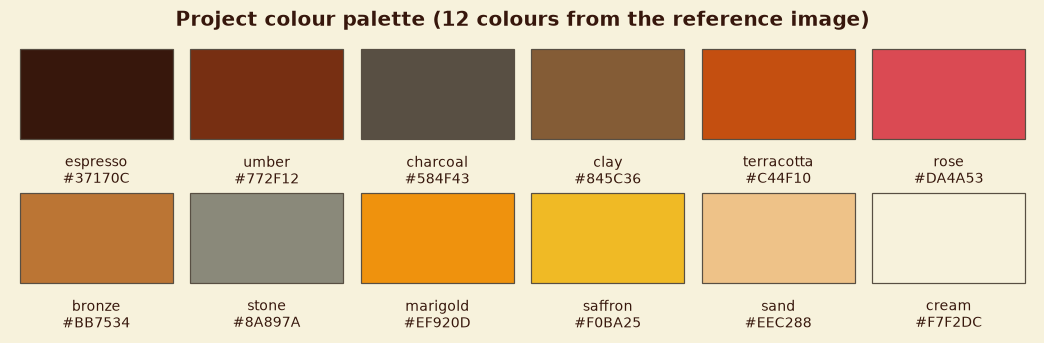

In [11]:
fig = style.palette_preview()
style.save_figure(fig, 2, "Project colour palette")
plt.show()

## 2.6 Raw Data Check

Copy `train.csv`, `test.csv`, `store.csv` and `sample_submission.csv` into `data/raw/`. In Colab, use the Files panel to upload them to that folder. The cell below confirms that all four files exist and that their row counts match the audit done earlier.

In [12]:
missing = [f"{name} ({path.name})" for name, path in config.RAW_FILES.items() if not path.exists()]
if missing:
    raise FileNotFoundError(f"Copy these files into {config.DATA_RAW} and re-run this cell: {missing}")

EXPECTED_ROWS = {"train.csv": 1_017_209, "test.csv": 41_088, "store.csv": 1_115, "sample_submission.csv": 41_088}

rows = []
for name, path in config.RAW_FILES.items():
    with open(path, "rb") as f:
        n_rows = sum(1 for _ in f) - 1                      # minus the header line
    rows.append({
        "file": path.name,
        "size_mb": round(path.stat().st_size / 1e6, 2),
        "rows": n_rows,
        "expected_rows": EXPECTED_ROWS[path.name],
        "matches": n_rows == EXPECTED_ROWS[path.name],
    })

raw_inventory = pd.DataFrame(rows)
style.show_table(raw_inventory, 2, "Raw data files")
logger.info(f"Raw data check: {int(raw_inventory['matches'].sum())} of {len(raw_inventory)} files match expected row counts.")

**Table 2.2: Raw data files**

,file,size_mb,rows,expected_rows,matches
0,train.csv,38.06,1017209,1017209,True
1,test.csv,1.43,41088,41088,True
2,store.csv,0.05,1115,1115,True
3,sample_submission.csv,0.32,41088,41088,True


2026-10-28 21:44:15 | INFO     | rossmann | Raw data check: 4 of 4 files match expected row counts.


## 2.7 Git and DVC: First Data Version

Git tracks the code. DVC tracks the data: it stores the data in a separate store and keeps only a small `data.dvc` pointer file in Git. The whole `data/` folder is tracked as one unit, so every time we save a new data version (raw, cleaned, features) the pointer changes and the Git history shows the sequence of versions. This gives the "multiple data versions in DVC" evidence the brief asks for.

Planned versions:

| Tag | When it is saved |
|---|---|
| `data-v1-raw` | Now (Section 2) |
| `data-v2-cleaned` | After cleaning (Section 3) |
| `data-v3-features` | After feature engineering (Section 6) |

The DVC store here is a local folder next to the project. A shared remote (for example Google Drive or DagsHub) can be added later, and the local store path is kept out of the repository. Edit the two Git identity lines below the first time.

In [13]:
import subprocess

GIT_NAME = "Your Name"                 # <-- edit
GIT_EMAIL = "you@example.com"          # <-- edit
DVC_STORE = ROOT.parent / "dvc_store"  # local DVC store (outside the repository)


def sh(cmd, check=True):
    """Run a shell command from the project root, print its output and optionally fail loudly."""
    result = subprocess.run(cmd, shell=True, cwd=ROOT, capture_output=True, text=True)
    output = (result.stdout + result.stderr).strip()
    if output:
        print(output)
    if check and result.returncode != 0:
        raise RuntimeError(f"Command failed: {cmd}")
    return result


def save_data_version(tag, message):
    """Record the current state of data/ as a new DVC version, commit the pointer and tag it."""
    sh("dvc add data")
    sh("git add data.dvc .gitignore")
    sh(f'git commit -m "{message}"', check=False)      # does nothing if nothing changed
    sh(f"git tag -f {tag}")
    sh("dvc push")
    logger.info(f"Data version saved: {tag}")


# --- Git
if not (ROOT / ".git").exists():
    sh("git init -b main")
if not sh("git config user.name", check=False).stdout.strip():
    sh(f'git config user.name "{GIT_NAME}"')
    sh(f'git config user.email "{GIT_EMAIL}"')

# --- DVC
if not (ROOT / ".dvc").exists():
    sh("dvc init -q")
sh("dvc config core.analytics false")
DVC_STORE.mkdir(parents=True, exist_ok=True)
sh(f'dvc remote add -d --local -f localstore "{DVC_STORE.as_posix()}"')   # kept out of Git (config.local)
sh("git add .dvc .gitignore")

# --- first data version
save_data_version("data-v1-raw", "Data v1: raw files tracked with DVC")

print("\n--- Git history")
sh("git log --oneline")
print("\n--- DVC status (data vs store)")
sh("dvc status -c", check=False)

Srishti Sharma
Setting 'localstore' as a default remote.
To track the changes with git, run:

	git add data.dvc

To enable auto staging, run:

	dvc config core.autostage true
⠋ Checking graph

On branch main
Changes not staged for commit:
  (use "git add <file>..." to update what will be committed)
  (use "git restore <file>..." to discard changes in working directory)
	modified:   outputs/decision_register.csv
	modified:   outputs/limitations.csv

Untracked files:
  (use "git add <file>..." to include in what will be committed)
	outputs/section7/
	outputs/section8/
	src/section7_reference.py

no changes added to commit (use "git add" and/or "git commit -a")
Updated tag 'data-v1-raw' (was 7208128)
Everything is up to date.
2026-10-28 21:44:17 | INFO     | rossmann | Data version saved: data-v1-raw

--- Git history
26df2f3 Section 6: feature engineering, leakage tests and preprocessing pipeline
088cc29 Data v3: feature tables (Section 6)
5d203ed Section 5: exploration of customer purcha

CompletedProcess(args='dvc status -c', returncode=0, stdout="Cache and remote 'localstore' are in sync.\n", stderr='')

## 2.8 MLflow Trial Experiment

MLflow records every model run (settings, scores, files and the model itself) so runs can be compared and the best one served. Here we log one small trial run in a separate experiment (`setup-check`) to confirm that tracking works, so the real experiment (`rossmann-sales-forecasting`) starts clean in Section 7.

Runs are stored in a local SQLite database (`mlflow.db`) plus a `mlruns/` folder. To see the dashboard, open a terminal in the project folder and run `mlflow ui --backend-store-uri sqlite:///mlflow.db`. If you run in Colab, download `mlflow.db` and `mlruns/` (or keep the project on Drive) before the runtime resets, otherwise the runs are lost.

In [14]:
import numpy as np
import mlflow
import mlflow.sklearn
from sklearn.dummy import DummyRegressor

mlflow.set_tracking_uri(config.MLFLOW_TRACKING_URI)
mlflow.set_experiment(config.MLFLOW_SETUP_EXPERIMENT)

with mlflow.start_run(run_name="setup-check") as run:
    mlflow.log_params({"seed": SEED, "horizon_days": config.HORIZON_DAYS, "purpose": "environment check"})
    mlflow.log_metric("dummy_metric", 0.0)
    mlflow.log_artifact(str(config.OUTPUTS_DIR / "package_versions.csv"))

    trial_model = DummyRegressor(strategy="mean").fit(np.zeros((5, 1)), np.arange(5))
    try:                                   # newer MLflow uses name=, older versions use artifact_path=
        mlflow.sklearn.log_model(trial_model, name="trial_model", serialization_format="cloudpickle")
    except TypeError:
        mlflow.sklearn.log_model(trial_model, artifact_path="trial_model", serialization_format="cloudpickle")
    run_id = run.info.run_id

recorded = mlflow.tracking.MlflowClient().get_run(run_id)
logger.info(f"MLflow trial run {run_id[:8]} finished with status {recorded.info.status}")
print("Params recorded:", dict(recorded.data.params))

2026/10/28 21:44:20 WARNING mlflow.sklearn: Saving scikit-learn models in the pickle or cloudpickle format requires exercising caution because these formats rely on Python's object serialization mechanism, which can execute arbitrary code during deserialization. The recommended safe alternative is the 'skops' format. For more information, see: https://scikit-learn.org/stable/model_persistence.html


2026-10-28 21:44:23 | INFO     | rossmann | MLflow trial run 9967a39b finished with status FINISHED
Params recorded: {'seed': '42', 'horizon_days': '42', 'purpose': 'environment check'}


## 2.9 Minimal Streamlit App and Deployment Check

A basic page is built now, using the project palette and importing the project's own `src/` code. Its only job is to confirm that the hosting environment can run a Streamlit app, load our modules and draw a chart. The chart uses made-up demo numbers and says so. The full forecasting app is built in Section 11.

**Hosting check (do this once, outside the notebook):**
1. Push the project to a GitHub repository.
2. On Streamlit Community Cloud, create a new app from that repository, branch `main`, main file `app.py`.
3. In the advanced settings, choose the same Python version you use for the notebook (this matters later because saved models depend on library versions).
4. Confirm that the page loads and shows the demo chart, then note the URL in the Decision Register. The final app can reuse this same URL.

In [15]:
%%writefile app.py
"""Minimal Streamlit page that checks the deployment environment (replaced by the full app in Section 11)."""
import matplotlib.pyplot as plt
import numpy as np
import streamlit as st

from src.style import FORECAST_COLORS, apply_style

st.set_page_config(page_title="Rossmann Sales Forecast", page_icon="📈", layout="wide")
apply_style()

st.title("Rossmann Store Sales Forecast")
st.caption("Setup check only. The full forecasting app is built in Section 11.")

st.write("If you can read this page and see the chart below, the hosting environment can run the app, "
         "import the project code and draw figures in the project palette.")

# Demo data only (not real sales): a weekly pattern with noise, drawn in the project colours.
rng = np.random.default_rng(42)
days = np.arange(42)
demo = 6000 + 900 * np.sin(2 * np.pi * days / 7) + rng.normal(0, 150, size=days.size)

fig, ax = plt.subplots(figsize=(9, 4))
ax.fill_between(days, demo * 0.92, demo * 1.08, color=FORECAST_COLORS["interval"], label="Interval (demo)")
ax.plot(days, demo, color=FORECAST_COLORS["forecast"], linewidth=2.2, label="Forecast (demo)")
ax.set_xlabel("Days ahead")
ax.set_ylabel("Sales")
ax.set_title("Demo chart in the project palette")
ax.legend()
st.pyplot(fig)

st.success("Environment check passed.")

Overwriting app.py


In [16]:
%%writefile .streamlit/config.toml
[theme]
primaryColor = "#C44F10"
backgroundColor = "#F7F2DC"
secondaryBackgroundColor = "#EEC288"
textColor = "#37170C"
font = "sans serif"

Overwriting .streamlit/config.toml


In [17]:
from streamlit.testing.v1 import AppTest

app_path = ROOT / "app.py"
print("app.py exists:", app_path.exists())

at = AppTest.from_file(str(app_path), default_timeout=60).run()
print("Page title        :", at.title[0].value)
print("Errors on the page:", list(at.exception))
print("Status message    :", at.success[0].value)
logger.info(f"Streamlit smoke test finished with {len(at.exception)} error(s).")

2026-10-28 21:44:23.367 WARNING streamlit.runtime.scriptrunner_utils.script_run_context: Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare mode.


app.py exists: True
Page title        : Rossmann Store Sales Forecast
Errors on the page: []
Status message    : Environment check passed.
2026-10-28 21:44:24 | INFO     | rossmann | Streamlit smoke test finished with 0 error(s).


## 2.10 Section Checks, Decisions and First Commit

The completion condition for this section is that data loading, logging, experiment tracking and a basic app all work. The cell below tests each one, adds this section's choices to the Decision Register and makes the first commit of the code.

In [18]:
# ---- completion checks
checks = pd.DataFrame(
    [
        ("Raw data files found with expected row counts", bool(raw_inventory["matches"].all())),
        ("Logger wrote logs/project.log", (config.LOGS_DIR / "project.log").exists()),
        ("DVC data version recorded (data.dvc exists)", (ROOT / "data.dvc").exists()),
        ("MLflow trial run recorded", recorded.info.status == "FINISHED"),
        ("Streamlit page runs without errors", len(at.exception) == 0),
    ],
    columns=["check", "passed"],
)
style.show_table(checks.set_index("check"), 2, "Section 2 completion checks", save=False)

# ---- decisions made in this section
log_decision(2, "Settings (paths, seed 42, horizon, tracking names) live in src/config.py; one logger and one style module are shared by notebook and app.",
             "A single source of truth keeps results, figures and the app consistent.")
log_decision(2, "MLflow uses a local SQLite store (mlflow.db); models are logged as pickles (cloudpickle); trial run kept in a separate 'setup-check' experiment.",
             "Supports the model registry and multiple model versions; pickles match the brief's .pkl requirement.")
log_decision(2, "DVC tracks the whole data/ folder as one unit with tagged versions (data-v1-raw, v2-cleaned, v3-features); the local store path is kept out of Git.",
             "The history of one pointer file shows multiple data versions for the DVC screenshot.")
log_decision(2, "Two requirements files: requirements.txt (app only) and requirements-dev.txt (notebook and tracking).",
             "Keeps hosting installs small and fast while the notebook stays fully reproducible.")
log_decision(2, "Figures are saved as 'Figure <section>.<n>' in figures/ and tables as 'Table <section>.<n>' in outputs/tables/, all in the shared palette.",
             "Notebook, report and slides can cite the same numbered items.")
log_decision(2, "Models will be saved as dd-mm-yyyy-HH-MM-SS.pkl using config.MODEL_TIMESTAMP_FORMAT.",
             "Matches the brief and lets predictions be traced to a model.")
log_decision(2, "A minimal Streamlit page is deployed early as an environment check.",
             "Finds hosting and dependency problems before the final week.",
             status="Provisional (confirm once the hosted check passes)")

save_registers()
style.save_index()
display(decision_register.tail(7))

# ---- first commit of the code
sh("git add -A")
sh('git commit -m "Section 2: project structure, config, logging, style, tracking and minimal app"', check=False)
sh("git log --oneline")

**Table 2.3: Section 2 completion checks**

,passed
check,
Raw data files found with expected row counts,True
Logger wrote logs/project.log,True
DVC data version recorded (data.dvc exists),True
MLflow trial run recorded,True
Streamlit page runs without errors,True


,id,section,decision,reason,status
11,D12,2,"Settings (paths, seed 42, horizon, tracking names) live in src/config.py; one logger and one style module are shared by notebook and app.","A single source of truth keeps results, figures and the app consistent.",Confirmed
12,D13,2,MLflow uses a local SQLite store (mlflow.db); models are logged as pickles (cloudpickle); trial run kept in a separate 'setup-check' experiment.,Supports the model registry and multiple model versions; pickles match the brief's .pkl requirement.,Confirmed
13,D14,2,"DVC tracks the whole data/ folder as one unit with tagged versions (data-v1-raw, v2-cleaned, v3-features); the local store path is kept out of Git.",The history of one pointer file shows multiple data versions for the DVC screenshot.,Confirmed
14,D15,2,Two requirements files: requirements.txt (app only) and requirements-dev.txt (notebook and tracking).,Keeps hosting installs small and fast while the notebook stays fully reproducible.,Confirmed
15,D16,2,"Figures are saved as 'Figure <section>.<n>' in figures/ and tables as 'Table <section>.<n>' in outputs/tables/, all in the shared palette.","Notebook, report and slides can cite the same numbered items.",Confirmed
16,D17,2,Models will be saved as dd-mm-yyyy-HH-MM-SS.pkl using config.MODEL_TIMESTAMP_FORMAT.,Matches the brief and lets predictions be traced to a model.,Confirmed
17,D18,2,A minimal Streamlit page is deployed early as an environment check.,Finds hosting and dependency problems before the final week.,Provisional (confirm once the hosted check passes)


[main 206d568] Section 2: project structure, config, logging, style, tracking and minimal app
 33 files changed, 1783 insertions(+), 153 deletions(-)
 create mode 100644 outputs/section7/20261028T133416284953Z/baseline_comparison.csv
 create mode 100644 outputs/section7/20261028T133416284953Z/baseline_fold_metrics.csv
 create mode 100644 outputs/section7/20261028T133416284953Z/completion_checks.json
 create mode 100644 outputs/section7/20261028T133416284953Z/decisions_section7.csv
 create mode 100644 outputs/section7/20261028T133416284953Z/development_finalist.joblib
 create mode 100644 outputs/section7/20261028T133416284953Z/development_history.csv.gz
 create mode 100644 outputs/section7/20261028T133416284953Z/experiment_manifest.json
 create mode 100644 outputs/section7/20261028T133416284953Z/fig_7_1_model_comparison.png
 create mode 100644 outputs/section7/20261028T133416284953Z/limitations_section7.csv
 create mode 100644 outputs/section7/20261028T133416284953Z/ml_finalist.json
 cr

CompletedProcess(args='git log --oneline', returncode=0, stdout='206d568 Section 2: project structure, config, logging, style, tracking and minimal app\n26df2f3 Section 6: feature engineering, leakage tests and preprocessing pipeline\n088cc29 Data v3: feature tables (Section 6)\n5d203ed Section 5: exploration of customer purchasing behaviour\n3b71c30 Section 4: validation splits, feature policy and leakage checks\n20eca8e Data v2: cleaned and merged data (Section 3)\nd371965 Section 2: project structure, config, logging, style, tracking and minimal app\n7208128 Section 6: feature engineering, leakage tests and preprocessing pipeline\neafbd9a Data v3: feature tables (Section 6)\nf2c7125 Section 5: exploration of customer purchasing behaviour\n04ba255 Section 4: validation splits, feature policy and leakage checks\n62288b9 Data v2: cleaned and merged data (Section 3)\n49e112a Section 2: project structure, config, logging, style, tracking and minimal app\nb5fc047 Section 6: feature engine

## 2.11 Section 2 Summary

**What is now in place**
- A reproducible project structure with central configuration, one logger, a shared colour palette and stable figure and table numbering.
- Pinned package versions in two requirements files (app and full notebook).
- Git for code and DVC for data, with the first data version (`data-v1-raw`) recorded.
- MLflow tracking verified with a trial run in a separate experiment.
- A minimal Streamlit page that runs and imports the project code.
- Seven new entries in the Decision Register.

**What comes next**
- **Section 3** audits, joins and cleans the data and saves it as the second data version (`data-v2-cleaned`).

---

# Section 3: Data Audit, Joining and Cleaning

**Purpose of this section:** Establish what each row means, check the files for problems, and resolve them without damaging real sales patterns. The result is one cleaned dataset that every later section starts from.

**Rules followed in this section**
- **Nothing is deleted.** Suspect rows are flagged and excluded from model training through a column, so the audit trail stays visible.
- **Outliers are flagged, not capped.** High sales may be genuine holiday or promotion peaks the model must learn (Decision D07).
- **"Not applicable" is kept separate from "unknown".** Missing Promo2 details mean the store does not take part; a missing competitor date means we do not know.
- **No sales information leaks into the cleaning rules.** The only imputed value (competitor distance for 3 stores) is a store attribute.

| Step | What it covers |
|---|---|
| 3.1 | Load the raw files and look at their shape, types and missing values |
| 3.2 | Integrity checks: keys, duplicates, calendar, valid values, links between files |
| 3.3 | Date coverage for every store |
| 3.4 | store.csv audit and cleaning rules |
| 3.5 | Join check (store details to train and test) |
| 3.6 | Open and closed days, zero sales, and missing `Open` values in test |
| 3.7 | Outliers: why a simple rule fails and what is flagged instead |
| 3.8 | The cleaning pipeline, saved cleaned tables |
| 3.9 | Data-quality table |
| 3.10 | Completion checks, decisions and DVC version 2 |

The cleaning logic lives in `src/data.py`, so the notebook and the app use the same code.

In [19]:
%%writefile src/data.py
"""Loading, checking and cleaning functions shared by the notebook and the app."""
import numpy as np
import pandas as pd

from .config import DATA_INTERIM, RAW_FILES
from .logger import get_logger

logger = get_logger("rossmann.data")

VALID_STATE_HOLIDAYS = {"0", "a", "b", "c"}
MIN_PLAUSIBLE_COMPETITION_YEAR = 1990   # earlier competitor opening years are treated as unreliable
OUTLIER_Z_THRESHOLD = 5.0               # robust z-score cut-off for FLAGGING (never for deleting) unusual sales
LONG_GAP_DAYS = 30                      # a store missing at least this many days has a "history gap"


# ----------------------------------------------------------------------------- loading
def load_raw():
    """Read the four raw files. StateHoliday is read as text because it mixes '0' with letters."""
    train = pd.read_csv(RAW_FILES["train"], dtype={"StateHoliday": str}, parse_dates=["Date"])
    test = pd.read_csv(RAW_FILES["test"], dtype={"StateHoliday": str}, parse_dates=["Date"])
    store = pd.read_csv(RAW_FILES["store"])
    sample = pd.read_csv(RAW_FILES["sample_submission"])
    logger.info(f"Loaded raw data: train {train.shape}, test {test.shape}, store {store.shape}, sample {sample.shape}")
    return train, test, store, sample


def coverage_by_store(df):
    """Rows, first and last date and number of missing calendar days for each store."""
    n_days = (df["Date"].max() - df["Date"].min()).days + 1
    cov = df.groupby("Store")["Date"].agg(rows="size", first_date="min", last_date="max").reset_index()
    cov["expected_days"] = n_days
    cov["missing_days"] = n_days - cov["rows"]
    return cov


# ----------------------------------------------------------------------------- store.csv
def clean_store(store):
    """Clean store.csv, keeping 'not applicable' (Promo2) separate from 'unknown' (competition)."""
    s = store.copy()

    # Competition distance: unknown for a few stores -> median plus a flag (distance is a store attribute, not the target)
    s["CompetitionDistance_missing"] = s["CompetitionDistance"].isna().astype("int8")
    s["CompetitionDistance"] = s["CompetitionDistance"].fillna(s["CompetitionDistance"].median())

    # Competitor opening date: build one date column. Unknown or implausible years are left unknown (not invented).
    year, month = s["CompetitionOpenSinceYear"], s["CompetitionOpenSinceMonth"]
    s["CompetitionOpenYear_suspect"] = (year < MIN_PLAUSIBLE_COMPETITION_YEAR).astype("int8")
    valid = year.notna() & month.notna() & (year >= MIN_PLAUSIBLE_COMPETITION_YEAR)
    text_date = (year.where(valid).astype("Int64").astype("string") + "-"
                 + month.where(valid).astype("Int64").astype("string") + "-01")
    s["CompetitionOpenSince"] = pd.to_datetime(text_date, errors="coerce")
    s["CompetitionOpenDate_known"] = s["CompetitionOpenSince"].notna().astype("int8")
    s = s.drop(columns=["CompetitionOpenSinceYear", "CompetitionOpenSinceMonth"])

    # Promo2: missing details mean "not participating" (not applicable), so code them explicitly
    not_participating = s["Promo2"] == 0
    participating_missing = bool(s.loc[~not_participating, ["Promo2SinceWeek", "Promo2SinceYear", "PromoInterval"]].isna().any(axis=None))
    assert not participating_missing, "Participating Promo2 stores have missing details; review before coding as not applicable"
    for col in ["Promo2SinceWeek", "Promo2SinceYear"]:
        s[col] = s[col].where(~not_participating, 0).astype("int16")
    s["PromoInterval"] = s["PromoInterval"].where(~not_participating, "None")
    s["Promo2"] = s["Promo2"].astype("int8")

    logger.info("Cleaned store.csv: competition distance imputed with median and flagged; competitor dates rebuilt; Promo2 N/A coded.")
    return s


def add_history_gap(store, train):
    """Add the number of missing calendar days per store and a flag for stores with a long gap."""
    gaps = coverage_by_store(train)[["Store", "missing_days"]].rename(columns={"missing_days": "missing_history_days"})
    s = store.merge(gaps, on="Store", how="left", validate="1:1")
    s["missing_history_days"] = s["missing_history_days"].fillna(0).astype("int16")
    s["has_history_gap"] = (s["missing_history_days"] >= LONG_GAP_DAYS).astype("int8")
    return s


# ----------------------------------------------------------------------------- sales data
def flag_sales_outliers(df, threshold=OUTLIER_Z_THRESHOLD):
    """Flag unusually high (+1) or low (-1) sales relative to the same store on the same weekday.

    Uses a robust z-score on log sales (median and MAD) over open, positive-sales days. This only FLAGS rows:
    nothing is removed or capped, because high sales are often genuine promotion or holiday peaks.
    """
    used = (df["Open"] == 1) & (df["Sales"] > 0)
    log_sales = np.log1p(df.loc[used, "Sales"])
    keys = [df.loc[used, "Store"], df.loc[used, "DayOfWeek"]]
    median = log_sales.groupby(keys).transform("median")
    mad = (log_sales - median).abs().groupby(keys).transform("median") * 1.4826
    z = (log_sales - median) / mad.replace(0, np.nan)

    flag = pd.Series(0, index=df.index, dtype="int8")
    flag.loc[used] = np.where(z > threshold, 1, np.where(z < -threshold, -1, 0)).astype("int8")
    z_full = pd.Series(np.nan, index=df.index, dtype="float32")
    z_full.loc[used] = z.astype("float32")
    return flag, z_full


def clean_train(train):
    """Standardise types, check dates, mark suspect rows and flag unusual sales (no rows are deleted)."""
    df = train.copy()
    df["StateHoliday"] = df["StateHoliday"].astype(str)
    assert set(df["StateHoliday"].unique()) <= VALID_STATE_HOLIDAYS, "Unexpected StateHoliday value in train"
    df = df.sort_values(["Store", "Date"]).reset_index(drop=True)

    expected_dow = df["Date"].dt.dayofweek + 1
    n_bad = int((df["DayOfWeek"] != expected_dow).sum())
    if n_bad:
        logger.warning(f"{n_bad} train rows had a DayOfWeek that disagrees with the date; recomputed from the date.")
        df["DayOfWeek"] = expected_dow

    df["suspect_zero_sales"] = ((df["Open"] == 1) & (df["Sales"] == 0)).astype("int8")
    df["use_for_training"] = ((df["Open"] == 1) & (df["Sales"] > 0)).astype("int8")
    df["sales_outlier_flag"], df["sales_robust_z"] = flag_sales_outliers(df)
    logger.info(f"Cleaned train: {int(df['suspect_zero_sales'].sum())} suspect zero-sales rows flagged, "
                f"{int((df['sales_outlier_flag'] != 0).sum())} unusual-sales rows flagged, none removed.")
    return df


def clean_test(test):
    """Fill missing Open values with the rule 'open unless Sunday or a state holiday' and flag them."""
    df = test.copy()
    df["StateHoliday"] = df["StateHoliday"].astype(str)
    assert set(df["StateHoliday"].unique()) <= VALID_STATE_HOLIDAYS, "Unexpected StateHoliday value in test"
    df["Open_imputed"] = df["Open"].isna().astype("int8")
    open_by_rule = ((df["DayOfWeek"] != 7) & (df["StateHoliday"] == "0")).astype("int8")
    df["Open"] = df["Open"].fillna(open_by_rule).astype("int8")
    logger.info(f"Cleaned test: {int(df['Open_imputed'].sum())} missing Open values filled by rule.")
    return df.sort_values("Id").reset_index(drop=True)


def merge_store(df, store, name):
    """Join store details; checks the join is many-to-one, keeps the row count and matches every store."""
    n_before = len(df)
    out = df.merge(store, on="Store", how="left", validate="m:1")
    assert len(out) == n_before, f"{name}: row count changed after the join"
    assert out["StoreType"].notna().all(), f"{name}: some stores have no store details"
    logger.info(f"Joined store details to {name}: {n_before:,} rows kept, all stores matched.")
    return out


def build_clean_data(train, test, store):
    """Full cleaning pipeline: returns (train_clean, test_clean, store_clean)."""
    store_clean = add_history_gap(clean_store(store), train)
    train_clean = merge_store(clean_train(train), store_clean, "train")
    test_clean = merge_store(clean_test(test), store_clean, "test")
    return train_clean, test_clean, store_clean


# ----------------------------------------------------------------------------- saving and reloading
def save_interim(df, name):
    """Save a cleaned table to data/interim/<name>.csv.gz and return the path."""
    DATA_INTERIM.mkdir(parents=True, exist_ok=True)
    path = DATA_INTERIM / f"{name}.csv.gz"
    df.to_csv(path, index=False)
    logger.info(f"Saved {name}: {df.shape[0]:,} rows x {df.shape[1]} columns -> {path.name}")
    return path


def load_interim(name):
    """Reload a cleaned table with the right types (dates and holiday codes)."""
    path = DATA_INTERIM / f"{name}.csv.gz"
    columns = pd.read_csv(path, nrows=0).columns
    dates = [c for c in ("Date", "CompetitionOpenSince") if c in columns]
    dtypes = {"StateHoliday": str} if "StateHoliday" in columns else None
    return pd.read_csv(path, parse_dates=dates, dtype=dtypes)

Overwriting src/data.py


## 3.1 Load the Raw Files and First Look

The four raw files are read with `StateHoliday` as text (it mixes the number 0 with the letters a, b and c). The tables below show the size of each file and which columns contain missing values.

In [20]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from src import config, style, data
from src.logger import get_logger
from src.style import PALETTE, FORECAST_COLORS

logger = get_logger("rossmann")

train_raw, test_raw, store_raw, sample_raw = data.load_raw()
raw_tables = {"train": train_raw, "test": test_raw, "store": store_raw, "sample_submission": sample_raw}

overview = pd.DataFrame([
    {
        "file": name,
        "rows": len(df),
        "columns": df.shape[1],
        "memory_mb": round(df.memory_usage(deep=True).sum() / 1e6, 1),
        "first_date": df["Date"].min().date() if "Date" in df.columns else "",
        "last_date": df["Date"].max().date() if "Date" in df.columns else "",
    }
    for name, df in raw_tables.items()
]).set_index("file")
style.show_table(overview, 3, "Overview of the raw files")

schema = pd.concat([
    pd.DataFrame({
        "file": name,
        "column": df.columns,
        "dtype": df.dtypes.astype(str).values,
        "missing": df.isna().sum().values,
        "missing_pct": (df.isna().mean().values * 100).round(2),
        "unique_values": df.nunique().values,
    })
    for name, df in raw_tables.items()
], ignore_index=True)
style.show_table(schema[schema["missing"] > 0].reset_index(drop=True), 3, "Columns with missing values in the raw files")
logger.info(f"Raw files loaded; {int((schema['missing'] > 0).sum())} columns contain missing values.")

2026-10-28 21:44:25 | INFO     | rossmann.data | Loaded raw data: train (1017209, 9), test (41088, 8), store (1115, 10), sample (41088, 2)


**Table 3.1: Overview of the raw files**

,rows,columns,memory_mb,first_date,last_date
file,,,,,
train,1017209,9,74.3,2013-01-01,2015-07-31
test,41088,8,2.7,2015-08-01,2015-09-17
store,1115,10,0.1,,
sample_submission,41088,2,0.7,,


**Table 3.2: Columns with missing values in the raw files**

,file,column,dtype,missing,missing_pct,unique_values
0,test,Open,float64,11,0.03,2
1,store,CompetitionDistance,float64,3,0.27,654
2,store,CompetitionOpenSinceMonth,float64,354,31.75,12
3,store,CompetitionOpenSinceYear,float64,354,31.75,23
4,store,Promo2SinceWeek,float64,544,48.79,24
5,store,Promo2SinceYear,float64,544,48.79,7
6,store,PromoInterval,str,544,48.79,3


2026-10-28 21:44:26 | INFO     | rossmann | Raw files loaded; 7 columns contain missing values.


**Reading the result.** `train.csv` has 1,017,209 store-days (1 Jan 2013 to 31 Jul 2015) and `test.csv` has 41,088 (1 Aug to 17 Sep 2015). The training sales file has no missing values at all. Missing values appear in only two places: 11 `Open` values in the test file, and the store file (competition details and Promo2 details). Sections 3.4 and 3.6 look at each of these.

## 3.2 Integrity Checks

Before looking for patterns, the files must pass basic checks: unique keys, no duplicate rows, weekdays that agree with dates, valid category codes, no negative values, and matching stores and Ids across files.

In [21]:
checks = []


def add_check(check, file, found, expected=0):
    checks.append({"check": check, "file": file, "found": int(found), "expected": expected, "passed": int(found) == expected})


# duplicates and keys
for name in ["train", "test", "store"]:
    add_check("Exact duplicate rows", name, raw_tables[name].duplicated().sum())
add_check("Repeated (Store, Date) pairs", "train", train_raw.duplicated(["Store", "Date"]).sum())
add_check("Repeated (Store, Date) pairs", "test", test_raw.duplicated(["Store", "Date"]).sum())
add_check("Repeated Id values", "test", test_raw["Id"].duplicated().sum())
add_check("Repeated Store values", "store", store_raw["Store"].duplicated().sum())

# calendar consistency (Monday = 1 ... Sunday = 7)
for name in ["train", "test"]:
    df = raw_tables[name]
    add_check("DayOfWeek disagrees with Date", name, (df["Date"].dt.dayofweek + 1 != df["DayOfWeek"]).sum())

# value ranges
add_check("Negative Sales", "train", (train_raw["Sales"] < 0).sum())
add_check("Negative Customers", "train", (train_raw["Customers"] < 0).sum())
for col in ["Open", "Promo", "SchoolHoliday"]:
    for name in ["train", "test"]:
        df = raw_tables[name]
        add_check(f"{col} not in {{0, 1}}", name, (df[col].notna() & ~df[col].isin([0, 1])).sum())
for name in ["train", "test"]:
    add_check("StateHoliday not in {0, a, b, c}", name, (~raw_tables[name]["StateHoliday"].isin(data.VALID_STATE_HOLIDAYS)).sum())
add_check("StoreType not in {a, b, c, d}", "store", (~store_raw["StoreType"].isin(list("abcd"))).sum())
add_check("Assortment not in {a, b, c}", "store", (~store_raw["Assortment"].isin(list("abc"))).sum())
add_check("Promo2 not in {0, 1}", "store", (~store_raw["Promo2"].isin([0, 1])).sum())
valid_intervals = ["Jan,Apr,Jul,Oct", "Feb,May,Aug,Nov", "Mar,Jun,Sept,Dec"]
add_check("PromoInterval not one of the 3 valid patterns", "store",
          (store_raw["PromoInterval"].notna() & ~store_raw["PromoInterval"].isin(valid_intervals)).sum())

# links between files
add_check("Test Ids missing from sample_submission", "test/sample", (~test_raw["Id"].isin(sample_raw["Id"])).sum())
add_check("Sample_submission Ids missing from test", "test/sample", (~sample_raw["Id"].isin(test_raw["Id"])).sum())
add_check("Train stores missing from store.csv", "train/store", (~train_raw["Store"].isin(store_raw["Store"])).sum())
add_check("Test stores missing from train", "test/train", (~test_raw["Store"].isin(train_raw["Store"].unique())).sum())

integrity = pd.DataFrame(checks)
style.show_table(integrity, 3, "Integrity checks on keys, calendar, value ranges and links between files")
logger.info(f"Integrity checks: {int(integrity['passed'].sum())} of {len(integrity)} passed.")

**Table 3.3: Integrity checks on keys, calendar, value ranges and links between files**

,check,file,found,expected,passed
0,Exact duplicate rows,train,0,0,True
1,Exact duplicate rows,test,0,0,True
2,Exact duplicate rows,store,0,0,True
3,"Repeated (Store, Date) pairs",train,0,0,True
4,"Repeated (Store, Date) pairs",test,0,0,True
5,Repeated Id values,test,0,0,True
6,Repeated Store values,store,0,0,True
7,DayOfWeek disagrees with Date,train,0,0,True
8,DayOfWeek disagrees with Date,test,0,0,True
9,Negative Sales,train,0,0,True


2026-10-28 21:44:26 | INFO     | rossmann | Integrity checks: 27 of 27 passed.


**Reading the result.** All 27 checks pass. Each row is one store on one day, weekdays agree with the dates, every code is valid, there are no negative sales or customer counts, and every store and test `Id` is accounted for. No repairs are needed at this level.

## 3.3 Date Coverage

A forecasting dataset should have one row per store per day. This step checks how many days each store is missing, and when.

**Table 3.4: Number of stores by missing calendar days in train**

,stores,rows_per_store
missing_days,,
0,934,942
1,1,941
184,180,758


**Table 3.5: The missing block shared by stores with a long gap**

,gap_start,gap_end,missing_days,stores
0,2014-07-01,2014-12-31,184,180


Stores missing only a few days: {988: [datetime.date(2013, 1, 1)]}
Test: rows per store = [np.int64(48)] | stores in test = 856 | test dates = 48
Figure 3.1: Stores with a sales record on each day


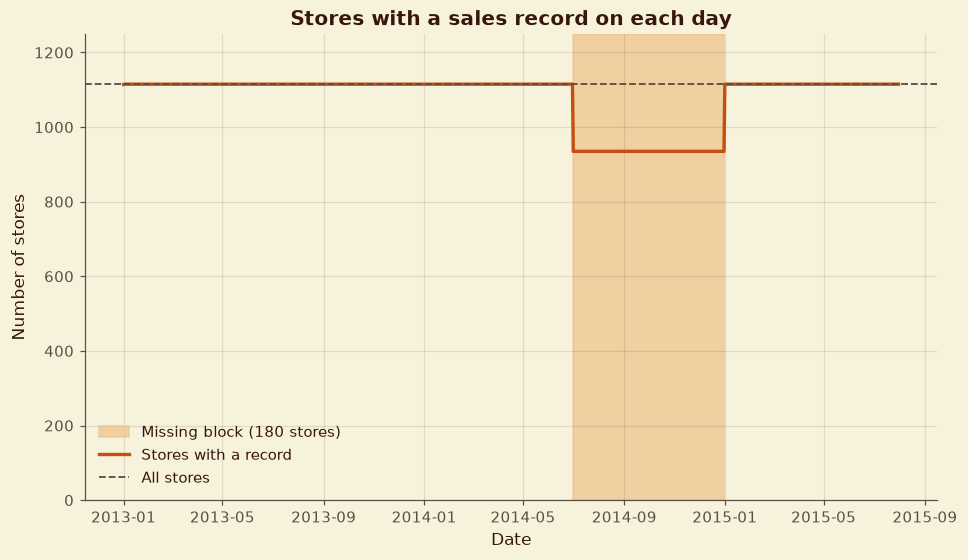

In [22]:
train_cov = data.coverage_by_store(train_raw)
test_cov = data.coverage_by_store(test_raw)

coverage_groups = (train_cov.groupby("missing_days")
                   .agg(stores=("Store", "size"), rows_per_store=("rows", "first"))
                   .reset_index())
style.show_table(coverage_groups.set_index("missing_days"), 3, "Number of stores by missing calendar days in train")

# when are the days missing for the stores with a long gap?
all_dates = pd.date_range(train_raw["Date"].min(), train_raw["Date"].max())
long_gap_stores = train_cov.loc[train_cov["missing_days"] >= data.LONG_GAP_DAYS, "Store"]
dates_by_store = train_raw[train_raw["Store"].isin(long_gap_stores)].groupby("Store")["Date"].apply(set)
gap_spans = pd.DataFrame([
    {"store": s, "gap_start": min(m), "gap_end": max(m), "missing_days": len(m)}
    for s, d in dates_by_store.items()
    for m in [set(all_dates) - d]
])
gap_summary = (gap_spans.groupby(["gap_start", "gap_end", "missing_days"]).size()
               .rename("stores").reset_index())
style.show_table(gap_summary, 3, "The missing block shared by stores with a long gap")

short_gap = train_cov[train_cov["missing_days"].between(1, data.LONG_GAP_DAYS - 1)]
short_gap_dates = [sorted(set(all_dates) - set(train_raw.loc[train_raw["Store"] == s, "Date"]))
                   for s in short_gap["Store"]]
print("Stores missing only a few days:", dict(zip(short_gap["Store"], [[d.date() for d in x] for x in short_gap_dates])))
print("Test: rows per store =", sorted(test_cov["rows"].unique()), "| stores in test =", test_cov["Store"].nunique(),
      "| test dates =", test_raw["Date"].nunique())

# Figure: number of stores reporting each day
stores_per_date = train_raw.groupby("Date")["Store"].nunique()
fig, ax = plt.subplots()
ax.axvspan(gap_spans["gap_start"].min(), gap_spans["gap_end"].max(), color=PALETTE["sand"], alpha=0.7,
           label=f"Missing block ({len(long_gap_stores)} stores)")
ax.plot(stores_per_date.index, stores_per_date.values, color=PALETTE["terracotta"], linewidth=2.2, label="Stores with a record")
ax.axhline(store_raw["Store"].nunique(), color=PALETTE["charcoal"], linestyle="--", linewidth=1.2, label="All stores")
ax.set_ylim(0, store_raw["Store"].nunique() * 1.12)
ax.set_xlabel("Date")
ax.set_ylabel("Number of stores")
ax.set_title("Stores with a sales record on each day")
ax.legend(loc="lower left")
style.save_figure(fig, 3, "Stores with a sales record on each day")
plt.show()

**Reading the result.**
- 934 stores have a complete history of 942 days.
- **180 stores are missing exactly the same block of 184 days, 1 Jul to 31 Dec 2014** (Figure 3.1 shows the dip from 1,115 to 935 stores). Because every affected store misses the same block, it looks like a planned closure or a data extraction problem. The cause is not in the data, so we cannot repair it and will not invent sales for it.
- One store (988) misses a single day, 1 Jan 2013, which is negligible.
- The test file is complete: 856 stores for each of 48 days.

**Decision:** keep the data as it is, and flag the 180 stores (`has_history_gap`, `missing_history_days`) so that later lag, rolling and sequence features never run across the gap.

## 3.4 store.csv: Missing Values and Cleaning Rules

Missing values in `store.csv` come in two kinds, and they must be handled differently:
- **Not applicable:** Promo2 details are blank when a store does not take part in Promo2.
- **Unknown:** competitor details are blank because the information is not available.

In [23]:
store_missing = pd.DataFrame({
    "missing": store_raw.isna().sum(),
    "missing_pct": (store_raw.isna().mean() * 100).round(1),
})
store_missing = store_missing[store_missing["missing"] > 0]
store_missing["meaning"] = [
    "Unknown" if c.startswith("Competition") else "Not applicable when Promo2 = 0" for c in store_missing.index
]
style.show_table(store_missing, 3, "Missing values in store.csv and what they mean")

promo2_check = pd.crosstab(store_raw["Promo2"], store_raw["PromoInterval"].isna(),
                           rownames=["Promo2"], colnames=["PromoInterval missing"])
style.show_table(promo2_check, 3, "Promo2 participation vs missing promotion details")

competition_check = pd.crosstab(store_raw["CompetitionDistance"].isna(), store_raw["CompetitionOpenSinceYear"].isna(),
                                rownames=["Distance missing"], colnames=["Opening date missing"])
style.show_table(competition_check, 3, "Competitor distance vs competitor opening date (missing or known)")

suspect_years = store_raw.loc[store_raw["CompetitionOpenSinceYear"] < data.MIN_PLAUSIBLE_COMPETITION_YEAR,
                              ["Store", "CompetitionDistance", "CompetitionOpenSinceYear"]]
style.show_table(suspect_years.set_index("Store"), 3, "Stores with an implausible competitor opening year (before 1990)")

last_train_month = train_raw["Date"].max().year * 100 + train_raw["Date"].max().month
comp_month = store_raw["CompetitionOpenSinceYear"] * 100 + store_raw["CompetitionOpenSinceMonth"]
late_competitors = store_raw.loc[comp_month > last_train_month,
                                 ["Store", "CompetitionDistance", "CompetitionOpenSinceYear", "CompetitionOpenSinceMonth"]]
style.show_table(late_competitors.set_index("Store"), 3, "Competitors that open after the last training date")

store_preview = data.clean_store(store_raw)
cleaned_store_flags = pd.DataFrame({
    "stores": [
        int(store_preview["CompetitionDistance_missing"].sum()),
        int(store_preview["CompetitionOpenYear_suspect"].sum()),
        int((store_preview["CompetitionOpenDate_known"] == 0).sum()),
        int((store_preview["Promo2"] == 0).sum()),
    ]
}, index=[
    "Competitor distance imputed (median) and flagged",
    "Competitor year before 1990, treated as unknown",
    "Competitor opening date unknown after cleaning",
    "Promo2 not applicable (details coded None / 0)",
])
style.show_table(cleaned_store_flags, 3, "Effect of the store.csv cleaning rules")

**Table 3.6: Missing values in store.csv and what they mean**

,missing,missing_pct,meaning
CompetitionDistance,3,0.3,Unknown
CompetitionOpenSinceMonth,354,31.7,Unknown
CompetitionOpenSinceYear,354,31.7,Unknown
Promo2SinceWeek,544,48.8,Not applicable when Promo2 = 0
Promo2SinceYear,544,48.8,Not applicable when Promo2 = 0
PromoInterval,544,48.8,Not applicable when Promo2 = 0


**Table 3.7: Promo2 participation vs missing promotion details**

PromoInterval missing,False,True
Promo2,,
0,0,544
1,571,0


**Table 3.8: Competitor distance vs competitor opening date (missing or known)**

Opening date missing,False,True
Distance missing,,
False,761,351
True,0,3


... (4 outputs left out)

2026-10-28 21:44:26 | INFO     | rossmann.data | Cleaned store.csv: competition distance imputed with median and flagged; competitor dates rebuilt; Promo2 N/A coded.


**Table 3.11: Effect of the store.csv cleaning rules**

,stores
Competitor distance imputed (median) and flagged,3
"Competitor year before 1990, treated as unknown",2
Competitor opening date unknown after cleaning,356
Promo2 not applicable (details coded None / 0),544


'Table 3.11'

**Reading the result.**
- **Promo2:** all 544 stores with missing Promo2 details are exactly the stores with `Promo2 = 0`. Nothing is unknown, so these are coded as *not applicable* (`PromoInterval = "None"`, since week and year `0`).
- **Competitor distance:** 3 stores (291, 622, 879) have no distance. They also have no opening date. Decision: fill with the median distance and flag them. Distance is a store attribute, so no sales information is used.
- **Competitor opening date:** 354 stores have no date, and 351 of them do have a distance, so a competitor exists but we do not know when it opened. Decision: leave the date unknown and flag it, rather than invent competition ages.
- **Implausible years:** store 815 says 1900 and store 146 says 1961. Both are treated as unknown, which brings the unknown total to 356.
- **Late competitors:** stores 688, 1020 and 1072 have a competitor opening in August 2015, after the last training day and inside the test window. Their effect cannot be learned from history (added to the Limitations List).

## 3.5 Joining store.csv to Train and Test

The join must add exactly one set of store details to every row: no rows gained or lost, and no store left without details.

In [24]:
train_join = train_raw.merge(store_raw, on="Store", how="left", validate="m:1")
test_join = test_raw.merge(store_raw, on="Store", how="left", validate="m:1")
join_summary = pd.DataFrame({
    "rows_before": [len(train_raw), len(test_raw)],
    "rows_after": [len(train_join), len(test_join)],
    "rows_without_store_details": [int(train_join["StoreType"].isna().sum()), int(test_join["StoreType"].isna().sum())],
}, index=["train", "test"])
style.show_table(join_summary, 3, "Join of store.csv to train and test (many-to-one check)")
del train_join, test_join

**Table 3.12: Join of store.csv to train and test (many-to-one check)**

,rows_before,rows_after,rows_without_store_details
train,1017209,1017209,0
test,41088,41088,0


**Reading the result.** The join is many-to-one (pandas would have raised an error otherwise), row counts are unchanged and every store has details.

## 3.6 Open and Closed Days, Zero Sales and Missing `Open` Values

Closed days, zero sales and missing `Open` values must be understood before modelling, because they decide which rows the model learns from and what it predicts for closed days.

In [25]:
status = pd.crosstab(train_raw["Open"].map({0: "Closed", 1: "Open"}),
                     train_raw["Sales"].gt(0).map({False: "Zero sales", True: "Positive sales"}))
style.show_table(status, 3, "Store status vs sales in train (rows)")

open_zero = train_raw[(train_raw["Open"] == 1) & (train_raw["Sales"] == 0)]
zero_summary = pd.Series({
    "Open days with zero sales (rows)": len(open_zero),
    "Stores affected": open_zero["Store"].nunique(),
    "Months affected (of all months in train)": f"{open_zero['Date'].dt.to_period('M').nunique()} of {train_raw['Date'].dt.to_period('M').nunique()}",
    "Rows with zero customers": int((open_zero["Customers"] == 0).sum()),
    "Rows with some customers but zero sales": int((open_zero["Customers"] > 0).sum()),
    "Rows on state holidays": int((open_zero["StateHoliday"] != "0").sum()),
    "Most rows in any single store": int(open_zero["Store"].value_counts().max()),
    "Share on promotion days": round(open_zero["Promo"].mean(), 2),
}).to_frame("value")
style.show_table(zero_summary, 3, "Open days with zero sales")

odd_customers = pd.Series({
    "Rows with positive sales but zero customers": int(((train_raw["Sales"] > 0) & (train_raw["Customers"] == 0)).sum()),
    "Rows with customers but zero sales": int(((train_raw["Sales"] == 0) & (train_raw["Customers"] > 0)).sum()),
    "Closed rows with customers": int(((train_raw["Open"] == 0) & (train_raw["Customers"] > 0)).sum()),
}).to_frame("rows")
style.show_table(odd_customers, 3, "Sales and customers that disagree")

real_closures = train_raw[(train_raw["Open"] == 0) & (train_raw["DayOfWeek"] != 7) & (train_raw["StateHoliday"] == "0")]
closure_by_store = real_closures.groupby("Store").size().sort_values(ascending=False)
print(f"Closed on a normal weekday (not Sunday, not a state holiday): {len(real_closures):,} rows in "
      f"{closure_by_store.size} stores")
style.show_table(closure_by_store.head(6).rename("closed_weekdays").to_frame(), 3, "Stores with the most closed normal weekdays")

holiday_open = (train_raw[train_raw["StateHoliday"] != "0"]
                .groupby("StateHoliday").agg(days=("Open", "size"), open_days=("Open", "sum")))
holiday_open["share_open"] = (holiday_open["open_days"] / holiday_open["days"]).round(3)
style.show_table(holiday_open, 3, "Stores open on state holidays")

# the 11 missing Open values in the test file
missing_open = test_raw[test_raw["Open"].isna()]
store_622 = train_raw[train_raw["Store"] == missing_open["Store"].iloc[0]]
closed_non_sunday = store_622[(store_622["Open"] == 0) & (store_622["DayOfWeek"] != 7)]
open_evidence = pd.Series({
    "Test rows with missing Open": len(missing_open),
    "Store(s) involved": ", ".join(str(s) for s in missing_open["Store"].unique()),
    "...of which on a Sunday": int((missing_open["DayOfWeek"] == 7).sum()),
    "...of which on a state holiday": int((missing_open["StateHoliday"] != "0").sum()),
    "Same store in train: closed days that are not Sundays": len(closed_non_sunday),
    "...of which are state holidays": int((closed_non_sunday["StateHoliday"] != "0").sum()),
}).to_frame("value")
style.show_table(open_evidence, 3, "Evidence for filling the missing Open values")

**Table 3.13: Store status vs sales in train (rows)**

Sales,Positive sales,Zero sales
Open,,
Closed,0,172817
Open,844338,54


**Table 3.14: Open days with zero sales**

,value
Open days with zero sales (rows),54
Stores affected,41
Months affected (of all months in train),20 of 31
Rows with zero customers,52
Rows with some customers but zero sales,2
Rows on state holidays,0
Most rows in any single store,3
Share on promotion days,0.39


**Table 3.15: Sales and customers that disagree**

,rows
Rows with positive sales but zero customers,0
Rows with customers but zero sales,2
Closed rows with customers,0


... (4 outputs left out)

,days,open_days,share_open
StateHoliday,,,
a,20260,694,0.034
b,6690,145,0.022
c,4100,71,0.017


**Table 3.18: Evidence for filling the missing Open values**

,value
Test rows with missing Open,11
Store(s) involved,622
...of which on a Sunday,0
...of which on a state holiday,0
Same store in train: closed days that are not Sundays,24
...of which are state holidays,24


'Table 3.18'

**Reading the result.**
- **Closed days are clean:** all 172,817 closed rows have zero sales and zero customers. The model must predict 0 whenever `Open = 0`.
- **54 open days with zero sales** across 41 stores (20 of the 31 months, never more than 3 in one store, none on a state holiday). 52 of them also have zero customers. A store that is open all day with no customers and no sales looks like a recording error rather than a real day. Decision: flag them (`suspect_zero_sales`) and exclude them from training, but keep the rows.
- **Closed on normal weekdays:** 1,847 rows in 189 stores. Most are short, but stores 103 and 1081 (153 days each), 708 (92), 349 (84) and 972 (78) have long closures. These look like real closures (for example refurbishment), so `Open` carries the information and the rows stay.
- **State holidays:** stores are almost always closed (open on only 3.4%, 2.2% and 1.7% of holiday types a, b and c).
- **Missing `Open` in test:** all 11 belong to store 622 and fall on ordinary weekdays (no Sundays, no holidays). In train, this store's only closures other than Sundays are state holidays (24 of 24). Decision: treat these 11 days as open, and flag them (`Open_imputed`).

## 3.7 Outliers

The brief asks for outlier handling, but high sales can be exactly the events the model needs to learn (promotions, Easter, Christmas). So the question is: what would a simple rule remove, and is there a better way to find genuinely unusual days?

Figure 3.2: Distribution of daily sales on open days


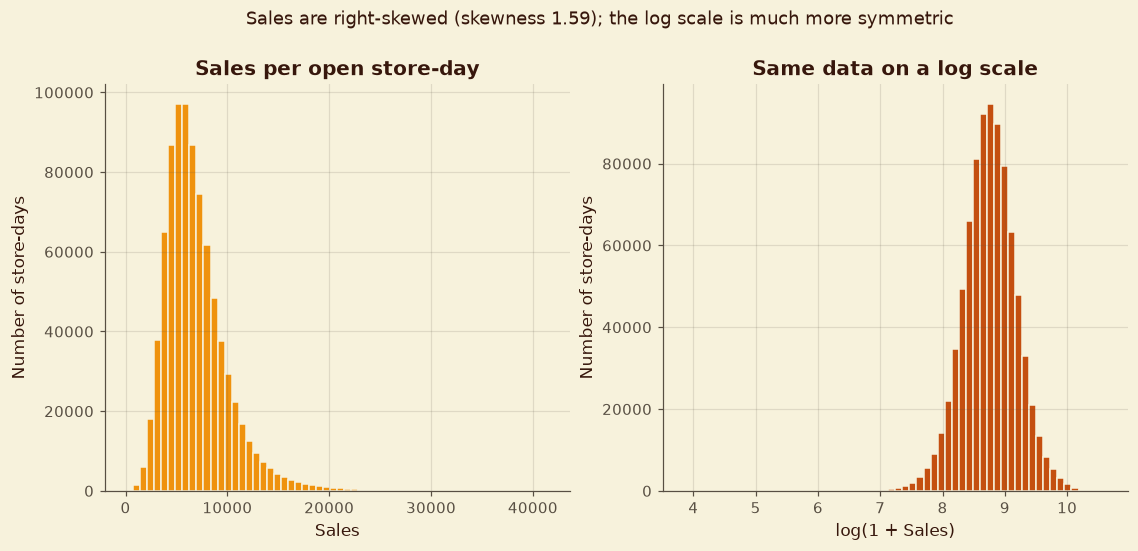

**Table 3.19: What a global IQR rule would remove**

,value
Upper fence (Q3 + 1.5 x IQR),13612
Rows it would remove,30769
Share of all open days (%),3.6
Stores affected,638


Figure 3.3: Why outliers are flagged instead of removed


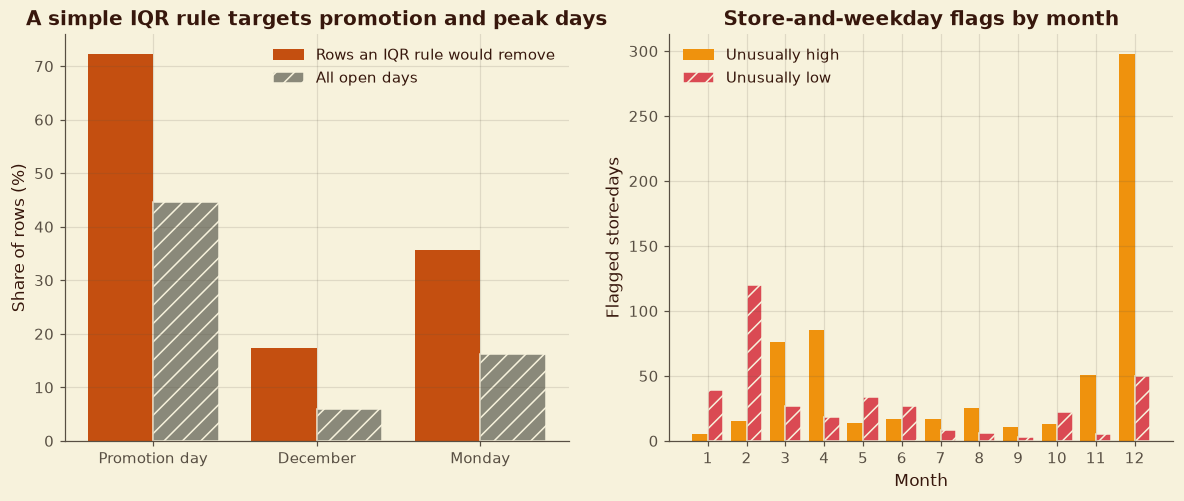

**Table 3.20: Unusual sales relative to the same store and weekday**

,value
Rows flagged (|robust z| > 5),986
...unusually high,627
...unusually low,359
Share of open days (%),0.12
Stores with at least one flag,410
"High flags in Mar, Apr, Nov or Dec (%)",81


**Table 3.21: The most extreme flagged store-days**

,Date,Sales,Customers,Promo,StateHoliday,direction,robust_z
Store,,,,,,,
652,2014-11-22,46,8,0,0,Low,-43.0
137,2013-01-19,297,36,0,0,Low,-30.0
644,2015-02-21,914,142,0,0,Low,-25.6
348,2013-06-27,520,85,0,0,Low,-20.4
898,2015-01-31,124,13,0,0,Low,-19.3
1093,2013-06-03,133,18,1,0,Low,-17.4
863,2014-10-03,1738,255,1,a,Low,-15.5
151,2014-03-21,775,68,1,0,Low,-15.3


Figure 3.4: One store's sales history with flagged days


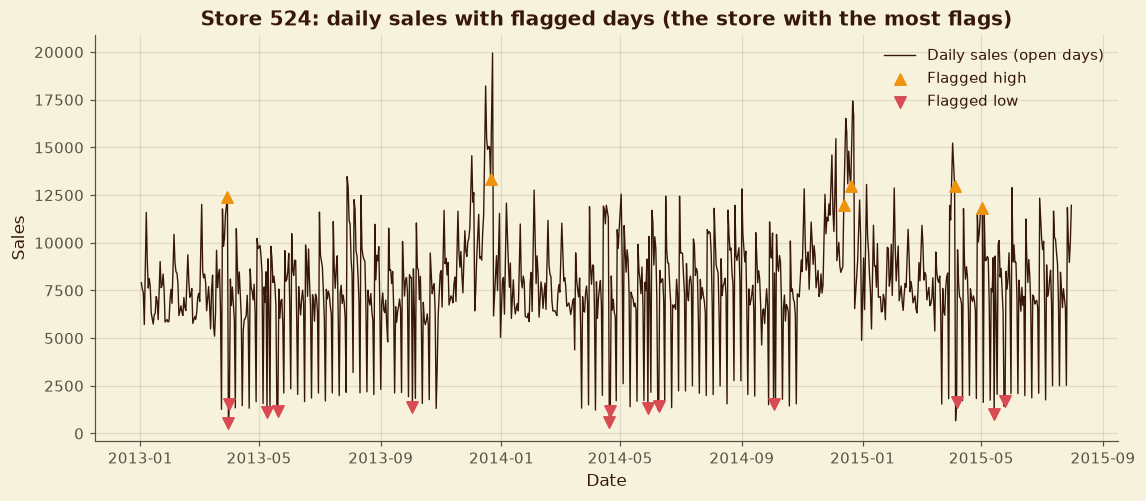

2026-10-28 21:44:27 | INFO     | rossmann | Outlier review: 986 store-days flagged, none removed; a global IQR rule would have removed 30,769.


In [26]:
used = train_raw[(train_raw["Open"] == 1) & (train_raw["Sales"] > 0)]

fig, axes = plt.subplots(1, 2, figsize=(12, 4.8))
axes[0].hist(used["Sales"], bins=60, color=PALETTE["marigold"], edgecolor=PALETTE["cream"])
axes[0].set_title("Sales per open store-day")
axes[0].set_xlabel("Sales")
axes[0].set_ylabel("Number of store-days")
axes[1].hist(np.log1p(used["Sales"]), bins=60, color=PALETTE["terracotta"], edgecolor=PALETTE["cream"])
axes[1].set_title("Same data on a log scale")
axes[1].set_xlabel("log(1 + Sales)")
axes[1].set_ylabel("Number of store-days")
fig.suptitle(f"Sales are right-skewed (skewness {used['Sales'].skew():.2f}); the log scale is much more symmetric", y=1.02)
style.save_figure(fig, 3, "Distribution of daily sales on open days")
plt.show()

# what would a simple IQR rule remove?
q1, q3 = used["Sales"].quantile([0.25, 0.75])
fence = q3 + 1.5 * (q3 - q1)
iqr_hits = used[used["Sales"] > fence]
iqr_summary = pd.Series({
    "Upper fence (Q3 + 1.5 x IQR)": round(fence),
    "Rows it would remove": len(iqr_hits),
    "Share of all open days (%)": round(100 * len(iqr_hits) / len(used), 1),
    "Stores affected": iqr_hits["Store"].nunique(),
}, dtype=object).to_frame("value")
style.show_table(iqr_summary, 3, "What a global IQR rule would remove")

# which kind of days would it remove, compared with all open days?
share_compare = pd.DataFrame({
    "Rows the IQR rule would remove": [iqr_hits["Promo"].mean(), (iqr_hits["Date"].dt.month == 12).mean(), (iqr_hits["DayOfWeek"] == 1).mean()],
    "All open days": [used["Promo"].mean(), (used["Date"].dt.month == 12).mean(), (used["DayOfWeek"] == 1).mean()],
}, index=["Promotion day", "December", "Monday"]) * 100

# store-by-weekday robust z-score (flag only)
flag, z = data.flag_sales_outliers(train_raw)
flagged = train_raw.loc[flag != 0].copy()
flagged["direction"] = np.where(flag.loc[flagged.index] > 0, "High", "Low")
flagged["robust_z"] = z.loc[flagged.index].astype(float).round(1)
flagged["month"] = flagged["Date"].dt.month
monthly = flagged.groupby(["month", "direction"]).size().unstack(fill_value=0).reindex(range(1, 13), fill_value=0)

fig, axes = plt.subplots(1, 2, figsize=(13, 4.8))
x = np.arange(len(share_compare))
axes[0].bar(x - 0.2, share_compare["Rows the IQR rule would remove"], width=0.4, color=PALETTE["terracotta"],
            label="Rows an IQR rule would remove")
axes[0].bar(x + 0.2, share_compare["All open days"], width=0.4, color=PALETTE["stone"], hatch="//",
            edgecolor=PALETTE["cream"], label="All open days")
axes[0].set_xticks(x)
axes[0].set_xticklabels(share_compare.index)
axes[0].set_ylabel("Share of rows (%)")
axes[0].set_title("A simple IQR rule targets promotion and peak days")
axes[0].legend()

months = np.arange(1, 13)
axes[1].bar(months - 0.2, monthly.get("High", pd.Series(0, index=months)).values, width=0.4, color=PALETTE["marigold"], label="Unusually high")
axes[1].bar(months + 0.2, monthly.get("Low", pd.Series(0, index=months)).values, width=0.4, color=PALETTE["rose"], hatch="//",
            edgecolor=PALETTE["cream"], label="Unusually low")
axes[1].set_xticks(months)
axes[1].set_xlabel("Month")
axes[1].set_ylabel("Flagged store-days")
axes[1].set_title("Store-and-weekday flags by month")
axes[1].legend()
style.save_figure(fig, 3, "Why outliers are flagged instead of removed")
plt.show()

flag_summary = pd.Series({
    "Rows flagged (|robust z| > 5)": len(flagged),
    "...unusually high": int((flagged["direction"] == "High").sum()),
    "...unusually low": int((flagged["direction"] == "Low").sum()),
    "Share of open days (%)": round(100 * len(flagged) / len(used), 2),
    "Stores with at least one flag": flagged["Store"].nunique(),
    "High flags in Mar, Apr, Nov or Dec (%)": round(100 * flagged.loc[flagged["direction"] == "High", "month"].isin([3, 4, 11, 12]).mean()),
}, dtype=object).to_frame("value")
style.show_table(flag_summary, 3, "Unusual sales relative to the same store and weekday")

extreme = (flagged.assign(abs_z=flagged["robust_z"].abs()).sort_values("abs_z", ascending=False).head(8)
           [["Store", "Date", "Sales", "Customers", "Promo", "StateHoliday", "direction", "robust_z"]])
style.show_table(extreme.set_index("Store"), 3, "The most extreme flagged store-days")

# one store's history with its flags
example_store = flagged["Store"].value_counts().idxmax()
history = used[used["Store"] == example_store]
marks = flagged[flagged["Store"] == example_store]
fig, ax = plt.subplots(figsize=(12, 4.8))
ax.plot(history["Date"], history["Sales"], color=FORECAST_COLORS["actual"], linewidth=0.9, label="Daily sales (open days)")
high, low = marks[marks["direction"] == "High"], marks[marks["direction"] == "Low"]
ax.scatter(high["Date"], high["Sales"], color=PALETTE["marigold"], marker="^", s=55, zorder=3, label="Flagged high")
ax.scatter(low["Date"], low["Sales"], color=PALETTE["rose"], marker="v", s=55, zorder=3, label="Flagged low")
ax.set_xlabel("Date")
ax.set_ylabel("Sales")
ax.set_title(f"Store {example_store}: daily sales with flagged days (the store with the most flags)")
ax.legend()
style.save_figure(fig, 3, "One store's sales history with flagged days")
plt.show()
logger.info(f"Outlier review: {len(flagged)} store-days flagged, none removed; a global IQR rule would have removed {len(iqr_hits):,}.")

**Reading the result.**
- Sales are strongly right-skewed (skewness 1.59), so modelling `log(1 + Sales)` is justified (Decision D05).
- **A global IQR rule would remove 30,769 rows (3.6% of open days) in 638 stores.** Figure 3.3 (left) shows what it targets: about 72% of those rows are promotion days (against about 45% of all open days), 17% fall in December (against 6%) and 36% on Mondays (against 16%). It would delete the peaks and large stores the model most needs. It is not used.
- **A store-by-weekday robust z-score** compares each day with the same store on the same weekday, so normal differences between big and small stores, and between Sundays and Mondays, do not trigger it. It flags **986 rows (0.12%) in 410 stores: 627 unusually high and 359 unusually low.**
- **The high flags look like genuine peaks:** 81% fall in March, April, November or December, a pattern consistent with Easter and pre-Christmas trading (Figure 3.3, right).
- **The low flags are unexplained.** The most extreme, for example store 652 with 46 in sales and 8 customers, look like near-empty days. Their cause cannot be shown with this data.

**Decision:** keep every flagged row, add the flag as a column (`sales_outlier_flag`) and test in Section 7 whether training without the flagged lows changes the results.

## 3.8 The Cleaning Pipeline

The checks above are now combined into one pipeline, `data.build_clean_data()`, which:

1. cleans `store.csv` (competition and Promo2 rules above) and adds the history-gap columns,
2. cleans train (text holiday codes, weekday check, `suspect_zero_sales`, `use_for_training`, `sales_outlier_flag`),
3. cleans test (fills missing `Open`, adds `Open_imputed`),
4. joins the store details to train and test with the many-to-one checks.

Cleaned tables are saved to `data/interim/` and reloaded to confirm they match.

In [27]:
train_clean, test_clean, store_clean = data.build_clean_data(train_raw, test_raw, store_raw)

build_summary = pd.DataFrame({
    "rows_before": [len(train_raw), len(test_raw), len(store_raw)],
    "rows_after": [len(train_clean), len(test_clean), len(store_clean)],
    "columns_before": [train_raw.shape[1], test_raw.shape[1], store_raw.shape[1]],
    "columns_after": [train_clean.shape[1], test_clean.shape[1], store_clean.shape[1]],
}, index=["train", "test", "store"])
style.show_table(build_summary, 3, "Row and column counts before and after cleaning")

new_columns = pd.DataFrame([
    ("suspect_zero_sales", "train", "1 if the store was open but sales were zero", int(train_clean["suspect_zero_sales"].sum())),
    ("use_for_training", "train", "1 if the store was open with positive sales (rows used for model training)", int(train_clean["use_for_training"].sum())),
    ("sales_outlier_flag", "train", "+1 unusually high, -1 unusually low for that store and weekday", int((train_clean["sales_outlier_flag"] != 0).sum())),
    ("sales_robust_z", "train", "Robust z-score behind the flag (open days only)", int(train_clean["sales_robust_z"].notna().sum())),
    ("Open_imputed", "test", "1 if Open was missing and filled by rule", int(test_clean["Open_imputed"].sum())),
    ("CompetitionDistance_missing", "store", "1 if distance was unknown (filled with median)", int(store_clean["CompetitionDistance_missing"].sum())),
    ("CompetitionOpenDate_known", "store", "1 if the competitor opening date is known and plausible", int(store_clean["CompetitionOpenDate_known"].sum())),
    ("CompetitionOpenYear_suspect", "store", "1 if the original year was before 1990", int(store_clean["CompetitionOpenYear_suspect"].sum())),
    ("missing_history_days", "store", "Calendar days missing from the store's history", int((store_clean["missing_history_days"] > 0).sum())),
    ("has_history_gap", "store", "1 if at least 30 days are missing", int(store_clean["has_history_gap"].sum())),
], columns=["new_column", "table", "meaning", "rows_or_stores_flagged"])
style.show_table(new_columns.set_index("new_column"), 3, "Columns added by the cleaning pipeline")

remaining_missing = pd.DataFrame({
    name: df.isna().sum()[df.isna().sum() > 0] for name, df in
    {"train": train_clean, "test": test_clean, "store": store_clean}.items()
}).fillna(0).astype(int)
style.show_table(remaining_missing, 3, "Missing values left after cleaning (both are intentional)")

# save the cleaned tables
data.save_interim(train_clean, "train_clean")
data.save_interim(test_clean, "test_clean")
data.save_interim(store_clean, "store_clean")
reloaded = data.load_interim("train_clean")
assert reloaded.shape == train_clean.shape and (reloaded["Sales"].values == train_clean["Sales"].values).all()
logger.info("Cleaned tables saved to data/interim and reload check passed.")

2026-10-28 21:44:27 | INFO     | rossmann.data | Cleaned store.csv: competition distance imputed with median and flagged; competitor dates rebuilt; Promo2 N/A coded.
2026-10-28 21:44:28 | INFO     | rossmann.data | Cleaned train: 54 suspect zero-sales rows flagged, 986 unusual-sales rows flagged, none removed.
2026-10-28 21:44:28 | INFO     | rossmann.data | Joined store details to train: 1,017,209 rows kept, all stores matched.
2026-10-28 21:44:28 | INFO     | rossmann.data | Cleaned test: 11 missing Open values filled by rule.
2026-10-28 21:44:28 | INFO     | rossmann.data | Joined store details to test: 41,088 rows kept, all stores matched.


**Table 3.22: Row and column counts before and after cleaning**

,rows_before,rows_after,columns_before,columns_after
train,1017209,1017209,9,26
test,41088,41088,8,22
store,1115,1115,10,14


**Table 3.23: Columns added by the cleaning pipeline**

,table,meaning,rows_or_stores_flagged
new_column,,,
suspect_zero_sales,train,1 if the store was open but sales were zero,54
use_for_training,train,1 if the store was open with positive sales (rows used for model training),844338
sales_outlier_flag,train,"+1 unusually high, -1 unusually low for that store and weekday",986
sales_robust_z,train,Robust z-score behind the flag (open days only),844338
Open_imputed,test,1 if Open was missing and filled by rule,11
CompetitionDistance_missing,store,1 if distance was unknown (filled with median),3
CompetitionOpenDate_known,store,1 if the competitor opening date is known and plausible,759
CompetitionOpenYear_suspect,store,1 if the original year was before 1990,2
missing_history_days,store,Calendar days missing from the store's history,181


**Table 3.24: Missing values left after cleaning (both are intentional)**

,train,test,store
CompetitionOpenSince,325048,15312,356
sales_robust_z,172871,0,0


2026-10-28 21:44:37 | INFO     | rossmann.data | Saved train_clean: 1,017,209 rows x 26 columns -> train_clean.csv.gz
2026-10-28 21:44:37 | INFO     | rossmann.data | Saved test_clean: 41,088 rows x 22 columns -> test_clean.csv.gz
2026-10-28 21:44:37 | INFO     | rossmann.data | Saved store_clean: 1,115 rows x 14 columns -> store_clean.csv.gz
2026-10-28 21:44:39 | INFO     | rossmann | Cleaned tables saved to data/interim and reload check passed.


**Reading the result.** No rows were gained or lost (1,017,209 train, 41,088 test, 1,115 stores). 844,338 train rows (open, positive sales) are marked for model training. Only two kinds of missing values remain, and both are intentional: the unknown competitor opening date (356 stores) and the robust z-score for rows that are closed or have zero sales.

## 3.9 Data-Quality Table

Every issue found in this section, with the decision taken, the number of rows or stores affected and the reason. The numbers are calculated from the data above, not typed in.

In [28]:
def n(x):
    return f"{int(x):,}"


gap_store_days = int(train_cov.loc[train_cov["missing_days"] >= data.LONG_GAP_DAYS, "missing_days"].sum())
gap_start, gap_end = gap_spans["gap_start"].min().date(), gap_spans["gap_end"].max().date()

quality = pd.DataFrame([
    ("Keys, calendar, value ranges and file links", "all files", f"{int(integrity['found'].sum())} problems in {len(integrity)} checks",
     "No action needed",
     "Keys are unique, DayOfWeek agrees with Date, codes are valid, no negative sales or customers, all links match."),
    ("StateHoliday mixes numeric 0 with letters", "train, test", f"{n(len(train_raw) + len(test_raw))} rows",
     "Read as text with codes 0, a, b, c",
     "Otherwise numeric 0 and text '0' are treated as different values."),
    (f"Missing block of days ({gap_start} to {gap_end})", "train", f"{n(gap_store_days)} store-days in {len(long_gap_stores)} stores",
     "Keep as is; flag stores (has_history_gap, missing_history_days); later features must not cross the gap",
     "Every affected store misses exactly the same block, so the cause is not a data error we can repair; filling it would invent sales."),
    ("A store missing a single day", "train", f"{len(short_gap)} store-day",
     "No action", "One missing day has no practical effect."),
    ("Closed days with sales", "train", n(((train_raw['Open'] == 0) & (train_raw['Sales'] > 0)).sum()),
     "No action", "All closed days already have zero sales; predict 0 whenever Open = 0."),
    ("Open days with zero sales", "train", f"{n(len(open_zero))} rows in {open_zero['Store'].nunique()} stores",
     "Flag as suspect_zero_sales and exclude from training through use_for_training; rows are kept",
     "Scattered across many stores and months, none on state holidays, almost all with zero customers, so they look like recording errors; keeping the rows avoids creating date gaps."),
    ("Closed on a normal weekday", "train", f"{n(len(real_closures))} rows in {closure_by_store.size} stores",
     "Keep; the Open column carries the information",
     "These are real closures (a few stores close for long stretches); the model predicts 0 when Open = 0."),
    ("Missing Open values", "test", f"{len(missing_open)} rows (store {', '.join(str(s) for s in missing_open['Store'].unique())})",
     "Set Open = 1 by rule (not a Sunday, not a state holiday) and flag Open_imputed",
     "All affected days are ordinary weekdays, and in train this store closes only on Sundays and state holidays."),
    ("Missing competitor distance", "store", f"{int(store_clean['CompetitionDistance_missing'].sum())} stores",
     "Fill with the median distance and flag CompetitionDistance_missing",
     "Only a handful of stores; the distance is a store attribute, so no sales information is used."),
    ("Missing competitor opening date", "store", f"{int(store_raw['CompetitionOpenSinceYear'].isna().sum())} stores",
     "Leave unknown; flag with CompetitionOpenDate_known = 0",
     "Invented dates would create false competition ages; most of these stores do have a known distance."),
    ("Implausible competitor year (before 1990)", "store", f"{len(suspect_years)} stores",
     "Treat the date as unknown and flag CompetitionOpenYear_suspect", "One year looks like a placeholder (1900); neither can be verified."),
    ("Competitor opens after the last training date", "store", f"{len(late_competitors)} stores",
     "Keep the dates", "Their effect falls in the forecast period, so it cannot be learned from training history (see Limitations)."),
    ("Missing Promo2 details", "store", f"{int((store_raw['Promo2'] == 0).sum())} stores",
     "Code as not applicable (PromoInterval = None, since week and year = 0)",
     "Every missing value belongs to a store with Promo2 = 0, so nothing is unknown."),
    ("Unusually high or low sales (store-by-weekday robust z-score beyond 5)", "train",
     f"{n(len(flagged))} rows ({int((flagged['direction'] == 'High').sum())} high, {int((flagged['direction'] == 'Low').sum())} low)",
     "Keep and flag with sales_outlier_flag; nothing capped or removed",
     "High flags cluster in Easter and pre-Christmas months, which fits genuine peaks; low flags are few and their cause cannot be shown."),
    ("Global IQR rule for outliers", "train", f"would flag {n(len(iqr_hits))} rows ({100 * len(iqr_hits) / len(used):.1f}%)",
     "Not used", "It mostly removes promotion days and large stores, which are exactly what the model must learn."),
    ("Joining store.csv", "train, test", f"{int(join_summary['rows_without_store_details'].sum())} unmatched rows",
     "Join on Store (many-to-one); row counts unchanged", "Every store has exactly one row in store.csv."),
], columns=["issue", "file", "affected", "decision", "justification"])

style.show_table(quality, 3, "Data-quality table: issue, decision, affected rows and justification")
quality.to_csv(config.OUTPUTS_DIR / "data_quality_table.csv", index=False)
open_zero.to_csv(config.OUTPUTS_DIR / "suspect_zero_sales_rows.csv", index=False)
flagged.drop(columns="month").to_csv(config.OUTPUTS_DIR / "unusual_sales_flagged_rows.csv", index=False)

**Table 3.25: Data-quality table: issue, decision, affected rows and justification**

,issue,file,affected,decision,justification
0,"Keys, calendar, value ranges and file links",all files,0 problems in 27 checks,No action needed,"Keys are unique, DayOfWeek agrees with Date, codes are valid, no negative sales or customers, all links match."
1,StateHoliday mixes numeric 0 with letters,"train, test","1,058,297 rows","Read as text with codes 0, a, b, c",Otherwise numeric 0 and text '0' are treated as different values.
2,Missing block of days (2014-07-01 to 2014-12-31),train,"33,120 store-days in 180 stores","Keep as is; flag stores (has_history_gap, missing_history_days); later features must not cross the gap","Every affected store misses exactly the same block, so the cause is not a data error we can repair; filling it would invent sales."
3,A store missing a single day,train,1 store-day,No action,One missing day has no practical effect.
4,Closed days with sales,train,0,No action,All closed days already have zero sales; predict 0 whenever Open = 0.
5,Open days with zero sales,train,54 rows in 41 stores,Flag as suspect_zero_sales and exclude from training through use_for_training; rows are kept,"Scattered across many stores and months, none on state holidays, almost all with zero customers, so they look like recording errors; keeping the rows avoids creating date gaps."
6,Closed on a normal weekday,train,"1,847 rows in 189 stores",Keep; the Open column carries the information,These are real closures (a few stores close for long stretches); the model predicts 0 when Open = 0.
7,Missing Open values,test,11 rows (store 622),"Set Open = 1 by rule (not a Sunday, not a state holiday) and flag Open_imputed","All affected days are ordinary weekdays, and in train this store closes only on Sundays and state holidays."
8,Missing competitor distance,store,3 stores,Fill with the median distance and flag CompetitionDistance_missing,"Only a handful of stores; the distance is a store attribute, so no sales information is used."
9,Missing competitor opening date,store,354 stores,Leave unknown; flag with CompetitionOpenDate_known = 0,Invented dates would create false competition ages; most of these stores do have a known distance.


## 3.10 Completion Checks, Decisions and Data Version 2

Final checks confirm the cleaned data is consistent. The section's decisions and limitations are then added to the registers, and the cleaned data is recorded as the second DVC version (`data-v2-cleaned`).

In [29]:
# ---- completion checks
final_checks = pd.DataFrame([
    ("Row counts unchanged by cleaning and joining", len(train_clean) == len(train_raw) and len(test_clean) == len(test_raw)),
    ("No repeated (Store, Date) pairs", not train_clean.duplicated(["Store", "Date"]).any() and not test_clean.duplicated(["Store", "Date"]).any()),
    ("Every row has store details", bool(train_clean["StoreType"].notna().all() and test_clean["StoreType"].notna().all())),
    ("No missing Open values left in test", int(test_clean["Open"].isna().sum()) == 0),
    ("No missing values except the two documented ones (unknown competitor date; no z-score for closed or zero-sales rows)",
     set(remaining_missing.index) <= {"CompetitionOpenSince", "sales_robust_z"}),
    ("Training rows are exactly the open, positive-sales rows",
     int(train_clean["use_for_training"].sum()) == int(((train_clean["Open"] == 1) & (train_clean["Sales"] > 0)).sum())),
    ("Every quality-table row has a decision", bool(quality["decision"].str.len().gt(0).all())),
], columns=["check", "passed"])
style.show_table(final_checks.set_index("check"), 3, "Section 3 completion checks", save=False)
assert final_checks["passed"].all(), "A Section 3 completion check failed; review before saving the data version"

# ---- decisions and limitations from this section
log_decision(3, "Read StateHoliday as text and keep codes 0, a, b, c.", "Avoids treating numeric 0 and text '0' as different categories.")
log_decision(3, "Keep every store-day (nothing deleted). Open days with zero sales are flagged (suspect_zero_sales) and excluded from training through use_for_training.",
             "Refines D06: the rows look like recording errors, but keeping them avoids creating new date gaps.")
log_decision(3, "Stores missing a long block of days are flagged (has_history_gap, missing_history_days); sequence and rolling features must not cross the gap.",
             "The same block is missing for every affected store and filling it would invent sales.")
log_decision(3, "Missing test Open values are set by the rule 'open unless Sunday or state holiday' and flagged (Open_imputed).",
             "Evidence from the same store in train supports the rule.")
log_decision(3, "Competition distance: median plus flag. Competitor opening dates: unknown stays unknown (flagged); years before 1990 treated as unknown.",
             "Avoids inventing competition ages; distance is a store attribute with no sales information.")
log_decision(3, "Promo2 details are coded as not applicable (None / 0) for stores that do not participate.",
             "The missing values are structural, not unknown.")
log_decision(3, "Unusual sales are flagged with a store-by-weekday robust z-score (|z| > 5) and kept; no IQR capping.",
             "A global IQR rule would remove promotion peaks and large stores; flagged rows can be tested in a sensitivity run in Section 7.")
log_decision(3, "Cleaned tables are saved to data/interim as train_clean, test_clean and store_clean (compressed CSV) and versioned in DVC as data-v2-cleaned.",
             "Later sections start from one agreed cleaned dataset.")

log_limitation(3, "The cause of the shared six-month missing block is not in the data (planned closure, refurbishment or missing data).",
               "Forecasts for these stores rely on history on either side of the block; features must not cross it.")
log_limitation(3, "The cause of the 54 open zero-sales days cannot be confirmed.",
               "They are excluded from training on the evidence of their pattern, not on a confirmed explanation.")
log_limitation(3, "Three competitors open after the last training date, inside the forecast window.",
               "Their effect on those stores cannot be learned from training history.")
log_limitation(3, "About one third of stores have no usable competitor opening date.",
               "Competition-age features carry an 'unknown' group, which weakens conclusions about competitor openings.")
log_limitation(3, "Store 622's 11 missing Open values in test are assumed open from a rule, not from supplied plans.",
               "If the store is actually closed on those days, its forecasts for them are overstated.")

save_registers()
style.save_index()
display(decision_register.tail(8))
display(limitations.tail(5))

# ---- save this version of the data (Git + DVC)
save_data_version("data-v2-cleaned", "Data v2: cleaned and merged data (Section 3)")
print("\n--- Data versions recorded so far")
sh("git log --oneline -- data.dvc")
sh("git tag -l")

**Table 3.26: Section 3 completion checks**

,passed
check,
Row counts unchanged by cleaning and joining,True
"No repeated (Store, Date) pairs",True
Every row has store details,True
No missing Open values left in test,True
No missing values except the two documented ones (unknown competitor date; no z-score for closed or zero-sales rows),True
"Training rows are exactly the open, positive-sales rows",True
Every quality-table row has a decision,True


,id,section,decision,reason,status
18,D19,3,"Read StateHoliday as text and keep codes 0, a, b, c.",Avoids treating numeric 0 and text '0' as different categories.,Confirmed
19,D20,3,Keep every store-day (nothing deleted). Open days with zero sales are flagged (suspect_zero_sales) and excluded from training through use_for_training.,"Refines D06: the rows look like recording errors, but keeping them avoids creating new date gaps.",Confirmed
20,D21,3,"Stores missing a long block of days are flagged (has_history_gap, missing_history_days); sequence and rolling features must not cross the gap.",The same block is missing for every affected store and filling it would invent sales.,Confirmed
21,D22,3,Missing test Open values are set by the rule 'open unless Sunday or state holiday' and flagged (Open_imputed).,Evidence from the same store in train supports the rule.,Confirmed
22,D23,3,Competition distance: median plus flag. Competitor opening dates: unknown stays unknown (flagged); years before 1990 treated as unknown.,Avoids inventing competition ages; distance is a store attribute with no sales information.,Confirmed
23,D24,3,Promo2 details are coded as not applicable (None / 0) for stores that do not participate.,"The missing values are structural, not unknown.",Confirmed
24,D25,3,Unusual sales are flagged with a store-by-weekday robust z-score (|z| > 5) and kept; no IQR capping.,A global IQR rule would remove promotion peaks and large stores; flagged rows can be tested in a sensitivity run in Section 7.,Confirmed
25,D26,3,"Cleaned tables are saved to data/interim as train_clean, test_clean and store_clean (compressed CSV) and versioned in DVC as data-v2-cleaned.",Later sections start from one agreed cleaned dataset.,Confirmed


,id,section,limitation,effect_on_conclusions
8,L09,3,"The cause of the shared six-month missing block is not in the data (planned closure, refurbishment or missing data).",Forecasts for these stores rely on history on either side of the block; features must not cross it.
9,L10,3,The cause of the 54 open zero-sales days cannot be confirmed.,"They are excluded from training on the evidence of their pattern, not on a confirmed explanation."
10,L11,3,"Three competitors open after the last training date, inside the forecast window.",Their effect on those stores cannot be learned from training history.
11,L12,3,About one third of stores have no usable competitor opening date.,"Competition-age features carry an 'unknown' group, which weakens conclusions about competitor openings."
12,L13,3,"Store 622's 11 missing Open values in test are assumed open from a rule, not from supplied plans.","If the store is actually closed on those days, its forecasts for them are overstated."


To track the changes with git, run:

	git add data.dvc

To enable auto staging, run:

	dvc config core.autostage true
⠋ Checking graph

[main 76de0ae] Data v2: cleaned and merged data (Section 3)
 1 file changed, 1 insertion(+), 1 deletion(-)
Updated tag 'data-v2-cleaned' (was 20eca8e)
4 files pushed
2026-10-28 21:44:40 | INFO     | rossmann | Data version saved: data-v2-cleaned

--- Data versions recorded so far
76de0ae Data v2: cleaned and merged data (Section 3)
088cc29 Data v3: feature tables (Section 6)
20eca8e Data v2: cleaned and merged data (Section 3)
eafbd9a Data v3: feature tables (Section 6)
62288b9 Data v2: cleaned and merged data (Section 3)
14794b1 Data v3: feature tables (Section 6)
9caa009 Data v2: cleaned and merged data (Section 3)
05f15c4 Data v2: cleaned and merged data (Section 3)
e390525 Data v1: raw files tracked with DVC
data-v1-raw
data-v2-cleaned
data-v3-features


CompletedProcess(args='git tag -l', returncode=0, stdout='data-v1-raw\ndata-v2-cleaned\ndata-v3-features\n', stderr='')

## 3.11 Section 3 Summary

**What is now fixed**
- All four files pass the integrity checks (27 of 27). Every store-day is one row; every test `Id` matches the sample submission.
- **180 stores miss the same six-month block in 2014.** They are flagged, and later features must not cross the gap.
- Closed days always have zero sales. 54 open days with zero sales are flagged and excluded from training; 11 missing `Open` values in test (store 622) are set to open by rule.
- store.csv: Promo2 gaps are "not applicable"; competitor distance is imputed for 3 stores; 356 stores keep an unknown competitor opening date; 3 competitors open inside the test window.
- Outliers: a simple IQR rule would remove 30,769 promotion and peak days, so it is not used. 986 unusual store-days (0.12%) are flagged and kept.
- **Cleaned data** is saved in `data/interim/` and recorded as DVC version `data-v2-cleaned`. The Decision Register has 8 new entries and the Limitations List has 5.

**What comes next**
- **Section 4** fixes the forecasting design: the 42-day final holdout, three rolling validation windows and the written feature-availability policy.

---

# Section 4: Forecasting Design and Leakage Controls

**Purpose of this section:** Make evaluation resemble the real forecasting task, and turn "no leakage" into rules that code enforces. After this section, every model is judged on the same fixed windows, and a model that uses forbidden information is rejected automatically.

| Step | What it covers |
|---|---|
| 4.1 | The forecasting task: forecast origin, horizon and what is known when |
| 4.2 | Validation design: final holdout, rolling windows, seasonal check, date boundaries and split diagram |
| 4.3 | Feature-availability policy and how it is enforced |
| 4.4 | Assumptions and what each split is used for |
| 4.5 | Completion checks, decisions and limitations |

## 4.1 The Forecasting Task

| Term | Meaning in this project |
|---|---|
| **Forecast origin** | The last day for which sales are known. Everything about the future is decided from this day. |
| **Horizon day** | Number of days after the origin (1, 2, 3, ...). |
| **Main horizon** | 42 days (six weeks). The supplied test window is 48 days. |
| **Known at the origin** | Store details, calendar, planned promotions, holidays and opening status (supplied in the test file), and all history up to the origin. |
| **Not known** | Sales and customers during the forecast window. |

For the real forecast, the origin is the last day in `train.csv` and the forecast window is the 48 days in `test.csv`. Validation must imitate exactly this situation: one cut-off, a long forecast window and no peeking.

In [30]:
%%writefile src/validation.py
"""Forecasting design: fixed validation splits, the feature-availability policy and leakage checks."""
import pandas as pd

from .config import HORIZON_DAYS, N_ROLLING_WINDOWS
from .logger import get_logger

logger = get_logger("rossmann.validation")

ONE_DAY = pd.Timedelta(days=1)


# ----------------------------------------------------------------------------- splits
def make_splits(first_date, last_date, horizon=HORIZON_DAYS, n_windows=N_ROLLING_WINDOWS):
    """Final holdout plus earlier rolling windows, counted back from the last labelled day in blocks of `horizon` days.

    Every split trains on all history before its validation window (an expanding window) and forecasts the whole
    window from that single cut-off, which is the same for every store.
    """
    first, last = pd.Timestamp(first_date), pd.Timestamp(last_date)
    rows, valid_end = [], last
    for i in range(n_windows + 1):
        valid_start = valid_end - pd.Timedelta(days=horizon - 1)
        rows.append({
            "split": "holdout" if i == 0 else f"rolling_{n_windows - i + 1}",
            "role": "Final holdout (scored once)" if i == 0 else "Rolling validation (tuning and model choice)",
            "train_start": first,
            "train_end": valid_start - ONE_DAY,
            "valid_start": valid_start,
            "valid_end": valid_end,
        })
        valid_end = valid_start - ONE_DAY
    return pd.DataFrame(rows).sort_values("valid_start").reset_index(drop=True)


def seasonal_check_split(first_date, test_first_date, test_days):
    """The same calendar dates one year before the test window (a stress test for the summer-holiday shift)."""
    valid_start = pd.Timestamp(test_first_date) - pd.DateOffset(years=1)
    return pd.DataFrame([{
        "split": "seasonal_check",
        "role": "Seasonal stress test (diagnostic only, not used for model choice)",
        "train_start": pd.Timestamp(first_date),
        "train_end": valid_start - ONE_DAY,
        "valid_start": valid_start,
        "valid_end": valid_start + pd.Timedelta(days=test_days - 1),
    }])


def get_masks(df, splits, name, allow_holdout=False):
    """Boolean row masks (train, valid) for one split. The holdout is locked unless explicitly allowed."""
    if name == "holdout" and not allow_holdout:
        raise PermissionError("The final holdout is locked. Only the final evaluation (Section 10) may unlock it, "
                              "and every use must be written to the evaluation-access log.")
    row = splits.loc[splits["split"] == name].iloc[0]
    train = (df["Date"] >= row["train_start"]) & (df["Date"] <= row["train_end"])
    valid = (df["Date"] >= row["valid_start"]) & (df["Date"] <= row["valid_end"])
    return train, valid


def check_splits(splits, first_date, last_date, horizon=HORIZON_DAYS):
    """Automatic checks that the split design is valid. Returns a table of check results."""
    first, last = pd.Timestamp(first_date), pd.Timestamp(last_date)
    rolling = splits[splits["split"].str.startswith("rolling")].sort_values("valid_start")
    holdout = splits[splits["split"] == "holdout"].iloc[0]
    sequential = pd.concat([rolling, splits[splits["split"] == "holdout"]]).sort_values("valid_start")
    seasonal = splits[splits["split"] == "seasonal_check"]

    checks = [
        ("Every training period ends before its validation window starts", bool((splits["train_end"] < splits["valid_start"]).all())),
        ("Rolling windows and the holdout do not overlap each other",
         bool((sequential["valid_start"].iloc[1:].values > sequential["valid_end"].iloc[:-1].values).all())),
        ("The holdout is the last window and ends on the last labelled day", bool(holdout["valid_end"] == last)),
        (f"Holdout and rolling windows all span exactly {horizon} days",
         bool(((sequential["valid_end"] - sequential["valid_start"]).dt.days + 1 == horizon).all())),
        ("All windows lie inside the labelled data range", bool((splits["valid_start"] >= first).all() and (splits["valid_end"] <= last).all())),
        ("The earliest rolling window still has training history before it", bool((rolling["train_end"] >= first).all())),
        ("The seasonal check does not overlap the final holdout",
         bool(seasonal.empty or (seasonal["valid_end"] < holdout["valid_start"]).all())),
    ]
    return pd.DataFrame(checks, columns=["check", "passed"])


# ----------------------------------------------------------------------------- feature-availability policy
FEATURE_CLASSES = {
    "known_future": "Calendar, schedule and holiday information known before the forecast date (allowed)",
    "store_static": "Store attributes that do not change during the forecast window (allowed)",
    "origin_history": "History summarised using only days up to the forecast origin (allowed)",
    "target": "What we predict (never an input)",
    "forbidden": "Actual values from the forecast window, for example Customers on the forecast day (never an input)",
    "row_control": "Columns that select or flag rows in the cleaning step; derived from sales, so never inputs",
    "identifier": "Row identifiers (never inputs)",
}
ALLOWED_INPUT_CLASSES = {"known_future", "store_static", "origin_history"}

FEATURE_POLICY = {
    # known in advance
    "Date": "known_future", "DayOfWeek": "known_future", "Open": "known_future", "Promo": "known_future",
    "StateHoliday": "known_future", "SchoolHoliday": "known_future",
    # store attributes
    "Store": "store_static", "StoreType": "store_static", "Assortment": "store_static",
    "CompetitionDistance": "store_static", "CompetitionDistance_missing": "store_static",
    "CompetitionOpenSince": "store_static", "CompetitionOpenDate_known": "store_static",
    "CompetitionOpenYear_suspect": "store_static", "Promo2": "store_static", "Promo2SinceWeek": "store_static",
    "Promo2SinceYear": "store_static", "PromoInterval": "store_static",
    "missing_history_days": "store_static", "has_history_gap": "store_static",
    # targets and forbidden inputs
    "Sales": "target", "Customers": "forbidden",
    # cleaning controls and identifiers
    "suspect_zero_sales": "row_control", "use_for_training": "row_control", "sales_outlier_flag": "row_control",
    "sales_robust_z": "row_control", "Open_imputed": "row_control", "Id": "identifier",
}


def register_features(names, feature_class):
    """Add engineered features to the policy (Section 6) with their availability class."""
    if feature_class not in FEATURE_CLASSES:
        raise ValueError(f"Unknown class {feature_class!r}; choose from {list(FEATURE_CLASSES)}")
    for name in names:
        FEATURE_POLICY[name] = feature_class


def check_features(features):
    """Raise an error if any model input is unclassified or not allowed as an input."""
    problems = []
    for f in features:
        klass = FEATURE_POLICY.get(f)
        if klass is None:
            problems.append(f"{f}: not in the feature-availability policy")
        elif klass not in ALLOWED_INPUT_CLASSES:
            problems.append(f"{f}: class '{klass}' is not allowed as a model input")
    if problems:
        raise ValueError("Feature policy violation:\n  " + "\n  ".join(problems))
    logger.info(f"Feature policy check passed for {len(list(features))} features.")
    return True

Overwriting src/validation.py


## 4.2 Validation Design

| Split | What it is | Used for |
|---|---|---|
| **Final holdout** | The last 42 days of labelled history | Scored **once**, after every choice is locked (Section 10) |
| **Rolling windows 1 to 3** | Three consecutive 42-day windows immediately before the holdout | Tuning, model comparison and interval calibration |
| **Seasonal check** | The same calendar dates as the test window, one year earlier (stores with a complete history) | Diagnostic only: shows how models cope with the summer school-holiday pattern |
| **Test** | The 48 days in `test.csv` | The real forecast. No sales are available, so it is never scored. |

Each split trains on **all history before its window** (an expanding window) and forecasts the **whole window from one cut-off shared by every store**. The windows are counted back from the last labelled day in blocks of 42 days, so the design adapts automatically if the data changes.

The cell below builds the splits, runs automatic checks on them, and shows the date boundaries.

In [31]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from matplotlib.patches import Patch

from src import config, style, data, validation
from src.style import PALETTE, FORECAST_COLORS

train_clean = data.load_interim("train_clean")      # cleaned in Section 3
test_clean = data.load_interim("test_clean")

first_date, last_date = train_clean["Date"].min(), train_clean["Date"].max()
test_first, test_last = test_clean["Date"].min(), test_clean["Date"].max()
n_test_days = test_clean["Date"].nunique()

splits = pd.concat([
    validation.make_splits(first_date, last_date),
    validation.seasonal_check_split(first_date, test_first, n_test_days),
], ignore_index=True)

split_checks = validation.check_splits(splits, first_date, last_date)
style.show_table(split_checks.set_index("check"), 4, "Automatic checks on the split design", save=False)

# date-boundary table
boundaries = splits.copy()
boundaries["origin_last_known_day"] = boundaries["train_end"]
boundaries["training_days"] = (boundaries["train_end"] - boundaries["train_start"]).dt.days + 1
boundaries["forecast_days"] = (boundaries["valid_end"] - boundaries["valid_start"]).dt.days + 1
test_row = pd.DataFrame([{
    "split": "test (supplied)", "role": "The real forecast: no sales available",
    "train_start": first_date, "train_end": last_date, "valid_start": test_first, "valid_end": test_last,
    "origin_last_known_day": last_date,
    "training_days": (last_date - first_date).days + 1, "forecast_days": n_test_days,
}])
boundaries = pd.concat([boundaries, test_row], ignore_index=True)
date_cols = ["train_start", "train_end", "valid_start", "valid_end", "origin_last_known_day"]
shown = boundaries.copy()
for c in date_cols:
    shown[c] = shown[c].dt.date
style.show_table(shown[["split", "role", "train_start", "origin_last_known_day", "training_days",
                        "valid_start", "valid_end", "forecast_days"]].set_index("split"),
                 4, "Date boundaries of every split")
shown.to_csv(config.OUTPUTS_DIR / "splits.csv", index=False)
logger.info("Split design built: 3 rolling windows, final holdout, seasonal check and test window.")

**Table 4.1: Automatic checks on the split design**

,passed
check,
Every training period ends before its validation window starts,True
Rolling windows and the holdout do not overlap each other,True
The holdout is the last window and ends on the last labelled day,True
Holdout and rolling windows all span exactly 42 days,True
All windows lie inside the labelled data range,True
The earliest rolling window still has training history before it,True
The seasonal check does not overlap the final holdout,True


**Table 4.2: Date boundaries of every split**

,role,train_start,origin_last_known_day,training_days,valid_start,valid_end,forecast_days
split,,,,,,,
rolling_1,Rolling validation (tuning and model choice),2013-01-01,2015-02-13,774,2015-02-14,2015-03-27,42
rolling_2,Rolling validation (tuning and model choice),2013-01-01,2015-03-27,816,2015-03-28,2015-05-08,42
rolling_3,Rolling validation (tuning and model choice),2013-01-01,2015-05-08,858,2015-05-09,2015-06-19,42
holdout,Final holdout (scored once),2013-01-01,2015-06-19,900,2015-06-20,2015-07-31,42
seasonal_check,"Seasonal stress test (diagnostic only, not used for model choice)",2013-01-01,2014-07-31,577,2014-08-01,2014-09-17,48
test (supplied),The real forecast: no sales available,2013-01-01,2015-07-31,942,2015-08-01,2015-09-17,48


2026-10-28 21:44:41 | INFO     | rossmann | Split design built: 3 rolling windows, final holdout, seasonal check and test window.


**Reading the result.** All 7 automatic checks pass.

| Split | Forecast window | Training history |
|---|---|---|
| Rolling window 1 | 14 Feb to 27 Mar 2015 | 1 Jan 2013 to 13 Feb 2015 (774 days) |
| Rolling window 2 | 28 Mar to 8 May 2015 | up to 27 Mar 2015 (816 days) |
| Rolling window 3 | 9 May to 19 Jun 2015 | up to 8 May 2015 (858 days) |
| **Final holdout** | **20 Jun to 31 Jul 2015** | up to 19 Jun 2015 (900 days) |
| Seasonal check | 1 Aug to 17 Sep 2014 (48 days) | up to 31 Jul 2014 (577 days) |
| Test | 1 Aug to 17 Sep 2015 (48 days) | all 942 days |

The seasonal check has the same length and calendar dates as the test window, which is why it is the closest rehearsal of the real forecast.

## 4.3 What Do the Windows Look Like?

Do the validation windows resemble the test window? This step compares promotion, school-holiday, state-holiday and opening shares in each window. **Only inputs known in advance are used here. The sales of the locked holdout are not inspected, not even in the figures.**

In [32]:
# What do the windows look like? Only inputs known in advance are used here (no sales, not even for the locked holdout).
input_cols = ["Date", "Store", "Open", "Promo", "SchoolHoliday", "StateHoliday", "has_history_gap"]
test_stores = set(test_clean["Store"].unique())

rows = []
for _, s in splits.iterrows():
    win = train_clean.loc[(train_clean["Date"] >= s["valid_start"]) & (train_clean["Date"] <= s["valid_end"]), input_cols]
    dev = train_clean.loc[(train_clean["Date"] <= s["train_end"]), ["Date", "use_for_training"]]
    rows.append({
        "split": s["split"], "stores": win["Store"].nunique(), "rows": len(win), "open_rows": int((win["Open"] == 1).sum()),
        "rows_in_test_stores": int(win["Store"].isin(test_stores).sum()),
        "promotion_%": 100 * win["Promo"].mean(), "school_holiday_%": 100 * win["SchoolHoliday"].mean(),
        "state_holiday_%": 100 * (win["StateHoliday"] != "0").mean(), "open_%": 100 * win["Open"].mean(),
        "training_rows_used": int(dev["use_for_training"].sum()),
    })
rows.append({
    "split": "test (supplied)", "stores": test_clean["Store"].nunique(), "rows": len(test_clean),
    "open_rows": int((test_clean["Open"] == 1).sum()), "rows_in_test_stores": len(test_clean),
    "promotion_%": 100 * test_clean["Promo"].mean(), "school_holiday_%": 100 * test_clean["SchoolHoliday"].mean(),
    "state_holiday_%": 100 * (test_clean["StateHoliday"] != "0").mean(), "open_%": 100 * test_clean["Open"].mean(),
    "training_rows_used": int(train_clean["use_for_training"].sum()),
})
composition = pd.DataFrame(rows).set_index("split").round(1)
style.show_table(composition, 4, "Composition of each forecast window compared with the test window")

**Table 4.3: Composition of each forecast window compared with the test window**

,stores,rows,open_rows,rows_in_test_stores,promotion_%,school_holiday_%,state_holiday_%,open_%,training_rows_used
split,,,,,,,,,
rolling_1,1115,46830,40176,35952,35.7,3.6,0.0,85.8,689365
rolling_2,1115,46830,37044,35952,47.6,23.1,7.1,79.1,729540
rolling_3,1115,46830,37473,35952,35.7,7.5,6.4,80.0,766584
holdout,1115,46830,40282,35952,35.7,28.5,0.0,86.0,804056
seasonal_check,935,44880,38406,32448,39.6,43.1,0.0,85.6,528798
test (supplied),856,41088,35104,41088,39.6,44.3,0.4,85.4,844338


'Table 4.3'

Figure 4.1: Split design timeline


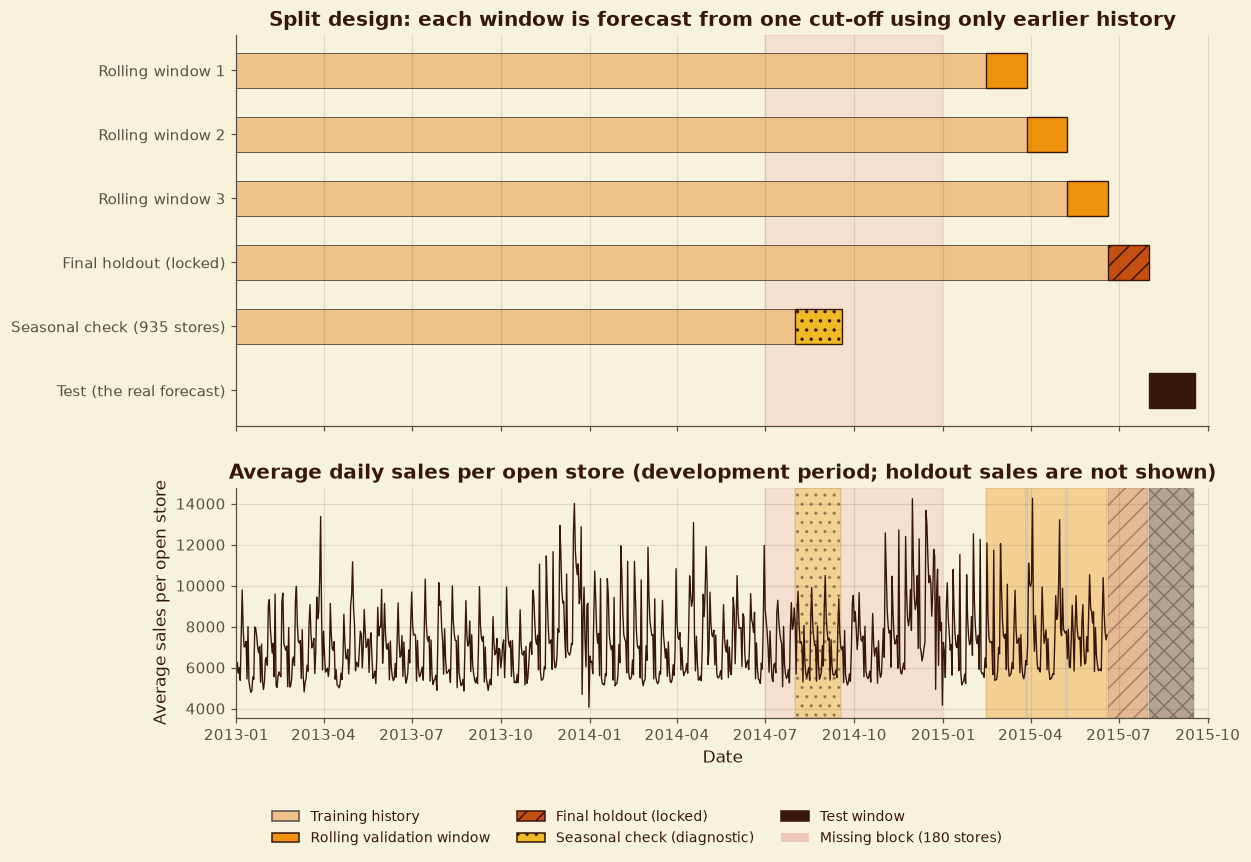

Figure 4.2: Window composition compared with the test window


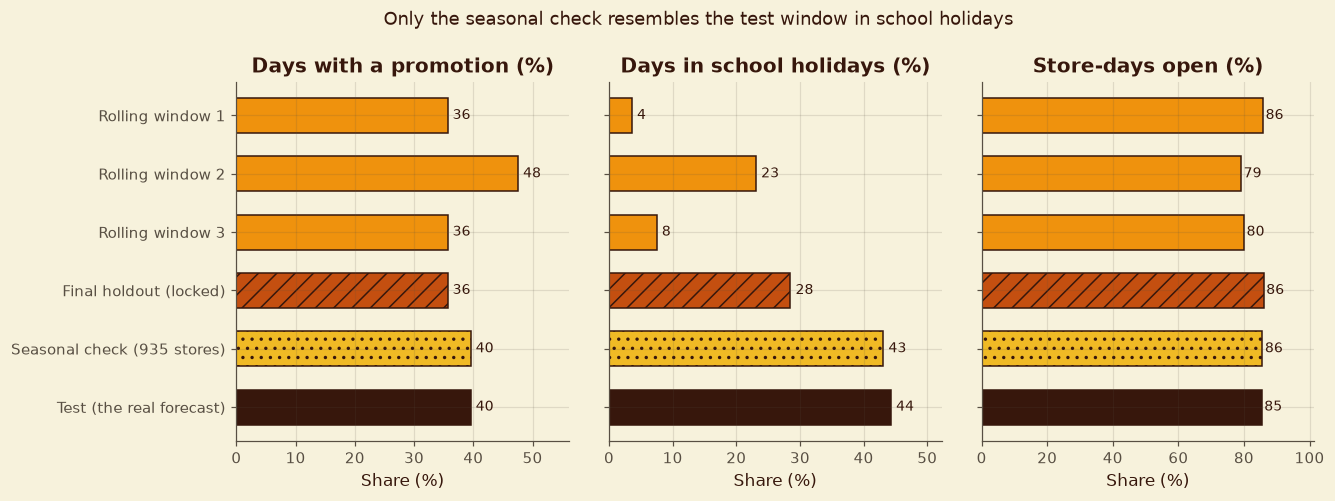

In [33]:
COLORS = {"rolling": PALETTE["marigold"], "holdout": PALETTE["terracotta"],
          "seasonal": PALETTE["saffron"], "test": PALETTE["espresso"], "train": PALETTE["sand"]}
HATCH = {"rolling": "", "holdout": "//", "seasonal": "..", "test": "xx"}
LABELS = {"rolling_1": "Rolling window 1", "rolling_2": "Rolling window 2", "rolling_3": "Rolling window 3",
          "holdout": "Final holdout (locked)", "seasonal_check": f"Seasonal check ({int(composition.loc['seasonal_check', 'stores'])} stores)",
          "test (supplied)": "Test (the real forecast)"}


def kind(name):
    return "rolling" if name.startswith("rolling") else {"holdout": "holdout", "seasonal_check": "seasonal"}.get(name, "test")


gap_start, gap_end = pd.Timestamp("2014-07-01"), pd.Timestamp("2014-12-31")   # block found in Section 3.3
order = ["rolling_1", "rolling_2", "rolling_3", "holdout", "seasonal_check", "test (supplied)"]
plot_rows = boundaries.set_index("split").loc[order]

fig, (ax1, ax2) = plt.subplots(2, 1, sharex=True, figsize=(13, 8.5), gridspec_kw={"height_ratios": [1.7, 1]})
for ax in (ax1, ax2):
    ax.axvspan(gap_start, gap_end, color=PALETTE["rose"], alpha=0.10)

for y, (name, r) in enumerate(plot_rows.iloc[::-1].iterrows()):
    k = kind(name)
    if k != "test":
        ax1.barh(y, (r["train_end"] - r["train_start"]).days + 1, left=mdates.date2num(r["train_start"]), height=0.55,
                 color=COLORS["train"], edgecolor=PALETTE["charcoal"], linewidth=0.6)
    ax1.barh(y, (r["valid_end"] - r["valid_start"]).days + 1, left=mdates.date2num(r["valid_start"]), height=0.55,
             color=COLORS[k], edgecolor=PALETTE["espresso"], hatch=HATCH[k], linewidth=0.9)
ax1.set_yticks(range(len(order)))
ax1.set_yticklabels([LABELS[n] for n in order[::-1]])
ax1.set_title("Split design: each window is forecast from one cut-off using only earlier history")
fig.legend(handles=[
    Patch(facecolor=COLORS["train"], edgecolor=PALETTE["charcoal"], label="Training history"),
    Patch(facecolor=COLORS["rolling"], edgecolor=PALETTE["espresso"], label="Rolling validation window"),
    Patch(facecolor=COLORS["holdout"], edgecolor=PALETTE["espresso"], hatch="//", label="Final holdout (locked)"),
    Patch(facecolor=COLORS["seasonal"], edgecolor=PALETTE["espresso"], hatch="..", label="Seasonal check (diagnostic)"),
    Patch(facecolor=COLORS["test"], edgecolor=PALETTE["espresso"], hatch="xx", label="Test window"),
    Patch(facecolor=PALETTE["rose"], alpha=0.25, label="Missing block (180 stores)"),
], loc="lower center", ncol=3, fontsize=9, bbox_to_anchor=(0.5, 0.0))
ax1.grid(axis="y", visible=False)

# average daily sales per open store, development period only (the holdout sales stay hidden)
dev_end = splits.loc[splits["split"] == "holdout", "train_end"].iloc[0]
daily = (train_clean[(train_clean["use_for_training"] == 1) & (train_clean["Date"] <= dev_end)]
         .groupby("Date")["Sales"].mean())
ax2.plot(daily.index, daily.values, color=FORECAST_COLORS["actual"], linewidth=0.9)
for _, r in plot_rows.iterrows():
    k = kind(r.name)
    ax2.axvspan(r["valid_start"], r["valid_end"], facecolor=COLORS[k], alpha=0.35, hatch=HATCH[k], edgecolor=PALETTE["espresso"], linewidth=0.3)
ax2.set_ylabel("Average sales per open store")
ax2.set_xlabel("Date")
ax2.set_title("Average daily sales per open store (development period; holdout sales are not shown)")
ax2.set_xlim(first_date, test_last + pd.Timedelta(days=15))
fig.subplots_adjust(left=0.22, bottom=0.15)
style.save_figure(fig, 4, "Split design timeline")
plt.show()

# how similar is each window to the test window?
metrics = {"promotion_%": "Days with a promotion (%)", "school_holiday_%": "Days in school holidays (%)", "open_%": "Store-days open (%)"}
fig, axes = plt.subplots(1, 3, figsize=(14, 4.6), sharey=True)
names = [n for n in order]
ypos = np.arange(len(names))[::-1]
for ax, (col, title) in zip(axes, metrics.items()):
    vals = composition.loc[names, col].values
    for y, n_, v in zip(ypos, names, vals):
        k = kind(n_)
        ax.barh(y, v, color=COLORS[k], hatch=HATCH[k], edgecolor=PALETTE["espresso"], height=0.6)
        ax.text(v + 0.8, y, f"{v:.0f}", va="center", fontsize=9)
    ax.set_title(title)
    ax.set_xlim(0, max(composition[col].max() * 1.18, 10))
    ax.set_xlabel("Share (%)")
axes[0].set_yticks(ypos)
axes[0].set_yticklabels([LABELS[n_] for n_ in names])
fig.subplots_adjust(left=0.2, top=0.82, wspace=0.12)
fig.suptitle("Only the seasonal check resembles the test window in school holidays", y=0.96)
style.save_figure(fig, 4, "Window composition compared with the test window")
plt.show()

**Reading the result.**
- **Every rolling window contains all 1,115 stores** (46,830 rows). Of these, 35,952 rows (856 stores × 42 days) belong to the 856 stores that appear in the test file. Section 10 reports results for those stores separately.
- **School holidays differ sharply.** They cover only 4%, 23% and 8% of days in the three rolling windows and 28% in the holdout, but **44% in the test window**. The seasonal check, at 43%, is the only window that matches. Its promotion share (40%) and opening share (86%) also match the test window (40% and 85%).
- **The seasonal check has 935 stores**, because the 180 stores with the 2014 gap have no data in that window. It covers 48 days, so it is also the only check of forecast days 43 to 48.
- **Rolling window 2 has the most promotions (48%) and state holidays (7%)** because it contains Easter, so it tests how well the model handles holiday weeks.
- **Why a single design is not enough:** the rolling windows test stability across time, and the seasonal check tests the summer conditions the real forecast faces. A model that is good on only one of them is not trusted.

## 4.4 Feature-Availability Policy

A model is only valid if every input was known when the forecast was made. Each column is classified, and the rule is enforced by code.

| Information | Class | Use |
|---|---|---|
| Date, weekday, `Open`, `Promo`, state and school holidays (as supplied or planned) | `known_future` | Allowed |
| Store type, assortment, competition and Promo2 details, store ID | `store_static` | Allowed |
| History summarised **up to the forecast origin** | `origin_history` | Allowed |
| `Sales` | `target` | Never an input |
| `Customers` (actual, on the forecast day) | `forbidden` | Never an input to any model, including the customer model |
| Cleaning columns derived from sales (`use_for_training`, `sales_outlier_flag`, etc.) | `row_control` | Select or weight rows only, never inputs |

**Rules that follow**
1. **History features use the origin only.** A store's recent average sales, its weekday profile and its promotion response are computed from days up to the origin and kept fixed over the whole forecast window. For training, rows are built from several past origins, each looking back only from its own origin (built and confirmed in Section 6).
2. **Lag features** such as "sales 7 days ago" are unknown for most of a 6-week window. They are only allowed in a clearly labelled *recursive simulation*, which uses its own earlier predictions, never actual validation sales.
3. **Baselines** repeat history from before the origin: the last observed week, or the store-by-weekday average.
4. **Fitting stays inside the training window.** Scalers, imputers, encoders, aggregates and models are fitted only on rows up to a split's training end date.
5. **The holdout is locked.** `get_masks` refuses to return it unless explicitly unlocked, and every use must be recorded in the evaluation-access log.
6. **Engineered features must be registered** with their class (`register_features`), and `check_features` blocks any model input that is unclassified or forbidden.

The cell below classifies every column, saves the policy and demonstrates both locks.

In [34]:
all_columns = sorted(set(train_clean.columns) | set(test_clean.columns))
policy = pd.DataFrame({
    "column": all_columns,
    "class": [validation.FEATURE_POLICY.get(c, "UNCLASSIFIED") for c in all_columns],
})
policy["allowed_as_model_input"] = policy["class"].isin(validation.ALLOWED_INPUT_CLASSES)
style.show_table(policy.set_index("column"), 4, "Availability class of every column in the cleaned data")
policy.to_csv(config.OUTPUTS_DIR / "feature_policy.csv", index=False)

classes = pd.Series(validation.FEATURE_CLASSES, name="meaning").to_frame()
style.show_table(classes, 4, "Feature-availability classes")

# the policy is enforced by code: a model input list is checked before any model is fitted
validation.check_features(["Promo", "DayOfWeek", "StoreType"])
try:
    validation.check_features(["Promo", "Customers"])
except ValueError as err:
    print("Blocked as intended ->", err)

# the final holdout is locked unless explicitly unlocked
try:
    validation.get_masks(train_clean, splits, "holdout")
except PermissionError as err:
    print("Blocked as intended ->", err)

**Table 4.4: Availability class of every column in the cleaned data**

,class,allowed_as_model_input
column,,
Assortment,store_static,True
CompetitionDistance,store_static,True
CompetitionDistance_missing,store_static,True
CompetitionOpenDate_known,store_static,True
CompetitionOpenSince,store_static,True
CompetitionOpenYear_suspect,store_static,True
Customers,forbidden,False
Date,known_future,True
DayOfWeek,known_future,True


**Table 4.5: Feature-availability classes**

,meaning
known_future,"Calendar, schedule and holiday information known before the forecast date (allowed)"
store_static,Store attributes that do not change during the forecast window (allowed)
origin_history,History summarised using only days up to the forecast origin (allowed)
target,What we predict (never an input)
forbidden,"Actual values from the forecast window, for example Customers on the forecast day (never an input)"
row_control,"Columns that select or flag rows in the cleaning step; derived from sales, so never inputs"
identifier,Row identifiers (never inputs)


2026-10-28 21:44:42 | INFO     | rossmann.validation | Feature policy check passed for 3 features.
Blocked as intended -> Feature policy violation:
  Customers: class 'forbidden' is not allowed as a model input
Blocked as intended -> The final holdout is locked. Only the final evaluation (Section 10) may unlock it, and every use must be written to the evaluation-access log.


**Reading the result.** All 28 columns are classified. 20 can be used as inputs (6 known in advance and 14 store attributes). `Customers`, `Sales`, the identifier and the cleaning controls are blocked. The two "blocked as intended" messages show that a model using `Customers`, or a read of the locked holdout, fails immediately.

## 4.5 Assumptions, Uses of Each Split, and Completion Checks

**Assumptions to keep in mind**
- In validation windows, `Open`, `Promo` and holiday columns use their actual values, as if the plans were known in advance. The real test file supplies the same planned fields, so this mirrors real use, but it flatters accuracy slightly if plans change after a forecast is made.
- Forecast days 43 to 48 of the test window are not covered by the 42-day holdout. They are checked through the 48-day seasonal check.

**What each split is used for**

| Split | Used for | Never used for |
|---|---|---|
| Rolling windows 1 to 3 | Tuning, model comparison, prediction-interval calibration | Final scoring |
| Seasonal check | Reporting how models cope with summer conditions | Tuning (so it stays an independent stress test) |
| Final holdout | One final score (Section 10) | Any decision before the final evaluation |
| Test | The real predictions | Scoring (no sales are available) |

If the rolling windows and the seasonal check disagree about the best model, both results are reported and the choice is recorded in the Decision Register.

In [35]:
rolling_ok = all(
    int(train_clean.loc[validation.get_masks(train_clean, splits, n)[1], "Store"].nunique()) == train_clean["Store"].nunique()
    for n in ["rolling_1", "rolling_2", "rolling_3"]
)
final_checks = pd.DataFrame([
    ("All automatic split checks pass", bool(split_checks["passed"].all())),
    ("Every column has a feature-availability class", bool((policy["class"] != "UNCLASSIFIED").all())),
    ("Customers and the cleaning controls are blocked as model inputs",
     not any(validation.FEATURE_POLICY[c] in validation.ALLOWED_INPUT_CLASSES
             for c in ["Customers", "Sales", "use_for_training", "sales_outlier_flag"])),
    ("The final holdout is locked by default", True),
    ("Every rolling window contains all 1,115 stores", rolling_ok),
    ("Seasonal check uses only stores with a complete history and 48 days",
     int(composition.loc["seasonal_check", "rows"]) == int(composition.loc["seasonal_check", "stores"]) * n_test_days),
    ("Training data of every split ends before its forecast window", bool((splits["train_end"] < splits["valid_start"]).all())),
], columns=["check", "passed"])
style.show_table(final_checks.set_index("check"), 4, "Section 4 completion checks", save=False)
assert final_checks["passed"].all(), "A Section 4 completion check failed"

hold = splits.set_index("split")
fmt = lambda s, col: hold.loc[s, col].strftime("%d %b %Y")

# D03 and D04 were provisional in Section 1; their dates are now fixed
decision_register.loc[decision_register["id"].isin(["D03", "D04"]), "status"] = "Confirmed (dates fixed in Section 4)"

log_decision(4, f"Final holdout = {fmt('holdout', 'valid_start')} to {fmt('holdout', 'valid_end')} (42 days). It is locked in code (get_masks) and every use must be written to the evaluation-access log.",
             "Gives one honest score on history never used for tuning; test.csv has no sales.")
log_decision(4, "Three rolling validation windows of 42 days before the holdout: "
                + "; ".join(f"{n} {fmt(n, 'valid_start')} to {fmt(n, 'valid_end')}" for n in ["rolling_1", "rolling_2", "rolling_3"])
                + ". Each window trains on all history before it (expanding window) and is forecast from one cut-off shared by all stores.",
             "Tests stability over time and matches how the real forecast will be made.")
log_decision(4, f"Seasonal stress test: {fmt('seasonal_check', 'valid_start')} to {fmt('seasonal_check', 'valid_end')} (48 days, {int(composition.loc['seasonal_check', 'stores'])} stores with complete history). Reported alongside the rolling windows, not used for tuning.",
             "It is the only window that resembles the test window (summer school holidays about 43% vs 44%); it also covers forecast days 43 to 48.",
             status="Provisional (confirm in Section 7 if it disagrees with the rolling windows)")
log_decision(4, "Feature-availability policy enforced in code (src/validation.py): only known-future, store-static and origin-history features are allowed as inputs; Customers and cleaning controls are blocked. Engineered features must be registered with a class.",
             "Makes leakage a failed check, not a judgement call.")
log_decision(4, "No fitting of any kind (scalers, imputers, encoders, aggregates, models) on rows after a split's training end date.",
             "Prevents information from the forecast window entering the model.")
log_decision(4, "In validation windows, Open, Promo and holiday columns use their actual values, as if the plans were known in advance.",
             "The real test file supplies the same planned fields, so this mirrors how the forecast will be used.")
log_decision(4, "History features are computed at forecast origins (training rows built from several past origins, each looking back only from its own origin). Lag features are only allowed in a clearly labelled recursive simulation that never uses actual validation sales.",
             "Keeps training rows consistent with how forecasts are produced.",
             status="Provisional (built and confirmed in Section 6)")
log_decision(4, "The final model is refit on all labelled history only after every choice is locked.",
             "Section 10 handles the final refit and the single holdout scoring.")

log_limitation(4, "Validation uses actual Open, Promo and holiday values as if they were known plans.",
               "If real plans change after the forecast is made, true errors will be somewhat larger than validation suggests.")
log_limitation(4, "The rolling windows (February to June) contain little of the summer school-holiday pattern (4% to 23% of days against 44% in test).",
               "Only the seasonal check resembles the test window, and it has fewer stores and a shorter training history.")
log_limitation(4, "The 42-day holdout does not cover forecast days 43 to 48 of the 48-day test window.",
               "Those days are checked only through the seasonal check.")
log_limitation(4, "Only about two and a half years of history exist, with one complete earlier summer (2013) and a partial 2014 summer for 180 stores.",
               "Summer seasonality is learned from very few examples.")
log_limitation(4, "A single 42-day holdout is one draw of forecast conditions.",
               "Holdout error has sampling noise; conclusions rely on the holdout, rolling windows and seasonal check together.")

save_registers()
style.save_index()
display(decision_register.tail(8))
display(limitations.tail(5))
logger.info("Section 4 complete: splits, policy and leakage checks in place.")

# commit the new code (the data has not changed, so no new DVC version is needed)
sh("git add -A")
sh('git commit -m "Section 4: validation splits, feature policy and leakage checks"', check=False)

**Table 4.6: Section 4 completion checks**

,passed
check,
All automatic split checks pass,True
Every column has a feature-availability class,True
Customers and the cleaning controls are blocked as model inputs,True
The final holdout is locked by default,True
"Every rolling window contains all 1,115 stores",True
Seasonal check uses only stores with a complete history and 48 days,True
Training data of every split ends before its forecast window,True


,id,section,decision,reason,status
26,D27,4,Final holdout = 20 Jun 2015 to 31 Jul 2015 (42 days). It is locked in code (get_masks) and every use must be written to the evaluation-access log.,Gives one honest score on history never used for tuning; test.csv has no sales.,Confirmed
27,D28,4,Three rolling validation windows of 42 days before the holdout: rolling_1 14 Feb 2015 to 27 Mar 2015; rolling_2 28 Mar 2015 to 08 May 2015; rolling_3 09 May 2015 to 19 Jun 2015. Each window trains on all history before it (expanding window) and is forecast from one cut-off shared by all stores.,Tests stability over time and matches how the real forecast will be made.,Confirmed
28,D29,4,"Seasonal stress test: 01 Aug 2014 to 17 Sep 2014 (48 days, 935 stores with complete history). Reported alongside the rolling windows, not used for tuning.",It is the only window that resembles the test window (summer school holidays about 43% vs 44%); it also covers forecast days 43 to 48.,Provisional (confirm in Section 7 if it disagrees with the rolling windows)
29,D30,4,"Feature-availability policy enforced in code (src/validation.py): only known-future, store-static and origin-history features are allowed as inputs; Customers and cleaning controls are blocked. Engineered features must be registered with a class.","Makes leakage a failed check, not a judgement call.",Confirmed
30,D31,4,"No fitting of any kind (scalers, imputers, encoders, aggregates, models) on rows after a split's training end date.",Prevents information from the forecast window entering the model.,Confirmed
31,D32,4,"In validation windows, Open, Promo and holiday columns use their actual values, as if the plans were known in advance.","The real test file supplies the same planned fields, so this mirrors how the forecast will be used.",Confirmed
32,D33,4,"History features are computed at forecast origins (training rows built from several past origins, each looking back only from its own origin). Lag features are only allowed in a clearly labelled recursive simulation that never uses actual validation sales.",Keeps training rows consistent with how forecasts are produced.,Provisional (built and confirmed in Section 6)
33,D34,4,The final model is refit on all labelled history only after every choice is locked.,Section 10 handles the final refit and the single holdout scoring.,Confirmed


,id,section,limitation,effect_on_conclusions
13,L14,4,"Validation uses actual Open, Promo and holiday values as if they were known plans.","If real plans change after the forecast is made, true errors will be somewhat larger than validation suggests."
14,L15,4,The rolling windows (February to June) contain little of the summer school-holiday pattern (4% to 23% of days against 44% in test).,"Only the seasonal check resembles the test window, and it has fewer stores and a shorter training history."
15,L16,4,The 42-day holdout does not cover forecast days 43 to 48 of the 48-day test window.,Those days are checked only through the seasonal check.
16,L17,4,"Only about two and a half years of history exist, with one complete earlier summer (2013) and a partial 2014 summer for 180 stores.",Summer seasonality is learned from very few examples.
17,L18,4,A single 42-day holdout is one draw of forecast conditions.,"Holdout error has sampling noise; conclusions rely on the holdout, rolling windows and seasonal check together."


2026-10-28 21:44:42 | INFO     | rossmann | Section 4 complete: splits, policy and leakage checks in place.
[main e95705f] Section 4: validation splits, feature policy and leakage checks
 4 files changed, 66 insertions(+), 2 deletions(-)


CompletedProcess(args='git commit -m "Section 4: validation splits, feature policy and leakage checks"', returncode=0, stdout='[main e95705f] Section 4: validation splits, feature policy and leakage checks\n 4 files changed, 66 insertions(+), 2 deletions(-)\n', stderr='')

## 4.6 Section 4 Summary

**What is now fixed**
- **Final holdout:** 20 Jun to 31 Jul 2015, locked in code and scored once in Section 10.
- **Rolling windows:** 14 Feb to 27 Mar, 28 Mar to 8 May and 9 May to 19 Jun 2015, each trained on all earlier history from a shared cut-off.
- **Seasonal check:** 1 Aug to 17 Sep 2014 (935 stores), the only window that resembles the test window (school holidays 43% vs 44%). It is a diagnostic, not a tuning target.
- **Feature-availability policy:** 28 columns classified; `Customers`, `Sales` and the cleaning controls are blocked as model inputs by `check_features`.
- The Decision Register has 8 new entries (D03 and D04 are now confirmed), and the Limitations List has 5 new entries.

**What comes next**
- **Section 5** explores customer purchasing behaviour and answers every question in the brief. It also produces the 3 to 5 slide interim presentation.

---

# Section 5: Exploration of Customer Purchasing Behaviour

**Purpose of this section:** Answer every question in the Task 1 brief with a plot or table, and say what each finding means for the business and what the data cannot establish.

**Rules followed**
- **The final holdout stays locked.** Every analysis uses only the development period (up to the day before the holdout), even for aggregate charts.
- **Like is compared with like.** Closed days are excluded. Two helper ideas are used throughout:
  - *Ordinary day:* an open day that is not a state holiday.
  - *Sales index:* a day's sales divided by that store's typical sales on that weekday, so big and small stores, and weekdays, can be compared. 1.0 means typical.
- **Every finding is written three ways:** what the evidence shows, what it means for the business, and what the data cannot establish.
- Results are associations. Nothing here proves cause and effect.

| Step | Brief question |
|---|---|
| 5.1 | Data used for the exploration |
| 5.2 | Q1: Are the promotions, holidays and stores distributed alike in train and test? |
| 5.3 | Q2: Sales before, during and after holidays |
| 5.4 | Q3: Seasonal behaviour (Christmas, Easter and more) |
| 5.5 | Q4: Sales and the number of customers |
| 5.6 | Q5: How promotions affect sales and customers, including existing customers |
| 5.7 | Q6: Could promotions be deployed more effectively, and in which stores? |
| 5.8 | Q7: Customer behaviour around opening and closing |
| 5.9 | Q8: Stores open on all weekdays and their weekend sales |
| 5.10 | Q9: Assortment type |
| 5.11 | Q10: Distance to the nearest competitor |
| 5.12 | Q11: Opening of new competitors |
| 5.13 | Summary table of all findings |
| 5.14 | Completion checks, decisions and limitations |

In [36]:
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates

from src import config, style, data, validation
from src.style import PALETTE, FORECAST_COLORS, CATEGORICAL, SEQ_CMAP

train_clean = data.load_interim("train_clean")
test_clean = data.load_interim("test_clean")

# the final holdout stays locked: every analysis in this section stops at the end of the development period
splits = validation.make_splits(train_clean["Date"].min(), train_clean["Date"].max())
dev_end = splits.loc[splits["split"] == "holdout", "train_end"].iloc[0]
eda = train_clean[train_clean["Date"] <= dev_end].copy()
eda["year"], eda["month"] = eda["Date"].dt.year, eda["Date"].dt.month

# open days with positive sales: the rows used for sales analysis
open_days = eda[eda["use_for_training"] == 1].copy()
open_days["sales_per_customer"] = open_days["Sales"] / open_days["Customers"]
# sales index: 1.0 = typical for that store on that weekday (so big and small stores are comparable)
open_days["sales_index"] = open_days["Sales"] / open_days.groupby(["Store", "DayOfWeek"])["Sales"].transform("median")
normal = open_days[open_days["StateHoliday"] == "0"]                       # ordinary days (no state holiday)

WEEKDAY = {1: "Mon", 2: "Tue", 3: "Wed", 4: "Thu", 5: "Fri", 6: "Sat", 7: "Sun"}
MONTHS = ["Jan", "Feb", "Mar", "Apr", "May", "Jun", "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"]
store_info = (train_clean.drop_duplicates("Store").set_index("Store")
              [["StoreType", "Assortment", "Promo2", "CompetitionDistance", "CompetitionDistance_missing",
                "CompetitionOpenSince", "CompetitionOpenDate_known", "has_history_gap"]])

eda_summary = pd.Series({
    "Analysis period": f"{eda['Date'].min().date()} to {eda['Date'].max().date()} (final holdout excluded)",
    "Store-days in the period": f"{len(eda):,}",
    "Open days with positive sales (used for sales analysis)": f"{len(open_days):,}",
    "Stores": eda["Store"].nunique(),
}).to_frame("value")
style.show_table(eda_summary, 5, "Data used for the exploration")

**Table 5.1: Data used for the exploration**

,value
Analysis period,2013-01-01 to 2015-06-19 (final holdout excluded)
Store-days in the period,"970,379"
Open days with positive sales (used for sales analysis),"804,056"
Stores,1115


'Table 5.1'

## 5.2 Q1: Are Promotions and Other Inputs Distributed Alike in Train and Test?

A model learns from train and is used on test. If the two differ in what is *known in advance* (promotions, holidays, opening, store mix), the model's training experience may not match the forecast.

Dates on which stores disagree about promotions: train 0 of 900, test 0 of 48


**Table 5.2: How many weeks in a row stay on promotion (or off)**

times
state                    weeks       
off weeks in a row       1         56
                         2          2
promotion weeks in a row 1         47
                         2         11

**Table 5.3: Promotion, opening and school holidays by weekday: train vs test**

,train_promo_%,test_promo_%,train_open_%,test_open_%,train_school_%,test_school_%
DayOfWeek,,,,,,
Mon,53.9,57.1,94.8,99.9,22.8,61.9
Tue,53.4,57.1,98.8,99.9,24.5,58.9
Wed,53.4,57.1,97.3,99.9,23.1,54.2
Thu,53.3,57.1,92.0,99.9,23.0,53.3
Fri,53.3,50.0,94.8,100.0,24.0,62.2
Sat,0.0,0.0,99.5,97.2,2.0,11.2
Sun,0.0,0.0,2.5,3.2,2.0,11.2


**Table 5.4: Store mix: train vs test stores**

train_stores_%  test_stores_%
StoreType  a            54.0           53.9
           d            31.2           34.3
           c            13.3           10.4
           b             1.5            1.4
Assortment a            53.2           49.4
           b             0.8            1.1
           c            46.0           49.5

**Table 5.5: The test season in earlier years**

,promo_%,school_holiday_%,state_holiday_%
period,,,
1 Aug to 17 Sep 2013 (train),35.4,37.5,0.3
1 Aug to 17 Sep 2014 (train),39.6,43.1,0.0
1 Aug to 17 Sep 2015 (test),39.6,44.3,0.4


Figure 5.1: Promotions and school holidays in train and test


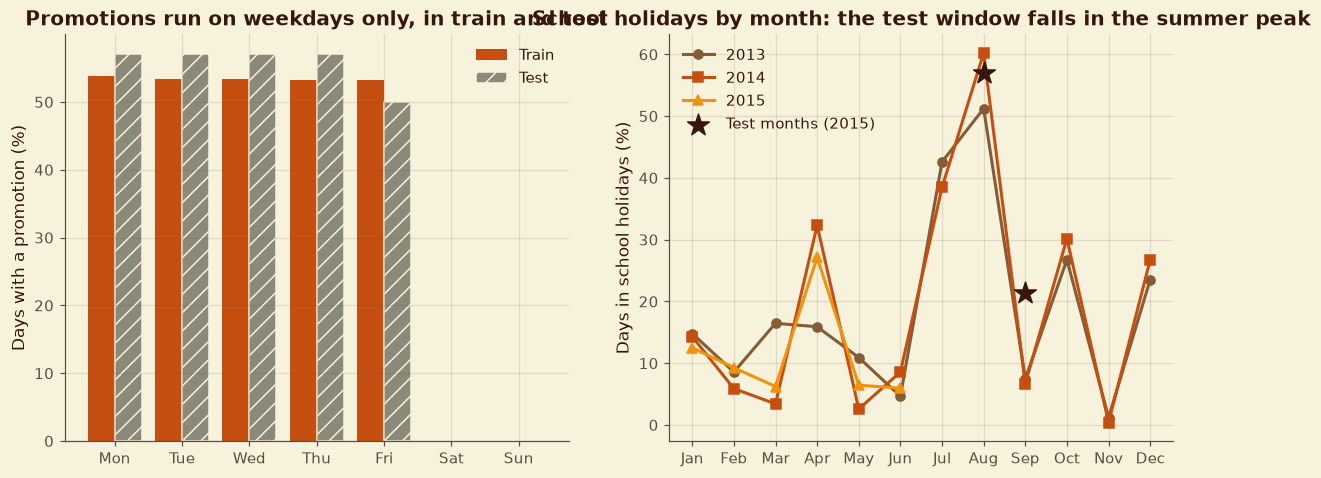

In [37]:
# the promotion calendar: is it the same for every store?
promo_differs_train = int((eda.groupby("Date")["Promo"].nunique() > 1).sum())
promo_differs_test = int((test_clean.groupby("Date")["Promo"].nunique() > 1).sum())
print(f"Dates on which stores disagree about promotions: train {promo_differs_train} of {eda['Date'].nunique()}, "
      f"test {promo_differs_test} of {test_clean['Date'].nunique()}")

# weekly rhythm: is a whole Monday-to-Friday week on promotion or off?
week_flag = eda[eda["DayOfWeek"] == 3].groupby("Date")["Promo"].max()
runs = (week_flag != week_flag.shift()).cumsum()
run_lengths = week_flag.groupby(runs).agg(on_promo="first", weeks="size")
run_summary = (run_lengths.assign(state=lambda x: np.where(x["on_promo"] == 1, "promotion weeks in a row", "off weeks in a row"))
               .groupby(["state", "weeks"]).size().rename("times").reset_index())
style.show_table(run_summary.set_index(["state", "weeks"]), 5, "How many weeks in a row stay on promotion (or off)")

by_day = pd.DataFrame({
    "train_promo_%": eda.groupby("DayOfWeek")["Promo"].mean() * 100,
    "test_promo_%": test_clean.groupby("DayOfWeek")["Promo"].mean() * 100,
    "train_open_%": eda.groupby("DayOfWeek")["Open"].mean() * 100,
    "test_open_%": test_clean.groupby("DayOfWeek")["Open"].mean() * 100,
    "train_school_%": eda.groupby("DayOfWeek")["SchoolHoliday"].mean() * 100,
    "test_school_%": test_clean.groupby("DayOfWeek")["SchoolHoliday"].mean() * 100,
}).round(1)
by_day.index = by_day.index.map(WEEKDAY)
style.show_table(by_day, 5, "Promotion, opening and school holidays by weekday: train vs test")

store_mix = pd.DataFrame({
    "train_stores_%": train_clean.drop_duplicates("Store")["StoreType"].value_counts(normalize=True) * 100,
    "test_stores_%": test_clean.drop_duplicates("Store")["StoreType"].value_counts(normalize=True) * 100,
}).round(1)
assort_mix = pd.DataFrame({
    "train_stores_%": train_clean.drop_duplicates("Store")["Assortment"].value_counts(normalize=True) * 100,
    "test_stores_%": test_clean.drop_duplicates("Store")["Assortment"].value_counts(normalize=True) * 100,
}).round(1)
style.show_table(pd.concat({"StoreType": store_mix, "Assortment": assort_mix}), 5, "Store mix: train vs test stores")

# same season in earlier years
season = []
for y in (2013, 2014):
    w = train_clean[(train_clean["Date"] >= f"{y}-08-01") & (train_clean["Date"] <= f"{y}-09-17")]
    season.append({"period": f"1 Aug to 17 Sep {y} (train)", "promo_%": 100 * w["Promo"].mean(),
                   "school_holiday_%": 100 * w["SchoolHoliday"].mean(), "state_holiday_%": 100 * (w["StateHoliday"] != "0").mean()})
season.append({"period": "1 Aug to 17 Sep 2015 (test)", "promo_%": 100 * test_clean["Promo"].mean(),
               "school_holiday_%": 100 * test_clean["SchoolHoliday"].mean(),
               "state_holiday_%": 100 * (test_clean["StateHoliday"] != "0").mean()})
style.show_table(pd.DataFrame(season).set_index("period").round(1), 5, "The test season in earlier years")

fig, axes = plt.subplots(1, 2, figsize=(13, 4.8))
x = np.arange(1, 8)
axes[0].bar(x - 0.2, by_day["train_promo_%"].values, width=0.4, color=PALETTE["terracotta"], label="Train")
axes[0].bar(x + 0.2, by_day["test_promo_%"].values, width=0.4, color=PALETTE["stone"], hatch="//", edgecolor=PALETTE["cream"], label="Test")
axes[0].set_xticks(x)
axes[0].set_xticklabels(list(WEEKDAY.values()))
axes[0].set_ylabel("Days with a promotion (%)")
axes[0].set_title("Promotions run on weekdays only, in train and test")
axes[0].legend()

school_month = eda.groupby(["year", "month"])["SchoolHoliday"].mean().mul(100).unstack(0)
markers = {2013: "o", 2014: "s", 2015: "^"}
for y, col in zip((2013, 2014, 2015), (PALETTE["clay"], PALETTE["terracotta"], PALETTE["marigold"])):
    s = school_month[y].dropna()
    axes[1].plot(s.index, s.values, marker=markers[y], color=col, linewidth=2, label=f"{y}")
test_school = test_clean.assign(month=test_clean["Date"].dt.month).groupby("month")["SchoolHoliday"].mean() * 100
axes[1].scatter(test_school.index, test_school.values, marker="*", s=220, color=PALETTE["espresso"], zorder=4, label="Test months (2015)")
axes[1].set_xticks(range(1, 13))
axes[1].set_xticklabels(MONTHS)
axes[1].set_ylabel("Days in school holidays (%)")
axes[1].set_title("School holidays by month: the test window falls in the summer peak")
axes[1].legend()
style.save_figure(fig, 5, "Promotions and school holidays in train and test")
plt.show()

**Reading the result (Q1)**
- **What the evidence shows.** Every store follows the *same* promotion calendar (stores disagree on 0 of 900 training dates and 0 of 48 test dates). Promotions run on Monday to Friday only, in alternating weeks: 47 single promotion weeks and 11 runs of two, against 56 single off-weeks and 2 runs of two. In the test window promotions cover 57% of Monday to Thursday days (50% of Fridays, because the window ends on a Thursday) against 53 to 54% in train. In the same season of earlier years, promotions covered 35% (2013) and 40% (2014) of days, and 40% in test. Store mix is similar (store type d 34% vs 31%, type c 10% vs 13%).
- **Where train and test differ.** School holidays cover 44% of test days, but only about 23% of training weekdays. The test window is in summer, where school holidays peak (Figure 5.1, right), and it matches the same season of 2014 (43%). State holidays are almost absent (0.4%).
- **What it means.** The promotion rhythm is familiar to a model trained on history. The summer school-holiday exposure is not, which is why Section 4 added the seasonal check.
- **What the data cannot establish.** Whether summer 2015 behaves like earlier summers. Only 2013 and part of 2014 exist.

## 5.3 Q2: Sales Before, During and After Holidays

Two kinds of holidays are examined. **State holidays** are flagged per store, and holidays that apply to nearly every store (at least 90% of stores) are analysed here: 14 national public holidays, 3 Easters (Good Friday and Easter Monday) and 2 Christmases (25 and 26 December). **School holidays** are examined separately. For open stores, sales are shown relative to a normal day (1.0).

{'National public holidays': 14, 'Easter (Good Friday to Easter Monday)': 3, 'Christmas (25 and 26 Dec)': 2} events in the analysis period


**Table 5.6: Sales (relative to a normal day) and share of stores open around state holidays**

relative_sales                      stores_open_%                     
phase                                  3 days before holiday 3 days after 3 days before holiday 3 days after
type                                                                                                        
National public holidays                        1.03    0.96         1.02         87.42    2.50        81.36
Easter (Good Friday to Easter Monday)           1.40    1.09         0.88         99.85    2.17        99.76
Christmas (25 and 26 Dec)                       1.19    1.03         1.02         83.75    1.74        67.45

Figure 5.2: Sales and opening around state holidays


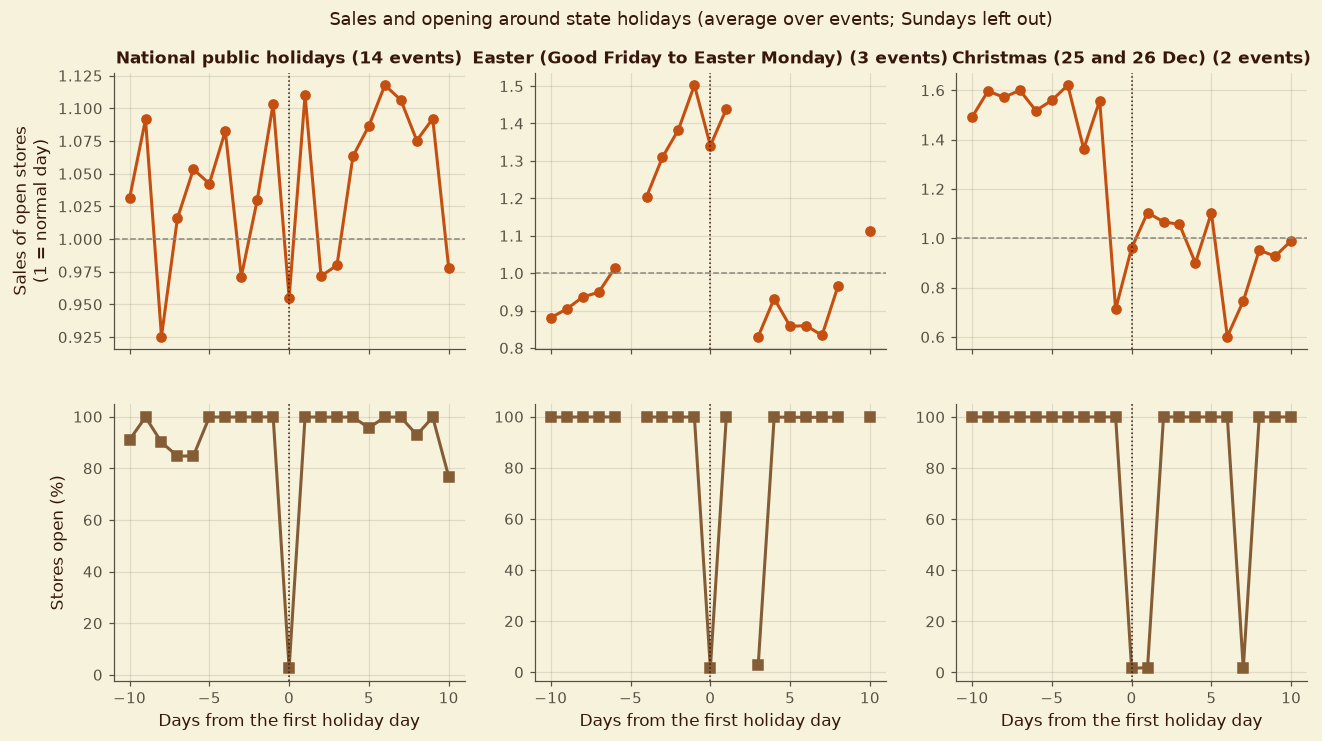

**Table 5.7: Ordinary days inside and outside school holidays (Monday to Saturday)**

,sales_index_no_school,sales_index_school,customers_no_school,customers_school,sales_index_change_%
DayOfWeek,,,,,
Mon,0.94,1.01,845.90,895.66,7.4
Tue,0.99,0.99,771.62,768.11,0.0
Wed,1.01,1.00,745.06,728.19,-1.0
Thu,1.02,1.02,753.33,763.29,0.0
Fri,1.03,0.97,787.73,763.59,-5.8
Sat,1.03,0.97,662.50,657.34,-5.8


'Table 5.7'

In [38]:
# daily chain-level series: average sales index of open stores and share of stores open
daily = open_days.groupby("Date").agg(sales_index=("sales_index", "mean"), customers=("Customers", "mean"))
daily["open_share"] = eda.groupby("Date")["Open"].mean()
normal_mean = normal["sales_index"].mean()
daily["relative"] = daily["sales_index"] / normal_mean            # 1.0 = a normal day

# holiday dates that apply to (almost) every store; regional holidays are left out of the event analysis
flag_share = eda.assign(h=(eda["StateHoliday"] != "0")).groupby("Date")["h"].mean()
holiday_type = eda[eda["StateHoliday"] != "0"].groupby("Date")["StateHoliday"].agg(lambda s: s.mode().iloc[0])
national = pd.DataFrame({"type": holiday_type, "stores_flagged": flag_share.reindex(holiday_type.index)})
national = national[national["stores_flagged"] >= 0.9]


def blocks(dates, max_gap=4):
    """Group holiday dates that belong together (e.g. Good Friday to Easter Monday)."""
    dates = sorted(dates)
    groups, current = [], [dates[0]]
    for d in dates[1:]:
        if (d - current[-1]).days <= max_gap:
            current.append(d)
        else:
            groups.append(current)
            current = [d]
    groups.append(current)
    return groups


event_blocks = {t: blocks(national.index[national["type"] == t]) for t in ["a", "b", "c"]}
TYPE_NAMES = {"a": "National public holidays", "b": "Easter (Good Friday to Easter Monday)", "c": "Christmas (25 and 26 Dec)"}
print({TYPE_NAMES[t]: len(b) for t, b in event_blocks.items()}, "events in the analysis period")


def phase_value(dates, col):
    return daily.reindex(dates)[col]


rows = []
for t, bl in event_blocks.items():
    for b in bl:
        start, end = b[0], b[-1]
        before = pd.date_range(start - pd.Timedelta(days=3), start - pd.Timedelta(days=1))
        after = pd.date_range(end + pd.Timedelta(days=1), end + pd.Timedelta(days=3))
        during = pd.DatetimeIndex(b)                     # only the actual holiday dates (not the Saturday or Sunday in between)
        for phase, dates in [("3 days before", before), ("holiday", during), ("3 days after", after)]:
            rows.append({"type": TYPE_NAMES[t], "event": start.date(), "phase": phase,
                         "relative_sales": phase_value(dates, "relative").mean(),
                         "stores_open_%": 100 * phase_value(dates, "open_share").mean()})
phases = pd.DataFrame(rows)
phase_summary = (phases.groupby(["type", "phase"], sort=False)[["relative_sales", "stores_open_%"]].mean()
                 .round(2).unstack("phase"))
phase_summary = phase_summary.reindex(columns=["3 days before", "holiday", "3 days after"], level=1)
style.show_table(phase_summary, 5, "Sales (relative to a normal day) and share of stores open around state holidays")

# offsets from the first day of each holiday block
offsets = range(-10, 11)
curves = {}
for t, bl in event_blocks.items():
    rel, opn = [], []
    for b in bl:
        idx = [b[0] + pd.Timedelta(days=k) for k in offsets]
        sunday = np.array([d.dayofweek == 6 for d in idx])          # Sundays are left out: almost every store is closed anyway
        r = daily.reindex(idx)["relative"].values.astype(float)
        o_ = daily.reindex(idx)["open_share"].values * 100
        r[sunday], o_[sunday] = np.nan, np.nan
        rel.append(r)
        opn.append(o_)
    with warnings.catch_warnings():
        warnings.simplefilter("ignore", category=RuntimeWarning)
        curves[t] = (np.nanmean(np.array(rel), axis=0), np.nanmean(np.array(opn), axis=0))

fig, axes = plt.subplots(2, 3, figsize=(14, 7), sharex=True)
for j, t in enumerate(["a", "b", "c"]):
    rel, opn = curves[t]
    axes[0, j].plot(list(offsets), rel, marker="o", color=PALETTE["terracotta"], linewidth=2)
    axes[0, j].axhline(1, color=PALETTE["stone"], linestyle="--", linewidth=1)
    axes[0, j].axvline(0, color=PALETTE["espresso"], linestyle=":", linewidth=1)
    axes[0, j].set_title(TYPE_NAMES[t] + f" ({len(event_blocks[t])} events)", fontsize=11)
    axes[1, j].plot(list(offsets), opn, marker="s", color=PALETTE["clay"], linewidth=2)
    axes[1, j].axvline(0, color=PALETTE["espresso"], linestyle=":", linewidth=1)
    axes[1, j].set_xlabel("Days from the first holiday day")
axes[0, 0].set_ylabel("Sales of open stores\n(1 = normal day)")
axes[1, 0].set_ylabel("Stores open (%)")
fig.suptitle("Sales and opening around state holidays (average over events; Sundays left out)", y=0.98)
fig.subplots_adjust(top=0.9)
style.save_figure(fig, 5, "Sales and opening around state holidays")
plt.show()

# school holidays
school = (normal[normal["DayOfWeek"] <= 6].groupby(["DayOfWeek", "SchoolHoliday"])
          .agg(sales=("Sales", "mean"), customers=("Customers", "mean"), sales_index=("sales_index", "mean")).unstack())
school_effect = pd.DataFrame({
    "sales_index_no_school": school[("sales_index", 0)], "sales_index_school": school[("sales_index", 1)],
    "customers_no_school": school[("customers", 0)], "customers_school": school[("customers", 1)],
}).round(2)
school_effect["sales_index_change_%"] = (100 * (school_effect["sales_index_school"] / school_effect["sales_index_no_school"] - 1)).round(1)
school_effect.index = school_effect.index.map(WEEKDAY)
style.show_table(school_effect, 5, "Ordinary days inside and outside school holidays (Monday to Saturday)")

**Reading the result (Q2)**
- **What the evidence shows.** Stores are almost all closed on state holidays (only about 2% open). Among open stores:
  - **Easter:** sales run at 1.40 times a normal day in the 3 days before Good Friday, climbing to about 1.5 on the Thursday, and drop to 0.88 in the 3 days after Easter Monday.
  - **Christmas:** 1.19 in the 3 days before and about 1.0 after; the run-up stays near 1.5 to 1.6 for ten days (Figure 5.2).
  - **National holidays:** 1.03 before, 0.96 on the day (few stores open), 1.02 after.
- **School holidays** show no consistent change on ordinary days (Monday +7%, Friday and Saturday about −6%, other days about 0%).
- **What it means.** Holiday weeks need features of their own: a run-up uplift before, a closure on the day and, after Easter, a lull.
- **What the data cannot establish.** These averages rest on only 3 Easters, 2 Christmases and 14 national holidays, and regional holidays (flagged for only part of the stores) were left out.

## 5.4 Q3: Seasonal Behaviour (Christmas, Easter and More)

Seasonality is shown by month, around Easter, and through December.

Figure 5.3: Seasonal patterns: months, Easter and Christmas


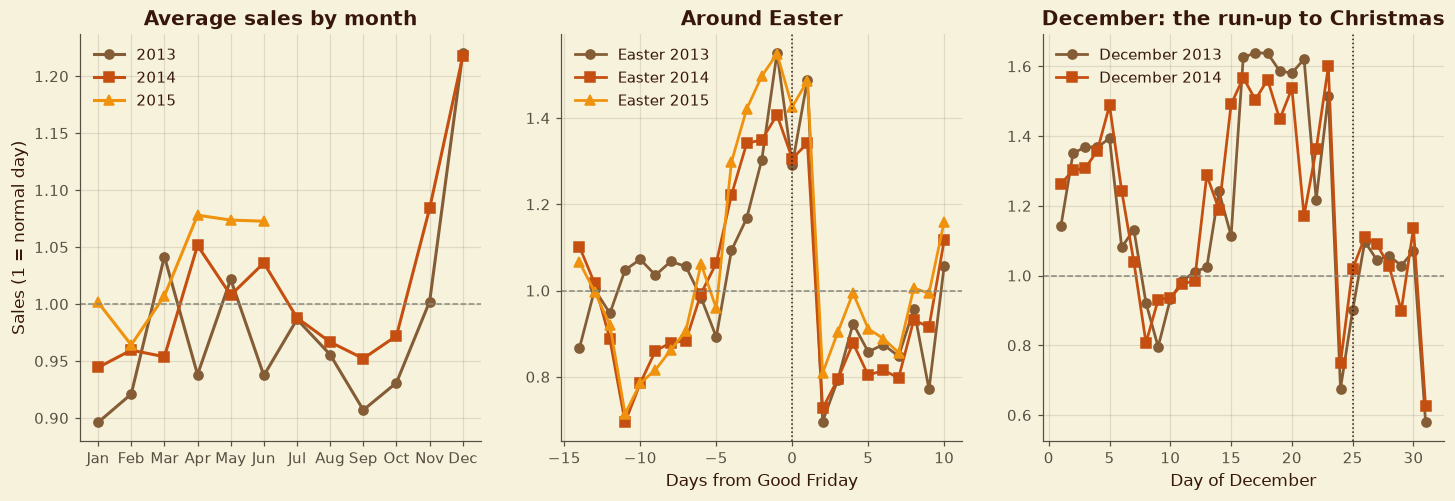

**Table 5.8: Seasonal windows relative to a normal day (1.00)**

,relative_sales,years
window,,
Easter run-up (7 days before Good Friday),1.19,3
Christmas run-up (15 to 23 Dec),1.49,2
24 December,0.71,2
Between Christmas and New Year (27 to 31 Dec),0.96,2
January (after the holidays),0.94,3
July and August (summer),1.00,2


'Table 5.8'

In [39]:
monthly = open_days.groupby(["year", "month"])["sales_index"].mean().div(normal_mean).unstack(0)

easter_dates = {y: next(b[0] for b in event_blocks["b"] if b[0].year == y) for y in (2013, 2014, 2015)}
easter_curves = {}
for y, gf in easter_dates.items():
    idx = [gf + pd.Timedelta(days=k) for k in range(-14, 11)]
    easter_curves[y] = daily.reindex(idx)["relative"].values

december = {y: daily.loc[f"{y}-12-01":f"{y}-12-31", "relative"] for y in (2013, 2014)}

fig, axes = plt.subplots(1, 3, figsize=(16, 4.8))
for y, col in zip((2013, 2014, 2015), (PALETTE["clay"], PALETTE["terracotta"], PALETTE["marigold"])):
    s = monthly[y].dropna()
    axes[0].plot(s.index, s.values, marker=markers[y], color=col, linewidth=2, label=str(y))
axes[0].axhline(1, color=PALETTE["stone"], linestyle="--", linewidth=1)
axes[0].set_xticks(range(1, 13))
axes[0].set_xticklabels(MONTHS)
axes[0].set_ylabel("Sales (1 = normal day)")
axes[0].set_title("Average sales by month")
axes[0].legend()
for y, col in zip((2013, 2014, 2015), (PALETTE["clay"], PALETTE["terracotta"], PALETTE["marigold"])):
    axes[1].plot(range(-14, 11), easter_curves[y], marker=markers[y], color=col, linewidth=1.8, label=f"Easter {y}")
axes[1].axvline(0, color=PALETTE["espresso"], linestyle=":", linewidth=1)
axes[1].axhline(1, color=PALETTE["stone"], linestyle="--", linewidth=1)
axes[1].set_xlabel("Days from Good Friday")
axes[1].set_title("Around Easter")
axes[1].legend()
for y, col in zip((2013, 2014), (PALETTE["clay"], PALETTE["terracotta"])):
    axes[2].plot(december[y].index.day, december[y].values, marker=markers[y], color=col, linewidth=1.8, label=f"December {y}")
axes[2].axvline(25, color=PALETTE["espresso"], linestyle=":", linewidth=1)
axes[2].axhline(1, color=PALETTE["stone"], linestyle="--", linewidth=1)
axes[2].set_xlabel("Day of December")
axes[2].set_title("December: the run-up to Christmas")
axes[2].legend()
style.save_figure(fig, 5, "Seasonal patterns: months, Easter and Christmas")
plt.show()

windows = {
    "Easter run-up (7 days before Good Friday)": [(easter_dates[y] - pd.Timedelta(days=7), easter_dates[y] - pd.Timedelta(days=1)) for y in (2013, 2014, 2015)],
    "Christmas run-up (15 to 23 Dec)": [(pd.Timestamp(f"{y}-12-15"), pd.Timestamp(f"{y}-12-23")) for y in (2013, 2014)],
    "24 December": [(pd.Timestamp(f"{y}-12-24"), pd.Timestamp(f"{y}-12-24")) for y in (2013, 2014)],
    "Between Christmas and New Year (27 to 31 Dec)": [(pd.Timestamp(f"{y}-12-27"), pd.Timestamp(f"{y}-12-31")) for y in (2013, 2014)],
    "January (after the holidays)": [(pd.Timestamp(f"{y}-01-05"), pd.Timestamp(f"{y}-01-31")) for y in (2013, 2014, 2015)],
    "July and August (summer)": [(pd.Timestamp(f"{y}-07-01"), pd.Timestamp(f"{y}-08-31")) for y in (2013, 2014)],
}
seasonal_rows = []
for name, spans in windows.items():
    vals = [daily.loc[a:b, "relative"].mean() for a, b in spans]
    seasonal_rows.append({"window": name, "relative_sales": np.mean(vals), "years": len(spans)})
seasonal_table = pd.DataFrame(seasonal_rows).set_index("window").round(2)
style.show_table(seasonal_table, 5, "Seasonal windows relative to a normal day (1.00)")

**Reading the result (Q3)**
- **What the evidence shows.** December is the peak, at about 1.22 times a normal day in both 2013 and 2014. The 15 to 23 December run-up averages 1.49, but **24 December falls to 0.71**. Easter run-up weeks average 1.19. January is the low point (0.94), and July and August are normal (1.00). The monthly pattern repeats closely from 2013 to 2014, and spring 2015 runs above both earlier years (Figure 5.3).
- **What it means.** Sales are strongly seasonal with a repeatable shape, so calendar features should carry a large part of the forecast.
- **What the data cannot establish.** Only two full years exist, so a different pattern in 2015 cannot be ruled out. The July to December 2014 months are missing for 180 stores, and the monthly line uses the stores that are present.

## 5.5 Q4: Sales and the Number of Customers

How closely do sales follow customers, overall, inside a single store and by store type?

**Table 5.9: How closely sales follow the number of customers**

,value
"Pearson correlation, all open days",0.825
"Spearman (rank) correlation, all open days",0.833
Share of sales variation explained by customers (R squared),68%
Median correlation inside a single store,0.947
Lowest and highest correlation inside a store,0.48 and 0.98


**Table 5.10: Sales, customers and spend per customer by store type**

,stores,avg_sales,avg_customers,sales_per_customer,correlation
StoreType,,,,,
a,602,6928.16,797.28,8.69,0.90
b,17,10205.71,2016.48,5.06,0.87
c,148,6935.46,817.66,8.48,0.89
d,348,6814.41,607.06,11.23,0.86


Figure 5.4: Sales and customers


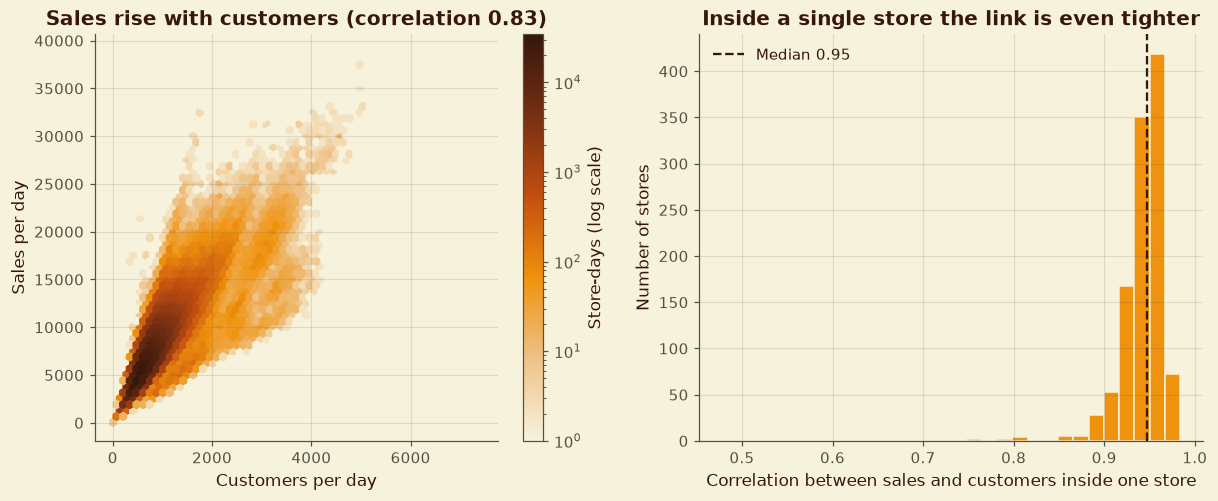

In [40]:
within = open_days.groupby("Store")[["Sales", "Customers"]].corr().xs("Customers", level=1)["Sales"]
r_all = open_days["Sales"].corr(open_days["Customers"])
corr_summary = pd.Series({
    "Pearson correlation, all open days": round(r_all, 3),
    "Spearman (rank) correlation, all open days": round(open_days["Sales"].corr(open_days["Customers"], method="spearman"), 3),
    "Share of sales variation explained by customers (R squared)": f"{100 * r_all ** 2:.0f}%",
    "Median correlation inside a single store": round(within.median(), 3),
    "Lowest and highest correlation inside a store": f"{within.min():.2f} and {within.max():.2f}",
}, dtype=object).to_frame("value")
style.show_table(corr_summary, 5, "How closely sales follow the number of customers")

by_type = open_days.groupby("StoreType").agg(stores=("Store", "nunique"), avg_sales=("Sales", "mean"), avg_customers=("Customers", "mean"),
                                               sales_total=("Sales", "sum"), customers_total=("Customers", "sum"))
by_type["sales_per_customer"] = by_type["sales_total"] / by_type["customers_total"]
by_type["correlation"] = open_days.groupby("StoreType")[["Sales", "Customers"]].corr().xs("Customers", level=1)["Sales"]
style.show_table(by_type.drop(columns=["sales_total", "customers_total"]).round(2), 5, "Sales, customers and spend per customer by store type")

fig, axes = plt.subplots(1, 2, figsize=(13, 4.8))
hb = axes[0].hexbin(open_days["Customers"], open_days["Sales"], gridsize=55, cmap=SEQ_CMAP, mincnt=1, bins="log")
fig.colorbar(hb, ax=axes[0], label="Store-days (log scale)")
axes[0].set_xlabel("Customers per day")
axes[0].set_ylabel("Sales per day")
axes[0].set_title(f"Sales rise with customers (correlation {r_all:.2f})")
axes[1].hist(within.values, bins=30, color=PALETTE["marigold"], edgecolor=PALETTE["cream"])
axes[1].axvline(within.median(), color=PALETTE["espresso"], linestyle="--", linewidth=1.5, label=f"Median {within.median():.2f}")
axes[1].set_xlabel("Correlation between sales and customers inside one store")
axes[1].set_ylabel("Number of stores")
axes[1].set_title("Inside a single store the link is even tighter")
axes[1].legend()
style.save_figure(fig, 5, "Sales and customers")
plt.show()

**Reading the result (Q4)**
- **What the evidence shows.** The correlation between sales and customers is 0.83 across all open days, so customers explain about 68% of the variation in sales. Inside a typical store it is 0.95 (range 0.48 to 0.98). Spend per customer differs a lot by store type: type d stores average 11.2 per customer, types a and c about 8.5 to 8.7, and type b only 5.1. Type b stores (17 of them) have by far the most customers (about 2,016 a day against 600 to 820).
- **What it means.** Customer numbers are the main driver of sales, but **customers are not available in the test period**, so the model must forecast sales without them. Type b stores are traffic-driven, with small baskets.
- **What the data cannot establish.** A strong correlation does not show that more customers *cause* more sales, and the counts cannot be split into new and returning customers.

## 5.6 Q5: How Promotions Affect Sales and Customers

Promotions only run Monday to Friday, so all comparisons use ordinary Monday-to-Friday open days. Three questions are answered:
1. How much do promotions raise **sales**, **customers** and **spend per customer**?
2. Is it the same for every store and every weekday?
3. What happens to **existing customers**? The data cannot separate existing from new customers, so indirect evidence is used: whether the days *after* a promotion week fall back.

**Table 5.11: Promotion vs no promotion on ordinary Monday-to-Friday open days**

,sales,customers,days,sales_per_customer
Promo,,,,
No promotion,5922.3,705.1,302646.0,8.4
Promotion,8215.1,845.0,359738.0,9.7
Change (%),38.7,19.8,NaN,15.7


**Table 5.12: Promotion effect by weekday**

,sales_no_promo,sales_promo,sales_lift_%,customers_no_promo,customers_promo,customers_lift_%
DayOfWeek,,,,,,
Mon,6204.7,9762.0,57.3,741.5,945.1,27.5
Tue,5717.3,8246.7,44.2,688.7,841.4,22.2
Wed,5608.4,7677.0,36.9,672.8,799.9,18.9
Thu,5731.2,7591.6,32.5,687.0,810.8,18.0
Fri,6356.9,7727.8,21.6,737.0,824.1,11.8


**Table 5.13: Promotion lift across stores (each store compared with itself)**

,sales_lift_%,customers_lift_%
min,2.0,1.3
10%,25.0,12.5
50%,39.2,20.4
90%,55.4,30.1
max,103.2,61.7


**Table 5.14: Average customers per day in promotion weeks and off weeks**

,Off week,Promotion week
DayOfWeek,,
Mon,742.0,945.0
Tue,689.0,841.0
Wed,673.0,800.0
Thu,687.0,811.0
Fri,737.0,824.0
Sat,652.0,672.0


Figure 5.5: Promotion effect by weekday and across stores


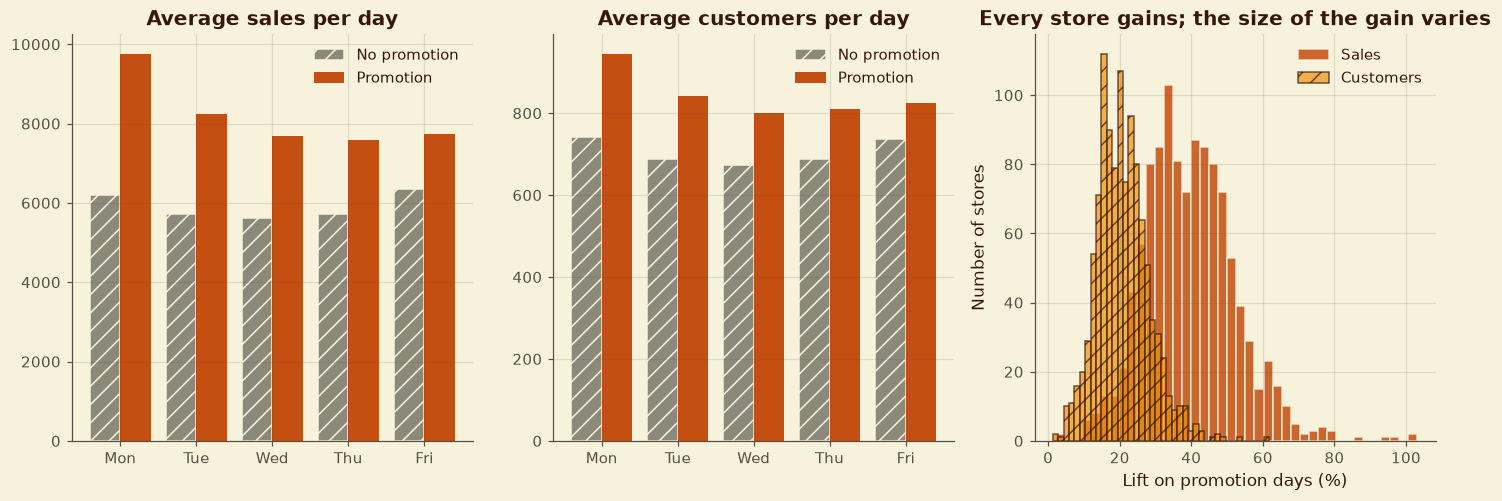

In [41]:
promo_days = normal[normal["DayOfWeek"] <= 5]          # promotions only run Monday to Friday, so compare like with like
promo_overall = promo_days.groupby("Promo").agg(sales=("Sales", "mean"), customers=("Customers", "mean"), days=("Sales", "size"))
promo_overall["sales_per_customer"] = promo_overall["sales"] / promo_overall["customers"]
change = (promo_overall.loc[1, ["sales", "customers", "sales_per_customer"]] / promo_overall.loc[0, ["sales", "customers", "sales_per_customer"]] - 1) * 100
promo_table = promo_overall.rename(index={0: "No promotion", 1: "Promotion"}).round(1)
promo_table.loc["Change (%)"] = [change["sales"], change["customers"], np.nan, change["sales_per_customer"]]
style.show_table(promo_table.round(1), 5, "Promotion vs no promotion on ordinary Monday-to-Friday open days")

wd = promo_days.groupby(["DayOfWeek", "Promo"]).agg(sales=("Sales", "mean"), customers=("Customers", "mean")).unstack()
promo_by_day = pd.DataFrame({
    "sales_no_promo": wd[("sales", 0)], "sales_promo": wd[("sales", 1)],
    "sales_lift_%": 100 * (wd[("sales", 1)] / wd[("sales", 0)] - 1),
    "customers_no_promo": wd[("customers", 0)], "customers_promo": wd[("customers", 1)],
    "customers_lift_%": 100 * (wd[("customers", 1)] / wd[("customers", 0)] - 1),
}).round(1)
promo_by_day.index = promo_by_day.index.map(WEEKDAY)
style.show_table(promo_by_day, 5, "Promotion effect by weekday")

store_promo = promo_days.groupby(["Store", "Promo"]).agg(sales=("Sales", "mean"), customers=("Customers", "mean")).unstack()
lift_sales = 100 * (store_promo[("sales", 1)] / store_promo[("sales", 0)] - 1)
lift_cust = 100 * (store_promo[("customers", 1)] / store_promo[("customers", 0)] - 1)
lift_summary = pd.DataFrame({"sales_lift_%": lift_sales.describe(percentiles=[0.1, 0.5, 0.9]),
                             "customers_lift_%": lift_cust.describe(percentiles=[0.1, 0.5, 0.9])}).loc[["min", "10%", "50%", "90%", "max"]].round(1)
style.show_table(lift_summary, 5, "Promotion lift across stores (each store compared with itself)")

# does a promotion week leave a hangover? (existing customers: only indirect evidence is possible)
week_start = (eda["Date"] - pd.to_timedelta(eda["Date"].dt.dayofweek, unit="D"))
week_promo = eda.assign(week=week_start)[eda["DayOfWeek"] == 3].groupby("week")["Promo"].max()
ordinary = normal.assign(week=normal["Date"] - pd.to_timedelta(normal["Date"].dt.dayofweek, unit="D"))
ordinary["promotion_week"] = ordinary["week"].map(week_promo)
profile = ordinary.groupby(["promotion_week", "DayOfWeek"])["Customers"].mean().unstack(0)
profile.columns = ["Off week", "Promotion week"]
profile.index = profile.index.map(WEEKDAY)
profile = profile.loc[["Mon", "Tue", "Wed", "Thu", "Fri", "Sat"]].round(0)       # Sunday is left out: only 33 stores open on Sundays
saturday_gap = 100 * (profile.loc["Sat", "Promotion week"] / profile.loc["Sat", "Off week"] - 1)
style.show_table(profile, 5, "Average customers per day in promotion weeks and off weeks")
monday_ratio = {c: profile.loc["Mon", c] / profile.loc[["Tue", "Wed", "Thu"], c].mean() for c in profile.columns}

fig, axes = plt.subplots(1, 3, figsize=(16, 4.8))
x = np.arange(5)
for ax, col, title in [(axes[0], "sales", "Average sales per day"), (axes[1], "customers", "Average customers per day")]:
    ax.bar(x - 0.2, wd[(col, 0)].values, width=0.4, color=PALETTE["stone"], hatch="//", edgecolor=PALETTE["cream"], label="No promotion")
    ax.bar(x + 0.2, wd[(col, 1)].values, width=0.4, color=PALETTE["terracotta"], label="Promotion")
    ax.set_xticks(x)
    ax.set_xticklabels([WEEKDAY[i] for i in range(1, 6)])
    ax.set_title(title)
    ax.legend()
axes[2].hist(lift_sales.values, bins=40, color=PALETTE["terracotta"], alpha=0.85, edgecolor=PALETTE["cream"], label="Sales")
axes[2].hist(lift_cust.values, bins=40, color=PALETTE["marigold"], alpha=0.7, hatch="//", edgecolor=PALETTE["espresso"], label="Customers")
axes[2].set_xlabel("Lift on promotion days (%)")
axes[2].set_ylabel("Number of stores")
axes[2].set_title("Every store gains; the size of the gain varies")
axes[2].legend()
style.save_figure(fig, 5, "Promotion effect by weekday and across stores")
plt.show()

**Reading the result (Q5)**
- **What the evidence shows.** On ordinary Monday-to-Friday days, a promotion raises average sales from 5,922 to 8,215 (**+39%**), customers from 705 to 845 (**+20%**) and spend per customer from 8.4 to 9.7 (**+16%**). The lift is largest on Monday (+57%) and shrinks through the week to +22% on Friday. **Every store gains**: the median is +39%, the middle 80% of stores gain between 25% and 55%, and the smallest gain is +2%.
- **Existing customers (indirect evidence).** Saturdays in promotion weeks are about 3% busier than in off weeks (672 vs 652 customers), and the first day of an off week is not weak (Monday customers are 1.09 times the Tuesday to Thursday average, against 1.16 in promotion weeks). There is no sign that promotions pull sales forward and leave a hangover.
- **What it means.** Promotions bring more shoppers *and* bigger baskets, with no visible penalty in the following days.
- **What the data cannot establish.** Promotion days were not randomised, so this is an association, not proof of cause. The data cannot split customers into existing and new, so "no hangover" is indirect evidence only.

## 5.7 Q6: Could Promotions Be Deployed More Effectively, and in Which Stores?

Because every store runs the *same* calendar, the question becomes: **which stores respond most and least?** Each store is compared with itself (promotion days against ordinary non-promotion days), and then grouped by type, assortment, size, Promo2 membership and competitor distance.

**Table 5.15: Where promotions work best: median lift by store group**

stores  median_lift_pct  median_extra_sales
Store type          a                          602             36.9              2140.0
                    b                           17             14.7              1621.0
                    c                          148             40.1              2157.8
                    d                          348             42.0              2313.6
Assortment          a                          593             41.6              2184.5
                    b                            9             11.6               984.7
                    c                          513             36.2              2219.7
Store size          Smallest 25% of stores     279             42.6              1576.5
                    Lower middle               279             40.5              2018.5
                    Upper middle               278             39.2              2364.6
                    Largest 25% of stores      279             34.3              2845.0
Promo2              In Promo2                  571             42.2              2219.7
                    Not in Promo2              544             35.2              2168.3
Competitor distance under 500 m                220             40.9              2470.3
                    500 m to 1 km              110             36.4              1996.9
                    1 to 2 km                  172             35.6              2088.4
                    2 to 5 km                  264             39.0              2148.9
                    5 to 10 km                 162             39.2              2165.7
                    over 10 km                 187             39.5              2187.7

**Table 5.16: The ten stores that respond most and least to promotions**

StoreType Assortment  base_sales  sales_lift_%  extra_sales_per_promo_day
             Store                                                                          
Highest lift 198           a          a      2118.9         103.2                     2186.7
             693           d          a      4535.4         100.8                     4571.0
             543           c          a      1985.8          98.1                     1948.8
             636           c          a      4055.5          93.3                     3785.3
             575           a          a      4084.2          86.0                     3514.2
             552           a          a      5871.7          80.0                     4696.8
             21            c          c      3887.8          78.5                     3052.8
             977           a          a      3602.2          78.4                     2825.7
             793           d          a      3491.5          77.7                     2712.7
             607           a          a      3128.2          77.6                     2429.0
Lowest lift  789           a          c      3432.3           2.0                       68.3
             794           c          c      3163.5           2.1                       65.5
             353           b          b      5104.1          10.6                      542.8
             948           b          b      6170.6          11.0                      678.2
             274           b          b      3289.6          11.4                      374.3
             769           b          b     10239.0          11.4                     1167.3
             760           a          a      7017.2          11.6                      810.6
             733           b          b     14152.8          11.6                     1645.7
             512           b          b      5082.1          12.1                      615.8
             259           b          b     10697.5          12.2                     1300.9

Rank correlation between a store's size and its promotion lift: -0.22
Figure 5.6: Where promotions work best


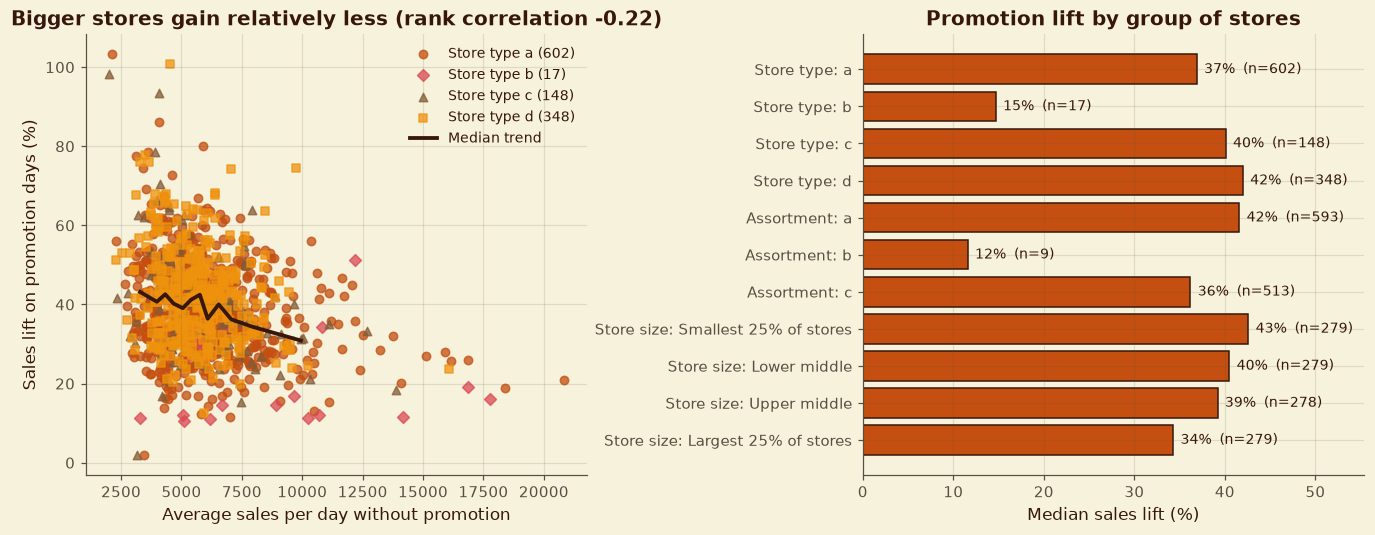

In [42]:
store_lift = pd.DataFrame({
    "base_sales": store_promo[("sales", 0)], "promo_sales": store_promo[("sales", 1)],
    "sales_lift_%": lift_sales, "customers_lift_%": lift_cust,
}).join(store_info)
store_lift["extra_sales_per_promo_day"] = store_lift["promo_sales"] - store_lift["base_sales"]
store_lift["size_group"] = pd.qcut(store_lift["base_sales"], 4, labels=["Smallest 25% of stores", "Lower middle", "Upper middle", "Largest 25% of stores"])
store_lift["competition_band"] = pd.cut(store_lift["CompetitionDistance"], [0, 500, 1000, 2000, 5000, 10000, 1e7],
                                        labels=["under 500 m", "500 m to 1 km", "1 to 2 km", "2 to 5 km", "5 to 10 km", "over 10 km"])
store_lift["Promo2"] = store_lift["Promo2"].map({0: "Not in Promo2", 1: "In Promo2"})


def group_table(col, label):
    g = store_lift.groupby(col, observed=True).agg(stores=("base_sales", "size"), median_lift_pct=("sales_lift_%", "median"),
                                                   median_extra_sales=("extra_sales_per_promo_day", "median"))
    g.index = pd.MultiIndex.from_product([[label], g.index.astype(str)])
    return g


targeting = pd.concat([group_table("StoreType", "Store type"), group_table("Assortment", "Assortment"),
                       group_table("size_group", "Store size"), group_table("Promo2", "Promo2"),
                       group_table("competition_band", "Competitor distance")]).round(1)
style.show_table(targeting, 5, "Where promotions work best: median lift by store group")

rank_cols = ["StoreType", "Assortment", "base_sales", "sales_lift_%", "extra_sales_per_promo_day"]
top10 = store_lift.sort_values("sales_lift_%", ascending=False).head(10)[rank_cols].round(1)
bottom10 = store_lift.sort_values("sales_lift_%").head(10)[rank_cols].round(1)
style.show_table(pd.concat({"Highest lift": top10, "Lowest lift": bottom10}), 5, "The ten stores that respond most and least to promotions")
rho = store_lift["sales_lift_%"].corr(store_lift["base_sales"], method="spearman")
print(f"Rank correlation between a store's size and its promotion lift: {rho:.2f}")

fig, axes = plt.subplots(1, 2, figsize=(14, 5.2))
type_style = {"a": ("o", PALETTE["terracotta"]), "b": ("D", PALETTE["rose"]), "c": ("^", PALETTE["clay"]), "d": ("s", PALETTE["marigold"])}
for t, (mk, col) in type_style.items():
    sub = store_lift[store_lift["StoreType"] == t]
    axes[0].scatter(sub["base_sales"], sub["sales_lift_%"], marker=mk, color=col, s=30, alpha=0.75, label=f"Store type {t} ({len(sub)})")
bins = pd.qcut(store_lift["base_sales"], 12)
trend = store_lift.groupby(bins, observed=True).agg(x=("base_sales", "median"), y=("sales_lift_%", "median"))
axes[0].plot(trend["x"], trend["y"], color=PALETTE["espresso"], linewidth=2.5, label="Median trend")
axes[0].set_xlabel("Average sales per day without promotion")
axes[0].set_ylabel("Sales lift on promotion days (%)")
axes[0].set_title(f"Bigger stores gain relatively less (rank correlation {rho:.2f})")
axes[0].legend(fontsize=9)

plot_groups = targeting.loc[["Store type", "Assortment", "Store size"]]
labels = [f"{a}: {b}" for a, b in plot_groups.index]
y = np.arange(len(plot_groups))[::-1]
axes[1].barh(y, plot_groups["median_lift_pct"], color=PALETTE["terracotta"], edgecolor=PALETTE["espresso"])
for yi, v, n_ in zip(y, plot_groups["median_lift_pct"], plot_groups["stores"]):
    axes[1].text(v + 0.8, yi, f"{v:.0f}%  (n={int(n_)})", va="center", fontsize=9)
axes[1].set_yticks(y)
axes[1].set_yticklabels(labels)
axes[1].set_xlim(0, plot_groups["median_lift_pct"].max() * 1.3)
axes[1].set_xlabel("Median sales lift (%)")
axes[1].set_title("Promotion lift by group of stores")
fig.subplots_adjust(left=0.07, wspace=0.55)
style.save_figure(fig, 5, "Where promotions work best")
plt.show()

**Reading the result (Q6)**
- **What the evidence shows.**
  - **Weakest responders:** type b stores (median +15%, 17 stores) and assortment b stores (+12%, 9 stores). Two stores (789 and 794) barely respond at all (+2%).
  - **Strongest responders:** small and mid-sized stores, store types c and d (+40% to +42%), and stores in Promo2 (+42% against +35%).
  - **Size:** bigger stores gain less in percent (+34% for the largest quarter against +43% for the smallest, rank correlation −0.22) but more in money (a median of 2,845 extra sales on a promotion day against 1,577).
  - **Competitor distance:** no clear pattern.
- **What it means.** If promotions cost money or can be targeted, the first stores to review are the weak responders (type b and assortment b, plus stores 789 and 794). If the aim is the most extra revenue, large stores contribute the most in money.
- **What the data cannot establish.** There are no promotion costs or margins, so profitability cannot be judged, and no store ever ran a different calendar, so we cannot tell what would happen under a different schedule.

## 5.8 Q7: Customer Behaviour Around Opening and Closing

The data is **daily**: there are no opening hours or hourly customer counts, so behaviour *within* a day cannot be studied. What can be examined is the weekly rhythm of customers, and behaviour around **closures on ordinary days** (the days before a closure and the days after a store reopens). Sundays and state holidays do not break a closure.

**Table 5.17: The weekly rhythm: customers, sales and opening by weekday**

,avg_customers,avg_sales,sales_per_customer,stores_open_%
DayOfWeek,,,,
Mon,857.5,8216.3,9.6,94.8
Tue,770.8,7076.6,9.2,98.8
Wed,741.7,6724.6,9.1,97.3
Thu,757.1,6766.3,8.9,92.0
Fri,783.6,7075.8,9.0,94.8
Sat,662.5,5886.3,8.9,99.5
Sun,1442.6,8208.3,5.7,2.5


**Table 5.18: Sales (1 = typical for the store and weekday) around closures on ordinary days**

,closures,day before,reopening day,2nd day,3rd day,4th day
length,,,,,,
1 day,194,0.89,1.17,1.15,1.13,1.07
2 to 6 days,21,0.86,1.43,1.63,1.51,1.36
7 days or more,76,0.59,2.62,1.97,1.82,1.64


Figure 5.7: Weekly rhythm and the effect of closures


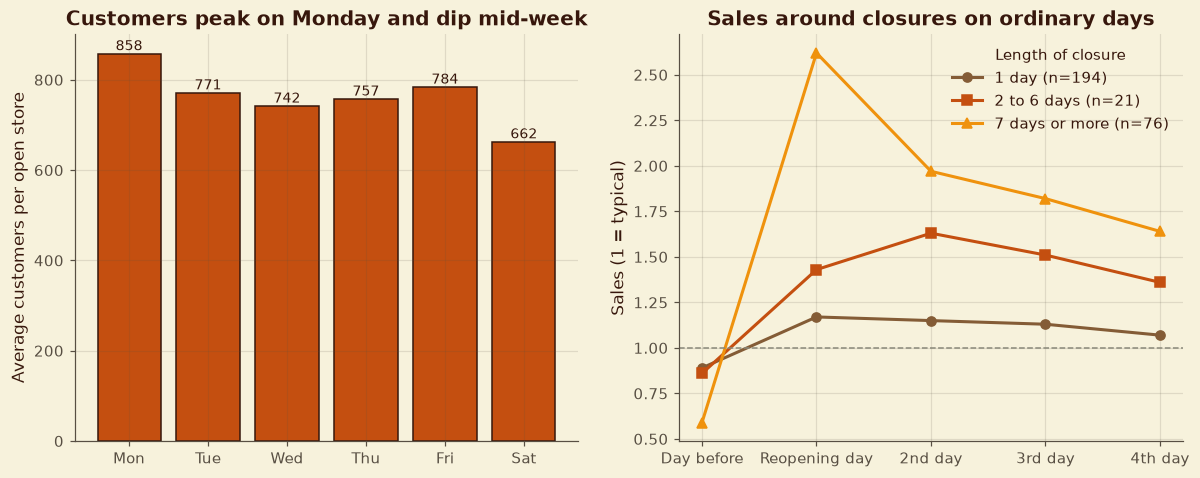

In [43]:
rhythm = open_days.groupby("DayOfWeek").agg(avg_customers=("Customers", "mean"), avg_sales=("Sales", "mean"))
rhythm["sales_per_customer"] = open_days.groupby("DayOfWeek")["Sales"].sum() / open_days.groupby("DayOfWeek")["Customers"].sum()
rhythm["stores_open_%"] = eda.groupby("DayOfWeek")["Open"].mean() * 100
rhythm.index = rhythm.index.map(WEEKDAY)
style.show_table(rhythm.round(1), 5, "The weekly rhythm: customers, sales and opening by weekday")

# closure spells on ordinary days (Sundays and state holidays do not break a spell)
elig = (eda.loc[~((eda["Open"] == 0) & ((eda["DayOfWeek"] == 7) | (eda["StateHoliday"] != "0"))), ["Store", "Date", "Open"]]
        .sort_values(["Store", "Date"]).reset_index(drop=True))
elig = elig.merge(open_days[["Store", "Date", "sales_index"]], on=["Store", "Date"], how="left")
elig["closed"] = (elig["Open"] == 0).astype(int)
elig["run"] = ((elig["closed"] != elig["closed"].shift()) | (elig["Store"] != elig["Store"].shift())).cumsum()
elig = elig.reset_index().rename(columns={"index": "pos"})
spells = (elig[elig["closed"] == 1].groupby("run")
          .agg(store=("Store", "first"), start_pos=("pos", "min"), end_pos=("pos", "max"), days=("pos", "size")))


def index_at(pos, store):
    pos = pos.clip(0, len(elig) - 1)
    same = elig.loc[pos, "Store"].values == store.values
    return np.where(same, elig.loc[pos, "sales_index"].values, np.nan)


spells["day_before_closure"] = index_at(spells["start_pos"] - 1, spells["store"])
for k in (1, 2, 3, 4):
    spells[f"day_{k}_after_reopening"] = index_at(spells["end_pos"] + k, spells["store"])
spells["length"] = pd.cut(spells["days"], [0, 1, 6, 10_000], labels=["1 day", "2 to 6 days", "7 days or more"])
reopen_cols = ["day_before_closure", "day_1_after_reopening", "day_2_after_reopening", "day_3_after_reopening", "day_4_after_reopening"]
reopening = spells.groupby("length", observed=True)[reopen_cols].mean().round(2)
reopening.insert(0, "closures", spells.groupby("length", observed=True).size())
reopening.columns = ["closures", "day before", "reopening day", "2nd day", "3rd day", "4th day"]
style.show_table(reopening, 5, "Sales (1 = typical for the store and weekday) around closures on ordinary days")

fig, axes = plt.subplots(1, 2, figsize=(13, 4.8))
wk = rhythm.loc[["Mon", "Tue", "Wed", "Thu", "Fri", "Sat"]]
axes[0].bar(wk.index, wk["avg_customers"], color=PALETTE["terracotta"], edgecolor=PALETTE["espresso"])
for i, v in enumerate(wk["avg_customers"]):
    axes[0].text(i, v + 8, f"{v:.0f}", ha="center", fontsize=9)
axes[0].set_ylabel("Average customers per open store")
axes[0].set_title("Customers peak on Monday and dip mid-week")
x_labels = ["Day before", "Reopening day", "2nd day", "3rd day", "4th day"]
line_style = {"1 day": ("o", PALETTE["clay"]), "2 to 6 days": ("s", PALETTE["terracotta"]), "7 days or more": ("^", PALETTE["marigold"])}
for name, row in reopening.iterrows():
    mk, col = line_style[name]
    axes[1].plot(x_labels, row.iloc[1:].values, marker=mk, color=col, linewidth=2, label=f"{name} (n={int(row['closures'])})")
axes[1].axhline(1, color=PALETTE["stone"], linestyle="--", linewidth=1)
axes[1].set_ylabel("Sales (1 = typical)")
axes[1].set_title("Sales around closures on ordinary days")
axes[1].legend(title="Length of closure")
style.save_figure(fig, 5, "Weekly rhythm and the effect of closures")
plt.show()

**Reading the result (Q7)**
- **What the evidence shows.** Customers peak on Monday (about 858 per open store) and are lowest on Saturday (663); sales follow the same shape (8,216 on Monday, 5,886 on Saturday). Around closures, sales **dip before** a long closure (0.59 of typical on the last open day before a closure of a week or more) and **rebound strongly afterwards** (2.6 times typical on the reopening day, still 1.6 times on the fourth day). Short closures show a smaller version (1.17 times on reopening).
- **What it means.** Closures matter for forecasting: demand is held back before a long closure and released after it, so features such as *days since reopening* are useful.
- **What the data cannot establish.** Opening and closing *times* and flows within a day cannot be studied with daily data. Rebound sizes depend on the typical-sales reference, which includes the pre-closure period.

## 5.9 Q8: Stores Open on All Weekdays and Their Weekend Sales

"All weekdays" is examined two ways: **Monday to Friday** (almost every store) and **all seven days** (stores that also trade on Sundays). The second group is small, so Sunday-trading stores are compared with similar stores (same store type) that close on Sundays.

**Table 5.19: Which stores are open on all weekdays?**

,stores
Stores open on at least 95% of ordinary Monday-to-Friday days,1109
Stores open on fewer than 90% of ordinary Monday-to-Friday days,5
Stores that ever open on a Sunday,33
...of which open on at least 90% of Sundays (open all seven days),16
Average share of Sundays open (Sunday-trading stores),81%


**Table 5.20: Stores that trade on Sundays (top 12 by share of Sundays open)**

,StoreType,Assortment,sunday_open_share,avg_sunday_sales
Store,,,,
85,b,a,100.0,11300.0
335,b,a,100.0,7835.0
682,b,a,100.0,7248.0
494,b,a,100.0,7851.0
733,b,b,100.0,15114.0
769,b,b,100.0,10280.0
423,b,a,100.0,13363.0
562,b,c,100.0,18922.0
262,b,a,100.0,28348.0


**Table 5.21: What kind of stores trade on Sundays?**

Sunday-trading stores  All stores
Store type a                     13         602
           b                     17          17
           c                      0         148
           d                      3         348
Assortment a                      8         593
           b                      9           9
           c                     16         513

**Table 5.22: Average sales by weekday: stores that trade on Sundays vs similar stores that do not**

,Mon,Tue,Wed,Thu,Fri,Sat,Sun,Saturday vs Mon-Fri average,Mon-Sat total per week,stores
Type b (all trade on Sundays),10911.87,10016.17,9864.29,10075.85,10560.61,7881.51,11235.08,0.77,59310.29,17
"Type a, trades on Sundays",7870.38,6997.47,6711.20,6687.48,6888.99,5800.18,2838.27,0.82,40955.71,13
"Type a, closed on Sundays",8328.97,7270.55,6823.86,6817.89,6991.14,5376.02,NaN,0.74,41608.43,589


Figure 5.8: Stores that trade on Sundays


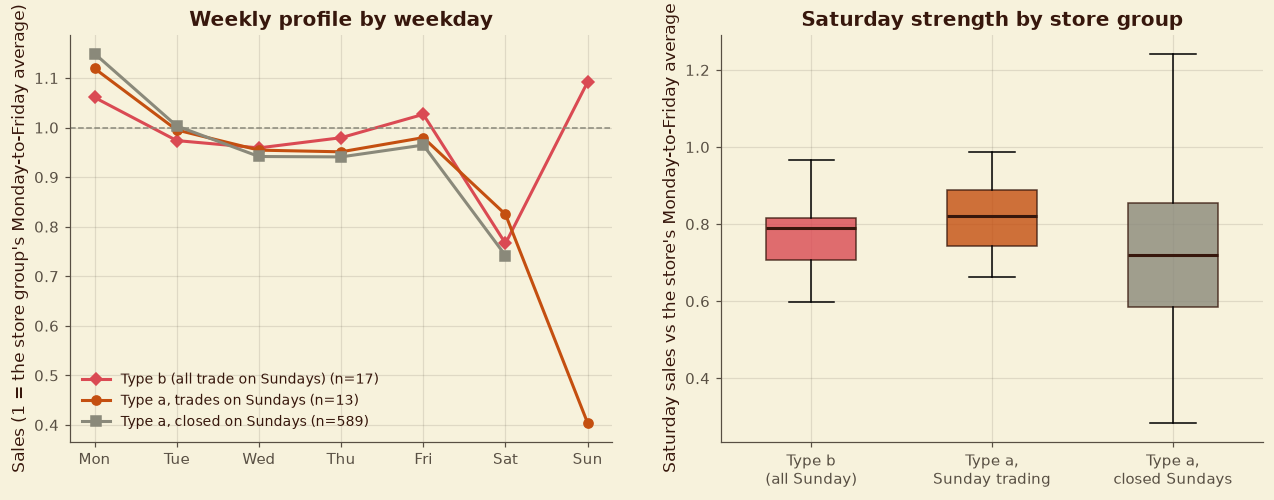

In [44]:
weekday_open = eda[(eda["DayOfWeek"] <= 5) & (eda["StateHoliday"] == "0")].groupby("Store")["Open"].mean()
sunday_rate = eda[eda["DayOfWeek"] == 7].groupby("Store")["Open"].mean()
sunday_stores = sunday_rate[sunday_rate > 0].index
open_every_day = sunday_rate[sunday_rate >= 0.9].index

open_summary = pd.Series({
    "Stores open on at least 95% of ordinary Monday-to-Friday days": int((weekday_open >= 0.95).sum()),
    "Stores open on fewer than 90% of ordinary Monday-to-Friday days": int((weekday_open < 0.90).sum()),
    "Stores that ever open on a Sunday": len(sunday_stores),
    "...of which open on at least 90% of Sundays (open all seven days)": len(open_every_day),
    "Average share of Sundays open (Sunday-trading stores)": f"{100 * sunday_rate[sunday_rate > 0].mean():.0f}%",
}, dtype=object).to_frame("stores")
style.show_table(open_summary, 5, "Which stores are open on all weekdays?")

all_week = (store_info.loc[sunday_stores, ["StoreType", "Assortment"]].assign(sunday_open_share=(100 * sunday_rate[sunday_stores]).round(0))
            .join(open_days[open_days["DayOfWeek"] == 7].groupby("Store")["Sales"].mean().round(0).rename("avg_sunday_sales"))
            .sort_values("sunday_open_share", ascending=False))
style.show_table(all_week.head(12), 5, "Stores that trade on Sundays (top 12 by share of Sundays open)")

comp = pd.DataFrame({"Sunday-trading stores": store_info.loc[sunday_stores, "StoreType"].value_counts(),
                     "All stores": store_info["StoreType"].value_counts()}).fillna(0).astype(int)
comp_assort = pd.DataFrame({"Sunday-trading stores": store_info.loc[sunday_stores, "Assortment"].value_counts(),
                            "All stores": store_info["Assortment"].value_counts()}).fillna(0).astype(int)
style.show_table(pd.concat({"Store type": comp, "Assortment": comp_assort}), 5, "What kind of stores trade on Sundays?")

# weekly profile: compare like with like (store type a stores, with and without Sunday trading) and type b (all trade Sundays)
profile_sales = open_days[open_days["DayOfWeek"] <= 7].groupby(["Store", "DayOfWeek"])["Sales"].mean().unstack()
groups = {
    "Type b (all trade on Sundays)": store_info.index[(store_info["StoreType"] == "b")],
    "Type a, trades on Sundays": store_info.index[(store_info["StoreType"] == "a") & store_info.index.isin(sunday_stores)],
    "Type a, closed on Sundays": store_info.index[(store_info["StoreType"] == "a") & ~store_info.index.isin(sunday_stores)],
}
weekly = {}
for name, idx in groups.items():
    p = profile_sales.reindex(idx)
    weekly[name] = p.mean()
weekly = pd.DataFrame(weekly).T
weekly.columns = [WEEKDAY[c] for c in weekly.columns]
weekly["Saturday vs Mon-Fri average"] = weekly["Sat"] / weekly[["Mon", "Tue", "Wed", "Thu", "Fri"]].mean(axis=1)
weekly["Mon-Sat total per week"] = weekly[["Mon", "Tue", "Wed", "Thu", "Fri", "Sat"]].sum(axis=1)
weekly["stores"] = [len(i) for i in groups.values()]
style.show_table(weekly.round(2), 5, "Average sales by weekday: stores that trade on Sundays vs similar stores that do not")

fig, axes = plt.subplots(1, 2, figsize=(14, 4.8))
line_style = {"Type b (all trade on Sundays)": ("D", PALETTE["rose"]), "Type a, trades on Sundays": ("o", PALETTE["terracotta"]),
              "Type a, closed on Sundays": ("s", PALETTE["stone"])}
for name, row in weekly.iterrows():
    days = [d for d in WEEKDAY.values() if pd.notna(row[d])]
    base = row[["Mon", "Tue", "Wed", "Thu", "Fri"]].mean()
    mk, col = line_style[name]
    axes[0].plot(days, [row[d] / base for d in days], marker=mk, color=col, linewidth=2, label=f"{name} (n={int(row['stores'])})")
axes[0].axhline(1, color=PALETTE["stone"], linestyle="--", linewidth=1)
axes[0].set_ylabel("Sales (1 = the store group's Monday-to-Friday average)")
axes[0].set_title("Weekly profile by weekday")
axes[0].legend(fontsize=9)
sat_ratio = profile_sales[6] / profile_sales[[1, 2, 3, 4, 5]].mean(axis=1)          # columns are weekday numbers (6 = Saturday)
for i, (name, idx) in enumerate(groups.items()):
    vals = sat_ratio.reindex(idx).dropna()
    bp = axes[1].boxplot(vals, positions=[i], widths=0.5, patch_artist=True, showfliers=False)
    for patch in bp["boxes"]:
        patch.set(facecolor=line_style[name][1], alpha=0.8, edgecolor=PALETTE["espresso"])
    for item in bp["medians"]:
        item.set(color=PALETTE["espresso"], linewidth=2)
axes[1].set_xticks(range(len(groups)))
axes[1].set_xticklabels(["Type b\n(all Sunday)", "Type a,\nSunday trading", "Type a,\nclosed Sundays"])
axes[1].set_ylabel("Saturday sales vs the store's Monday-to-Friday average")
axes[1].set_title("Saturday strength by store group")
style.save_figure(fig, 5, "Stores that trade on Sundays")
plt.show()

**Reading the result (Q8)**
- **What the evidence shows.** 1,109 of 1,115 stores are open on at least 95% of ordinary Monday-to-Friday days (5 stores fall below 90%: the long closures found in Section 3). Only **33 stores ever trade on Sundays**, on average 81% of Sundays, and 16 are open on at least 90% of Sundays. They are not random: **all 17 type b stores and all 9 assortment-b stores trade on Sundays**, plus 13 type a and 3 type d stores.
- **Weekend effect.** Among type a stores, those that trade on Sundays keep their Saturday sales (Saturday is 0.82 of a weekday, against 0.74 for stores that close on Sundays), and their Monday-to-Saturday total is within about 2% of similar stores that close. So Sunday sales (about 2,840 on an open Sunday) look like additional sales, not a transfer from Saturday.
- **What it means.** Sunday trading is rare and tied to store type, and it does not appear to take sales from Saturday.
- **What the data cannot establish.** Only 13 comparable type a stores trade on Sundays, and Sunday trading was not assigned at random, so it cannot be called the cause of any difference.

## 5.10 Q9: Assortment Type and Sales

Assortment (a basic, b extra, c extended) is compared using store-level averages, so each store counts once. Because assortment and store type are tangled together, the comparison is repeated *within* each store type.

**Table 5.23: Sales, customers and spend per customer by assortment (store averages)**

,stores,avg_sales,median_sales,avg_customers,sales_per_customer
Assortment,,,,,
a (basic),593,6602.1,6263.2,742.7,9.3
b (extra),9,8503.4,7605.0,2032.9,4.2
c (extended),513,7287.0,6909.3,748.5,10.1


**Table 5.24: Number of stores by store type and assortment**

Assortment,a,b,c
StoreType,,,
a,381,0,221
b,7,9,1
c,77,0,71
d,128,0,220


**Table 5.25: Median store sales within each store type and assortment**

stores  median_sales  median_customers
StoreType Assortment                                        
a         a              381        6045.0             691.0
          c              221        7140.0             764.0
b         a                7       10772.0            1759.0
          b                9        7605.0            1695.0
          c                1       18001.0            3109.0
c         a               77        6759.0             805.0
          c               71        6269.0             730.0
d         a              128        6314.0             561.0
          c              220        6857.0             602.0

Figure 5.9: Assortment and store sales


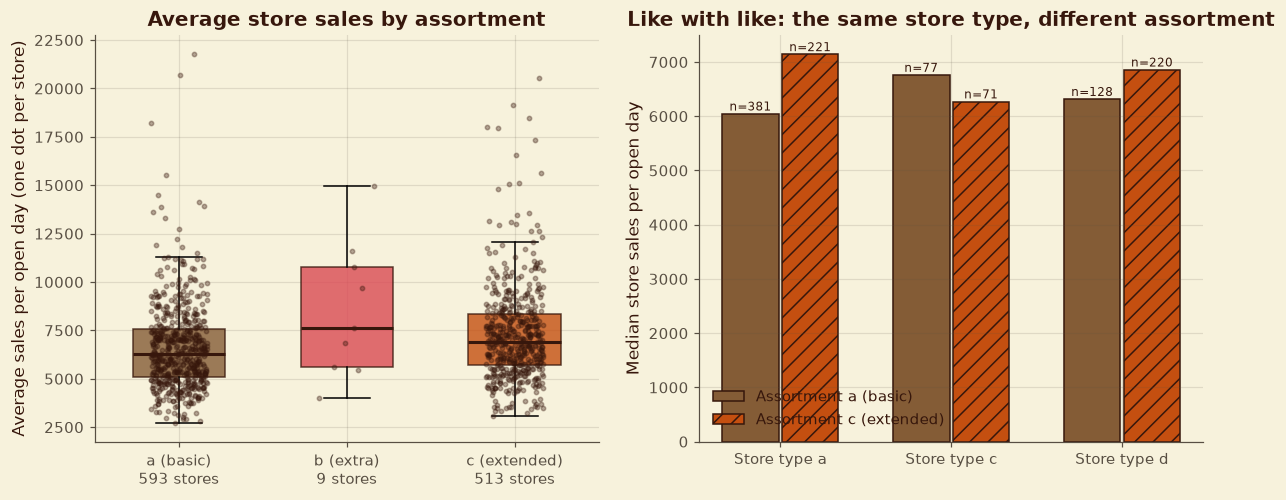

In [45]:
store_level = (open_days.groupby("Store").agg(avg_sales=("Sales", "mean"), avg_customers=("Customers", "mean"),
                                              sales_total=("Sales", "sum"), customers_total=("Customers", "sum"))
               .join(store_info[["StoreType", "Assortment", "CompetitionDistance", "CompetitionDistance_missing"]]))
store_level["sales_per_customer"] = store_level["sales_total"] / store_level["customers_total"]

assort = store_level.groupby("Assortment").agg(stores=("avg_sales", "size"), avg_sales=("avg_sales", "mean"), median_sales=("avg_sales", "median"),
                                                avg_customers=("avg_customers", "mean"), sales_per_customer=("sales_per_customer", "mean"))
assort.index = assort.index.map({"a": "a (basic)", "b": "b (extra)", "c": "c (extended)"})
style.show_table(assort.round(1), 5, "Sales, customers and spend per customer by assortment (store averages)")

mix = pd.crosstab(store_level["StoreType"], store_level["Assortment"])
style.show_table(mix, 5, "Number of stores by store type and assortment")

within_type = (store_level.groupby(["StoreType", "Assortment"]).agg(stores=("avg_sales", "size"), median_sales=("avg_sales", "median"),
                                                                     median_customers=("avg_customers", "median")).round(0))
style.show_table(within_type, 5, "Median store sales within each store type and assortment")

fig, axes = plt.subplots(1, 2, figsize=(13, 4.8))
order_a = ["a", "b", "c"]
rng = np.random.default_rng(config.SEED)
for i, a in enumerate(order_a):
    vals = store_level.loc[store_level["Assortment"] == a, "avg_sales"]
    bp = axes[0].boxplot(vals, positions=[i], widths=0.55, patch_artist=True, showfliers=False)
    for patch in bp["boxes"]:
        patch.set(facecolor=[PALETTE["clay"], PALETTE["rose"], PALETTE["terracotta"]][i], alpha=0.8, edgecolor=PALETTE["espresso"])
    for item in bp["medians"]:
        item.set(color=PALETTE["espresso"], linewidth=2)
    axes[0].scatter(i + rng.uniform(-0.17, 0.17, len(vals)), vals, s=8, color=PALETTE["espresso"], alpha=0.35, zorder=3)
axes[0].set_xticks(range(3))
axes[0].set_xticklabels([f"a (basic)\n{int((store_level['Assortment'] == 'a').sum())} stores", f"b (extra)\n{int((store_level['Assortment'] == 'b').sum())} stores",
                         f"c (extended)\n{int((store_level['Assortment'] == 'c').sum())} stores"])
axes[0].set_ylabel("Average sales per open day (one dot per store)")
axes[0].set_title("Average store sales by assortment")

types = ["a", "c", "d"]
width = 0.25
for j, a in enumerate(["a", "c"]):
    vals = [within_type.loc[(t, a), "median_sales"] if (t, a) in within_type.index else np.nan for t in types]
    ns = [int(within_type.loc[(t, a), "stores"]) if (t, a) in within_type.index else 0 for t in types]
    bars = axes[1].bar(np.arange(3) + (j - 0.5) * 0.35, vals, width=0.33, color=[PALETTE["clay"], PALETTE["terracotta"]][j],
                       hatch=["", "//"][j], edgecolor=PALETTE["espresso"], label=f"Assortment {a} ({'basic' if a == 'a' else 'extended'})")
    for b_, n_ in zip(bars, ns):
        if n_:
            axes[1].text(b_.get_x() + b_.get_width() / 2, b_.get_height() + 60, f"n={n_}", ha="center", fontsize=8)
axes[1].set_xticks(range(3))
axes[1].set_xticklabels([f"Store type {t}" for t in types])
axes[1].set_ylabel("Median store sales per open day")
axes[1].set_title("Like with like: the same store type, different assortment")
axes[1].legend()
style.save_figure(fig, 5, "Assortment and store sales")
plt.show()

**Reading the result (Q9)**
- **What the evidence shows.** Average store sales per open day are 6,602 (basic), 8,503 (extra) and 7,287 (extended). But the picture changes inside each store type: extended assortment sells more in type a stores (median 7,140 vs 6,045, +18%) and type d stores (+9%), and **less** in type c stores (−7%).
- **What it means.** Assortment alone does not explain sales. Store type matters more, and the benefit of a bigger range depends on the type of store.
- **What the data cannot establish.** All 9 assortment-b stores are type b stores (the Sunday-trading, high-traffic, small-basket group), so the effect of "extra" assortment cannot be separated from store type.

## 5.11 Q10: Distance to the Nearest Competitor

Distance is shown in bands and as a rank correlation with store sales, overall and within store types. Three stores with no distance are left out.

There is **no location information**, so the "city centre" part of the question cannot be tested. Short competitor distances can only hint at dense areas.

**Table 5.26: Store performance by distance to the nearest competitor**

,stores,median_sales,avg_customers,sales_per_customer
band,,,,
under 500 m,220,7017.3,870.0,7.8
500 m to 1 km,110,5895.0,677.5,8.5
1 to 2 km,172,6666.0,663.2,9.1
2 to 5 km,261,6460.2,643.2,9.7
5 to 10 km,162,6590.2,582.3,11.0
over 10 km,187,6645.7,651.0,10.3


**Table 5.27: Rank correlation between competitor distance and store sales**

,stores,rank_correlation
group,,
All stores,1112,-0.03
Store type a,601,-0.09
Store type c,148,-0.01
Store type d,346,0.06


**Table 5.28: Median store sales by competitor distance and store type**

StoreType,a,b,c,d
band,,,,
under 500 m,7121.0,11408.0,6768.0,6365.0
500 m to 1 km,5868.0,9700.0,5402.0,6195.0
1 to 2 km,6307.0,7652.0,6861.0,6206.0
2 to 5 km,6107.0,3985.0,6607.0,6789.0
5 to 10 km,6411.0,NaN,5858.0,6707.0
over 10 km,6429.0,NaN,7995.0,6895.0


Figure 5.10: Competitor distance and store sales


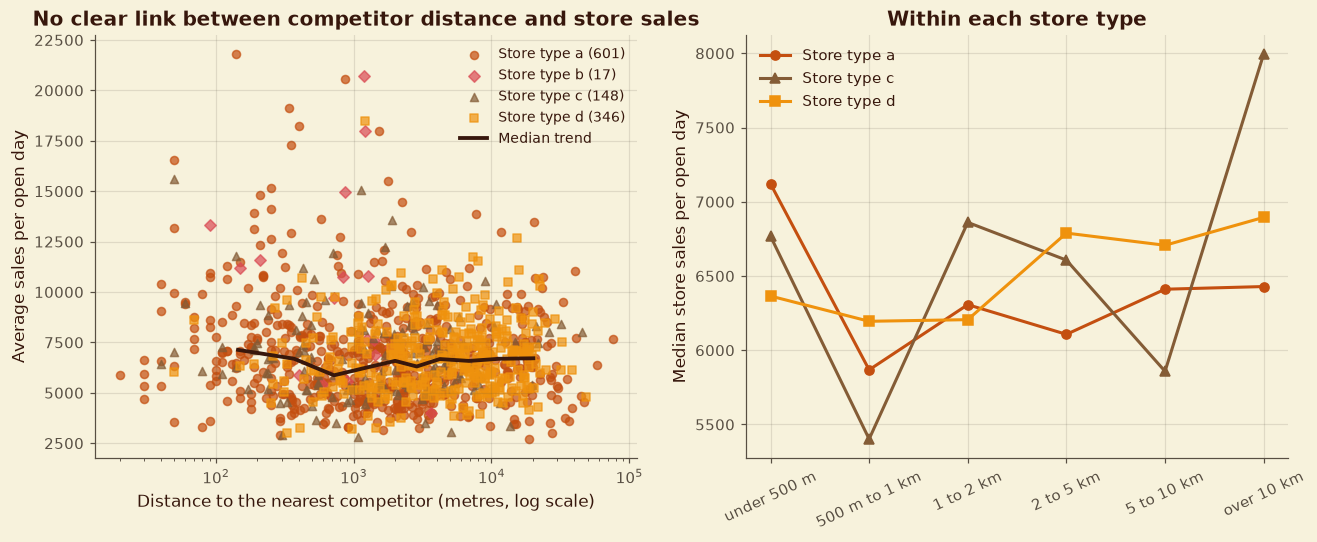

In [46]:
known = store_level[store_level["CompetitionDistance_missing"] == 0].copy()
band_labels = ["under 500 m", "500 m to 1 km", "1 to 2 km", "2 to 5 km", "5 to 10 km", "over 10 km"]
known["band"] = pd.cut(known["CompetitionDistance"], [0, 500, 1000, 2000, 5000, 10000, 1e7], labels=band_labels)
band_table = known.groupby("band", observed=True).agg(stores=("avg_sales", "size"), median_sales=("avg_sales", "median"),
                                                      avg_customers=("avg_customers", "median"), sales_per_customer=("sales_per_customer", "median")).round(1)
style.show_table(band_table, 5, "Store performance by distance to the nearest competitor")

rho_rows = [{"group": "All stores", "stores": len(known),
             "rank_correlation": known["avg_sales"].corr(np.log(known["CompetitionDistance"]), method="spearman")}]
for t in ["a", "c", "d"]:
    sub = known[known["StoreType"] == t]
    rho_rows.append({"group": f"Store type {t}", "stores": len(sub),
                     "rank_correlation": sub["avg_sales"].corr(np.log(sub["CompetitionDistance"]), method="spearman")})
rho_table = pd.DataFrame(rho_rows).set_index("group").round(2)
style.show_table(rho_table, 5, "Rank correlation between competitor distance and store sales")

type_band = known.pivot_table(index="band", columns="StoreType", values="avg_sales", aggfunc="median", observed=True).round(0)
style.show_table(type_band, 5, "Median store sales by competitor distance and store type")

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
for t, (mk, col) in type_style.items():
    sub = known[known["StoreType"] == t]
    axes[0].scatter(sub["CompetitionDistance"], sub["avg_sales"], marker=mk, color=col, s=28, alpha=0.7, label=f"Store type {t} ({len(sub)})")
qb = pd.qcut(known["CompetitionDistance"], 10, duplicates="drop")
trend = known.groupby(qb, observed=True).agg(x=("CompetitionDistance", "median"), y=("avg_sales", "median"))
axes[0].plot(trend["x"], trend["y"], color=PALETTE["espresso"], linewidth=2.5, label="Median trend")
axes[0].set_xscale("log")
axes[0].set_xlabel("Distance to the nearest competitor (metres, log scale)")
axes[0].set_ylabel("Average sales per open day")
axes[0].set_title("No clear link between competitor distance and store sales")
axes[0].legend(fontsize=9)
for t in ["a", "c", "d"]:
    mk, col = type_style[t]
    s = type_band[t].reindex(band_labels)
    axes[1].plot(band_labels, s.values, marker=mk, color=col, linewidth=2, label=f"Store type {t}")
axes[1].set_ylabel("Median store sales per open day")
axes[1].set_title("Within each store type")
axes[1].tick_params(axis="x", rotation=25)
axes[1].legend()
style.save_figure(fig, 5, "Competitor distance and store sales")
plt.show()

**Reading the result (Q10)**
- **What the evidence shows.** There is almost no relationship between competitor distance and store sales: the rank correlation is −0.03 overall (−0.09 for type a, −0.01 for type c, +0.06 for type d). Stores with a competitor under 500 m away have more customers (a median of 870, against 582 for 5 to 10 km) but smaller baskets (7.8 per customer against 11.0).
- **What it means.** Distance alone is a weak predictor of how much a store sells. Close competitors go with busy, low-basket stores, which is consistent with dense areas but is only a hint.
- **What the data cannot establish.** There is no location data, so whether the stores and their competitors are in **city centres**, and whether distance matters there, cannot be tested.

## 5.12 Q11: Opening of New Competitors

`store.csv` gives the month a competitor opened. For stores whose competitor opened **during** the data, we compare each store's sales in the 3 months after the opening with the 3 months before, **relative to similar stores whose competitor was already there before 2013** (this removes seasonality and chain-wide trends). A placebo test gives comparison stores a pretend opening to show how big a change chance alone produces.

Only stores with a complete history are used (the 180 stores with the 2014 gap are left out). The task also asks about stores whose competitor distance is missing but later becomes known. That **cannot be observed**: `store.csv` is a single snapshot with no time dimension. The three stores with no distance are listed instead.

Stores with a competitor opening inside the data (complete history, 3 months of data either side): 120; comparison stores (competitor already there before 2013): 475


**Table 5.29: What happens to a store when a competitor opens**

,value
Stores with a competitor opening in the data,120
Average sales change in the 3 months after opening (vs similar stores),-7.1%
Median change,-5.5%
Share of these stores whose sales fell relative to others,80%
"Range expected by chance (placebo openings, 95%)",-0.9% to 1.2%


**Table 5.30: Change in sales after a competitor opens, by distance of that competitor**

,stores,mean,median
group,,,
under 1 km,34,-13.9,-12.8
1 to 5 km,45,-9.2,-8.6
over 5 km,41,1.0,-0.9


**Table 5.31: Stores with no competitor distance (a single snapshot: no change over time can be seen)**

,StoreType,Assortment,avg_sales,median_for_same_type
Store,,,,
291,d,a,8037.0,6689.0
622,a,c,4310.0,6502.0
879,d,a,3742.0,6689.0


Figure 5.11: Competitor openings and store sales


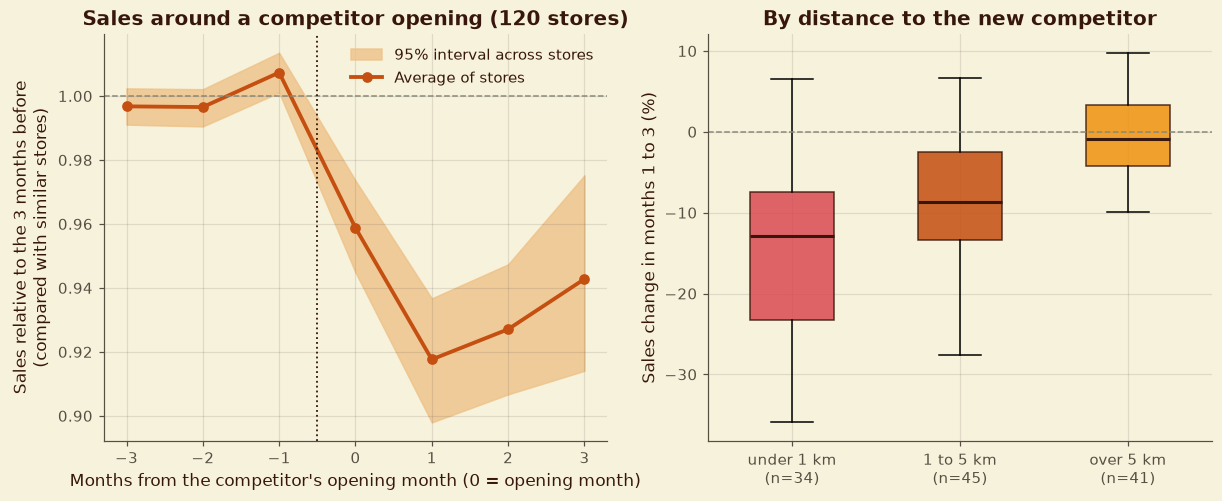

In [47]:
complete = store_info[store_info["has_history_gap"] == 0]
monthly_sales = open_days.assign(m=open_days["Date"].dt.to_period("M")).groupby(["Store", "m"])["Sales"].mean().unstack()
month_index = monthly_sales.columns
first_month, last_month = month_index.min(), pd.Period("2015-05", "M")             # the last month in the data is partial

opened = complete[(complete["CompetitionOpenDate_known"] == 1) & (complete["CompetitionOpenSince"] >= "2013-04-01")
                  & (complete["CompetitionOpenSince"] <= "2015-02-28")].index
controls = complete[(complete["CompetitionOpenDate_known"] == 1) & (complete["CompetitionOpenSince"] < "2013-01-01")].index
print(f"Stores with a competitor opening inside the data (complete history, 3 months of data either side): {len(opened)}; "
      f"comparison stores (competitor already there before 2013): {len(controls)}")

K = list(range(-3, 4))
ctrl_sales = monthly_sales.reindex(controls)


def ratios(frame, m0):
    """Sales in months m0+k divided by the store's own average of the three months before m0."""
    j = month_index.get_loc(m0)
    base = frame.iloc[:, j - 3:j].mean(axis=1)
    return pd.DataFrame({k: frame.iloc[:, j + k] / base for k in K})


ctrl_cache = {}
event_rows = []
for s in opened:
    m0 = store_info.loc[s, "CompetitionOpenSince"].to_period("M")
    if m0 not in ctrl_cache:
        ctrl_cache[m0] = ratios(ctrl_sales, m0).mean()
    own = ratios(monthly_sales.loc[[s]], m0).iloc[0]
    adj = own / ctrl_cache[m0]
    event_rows.append({"store": s, "opening_month": m0, **{f"k{k}": adj[k] for k in K}})
events = pd.DataFrame(event_rows).set_index("store")
events["distance"] = store_info.loc[events.index, "CompetitionDistance"]
events["post_change_%"] = 100 * (events[["k1", "k2", "k3"]].mean(axis=1) - 1)
events["group"] = pd.cut(events["distance"], [0, 1000, 5000, 1e7], labels=["under 1 km", "1 to 5 km", "over 5 km"])

rng = np.random.default_rng(config.SEED)
boot = lambda x: np.percentile([rng.choice(x, len(x)).mean() for _ in range(2000)], [2.5, 97.5])
curve = pd.DataFrame({"mean": [events[f"k{k}"].mean() for k in K],
                      "low": [boot(events[f"k{k}"].dropna().values)[0] for k in K],
                      "high": [boot(events[f"k{k}"].dropna().values)[1] for k in K]}, index=K)

# placebo: give comparison stores a pretend opening month and measure the same thing
placebo_means = []
pseudo_months = [store_info.loc[s, "CompetitionOpenSince"].to_period("M") for s in opened]
for rep in range(300):
    chosen = rng.choice(controls, len(opened), replace=True)
    vals = []
    for s, m0 in zip(chosen, rng.choice(pseudo_months, len(opened))):
        r = ratios(monthly_sales.loc[[s]], m0).iloc[0]
        vals.append(r[[1, 2, 3]].mean() / ctrl_cache.get(m0, ratios(ctrl_sales, m0).mean())[[1, 2, 3]].mean())
    placebo_means.append(np.nanmean(vals))
placebo_low, placebo_high = np.percentile(placebo_means, [2.5, 97.5])

summary = pd.Series({
    "Stores with a competitor opening in the data": len(opened),
    "Average sales change in the 3 months after opening (vs similar stores)": f"{events['post_change_%'].mean():.1f}%",
    "Median change": f"{events['post_change_%'].median():.1f}%",
    "Share of these stores whose sales fell relative to others": f"{100 * (events['post_change_%'] < 0).mean():.0f}%",
    "Range expected by chance (placebo openings, 95%)": f"{100 * (placebo_low - 1):.1f}% to {100 * (placebo_high - 1):.1f}%",
}, dtype=object).to_frame("value")
style.show_table(summary, 5, "What happens to a store when a competitor opens")

by_group = events.groupby("group", observed=True)["post_change_%"].agg(stores="size", mean="mean", median="median").round(1)
style.show_table(by_group, 5, "Change in sales after a competitor opens, by distance of that competitor")

# stores with no competitor distance
no_distance = store_level[store_level["CompetitionDistance_missing"] == 1][["StoreType", "Assortment", "avg_sales"]].round(0)
no_distance["median_for_same_type"] = no_distance["StoreType"].map(store_level.groupby("StoreType")["avg_sales"].median().round(0))
style.show_table(no_distance, 5, "Stores with no competitor distance (a single snapshot: no change over time can be seen)")

fig, axes = plt.subplots(1, 2, figsize=(13, 4.8))
axes[0].fill_between(K, curve["low"], curve["high"], color=PALETTE["sand"], alpha=0.8, label="95% interval across stores")
axes[0].plot(K, curve["mean"], marker="o", color=PALETTE["terracotta"], linewidth=2.5, label="Average of stores")
axes[0].axhline(1, color=PALETTE["stone"], linestyle="--", linewidth=1)
axes[0].axvline(-0.5, color=PALETTE["espresso"], linestyle=":", linewidth=1.2)
axes[0].set_xlabel("Months from the competitor's opening month (0 = opening month)")
axes[0].set_ylabel("Sales relative to the 3 months before\n(compared with similar stores)")
axes[0].set_title(f"Sales around a competitor opening ({len(opened)} stores)")
axes[0].legend()
groups_order = ["under 1 km", "1 to 5 km", "over 5 km"]
for i, g_ in enumerate(groups_order):
    vals = events.loc[events["group"] == g_, "post_change_%"].dropna()
    bp = axes[1].boxplot(vals, positions=[i], widths=0.5, patch_artist=True, showfliers=False)
    for patch in bp["boxes"]:
        patch.set(facecolor=[PALETTE["rose"], PALETTE["terracotta"], PALETTE["marigold"]][i], alpha=0.85, edgecolor=PALETTE["espresso"])
    for item in bp["medians"]:
        item.set(color=PALETTE["espresso"], linewidth=2)
axes[1].axhline(0, color=PALETTE["stone"], linestyle="--", linewidth=1)
axes[1].set_xticks(range(3))
axes[1].set_xticklabels([f"{g_}\n(n={int((events['group'] == g_).sum())})" for g_ in groups_order])
axes[1].set_ylabel("Sales change in months 1 to 3 (%)")
axes[1].set_title("By distance to the new competitor")
style.save_figure(fig, 5, "Competitor openings and store sales")
plt.show()

**Reading the result (Q11)**
- **What the evidence shows.** For the 120 stores with a competitor opening in the data, sales fall by **7.1% on average** (median 5.5%) in the 3 months after the opening, relative to similar stores, and 80% of these stores fell. Chance alone would produce a change of only about −0.9% to +1.2% (placebo test), so the fall is real in the statistical sense. The fall depends on distance: **−13.9% for competitors under 1 km**, −9.2% for 1 to 5 km and about zero (+1.0%) beyond 5 km. Sales partly recover by month 3 (Figure 5.11).
- **What it means.** A new nearby competitor costs a store roughly a tenth of its sales for a while. The competitor's opening date and distance are valuable features, and stores with a competitor opening inside the forecast window are at risk (three stores have one in August 2015).
- **What the data cannot establish.** Opening dates are only accurate to the month, and 356 stores have no usable opening date. Distances that change from missing to known cannot be seen in a single snapshot. The three stores with no distance sell 3,742 to 8,037 per day, so they show no common pattern.

## 5.13 Summary of Findings

All findings are collected below in one table: what the evidence shows, what it means for the business, and what the data cannot establish. The numbers are calculated from the analyses above.

In [48]:
sunday_trading_total = (
    float(weekly.loc["Type a, trades on Sundays", "Mon-Sat total per week"])
    / float(weekly.loc["Type a, closed on Sundays", "Mon-Sat total per week"])
    - 1
)
chance_range = f"{100 * (float(placebo_low) - 1):.1f}% to {100 * (float(placebo_high) - 1):.1f}%"
insights = pd.DataFrame([
    ("Q1  Are train and test distributed alike?",
     f"Promotions follow one chain-wide calendar (stores disagree on {promo_differs_train} of {eda['Date'].nunique()} dates), Monday to Friday only, in alternating weeks. Promotion share is similar in the same season (39.6% in test and in 2014). School holidays are 44% of test days vs 23% across train, but 43% in the same season of 2014.",
     "The test window is a summer window: promotion rhythm is familiar, school-holiday exposure is much higher than in most of the training period.",
     "Whether the 2015 summer behaves like earlier summers (only 2013 and part of 2014 exist)."),
    ("Q2  Sales before, during and after holidays",
     "Stores are almost all closed on state holidays (about 2% open). Open stores sell about 40% more than a normal day in the 3 days before Easter and 19% more before Christmas; the 3 days after Easter sell 12% less. School holidays show no consistent change on ordinary days.",
     "Holiday weeks need their own features: a run-up uplift before, a closure on the day, and a lull after Easter.",
     "Holiday effects rest on only 3 Easters, 2 Christmases and 14 national holidays; regional holidays were excluded."),
    ("Q3  Seasonal (Christmas, Easter) behaviour",
     f"December is the peak (about {monthly[2013].loc[12]:.2f} times a normal day in both years). The 15 to 23 December run-up averages {seasonal_table.loc['Christmas run-up (15 to 23 Dec)', 'relative_sales']:.2f}, but 24 December falls to {seasonal_table.loc['24 December', 'relative_sales']:.2f}. January is the low point ({seasonal_table.loc['January (after the holidays)', 'relative_sales']:.2f}). Spring 2015 runs above spring 2013 and 2014.",
     "Sales are strongly seasonal and the pattern repeats year to year, so calendar features should carry most of it.",
     "Only two full years: a different 2015 pattern cannot be ruled out."),
    ("Q4  Sales and customers",
     f"Correlation {r_all:.2f} across all open days (customers explain {100 * r_all ** 2:.0f}% of the variation) and {within.median():.2f} inside a typical store. Spend per customer ranges from {by_type['sales_per_customer'].min():.1f} (type b) to {by_type['sales_per_customer'].max():.1f} (type d).",
     "Customers are the main driver of sales, but customers are not available in the test period, so the model must predict sales without them.",
     "Correlation does not show that more customers cause more sales, and customers cannot be split into new and returning."),
    ("Q5  How promotions affect sales and customers",
     f"On ordinary Monday-to-Friday days, promotions raise sales by {change['sales']:.0f}%, customers by {change['customers']:.0f}% and spend per customer by {change['sales_per_customer']:.0f}%. Every store gains (median {lift_sales.median():.0f}%, range {lift_sales.min():.0f}% to {lift_sales.max():.0f}%). Saturdays after promotion weeks are {saturday_gap:.0f}% busier, not quieter.",
     "Promotions bring both more shoppers and bigger baskets, with no sign of a hangover in the following days.",
     "Not causal (promotions were not randomised), and the data cannot separate existing customers from new ones."),
    ("Q6  Where promotions could be deployed more effectively",
     f"Every store follows the same calendar, so differences come from response. Lift is lowest for type b ({targeting.loc[('Store type', 'b'), 'median_lift_pct']:.0f}%) and assortment b ({targeting.loc[('Assortment', 'b'), 'median_lift_pct']:.0f}%) stores; larger stores gain less in percent ({targeting.loc[('Store size', 'Largest 25% of stores'), 'median_lift_pct']:.0f}% vs {targeting.loc[('Store size', 'Smallest 25% of stores'), 'median_lift_pct']:.0f}%) but more in money ({targeting.loc[('Store size', 'Largest 25% of stores'), 'median_extra_sales']:,.0f} vs {targeting.loc[('Store size', 'Smallest 25% of stores'), 'median_extra_sales']:,.0f} extra sales a promotion day). Lift is strongest on Mondays (+{promo_by_day.loc['Mon', 'sales_lift_%']:.0f}%) and weakest on Fridays (+{promo_by_day.loc['Fri', 'sales_lift_%']:.0f}%).",
     "If promotions cost money or can be targeted, the weakest responders (type b, assortment b) are the first to review; the strongest are small and mid-sized stores.",
     "Without promotion costs or margins, profitability cannot be judged; no store ever ran a different promotion calendar to compare."),
    ("Q7  Customer behaviour around opening and closing",
     f"Customers peak on Monday ({rhythm.loc['Mon', 'avg_customers']:.0f}) and are lowest on Saturday ({rhythm.loc['Sat', 'avg_customers']:.0f}). After a closure of a week or more, sales on the reopening day are {reopening.loc['7 days or more', 'reopening day']:.1f} times typical; before such a closure they run at {reopening.loc['7 days or more', 'day before']:.2f}.",
     "Closures matter for forecasting: sales dip before a long closure and rebound afterwards, so days since reopening is a useful feature.",
     "The data is daily: opening and closing hours and customer flow within a day cannot be studied."),
    ("Q8  Stores open on all weekdays and their weekend sales",
     f"{int((weekday_open >= 0.95).sum()):,} of 1,115 stores are open on at least 95% of ordinary Monday-to-Friday days. Only {len(sunday_stores)} stores trade on Sundays (all 17 type b stores and all 9 assortment-b stores). Among type a stores, Sunday traders keep their Saturday sales (Saturday = {weekly.loc['Type a, trades on Sundays', 'Saturday vs Mon-Fri average']:.2f} of a weekday vs {weekly.loc['Type a, closed on Sundays', 'Saturday vs Mon-Fri average']:.2f}) and their Monday-to-Saturday total is within {abs(100 * sunday_trading_total):.0f}% of similar stores that close on Sundays, so Sunday sales look largely additional.",
     "Sunday trading does not appear to take sales from Saturday, but it is rare and tied to store type.",
     "Only 13 comparable stores; Sunday trading is not randomly assigned, so it cannot be called the cause."),
    ("Q9  Assortment type and sales",
     f"Average store sales per day: a {assort.loc['a (basic)', 'avg_sales']:,.0f}, b {assort.loc['b (extra)', 'avg_sales']:,.0f}, c {assort.loc['c (extended)', 'avg_sales']:,.0f}. Like with like, extended assortment sells more in type a (+{100 * (within_type.loc[('a', 'c'), 'median_sales'] / within_type.loc[('a', 'a'), 'median_sales'] - 1):.0f}%) and type d (+{100 * (within_type.loc[('d', 'c'), 'median_sales'] / within_type.loc[('d', 'a'), 'median_sales'] - 1):.0f}%), but less in type c ({100 * (within_type.loc[('c', 'c'), 'median_sales'] / within_type.loc[('c', 'a'), 'median_sales'] - 1):.0f}%).",
     "Assortment alone does not explain sales: store type matters more, and the effect of a bigger range depends on the store type.",
     "All 9 assortment-b stores are type b, so 'extra' assortment cannot be separated from store type."),
    ("Q10  Competitor distance",
     f"Little relationship: rank correlation {rho_table.loc['All stores', 'rank_correlation']:.2f} overall (type a {rho_table.loc['Store type a', 'rank_correlation']:.2f}, c {rho_table.loc['Store type c', 'rank_correlation']:.2f}, d {rho_table.loc['Store type d', 'rank_correlation']:.2f}). Stores with a competitor under 500 m have more customers ({band_table.loc['under 500 m', 'avg_customers']:.0f} vs {band_table.loc['5 to 10 km', 'avg_customers']:.0f}) but smaller baskets ({band_table.loc['under 500 m', 'sales_per_customer']:.1f} vs {band_table.loc['5 to 10 km', 'sales_per_customer']:.1f}).",
     "Distance to a competitor is a weak predictor of store sales on its own; it is more useful together with the date a competitor opened.",
     "There is no location information, so the city-centre question cannot be tested; short distances are only a hint of dense areas."),
    ("Q11  Competitor opening and reopening",
     f"For {len(opened)} stores with a competitor opening in the data, sales fall {abs(events['post_change_%'].mean()):.1f}% on average in the 3 months after opening (chance range {chance_range}); {100 * (events['post_change_%'] < 0).mean():.0f}% of stores fell. The fall is {abs(by_group.loc['under 1 km', 'mean']):.0f}% for competitors under 1 km, {abs(by_group.loc['1 to 5 km', 'mean']):.0f}% for 1 to 5 km and about zero beyond 5 km.",
     "A new nearby competitor costs a store roughly a tenth of its sales, partly recovered by month 3; competitor opening date and distance are valuable features.",
     "store.csv is a single snapshot, so a distance that changes from missing to known cannot be seen; 356 stores have no usable opening date; opening dates are only accurate to the month."),
], columns=["question", "what the evidence shows", "what it means for the business", "what the data cannot establish"])
style.show_table(insights.set_index("question"), 5, "Summary of findings for every question in the brief")
insights.to_csv(config.OUTPUTS_DIR / "eda_insights.csv", index=False)

**Table 5.32: Summary of findings for every question in the brief**

,what the evidence shows,what it means for the business,what the data cannot establish
question,,,
Q1 Are train and test distributed alike?,"Promotions follow one chain-wide calendar (stores disagree on 0 of 900 dates), Monday to Friday only, in alternating weeks. Promotion share is similar in the same season (39.6% in test and in 2014). School holidays are 44% of test days vs 23% across train, but 43% in the same season of 2014.","The test window is a summer window: promotion rhythm is familiar, school-holiday exposure is much higher than in most of the training period.",Whether the 2015 summer behaves like earlier summers (only 2013 and part of 2014 exist).
"Q2 Sales before, during and after holidays",Stores are almost all closed on state holidays (about 2% open). Open stores sell about 40% more than a normal day in the 3 days before Easter and 19% more before Christmas; the 3 days after Easter sell 12% less. School holidays show no consistent change on ordinary days.,"Holiday weeks need their own features: a run-up uplift before, a closure on the day, and a lull after Easter.","Holiday effects rest on only 3 Easters, 2 Christmases and 14 national holidays; regional holidays were excluded."
"Q3 Seasonal (Christmas, Easter) behaviour","December is the peak (about 1.22 times a normal day in both years). The 15 to 23 December run-up averages 1.49, but 24 December falls to 0.71. January is the low point (0.94). Spring 2015 runs above spring 2013 and 2014.","Sales are strongly seasonal and the pattern repeats year to year, so calendar features should carry most of it.",Only two full years: a different 2015 pattern cannot be ruled out.
Q4 Sales and customers,Correlation 0.83 across all open days (customers explain 68% of the variation) and 0.95 inside a typical store. Spend per customer ranges from 5.1 (type b) to 11.2 (type d).,"Customers are the main driver of sales, but customers are not available in the test period, so the model must predict sales without them.","Correlation does not show that more customers cause more sales, and customers cannot be split into new and returning."
Q5 How promotions affect sales and customers,"On ordinary Monday-to-Friday days, promotions raise sales by 39%, customers by 20% and spend per customer by 16%. Every store gains (median 39%, range 2% to 103%). Saturdays after promotion weeks are 3% busier, not quieter.","Promotions bring both more shoppers and bigger baskets, with no sign of a hangover in the following days.","Not causal (promotions were not randomised), and the data cannot separate existing customers from new ones."
Q6 Where promotions could be deployed more effectively,"Every store follows the same calendar, so differences come from response. Lift is lowest for type b (15%) and assortment b (12%) stores; larger stores gain less in percent (34% vs 43%) but more in money (2,845 vs 1,576 extra sales a promotion day). Lift is strongest on Mondays (+57%) and weakest on Fridays (+22%).","If promotions cost money or can be targeted, the weakest responders (type b, assortment b) are the first to review; the strongest are small and mid-sized stores.","Without promotion costs or margins, profitability cannot be judged; no store ever ran a different promotion calendar to compare."
Q7 Customer behaviour around opening and closing,"Customers peak on Monday (858) and are lowest on Saturday (662). After a closure of a week or more, sales on the reopening day are 2.6 times typical; before such a closure they run at 0.59.","Closures matter for forecasting: sales dip before a long closure and rebound afterwards, so days since reopening is a useful feature.",The data is daily: opening and closing hours and customer flow within a day cannot be studied.
Q8 Stores open on all weekdays and their weekend sales,"1,109 of 1,115 stores are open on at least 95% of ordinary Monday-to-Friday days. Only 33 stores trade on Sundays (all 17 type b stores and all 9 assortment-b stores). Among type a stores, Sunday tr

In [49]:
final_checks = pd.DataFrame([
    ("All analysis stays inside the development period (holdout untouched)",
     bool(eda["Date"].max() <= dev_end and open_days["Date"].max() <= dev_end)),
    ("All 11 questions in the brief have a finding, a meaning and a limit", len(insights) == 11 and bool(insights.notna().all().all())),
    ("At least 11 figures were saved for this section", len([f for f in style.figure_index if f["label"].startswith("Figure 5.")]) >= 11),
    ("The promotion calendar check found no store-level differences", promo_differs_train == 0 and promo_differs_test == 0),
    ("Competitor opening effect lies outside the placebo range",
     bool(events["post_change_%"].mean() / 100 + 1 < placebo_low)),
], columns=["check", "passed"])
style.show_table(final_checks.set_index("check"), 5, "Section 5 completion checks", save=False)
assert final_checks["passed"].all(), "A Section 5 completion check failed"

**Table 5.33: Section 5 completion checks**

,passed
check,
All analysis stays inside the development period (holdout untouched),True
"All 11 questions in the brief have a finding, a meaning and a limit",True
At least 11 figures were saved for this section,True
The promotion calendar check found no store-level differences,True
Competitor opening effect lies outside the placebo range,True


In [50]:
log_decision(5, "All exploration uses only the development period (up to the day before the final holdout).",
             "Keeps the locked holdout unseen, even in aggregate figures.")
log_decision(5, "Comparisons use a 'sales index' (a day's sales divided by the store's typical sales on that weekday) and 'ordinary days' (no state holiday); promotion effects compare Monday-to-Friday days only.",
             "Makes big and small stores comparable and removes weekday and holiday mix as an explanation.")
log_decision(5, "Promotion effects are reported as associations on a chain-wide alternating-week calendar; competitor-opening effects use stores with complete history, comparison stores and a placebo test.",
             "No experiment exists, so claims stay descriptive.")
log_decision(5, "Q7 (opening and closing times), the city-centre part of Q10 and the 'missing distance becomes known' part of Q11 are reported as not answerable from the supplied data.",
             "The data has no hourly detail, no location and no time dimension in store.csv.")
log_decision(5, "Candidate features carried to Section 6: weekday x promotion, promotion-week position, days to and from Easter, Christmas and national holidays, school holidays, December run-up, 24 December, days since reopening after a closure, Sunday-trading flag, store type, assortment, competitor distance bands, months since a competitor opened and its distance.",
             "Each is supported by a finding in this section; Customers cannot be used (not available in test).",
             status="Provisional (built and tested in Section 6)")

log_limitation(5, "All stores share one promotion calendar, so promotion effects come from timing (alternating weeks) and are not experimental.",
               "Lift figures are associations; they could partly reflect other weekly patterns.")
log_limitation(5, "Customers cannot be split into existing and new customers.",
               "The effect of promotions on existing customers is only visible indirectly (customers, spend per customer, following days).")
log_limitation(5, "Holiday effects rest on 3 Easters, 2 Christmases and 14 national holidays; regional holidays were not analysed.",
               "Holiday uplifts are averages over very few events.")
log_limitation(5, "Competitor-opening analysis covers 120 stores with complete history and a known opening month; dates are accurate only to the month.",
               "The size of the effect is approximate and may differ for stores excluded from the analysis.")
log_limitation(5, "Sunday trading is rare (33 stores) and tied to store type; only 13 type a stores allow a like-with-like comparison.",
               "The Sunday-trading findings are tentative.")
log_limitation(5, "The exploration excludes the final 42 days, so the most recent weeks are not shown.",
               "Patterns in the last weeks before the test window are not described here.")

save_registers()
style.save_index()
display(decision_register.tail(5))
display(limitations.tail(6))
logger.info("Section 5 complete: all questions answered, insights table saved.")

# commit the new outputs (the data has not changed, so no new DVC version is needed)
sh("git add -A")
sh('git commit -m "Section 5: exploration of customer purchasing behaviour"', check=False)

,id,section,decision,reason,status
34,D35,5,All exploration uses only the development period (up to the day before the final holdout).,"Keeps the locked holdout unseen, even in aggregate figures.",Confirmed
35,D36,5,Comparisons use a 'sales index' (a day's sales divided by the store's typical sales on that weekday) and 'ordinary days' (no state holiday); promotion effects compare Monday-to-Friday days only.,Makes big and small stores comparable and removes weekday and holiday mix as an explanation.,Confirmed
36,D37,5,"Promotion effects are reported as associations on a chain-wide alternating-week calendar; competitor-opening effects use stores with complete history, comparison stores and a placebo test.","No experiment exists, so claims stay descriptive.",Confirmed
37,D38,5,"Q7 (opening and closing times), the city-centre part of Q10 and the 'missing distance becomes known' part of Q11 are reported as not answerable from the supplied data.","The data has no hourly detail, no location and no time dimension in store.csv.",Confirmed
38,D39,5,"Candidate features carried to Section 6: weekday x promotion, promotion-week position, days to and from Easter, Christmas and national holidays, school holidays, December run-up, 24 December, days since reopening after a closure, Sunday-trading flag, store type, assortment, competitor distance bands, months since a competitor opened and its distance.",Each is supported by a finding in this section; Customers cannot be used (not available in test).,Provisional (built and tested in Section 6)


,id,section,limitation,effect_on_conclusions
18,L19,5,"All stores share one promotion calendar, so promotion effects come from timing (alternating weeks) and are not experimental.",Lift figures are associations; they could partly reflect other weekly patterns.
19,L20,5,Customers cannot be split into existing and new customers.,"The effect of promotions on existing customers is only visible indirectly (customers, spend per customer, following days)."
20,L21,5,"Holiday effects rest on 3 Easters, 2 Christmases and 14 national holidays; regional holidays were not analysed.",Holiday uplifts are averages over very few events.
21,L22,5,Competitor-opening analysis covers 120 stores with complete history and a known opening month; dates are accurate only to the month.,The size of the effect is approximate and may differ for stores excluded from the analysis.
22,L23,5,Sunday trading is rare (33 stores) and tied to store type; only 13 type a stores allow a like-with-like comparison.,The Sunday-trading findings are tentative.
23,L24,5,"The exploration excludes the final 42 days, so the most recent weeks are not shown.",Patterns in the last weeks before the test window are not described here.


2026-10-28 21:45:35 | INFO     | rossmann | Section 5 complete: all questions answered, insights table saved.
[main 35bcba0] Section 5: exploration of customer purchasing behaviour
 4 files changed, 55 insertions(+)


CompletedProcess(args='git commit -m "Section 5: exploration of customer purchasing behaviour"', returncode=0, stdout='[main 35bcba0] Section 5: exploration of customer purchasing behaviour\n 4 files changed, 55 insertions(+)\n', stderr='')

## 5.14 Section 5 Summary

**What the exploration found**
- **Calendar and holidays drive sales.** December is 1.22 times a normal day, the run-up to Christmas 1.49, and the week before Easter 1.19 and higher. State holidays close almost every store.
- **Promotions lift sales by 39%.** Customers rise 20% and spend per customer 16%. Every store gains, Mondays most (+57%) and Fridays least (+22%). Type b and assortment b stores gain least.
- **Stores differ more by type than by assortment or competitor distance.** Type b stores are high-traffic, small-basket and the only Sunday traders (with a few others).
- **A new competitor costs about 7% of sales** (14% if it is under 1 km away), well beyond chance.
- **Test conditions:** the promotion rhythm is familiar, but the test window sits in the summer school-holiday peak.
- **Not answerable:** opening and closing hours, city-centre effects, and distances that become known over time.

**What comes next**
- **Section 6** turns these findings into features and one reusable preprocessing pipeline, with a leakage check on every feature.

---

# Section 6: Feature Engineering and Preprocessing

**Purpose of this section:** Turn the findings of Sections 3 to 5 into model inputs, in a way that cannot leak future information. By the end there is one reusable feature pipeline, proof that it passes leakage tests, and the feature tables saved as the third data version.

**Rules followed**
- Every feature belongs to one availability class from Section 4: **known in advance**, **store details**, or **history up to the forecast origin**. Customers, sales on forecast days and the cleaning columns are never inputs.
- Training rows are built exactly like the real forecast: one cut-off day (the *origin*), planned inputs for the future days, history only up to the origin.
- The final holdout stays locked: the training table stops at the end of the development period.
- The same code builds features for training, validation, the real forecast and later the web app.

| Step | What it covers |
|---|---|
| 6.1 | The feature design and the evidence behind it |
| 6.2 | The feature catalogue and the known-in-advance features |
| 6.3 | Turning forecast origins into training rows |
| 6.4 | Leakage tests |
| 6.5 | Features for the real forecast (test window) |
| 6.6 | The preprocessing pipeline (fill, scale, encode) |
| 6.7 | Do history features help? (first MLflow runs) |
| 6.8 | Saving the features, decisions and DVC version 3 |

## 6.1 Feature Design

**The idea of a forecast origin.** A real forecast is made on one day (the origin) for the next weeks. At that moment we know all history up to the origin, plus the *planned* promotions, holidays and opening of the future days. Each training row therefore has three parts:

1. **Planned features of the target day** (weekday, promotion, holiday distance, closure timing...).
2. **Store details** (type, assortment, competitor, Promo2).
3. **History of the store up to the origin** (recent average sales, weekday profile, promotion response, sales a year earlier).

Rows are built from many past origins (every 28 days, plus the start of each validation window), each looking up to 48 days ahead. A day that is 20 days after its origin has the same kind of information as day 20 of the real forecast.

| Feature group | Examples | Evidence from the exploration (Section 5) |
|---|---|---|
| Calendar | weekday, month, week of year, start/middle/end of month, cycles, 24 and 31 December | Monday peak, December 1.22 times a normal day, 24 December at 0.71 |
| Holidays | days to and since national, Easter and Christmas holidays, school holiday | Easter run-up about 1.4 times normal, Christmas run-up about 1.5 |
| Promotions | promotion today, weekday together with promotion, promotion this week and last week | +39% sales, +57% on Monday against +22% on Friday, alternating weeks |
| Opening | days since a closure, days since a long closure ended, days until a long closure | Sales dip before and rebound after long closures |
| Competition and Promo2 | competitor distance, months since it opened, opened in the last 6 months, Promo2 active and its start month | About -7% after a competitor opens (-14% within 1 km) |
| Store details | store type, assortment, competitor distance | Store type matters more than assortment |
| History up to the origin | store averages (28 days, 91 days, all), customers and spend per customer, weekday averages, promotion lift, momentum, sales a year earlier | Stores differ in size and customers explain most sales (customers themselves are not available, but their history is) |

The feature code lives in `src/features.py`, so the notebook and the app run exactly the same logic.

In [51]:
%%writefile src/features.py
"""Feature engineering: known-future features, origin-based history features and the preprocessing pipeline.

Two kinds of information feed the model, and they are kept strictly apart:
  * known-future features: built from the date, the planned inputs (promotion, holidays, opening) and store details;
  * origin-history features: summaries of sales that only use days up to the forecast origin.
Nothing in this module ever reads the sales of a day after the origin to build a feature of that day.
"""
import numpy as np
import pandas as pd
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

from . import validation
from .logger import get_logger

logger = get_logger("rossmann.features")

FEATURE_HORIZON_DAYS = 48        # training rows look up to 48 days ahead (the test window is 48 days)
ORIGIN_SPACING_DAYS = 28         # a new forecast origin every four weeks (plus the validation origins)
MIN_HISTORY_DAYS = 91            # an origin needs at least 13 weeks of history before it
HOLIDAY_CAP = 30                 # distances to holidays beyond this are treated as "far away"
LAST_YEAR_LAG_DAYS = 364         # same weekday, one year earlier

ID_COLUMNS = ["Store", "Date", "DayOfWeek", "Open", "Sales", "Customers", "use_for_training", "is_test"]

# ----------------------------------------------------------------------------- feature catalogue
# (name, availability class, kind, description)
FEATURE_SPECS = [
    # calendar
    ("dow", "known_future", "numeric", "Weekday number (1 = Monday)"),
    ("is_weekend", "known_future", "binary", "Saturday or Sunday"),
    ("day_of_month", "known_future", "numeric", "Day of the month"),
    ("month", "known_future", "numeric", "Month number"),
    ("week_of_year", "known_future", "numeric", "ISO week of the year"),
    ("day_of_year", "known_future", "numeric", "Day of the year"),
    ("days_to_month_end", "known_future", "numeric", "Days left in the month"),
    ("month_part", "known_future", "categorical", "Beginning (1-10), middle (11-20) or end (21+) of the month"),
    ("dow_sin", "known_future", "numeric", "Weekday as a cycle (sine)"),
    ("dow_cos", "known_future", "numeric", "Weekday as a cycle (cosine)"),
    ("month_sin", "known_future", "numeric", "Month as a cycle (sine)"),
    ("month_cos", "known_future", "numeric", "Month as a cycle (cosine)"),
    ("doy_sin", "known_future", "numeric", "Day of year as a cycle (sine)"),
    ("doy_cos", "known_future", "numeric", "Day of year as a cycle (cosine)"),
    ("is_christmas_eve", "known_future", "binary", "24 December"),
    ("is_new_years_eve", "known_future", "binary", "31 December"),
    # holidays
    ("state_holiday", "known_future", "categorical", "State holiday type for the store (0, a, b, c)"),
    ("school_holiday", "known_future", "binary", "School holiday affects the store"),
    ("days_to_holiday", "known_future", "numeric", "Days to the next national holiday (capped at 30)"),
    ("days_since_holiday", "known_future", "numeric", "Days since the last national holiday (capped at 30)"),
    ("days_to_easter", "known_future", "numeric", "Days to the next Easter holiday (capped at 30)"),
    ("days_since_easter", "known_future", "numeric", "Days since the last Easter holiday (capped at 30)"),
    ("days_to_christmas", "known_future", "numeric", "Days to the next Christmas holiday (capped at 30)"),
    ("days_since_christmas", "known_future", "numeric", "Days since the last Christmas holiday (capped at 30)"),
    # promotions
    ("promo", "known_future", "binary", "Promotion on this day"),
    ("promo_dow", "known_future", "categorical", "Promotion and weekday together (e.g. P1_D1)"),
    ("promo_week", "known_future", "binary", "Any promotion this calendar week"),
    ("promo_prev_week", "known_future", "binary", "Any promotion in the previous week"),
    # opening
    ("days_since_closure", "known_future", "numeric", "Days since the last closure on an ordinary day (capped at 14)"),
    ("days_since_long_closure", "known_future", "numeric", "Days since a closure of 7+ ordinary days ended (capped at 60)"),
    ("days_to_long_closure", "known_future", "numeric", "Days until a closure of 7+ ordinary days starts (capped at 30)"),
    ("days_since_gap_end", "known_future", "numeric", "Days since the store's long gap in its history ended (capped at 365)"),
    # competition and Promo2 (store details combined with the date)
    ("comp_open_months", "known_future", "numeric", "Months since the competitor opened (0 to 24; unknown date counted as 24)"),
    ("comp_not_yet_open", "known_future", "binary", "Competitor opens after this date"),
    ("comp_opened_last_6m", "known_future", "binary", "Competitor opened within the last 6 months"),
    ("comp_recent_near", "known_future", "binary", "Competitor under 1 km opened within the last 6 months"),
    ("promo2_active", "known_future", "binary", "Store is in Promo2 and its start date has passed"),
    ("promo2_weeks", "known_future", "numeric", "Weeks since Promo2 started (0 if not active, capped at 260)"),
    ("promo2_start_month", "known_future", "binary", "Promo2 round starts again this month"),
    ("horizon_day", "known_future", "numeric", "Days between the forecast origin and this day"),
    # store details
    ("store_type", "store_static", "categorical", "Store type (a, b, c, d)"),
    ("assortment", "store_static", "categorical", "Assortment level (a, b, c)"),
    ("competition_distance_log", "store_static", "numeric", "log(1 + distance to nearest competitor)"),
    ("competition_distance_missing", "store_static", "binary", "Distance was unknown (median used)"),
    ("promo2", "store_static", "binary", "Store takes part in Promo2"),
    ("promo_interval", "store_static", "categorical", "Months in which Promo2 rounds start"),
    ("has_history_gap", "store_static", "binary", "Store is missing a long block of history"),
    # history up to the forecast origin
    ("hist_mean_28", "origin_history", "numeric", "Store's average sales per open day, last 28 days before the origin"),
    ("hist_mean_91", "origin_history", "numeric", "Same, last 91 days"),
    ("hist_mean_all", "origin_history", "numeric", "Same, all history up to the origin"),
    ("hist_customers_91", "origin_history", "numeric", "Store's average customers per open day, last 91 days"),
    ("hist_spc_91", "origin_history", "numeric", "Sales per customer, last 91 days"),
    ("hist_days_91", "origin_history", "numeric", "Number of open days with sales in the last 91 days"),
    ("hist_promo_mean_91", "origin_history", "numeric", "Average sales on Monday-Friday promotion days, last 91 days"),
    ("hist_nopromo_mean_91", "origin_history", "numeric", "Average sales on Monday-Friday non-promotion days, last 91 days"),
    ("hist_promo_lift_all", "origin_history", "numeric", "Promotion vs non-promotion sales ratio, all history to the origin"),
    ("hist_momentum", "origin_history", "numeric", "Last 28 days divided by last 91 days"),
    ("hist_dow_mean_91", "origin_history", "numeric", "Store's average sales on this weekday, last 91 days"),
    ("hist_dow_mean_all", "origin_history", "numeric", "Store's average sales on this weekday, all history to the origin"),
    ("ly_sales_same_dow", "origin_history", "numeric", "Store's sales on the same weekday one year earlier"),
    ("ly_week_mean", "origin_history", "numeric", "Store's average sales in the 7 days around that date one year earlier"),
]
FEATURE_TABLE = pd.DataFrame(FEATURE_SPECS, columns=["feature", "class", "kind", "description"])

KNOWN_AND_STATIC = FEATURE_TABLE.loc[FEATURE_TABLE["class"].isin(["known_future", "store_static"]), "feature"].tolist()
ALL_FEATURES = FEATURE_TABLE["feature"].tolist()


def register_all():
    """Register every engineered feature with the availability policy (src/validation.py)."""
    for klass, names in FEATURE_TABLE.groupby("class")["feature"]:
        validation.register_features(list(names), klass)


def split_by_kind(features):
    """Group a list of feature names into numeric, binary and categorical lists."""
    kinds = FEATURE_TABLE.set_index("feature")["kind"]
    return {k: [f for f in features if kinds[f] == k] for k in ("numeric", "binary", "categorical")}


# ----------------------------------------------------------------------------- planning table
PLAN_COLUMNS = ["Store", "Date", "DayOfWeek", "Open", "Promo", "StateHoliday", "SchoolHoliday", "Sales", "Customers", "use_for_training",
                "StoreType", "Assortment", "CompetitionDistance", "CompetitionDistance_missing", "CompetitionOpenSince",
                "CompetitionOpenDate_known", "Promo2", "Promo2SinceWeek", "Promo2SinceYear", "PromoInterval", "has_history_gap"]


def make_plan(train, test):
    """One table with every store-day (train and test) and its planned inputs. Test rows have no sales."""
    tr = train.assign(is_test=0)
    te = test.assign(is_test=1)
    plan = pd.concat([tr[PLAN_COLUMNS + ["is_test"]], te[[c for c in PLAN_COLUMNS if c in te.columns] + ["is_test"]]], ignore_index=True)
    return plan.sort_values(["Store", "Date"]).reset_index(drop=True)


# ----------------------------------------------------------------------------- helpers
def holiday_calendar(plan, min_share=0.9):
    """Dates of holidays that apply to (almost) every store, from the StateHoliday flags in the data."""
    flagged = plan["StateHoliday"] != "0"
    share = flagged.groupby(plan["Date"]).mean()
    types = plan[flagged].groupby("Date")["StateHoliday"].agg(lambda s: s.mode().iloc[0])
    national = types[share.reindex(types.index) >= min_share]
    return {
        "any": national.index.sort_values(),
        "easter": national[national == "b"].index.sort_values(),
        "christmas": national[national == "c"].index.sort_values(),
    }


def _days_to_and_since(dates, events, cap):
    """For each date: days to the next event (0 on the day) and days since the previous event, both capped."""
    d = dates.values.astype("datetime64[D]").astype(np.int64)
    ev = events.values.astype("datetime64[D]").astype(np.int64)
    if len(ev) == 0:
        return np.full(len(d), cap), np.full(len(d), cap)
    nxt = np.searchsorted(ev, d, side="left")
    prv = nxt - 1
    to = np.where(nxt < len(ev), ev[np.minimum(nxt, len(ev) - 1)] - d, cap)
    since = np.where(prv >= 0, d - ev[np.maximum(prv, 0)], cap)
    return np.minimum(to, cap), np.minimum(since, cap)


def _asof_days(rows, events, event_col, direction, cap, exact):
    """Days from each row's date to the nearest event of the same store (backward = since, forward = until)."""
    left = rows[["Store", "Date"]].reset_index().sort_values("Date")
    right = events[["Store", event_col]].sort_values(event_col)
    merged = pd.merge_asof(left, right, left_on="Date", right_on=event_col, by="Store", direction=direction,
                           allow_exact_matches=exact)
    days = (merged["Date"] - merged[event_col]).dt.days.abs().fillna(cap).clip(upper=cap)
    return pd.Series(days.values, index=merged["index"].values).reindex(rows.index)


def find_gap_end(train):
    """Last missing day of each store's long gap (the day before its history resumes), or NaT."""
    d = train[["Store", "Date"]].sort_values(["Store", "Date"])
    step = d.groupby("Store")["Date"].diff().dt.days
    resumed = d[step >= 30]
    return (resumed["Date"] - pd.Timedelta(days=1)).groupby(resumed["Store"]).max()


_INTERVAL_MONTHS = {"Jan,Apr,Jul,Oct": [1, 4, 7, 10], "Feb,May,Aug,Nov": [2, 5, 8, 11], "Mar,Jun,Sept,Dec": [3, 6, 9, 12]}


# ----------------------------------------------------------------------------- known-future features
def add_known_future_features(plan, gap_end):
    """Features built from the date, planned inputs and store details only (never from sales)."""
    f = pd.DataFrame(index=plan.index)
    d = plan["Date"]

    # calendar
    f["dow"] = (d.dt.dayofweek + 1).astype("int8")
    f["is_weekend"] = (f["dow"] >= 6).astype("int8")
    f["day_of_month"] = d.dt.day.astype("int8")
    f["month"] = d.dt.month.astype("int8")
    f["week_of_year"] = d.dt.isocalendar().week.astype("int16").values
    f["day_of_year"] = d.dt.dayofyear.astype("int16")
    f["days_to_month_end"] = (d.dt.days_in_month - d.dt.day).astype("int8")
    f["month_part"] = np.select([f["day_of_month"] <= 10, f["day_of_month"] <= 20], ["start", "mid"], "end")
    for name, value, period in [("dow", f["dow"], 7), ("month", f["month"], 12), ("doy", f["day_of_year"], 365.25)]:
        f[f"{name}_sin"] = np.sin(2 * np.pi * value / period)
        f[f"{name}_cos"] = np.cos(2 * np.pi * value / period)
    f["is_christmas_eve"] = ((f["month"] == 12) & (f["day_of_month"] == 24)).astype("int8")
    f["is_new_years_eve"] = ((f["month"] == 12) & (f["day_of_month"] == 31)).astype("int8")

    # holidays (distances use only the holiday flags that appear in the data)
    f["state_holiday"] = plan["StateHoliday"].astype(str)
    f["school_holiday"] = plan["SchoolHoliday"].astype("int8")
    cal = holiday_calendar(plan)
    unique_dates = pd.Series(d.unique()).sort_values()
    for key, name in [("any", "holiday"), ("easter", "easter"), ("christmas", "christmas")]:
        to, since = _days_to_and_since(unique_dates, cal[key], HOLIDAY_CAP)
        f[f"days_to_{name}"] = d.map(pd.Series(to, index=unique_dates.values)).astype("int16")
        f[f"days_since_{name}"] = d.map(pd.Series(since, index=unique_dates.values)).astype("int16")

    # promotions
    f["promo"] = plan["Promo"].astype("int8")
    f["promo_dow"] = "P" + f["promo"].astype(str) + "_D" + f["dow"].astype(str)
    week = d - pd.to_timedelta(d.dt.dayofweek, unit="D")
    wk = pd.DataFrame({"Store": plan["Store"], "week": week, "promo": plan["Promo"]})
    wk_flag = wk.groupby(["Store", "week"])["promo"].max().rename("promo_week").reset_index()
    f["promo_week"] = wk.merge(wk_flag, on=["Store", "week"], how="left")["promo_week"].values.astype("int8")
    prev = wk_flag.assign(week=wk_flag["week"] + pd.Timedelta(days=7)).rename(columns={"promo_week": "promo_prev_week"})
    f["promo_prev_week"] = wk.merge(prev, on=["Store", "week"], how="left")["promo_prev_week"].fillna(0).values.astype("int8")

    # closures on ordinary days (Sundays and state holidays do not count as closures)
    keep = ~((plan["Open"] == 0) & ((plan["DayOfWeek"] == 7) | (plan["StateHoliday"] != "0")))
    e = plan.loc[keep, ["Store", "Date", "Open"]].reset_index(drop=True)
    e["closed"] = (e["Open"] == 0)
    run = ((e["closed"] != e["closed"].shift()) | (e["Store"] != e["Store"].shift())).cumsum()
    spells = (e[e["closed"]].groupby(run[e["closed"]])
              .agg(Store=("Store", "first"), start=("Date", "min"), end=("Date", "max"), days=("Date", "size")))
    long_spells = spells[spells["days"] >= 7]
    f["days_since_closure"] = _asof_days(plan, spells, "end", "backward", 14, False).astype("int16")
    f["days_since_long_closure"] = _asof_days(plan, long_spells, "end", "backward", 60, False).astype("int16")
    f["days_to_long_closure"] = _asof_days(plan, long_spells, "start", "forward", 30, True).astype("int16")
    gap = plan["Store"].map(gap_end)
    f["days_since_gap_end"] = np.where(gap.notna() & (d > gap), (d - gap).dt.days.clip(upper=365), 0).astype("int16")

    # competition
    months = (d - plan["CompetitionOpenSince"]).dt.days / 30.44
    known = plan["CompetitionOpenDate_known"] == 1
    f["comp_not_yet_open"] = (known & (months < 0)).astype("int8")
    f["comp_open_months"] = np.where(known, months.clip(0, 24), 24).astype("float32")
    f["comp_opened_last_6m"] = (known & (months >= 0) & (months < 6)).astype("int8")
    f["comp_recent_near"] = ((f["comp_opened_last_6m"] == 1) & (plan["CompetitionDistance"] < 1000)).astype("int8")

    # Promo2
    in_promo2 = plan["Promo2"] == 1
    starts = {}
    for s, y, w in plan.loc[in_promo2, ["Store", "Promo2SinceYear", "Promo2SinceWeek"]].drop_duplicates("Store").itertuples(index=False):
        starts[s] = pd.Timestamp.fromisocalendar(int(y), int(w), 1)
    start = plan["Store"].map(starts)
    active = in_promo2 & start.notna() & (d >= start)
    f["promo2_active"] = active.astype("int8")
    f["promo2_weeks"] = np.where(active, ((d - start).dt.days / 7).clip(0, 260), 0).astype("float32")
    starts_now = np.zeros(len(plan), dtype=bool)
    for interval, months_list in _INTERVAL_MONTHS.items():
        starts_now |= ((plan["PromoInterval"] == interval) & f["month"].isin(months_list)).values
    f["promo2_start_month"] = (active.values & starts_now).astype("int8")

    # store details
    f["store_type"] = plan["StoreType"].astype(str)
    f["assortment"] = plan["Assortment"].astype(str)
    f["competition_distance_log"] = np.log1p(plan["CompetitionDistance"]).astype("float32")
    f["competition_distance_missing"] = plan["CompetitionDistance_missing"].astype("int8")
    f["promo2"] = plan["Promo2"].astype("int8")
    f["promo_interval"] = plan["PromoInterval"].fillna("None").astype(str)      # "None" is read back as missing from the saved file
    f["has_history_gap"] = plan["has_history_gap"].astype("int8")

    out = pd.concat([plan[[c for c in ID_COLUMNS if c in plan.columns]], f], axis=1)
    logger.info(f"Known-future features built for {len(out):,} store-days.")
    return out


# ----------------------------------------------------------------------------- history features
def add_last_year_features(feat, hist, lag_days=LAST_YEAR_LAG_DAYS):
    """Sales of the same store one year (52 weeks) earlier. Needs only days far before the forecast origin."""
    pos = hist[(hist["Open"] == 1) & (hist["Sales"] > 0)]
    dense = pos.pivot(index="Date", columns="Store", values="Sales")
    dense = dense.reindex(pd.date_range(dense.index.min(), dense.index.max()))
    roll = dense.rolling(7, center=True, min_periods=3).mean()
    date_pos = pd.Series(np.arange(len(dense)), index=dense.index)
    store_pos = pd.Series(np.arange(dense.shape[1]), index=dense.columns)
    di = date_pos.reindex(feat["Date"] - pd.Timedelta(days=lag_days)).values
    si = store_pos.reindex(feat["Store"]).values
    ok = ~np.isnan(di) & ~np.isnan(si)
    a, b = np.full(len(feat), np.nan, dtype="float32"), np.full(len(feat), np.nan, dtype="float32")
    a[ok] = dense.values[di[ok].astype(int), si[ok].astype(int)]
    b[ok] = roll.values[di[ok].astype(int), si[ok].astype(int)]
    out = feat.copy()
    out["ly_sales_same_dow"], out["ly_week_mean"] = a, b
    return out


def history_profile(hist, origin):
    """Store summaries using only days up to the forecast origin. Returns (store table, store-by-weekday table)."""
    origin = pd.Timestamp(origin)
    h = hist[(hist["Date"] <= origin) & (hist["Open"] == 1) & (hist["Sales"] > 0)]
    w91 = h[h["Date"] > origin - pd.Timedelta(days=91)]
    w28 = h[h["Date"] > origin - pd.Timedelta(days=28)]
    stores = pd.Index(sorted(hist["Store"].unique()), name="Store")
    prof = pd.DataFrame(index=stores)
    prof["hist_mean_28"] = w28.groupby("Store")["Sales"].mean()
    prof["hist_mean_91"] = w91.groupby("Store")["Sales"].mean()
    prof["hist_mean_all"] = h.groupby("Store")["Sales"].mean()
    prof["hist_customers_91"] = w91.groupby("Store")["Customers"].mean()
    prof["hist_spc_91"] = w91.groupby("Store")["Sales"].sum() / w91.groupby("Store")["Customers"].sum()
    prof["hist_days_91"] = w91.groupby("Store")["Sales"].size()
    ordinary91 = w91[(w91["DayOfWeek"] <= 5) & (w91["StateHoliday"] == "0")]
    by_promo = ordinary91.groupby(["Store", "Promo"])["Sales"].mean().unstack()
    prof["hist_promo_mean_91"] = by_promo.get(1)
    prof["hist_nopromo_mean_91"] = by_promo.get(0)
    ordinary_all = h[(h["DayOfWeek"] <= 5) & (h["StateHoliday"] == "0")]
    by_promo_all = ordinary_all.groupby(["Store", "Promo"])["Sales"].mean().unstack()
    prof["hist_promo_lift_all"] = by_promo_all.get(1) / by_promo_all.get(0)
    prof["hist_momentum"] = prof["hist_mean_28"] / prof["hist_mean_91"]
    dow = pd.DataFrame({
        "hist_dow_mean_91": w91.groupby(["Store", "DayOfWeek"])["Sales"].mean(),
        "hist_dow_mean_all": h.groupby(["Store", "DayOfWeek"])["Sales"].mean(),
    }).reset_index()
    return prof.astype("float32"), dow


def build_origin_rows(feat, hist, origin, horizon=FEATURE_HORIZON_DAYS, max_date=None, only_open=True):
    """All rows for one forecast origin: planned features of each future day plus history up to the origin."""
    origin = pd.Timestamp(origin)
    end = origin + pd.Timedelta(days=horizon)
    if max_date is not None:
        end = min(end, pd.Timestamp(max_date))
    rows = feat[(feat["Date"] > origin) & (feat["Date"] <= end)]
    if only_open:
        rows = rows[rows["Open"] == 1]
    prof, dow = history_profile(hist, origin)
    rows = rows.join(prof, on="Store").merge(dow, left_on=["Store", "DayOfWeek"], right_on=["Store", "DayOfWeek"], how="left")
    rows["origin_date"] = origin
    rows["horizon_day"] = (rows["Date"] - origin).dt.days.astype("int16")
    return rows


def origin_grid(first_date, last_origin, spacing=ORIGIN_SPACING_DAYS, extra=(), min_history=MIN_HISTORY_DAYS):
    """Forecast origins every `spacing` days counted back from the last origin, plus any extra origins."""
    first_ok = pd.Timestamp(first_date) + pd.Timedelta(days=min_history)
    grid, o = [], pd.Timestamp(last_origin)
    while o >= first_ok:
        grid.append(o)
        o -= pd.Timedelta(days=spacing)
    return sorted(set(grid) | {pd.Timestamp(x) for x in extra if pd.Timestamp(x) >= first_ok})


def build_dataset(feat, hist, origins, horizon=FEATURE_HORIZON_DAYS, max_date=None):
    """Stack the rows of every origin into one training table."""
    parts = []
    for i, o in enumerate(origins, 1):
        parts.append(build_origin_rows(feat, hist, o, horizon=horizon, max_date=max_date))
        if i % 10 == 0:
            logger.info(f"  built {i} of {len(origins)} origins")
    return downcast(pd.concat(parts, ignore_index=True))


def downcast(df):
    """Store decimals as float32 (except the targets) so the development and test tables have identical types."""
    out = df.copy()
    for c in out.columns:
        if out[c].dtype == "float64" and c not in ("Sales", "Customers"):
            out[c] = out[c].astype("float32")
    return out


# ----------------------------------------------------------------------------- preprocessing pipeline
def make_preprocessor(features):
    """Impute, scale and encode: one ColumnTransformer used identically in training and in the app."""
    kinds = split_by_kind(features)
    numeric = Pipeline([("impute", SimpleImputer(strategy="median", add_indicator=True)), ("scale", StandardScaler())])
    categorical = Pipeline([("impute", SimpleImputer(strategy="most_frequent")),
                            ("onehot", OneHotEncoder(handle_unknown="ignore", sparse_output=False))])
    parts = []
    if kinds["numeric"]:
        parts.append(("numeric", numeric, kinds["numeric"]))
    if kinds["binary"]:
        parts.append(("binary", "passthrough", kinds["binary"]))
    if kinds["categorical"]:
        parts.append(("categorical", categorical, kinds["categorical"]))
    return ColumnTransformer(parts, verbose_feature_names_out=False)


# ----------------------------------------------------------------------------- metrics
def rmspe(y_true, y_pred):
    """Root mean squared percentage error on positive sales only."""
    y_true, y_pred = np.asarray(y_true, dtype=float), np.asarray(y_pred, dtype=float)
    m = y_true > 0
    return float(np.sqrt(np.mean(((y_true[m] - y_pred[m]) / y_true[m]) ** 2)))

Overwriting src/features.py


## 6.2 The Feature Catalogue and the Known-in-Advance Features

Every feature has an availability class and a type (number, yes/no or category). The catalogue below is saved to `outputs/feature_catalogue.csv`, and each feature is registered with the availability policy from Section 4, so a model that uses an unregistered or forbidden column fails immediately.

The known-in-advance features are built for **every** store-day (train and test) in one table. They use only the date, the planned inputs (promotion, holidays, opening) and store details, never sales.

**Where the holiday information comes from.** Distances to holidays use only the holiday flags that appear in the files, for holidays flagged for at least 90% of stores. No holiday calendar is invented, and distances beyond 30 days are treated as "far away".

**Table 6.1: Number of features by availability class and kind**

kind,binary,categorical,numeric,total
class,,,,
known_future,12,3,25,40
origin_history,0,0,14,14
store_static,3,3,1,7
all features,15,6,40,61


**Table 6.2: Feature catalogue**

,class,kind,description
feature,,,
dow,known_future,numeric,Weekday number (1 = Monday)
is_weekend,known_future,binary,Saturday or Sunday
day_of_month,known_future,numeric,Day of the month
month,known_future,numeric,Month number
week_of_year,known_future,numeric,ISO week of the year
...,...,...,...
hist_momentum,origin_history,numeric,Last 28 days divided by last 91 days
hist_dow_mean_91,origin_history,numeric,"Store's average sales on this weekday, last 91 days"
hist_dow_mean_all,origin_history,numeric,"Store's average sales on this weekday, all history to the origin"


2026-10-28 21:45:38 | INFO     | rossmann.features | Known-future features built for 1,058,297 store-days.


**Table 6.3: Range check of the numeric known-future and store features (all train and test store-days)**

,min,median,max,missing
dow,1.00,4.00,7.00,0
day_of_month,1.00,16.00,31.00,0
month,1.00,6.00,12.00,0
week_of_year,1.00,23.00,52.00,0
day_of_year,1.00,159.00,365.00,0
days_to_month_end,0.00,15.00,30.00,0
dow_sin,-0.97,-0.00,0.97,0
dow_cos,-0.90,-0.22,1.00,0
month_sin,-1.00,0.00,1.00,0
month_cos,-1.00,-0.00,1.00,0


Figure 6.1: What the new calendar, promotion and closure features look like


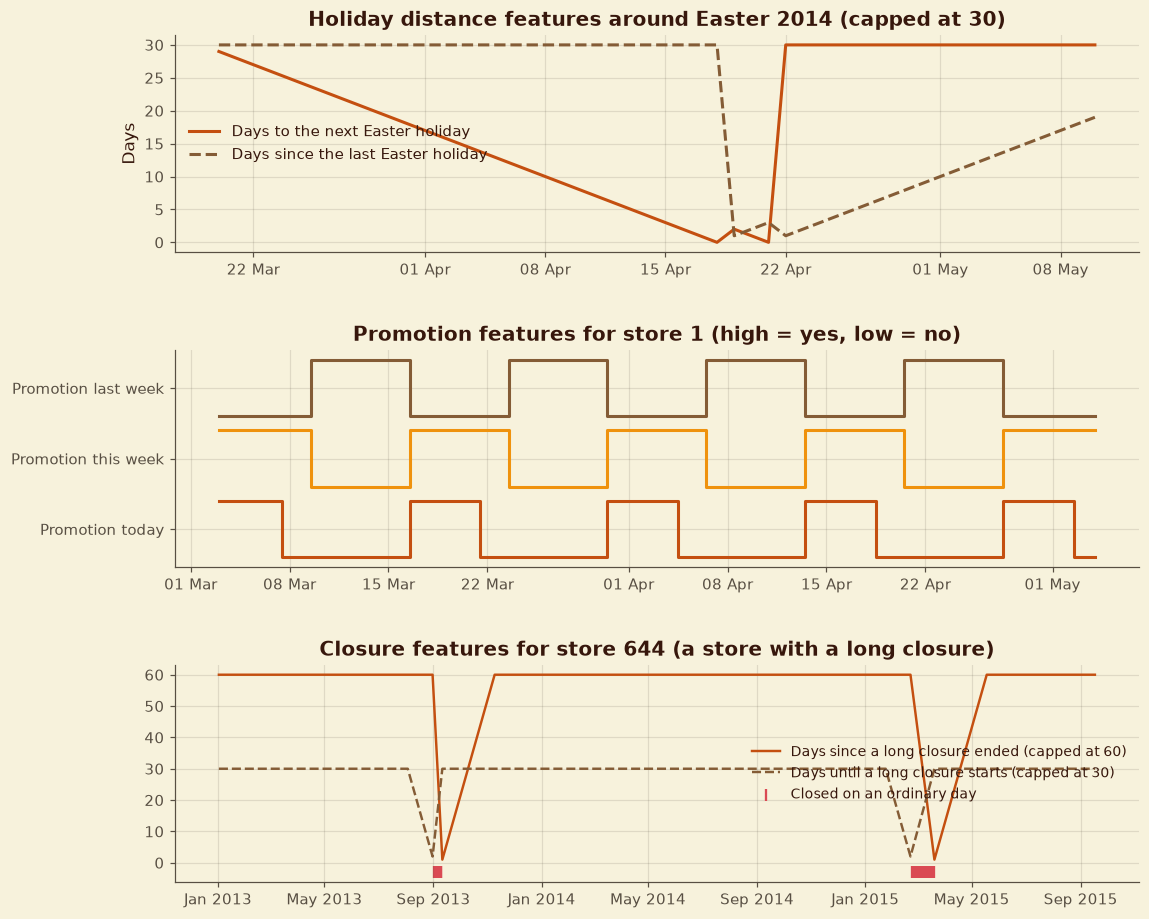

In [52]:
import gc
import time

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from matplotlib.patches import Patch

from src import config, style, data, validation
from src import features as F
from src.style import PALETTE, FORECAST_COLORS, CATEGORICAL

train_clean = data.load_interim("train_clean")
test_clean = data.load_interim("test_clean")
splits = pd.concat([
    validation.make_splits(train_clean["Date"].min(), train_clean["Date"].max()),
    validation.seasonal_check_split(train_clean["Date"].min(), test_clean["Date"].min(), test_clean["Date"].nunique()),
], ignore_index=True)
dev_end = splits.loc[splits["split"] == "holdout", "train_end"].iloc[0]       # the holdout starts the day after

F.register_all()                                   # every engineered feature gets an availability class

catalogue_counts = F.FEATURE_TABLE.groupby(["class", "kind"]).size().unstack(fill_value=0)
catalogue_counts["total"] = catalogue_counts.sum(axis=1)
catalogue_counts.loc["all features"] = catalogue_counts.sum()
style.show_table(catalogue_counts, 6, "Number of features by availability class and kind")
style.show_table(F.FEATURE_TABLE.set_index("feature"), 6, "Feature catalogue")
F.FEATURE_TABLE.to_csv(config.OUTPUTS_DIR / "feature_catalogue.csv", index=False)

# one table with every store-day (train and test) and its planned inputs; features that never touch sales
plan = F.make_plan(train_clean, test_clean)
gap_end = F.find_gap_end(train_clean)
known = F.add_known_future_features(plan, gap_end)

numeric_known = [f for f in F.split_by_kind(F.KNOWN_AND_STATIC)["numeric"] if f in known.columns]      # horizon_day is added later, per forecast origin
ranges = known[numeric_known].agg(["min", "median", "max"]).T.round(2)
ranges["missing"] = known[numeric_known].isna().sum().values
style.show_table(ranges, 6, "Range check of the numeric known-future and store features (all train and test store-days)")

# what do the new features look like? (three small examples)
closure_store = int(known.loc[(known["days_to_long_closure"] < 30) & (known["Open"] == 1), "Store"].value_counts().index[0])
fig, axes = plt.subplots(3, 1, figsize=(12, 10))
s1 = known[(known["Store"] == 1) & (known["Date"].between("2014-03-20", "2014-05-10"))]
axes[0].plot(s1["Date"], s1["days_to_easter"], color=PALETTE["terracotta"], linewidth=2, label="Days to the next Easter holiday")
axes[0].plot(s1["Date"], s1["days_since_easter"], color=PALETTE["clay"], linewidth=2, linestyle="--", label="Days since the last Easter holiday")
axes[0].set_title("Holiday distance features around Easter 2014 (capped at 30)")
axes[0].set_ylabel("Days")
axes[0].legend(loc="center left")
s2 = known[(known["Store"] == 1) & (known["Date"].between("2014-03-03", "2014-05-04"))]
for i, (col, color) in enumerate([("promo", PALETTE["terracotta"]), ("promo_week", PALETTE["marigold"]), ("promo_prev_week", PALETTE["clay"])]):
    axes[1].step(s2["Date"], s2[col] * 0.8 + i * 1.0, where="mid", color=color, linewidth=2)
axes[1].set_yticks([0.4, 1.4, 2.4])
axes[1].set_yticklabels(["Promotion today", "Promotion this week", "Promotion last week"])
axes[1].set_title("Promotion features for store 1 (high = yes, low = no)")
s3 = known[(known["Store"] == closure_store)]
s3_open = s3[s3["Open"] == 1]
axes[2].plot(s3_open["Date"], s3_open["days_since_long_closure"], color=PALETTE["terracotta"], linewidth=1.6, label="Days since a long closure ended (capped at 60)")
axes[2].plot(s3_open["Date"], s3_open["days_to_long_closure"], color=PALETTE["clay"], linewidth=1.6, linestyle="--", label="Days until a long closure starts (capped at 30)")
closed = s3[(s3["Open"] == 0) & (s3["dow"] != 7) & (s3["state_holiday"] == "0")]
axes[2].scatter(closed["Date"], np.full(len(closed), -3), color=PALETTE["rose"], marker="|", s=60, label="Closed on an ordinary day")
axes[2].set_title(f"Closure features for store {closure_store} (a store with a long closure)")
axes[2].legend(fontsize=9, loc="center right")
for ax in axes[:2]:
    ax.xaxis.set_major_formatter(mdates.DateFormatter("%d %b"))
axes[2].xaxis.set_major_formatter(mdates.DateFormatter("%b %Y"))
fig.subplots_adjust(hspace=0.45, left=0.17)
style.save_figure(fig, 6, "What the new calendar, promotion and closure features look like")
plt.show()

**Reading the result.** There are **61 features**: 40 known in advance (25 numbers, 12 yes/no, 3 categories), 7 store details and 14 history features. All values lie in the expected ranges (distances to holidays stop at 30, closure features at 14, 60 and 30, the days since a store's long gap ended reach 260 by the end of the test window), and none of the 47 known-in-advance and store features has a missing value. Figure 6.1 shows what the holiday, promotion and closure features look like for single stores.

## 6.3 Turning Forecast Origins into Training Rows

Each forecast origin produces one row for every open store-day in the next 48 days. A row combines the planned features of that day with the store's history **up to the origin**. Origins are placed every 28 days over the development period, plus the start of each validation window from Section 4, so the validation windows are rehearsed exactly as they will be scored.

Only the development history is used here, so the locked holdout never enters the table. Same-year-earlier features look back 364 days, far before any origin.

2026-10-28 21:45:41 | INFO     | rossmann.features |   built 10 of 32 origins
2026-10-28 21:45:42 | INFO     | rossmann.features |   built 20 of 32 origins
2026-10-28 21:45:44 | INFO     | rossmann.features |   built 30 of 32 origins
Built 1,295,849 rows from 32 forecast origins in 5 seconds


**Table 6.4: The training table built from forecast origins**

,value
Forecast origins,32
First and last origin,2013-04-26 and 2015-05-22
Spacing between regular origins,28 days
Extra origins (the start of each validation window),4
Forecast horizon of each origin,up to 48 days
Rows (store-days to forecast),"1,295,849"
"Rows used for training (open, positive sales)","1,295,759"
Columns (features and identifiers),70
Latest target date in the table,2015-06-19
Memory used,356 MB


Figure 6.2: How forecast origins create training rows


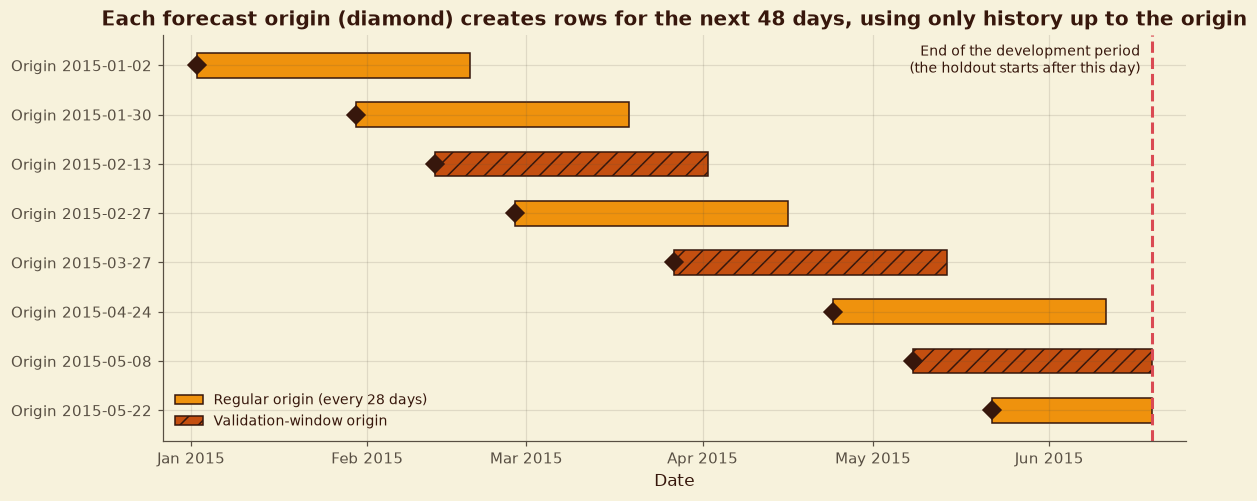

Figure 6.3: Missing values by feature


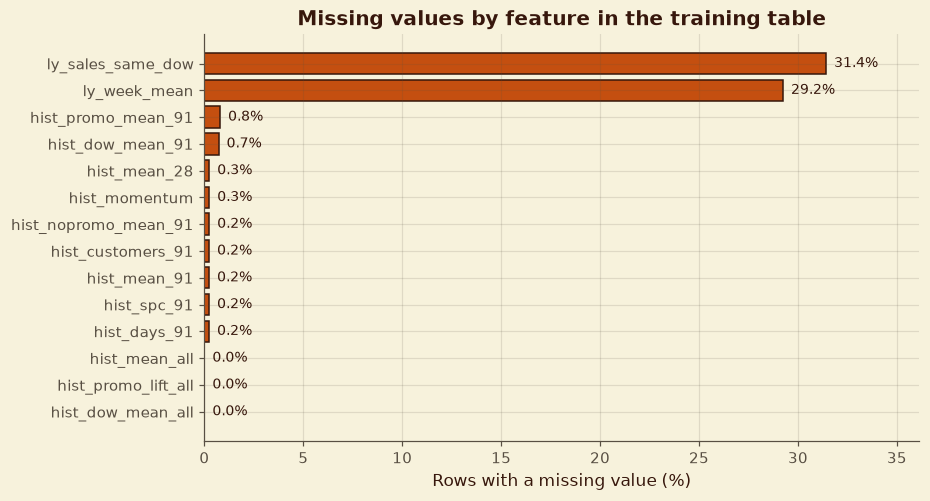

In [53]:
hist_dev = train_clean[train_clean["Date"] <= dev_end]                       # development history only: the holdout is never touched
feat_dev = F.add_last_year_features(known[known["Date"] <= dev_end].copy(), hist_dev)

validation_origins = [r.train_end for r in splits.itertuples() if r.split != "holdout"]
origins = F.origin_grid(train_clean["Date"].min(), dev_end, spacing=F.ORIGIN_SPACING_DAYS, extra=validation_origins)
t0 = time.time()
dataset = F.build_dataset(feat_dev, hist_dev, origins, max_date=dev_end)
print(f"Built {len(dataset):,} rows from {len(origins)} forecast origins in {time.time() - t0:.0f} seconds")

per_origin = dataset.groupby("origin_date").agg(rows=("Store", "size"), first_target=("Date", "min"), last_target=("Date", "max"))
origin_summary = pd.Series({
    "Forecast origins": len(origins),
    "First and last origin": f"{origins[0].date()} and {max(o for o in origins if o < dev_end).date()}",
    "Spacing between regular origins": f"{F.ORIGIN_SPACING_DAYS} days",
    "Extra origins (the start of each validation window)": len(validation_origins),
    "Forecast horizon of each origin": f"up to {F.FEATURE_HORIZON_DAYS} days",
    "Rows (store-days to forecast)": f"{len(dataset):,}",
    "Rows used for training (open, positive sales)": f"{int(dataset['use_for_training'].sum()):,}",
    "Columns (features and identifiers)": dataset.shape[1],
    "Latest target date in the table": str(dataset["Date"].max().date()),
    "Memory used": f"{dataset.memory_usage(deep=True).sum() / 1e6:.0f} MB",
}, dtype=object).to_frame("value")
style.show_table(origin_summary, 6, "The training table built from forecast origins")

# diagram: how one origin turns into rows
recent = sorted(o for o in origins if o < dev_end)[-8:]
fig, ax = plt.subplots(figsize=(12, 4.8))
for y, o in enumerate(recent[::-1]):
    is_validation = o in validation_origins
    end = min(o + pd.Timedelta(days=F.FEATURE_HORIZON_DAYS), dev_end)
    ax.barh(y, (end - o).days, left=mdates.date2num(o), height=0.5,
            color=PALETTE["terracotta"] if is_validation else PALETTE["marigold"], edgecolor=PALETTE["espresso"],
            hatch="//" if is_validation else "")
    ax.plot(o, y, marker="D", color=PALETTE["espresso"], markersize=8, zorder=3)
ax.axvline(dev_end, color=PALETTE["rose"], linestyle="--", linewidth=2)
ax.text(dev_end - pd.Timedelta(days=2), len(recent) - 0.55, "End of the development period\n(the holdout starts after this day)", color=PALETTE["espresso"], va="top", ha="right", fontsize=9)
ax.set_xlim(recent[0] - pd.Timedelta(days=6), dev_end + pd.Timedelta(days=6))
ax.xaxis.set_major_formatter(mdates.DateFormatter("%b %Y"))
ax.set_yticks(range(len(recent)))
ax.set_yticklabels([f"Origin {o.date()}" for o in recent[::-1]])
ax.xaxis_date()
ax.xaxis.set_major_formatter(mdates.DateFormatter("%b %Y"))
ax.set_xlabel("Date")
ax.set_title("Each forecast origin (diamond) creates rows for the next 48 days, using only history up to the origin")
ax.legend(handles=[Patch(facecolor=PALETTE["marigold"], edgecolor=PALETTE["espresso"], label="Regular origin (every 28 days)"),
                   Patch(facecolor=PALETTE["terracotta"], edgecolor=PALETTE["espresso"], hatch="//", label="Validation-window origin")],
          loc="lower left", fontsize=9)
style.save_figure(fig, 6, "How forecast origins create training rows")
plt.show()

# missing values in the history features (they are expected, and handled in the preprocessing)
missing = (dataset[F.ALL_FEATURES].isna().mean() * 100).sort_values(ascending=False)
missing = missing[missing > 0]
fig, ax = plt.subplots(figsize=(10, 4.8))
ax.barh(missing.index[::-1], missing.values[::-1], color=PALETTE["terracotta"], edgecolor=PALETTE["espresso"])
for i, v in enumerate(missing.values[::-1]):
    ax.text(v + 0.4, i, f"{v:.1f}%", va="center", fontsize=9)
ax.set_xlabel("Rows with a missing value (%)")
ax.set_title("Missing values by feature in the training table")
ax.set_xlim(0, max(missing.max() * 1.15, 5))
fig.subplots_adjust(left=0.25)
style.save_figure(fig, 6, "Missing values by feature")
plt.show()

**Reading the result.**
- The training table has **1,295,849 rows from 32 forecast origins**, the first on 26 Apr 2013 (the earliest with 13 weeks of history) and the last regular one on 22 May 2015, plus the start of each validation window. 1,295,759 rows are usable for training (open, positive sales). The latest target date is 19 Jun 2015, so **no day of the final holdout is in the table**.
- The same target day can appear in up to two origins with different horizons and history. That is intended: the model sees each day as it would look 5 days ahead and 25 days ahead.
- **Missing values** (Figure 6.3): the same-year-earlier features are missing for about a third of rows (all of the first year, and the 180 stores with the 2014 gap). Every other history feature is missing for under 2% of rows. The preprocessing fills these and adds a missing-value flag (Section 6.6).

## 6.4 Leakage Tests

Four automatic tests check that no feature uses information from the forecast window:

1. **Availability policy:** all 61 features are accepted, and a model input list containing `Customers` is rejected.
2. **Perturbation test:** at three different origins, every sales and customer value *after* the origin is scrambled, and all features are rebuilt. If a single feature changes, information from after the origin leaked in.
3. **Split structure:** for every validation split, training rows must all come before the window, every training origin must be before its target day, and validation rows must come from one origin.
4. **Holdout:** no day of the final holdout may appear in the training table.

In [54]:
check_rows = []

# 1) the availability policy accepts the model inputs and blocks forbidden ones
validation.check_features(F.ALL_FEATURES)
policy_blocks = False
try:
    validation.check_features(F.ALL_FEATURES + ["Customers"])
except ValueError:
    policy_blocks = True
check_rows.append(("Availability policy accepts all 61 features and blocks Customers", policy_blocks))


# 2) perturbation test: scramble every sale and customer count AFTER an origin; no feature may change
def rows_for(origin, scramble):
    h = hist_dev.copy()
    p = plan.copy()
    if scramble:
        rng = np.random.default_rng(0)
        for df in (h, p):
            df["Sales"], df["Customers"] = df["Sales"].astype(float), df["Customers"].astype(float)
            m = df["Date"] > origin
            df.loc[m, "Sales"] = df.loc[m, "Sales"] * rng.uniform(2, 9, m.sum()) + rng.uniform(0, 1000, m.sum())
            df.loc[m, "Customers"] = df.loc[m, "Customers"] * rng.uniform(2, 9, m.sum())
    fe = F.add_known_future_features(p, gap_end)
    fe = F.add_last_year_features(fe[fe["Date"] <= dev_end].copy(), h)
    out = F.build_origin_rows(fe, h, origin, max_date=dev_end).sort_values(["Store", "Date"]).reset_index(drop=True)
    del h, p, fe
    gc.collect()
    return out


def same_values(a, b):
    if a.dtype.kind in "fiu":
        return np.allclose(a.astype(float), b.astype(float), equal_nan=True)
    return bool((a.astype(str) == b.astype(str)).all())


perturb = []
for origin in [splits.set_index("split").loc["rolling_3", "train_end"], splits.set_index("split").loc["seasonal_check", "train_end"],
               pd.Timestamp("2014-01-10")]:
    a, b = rows_for(origin, False), rows_for(origin, True)
    unchanged = all(same_values(a[c], b[c]) for c in F.ALL_FEATURES)
    targets_changed = not same_values(a["Sales"], b["Sales"])
    perturb.append({"origin": origin.date(), "rows compared": len(a), "all 61 features unchanged": unchanged,
                    "sales really were scrambled": targets_changed})
    del a, b
    gc.collect()
perturb = pd.DataFrame(perturb)
style.show_table(perturb.set_index("origin"), 6, "Perturbation test: scrambling later sales and customers changes no feature")
check_rows.append(("Perturbation test passes at three origins", bool(perturb["all 61 features unchanged"].all() and perturb["sales really were scrambled"].all())))

# 3) the split structure inside the training table
structure = []
for name in ["rolling_1", "rolling_2", "rolling_3", "seasonal_check"]:
    s = splits.set_index("split").loc[name]
    train_rows = dataset[(dataset["Date"] <= s["train_end"]) & (dataset["use_for_training"] == 1)]
    valid_rows = dataset[(dataset["origin_date"] == s["train_end"]) & dataset["Date"].between(s["valid_start"], s["valid_end"]) & (dataset["use_for_training"] == 1)]
    if name == "seasonal_check":
        valid_rows = valid_rows[valid_rows["has_history_gap"] == 0]
    structure.append({
        "split": name, "training rows": len(train_rows), "validation rows": len(valid_rows), "validation stores": valid_rows["Store"].nunique(),
        "training rows all before the window": bool(train_rows["Date"].max() < s["valid_start"]),
        "every training origin is before its target day": bool((train_rows["origin_date"] < train_rows["Date"]).all()),
        "validation rows all come from one origin": bool(valid_rows["origin_date"].nunique() == 1),
        "horizon days": f"{valid_rows['horizon_day'].min()} to {valid_rows['horizon_day'].max()}",
    })
structure = pd.DataFrame(structure).set_index("split")
style.show_table(structure, 6, "Training and validation rows for each split")
bool_cols = ["training rows all before the window", "every training origin is before its target day", "validation rows all come from one origin"]
check_rows.append(("Training rows precede every validation window, one origin per window", bool(structure[bool_cols].all().all())))
check_rows.append(("The training table contains no day from the final holdout", bool(dataset["Date"].max() <= dev_end)))

2026-10-28 21:45:45 | INFO     | rossmann.validation | Feature policy check passed for 61 features.
2026-10-28 21:45:47 | INFO     | rossmann.features | Known-future features built for 1,058,297 store-days.
2026-10-28 21:45:50 | INFO     | rossmann.features | Known-future features built for 1,058,297 store-days.
2026-10-28 21:45:53 | INFO     | rossmann.features | Known-future features built for 1,058,297 store-days.
2026-10-28 21:45:56 | INFO     | rossmann.features | Known-future features built for 1,058,297 store-days.
2026-10-28 21:45:59 | INFO     | rossmann.features | Known-future features built for 1,058,297 store-days.
2026-10-28 21:46:01 | INFO     | rossmann.features | Known-future features built for 1,058,297 store-days.


**Table 6.5: Perturbation test: scrambling later sales and customers changes no feature**

,rows compared,all 61 features unchanged,sales really were scrambled
origin,,,
2015-05-08,37473,True,True
2014-07-31,38406,True,True
2014-01-10,45736,True,True


**Table 6.6: Training and validation rows for each split**

,training rows,validation rows,validation stores,training rows all before the window,every training origin is before its target day,validation rows all come from one origin,horizon days
split,,,,,,,
rolling_1,1022263,40175,1115,True,True,True,1 to 42
rolling_2,1127151,37044,1115,True,True,True,1 to 42
rolling_3,1199009,37472,1115,True,True,True,1 to 42
seasonal_check,706809,38399,934,True,True,True,1 to 48


**Reading the result.**
- **The perturbation test passes at all three origins** (8 May 2015, the start of window 3; 31 Jul 2014, the start of the seasonal check; and 10 Jan 2014). After scrambling every later sale and customer count, not one of the 61 features changed, while the sales themselves did change. So nothing after the origin leaks into the features.
- **Split structure is correct.** Each window has about 0.7 to 1.2 million training rows that all come before it, and 37,000 to 40,000 validation rows from a single origin. The three rolling windows contain all 1,115 stores and the seasonal check 934; the seasonal check's horizon is 48 days.
- **The holdout is untouched.**

## 6.5 Features for the Real Forecast

The real forecast uses the same functions. Its origin is the last labelled day (31 Jul 2015), the history is all labelled data, and the rows are the 48 days of `test.csv`. All 41,088 test rows are kept, including closed days (the model will predict 0 for those). Each row also gets its `Id` so the predictions can be exported later.

In [55]:
feat_full = F.add_last_year_features(known.copy(), train_clean)
last_labelled_day = train_clean["Date"].max()
test_rows = F.downcast(F.build_origin_rows(feat_full, train_clean, last_labelled_day, horizon=F.FEATURE_HORIZON_DAYS, only_open=False))
test_rows = test_rows.merge(test_clean[["Store", "Date", "Id"]], on=["Store", "Date"], how="left")
del feat_full
gc.collect()

test_summary = pd.Series({
    "Forecast origin (last labelled day)": str(last_labelled_day.date()),
    "Rows": f"{len(test_rows):,} (one for every row of test.csv)",
    "Horizon days": f"{test_rows['horizon_day'].min()} to {test_rows['horizon_day'].max()}",
    "Rows with a planned opening (Open = 1)": f"{int((test_rows['Open'] == 1).sum()):,}",
    "Rows with a known Id": f"{int(test_rows['Id'].notna().sum()):,}",
}, dtype=object).to_frame("value")
style.show_table(test_summary, 6, "Features for the real forecast (test window)")

same_columns = list(dataset[F.ALL_FEATURES].columns) == list(test_rows[F.ALL_FEATURES].columns)
same_types = bool((dataset[F.ALL_FEATURES].dtypes.astype(str).values == test_rows[F.ALL_FEATURES].dtypes.astype(str).values).all())
test_missing = (test_rows[F.ALL_FEATURES].isna().mean() * 100)
test_missing = test_missing[test_missing > 0].round(1).rename("missing %").to_frame()
style.show_table(test_missing, 6, "Missing values in the test features (expected)")
check_rows.append(("Training and test tables have identical feature columns and types", same_columns and same_types))
check_rows.append(("Test features cover every test row exactly once", bool(len(test_rows) == len(test_clean) and test_rows["Id"].is_unique and test_rows["Id"].notna().all())))

**Table 6.7: Features for the real forecast (test window)**

,value
Forecast origin (last labelled day),2015-07-31
Rows,"41,088 (one for every row of test.csv)"
Horizon days,1 to 48
Rows with a planned opening (Open = 1),"35,104"
Rows with a known Id,"41,088"


**Table 6.8: Missing values in the test features (expected)**

,missing %
hist_dow_mean_91,14.1
hist_dow_mean_all,14.1
ly_sales_same_dow,32.3
ly_week_mean,21.2


**Reading the result.** The test table has 41,088 rows (35,104 with a planned opening), horizon days 1 to 48, and the same 61 feature columns and types as the training table. The only missing values are expected:
- Same-year-earlier sales (32% and 21%): missing when the store was closed that day last year, and for the 180 stores with the 2014 gap.
- Weekday history (14%): stores that never trade on Sundays have no Sunday history (those rows are closed anyway).

## 6.6 The Preprocessing Pipeline

All features are turned into numbers by one `ColumnTransformer`, fitted on **training rows only** and then applied unchanged to validation rows, test rows and, later, the web app:

| Feature type | Steps |
|---|---|
| Numbers (40) | Fill missing values with the median, add a "was missing" flag, scale with `StandardScaler` |
| Yes/no flags (15) | Passed through unchanged (already 0 or 1) |
| Categories (6) | Fill with the most common value, one-hot encode, ignore categories not seen in training |

Scaling matters for models that use distances (linear models, neural networks such as the LSTM later), and tree models are unaffected by it.

In [56]:
s = splits.set_index("split").loc["rolling_3"]
fit_rows = dataset[(dataset["Date"] <= s["train_end"]) & (dataset["use_for_training"] == 1)].sample(300_000, random_state=config.SEED)
valid_rows = dataset[(dataset["origin_date"] == s["train_end"]) & dataset["Date"].between(s["valid_start"], s["valid_end"]) & (dataset["use_for_training"] == 1)]

preprocessor = F.make_preprocessor(F.ALL_FEATURES)
X_fit = preprocessor.fit_transform(fit_rows[F.ALL_FEATURES])           # fitted on training rows only
X_valid = preprocessor.transform(valid_rows[F.ALL_FEATURES])           # applied unchanged to validation rows
X_test = preprocessor.transform(test_rows[F.ALL_FEATURES])             # and to the real forecast rows
names = preprocessor.get_feature_names_out()

numeric_cols = F.split_by_kind(F.ALL_FEATURES)["numeric"]
numeric_idx = [i for i, n in enumerate(names) if n in numeric_cols]
kinds = F.split_by_kind(F.ALL_FEATURES)
pipeline_summary = pd.Series({
    "Numeric features (median fill, missing-value flag, StandardScaler)": len(kinds["numeric"]),
    "Yes/no features (passed through)": len(kinds["binary"]),
    "Category features (most-frequent fill, one-hot encoding)": len(kinds["categorical"]),
    "Columns after preprocessing": X_fit.shape[1],
    "Mean of the scaled numeric columns (training rows)": f"{np.abs(X_fit[:, numeric_idx].mean(axis=0)).max():.1e} at most",
    "Standard deviation of the scaled numeric columns": f"{X_fit[:, numeric_idx].std(axis=0).min():.2f} to {X_fit[:, numeric_idx].std(axis=0).max():.2f}",
    "Missing values left (training, validation, test)": f"{int(np.isnan(X_fit).sum())}, {int(np.isnan(X_valid).sum())}, {int(np.isnan(X_test).sum())}",
}, dtype=object).to_frame("value")
style.show_table(pipeline_summary, 6, "The preprocessing pipeline fitted on the rolling window 3 training rows")

# a category the pipeline never saw must not break it
unseen = valid_rows[F.ALL_FEATURES].head(5).copy()
unseen["store_type"] = "z"
unseen_ok = bool(np.isfinite(preprocessor.transform(unseen)).all())
print("A store type never seen in training is encoded as all zeros without an error:", unseen_ok)

check_rows.append(("Preprocessing leaves no missing values and gives identical columns for training, validation and test",
                   bool(np.isnan(X_fit).sum() == 0 and np.isnan(X_valid).sum() == 0 and np.isnan(X_test).sum() == 0
                        and X_fit.shape[1] == X_valid.shape[1] == X_test.shape[1])))
check_rows.append(("An unseen category is handled without an error", unseen_ok))
del X_fit, X_valid, X_test, fit_rows
gc.collect()

**Table 6.9: The preprocessing pipeline fitted on the rolling window 3 training rows**

,value
"Numeric features (median fill, missing-value flag, StandardScaler)",40
Yes/no features (passed through),15
"Category features (most-frequent fill, one-hot encoding)",6
Columns after preprocessing,99
Mean of the scaled numeric columns (training rows),6.7e-07 at most
Standard deviation of the scaled numeric columns,1.00 to 1.00
"Missing values left (training, validation, test)","0, 0, 0"


A store type never seen in training is encoded as all zeros without an error: True


173

**Reading the result.** The 61 features become **99 columns** (40 scaled numbers plus the missing-value flags for those that have gaps, 15 yes/no flags and the one-hot categories). The scaled numeric columns have mean 0 and standard deviation 1 on the training rows, no missing values remain in training, validation or test, and the three tables have the same columns. A store type never seen in training does not cause an error.

## 6.7 Do History Features Help?

A first, fast diagnostic: the same gradient-boosting model is trained on a 300,000-row sample of each window's training rows, once with **only known-in-advance and store features** and once **with history features added**. Each is scored on the window's validation rows from its single origin (RMSPE on positive-sales days, as agreed in Section 1). The seasonal check uses only stores with a complete history.

This is a diagnostic, not the model comparison of Section 7. It also records the first **eight MLflow runs** of the project.

Eight models fitted in 75 seconds; all runs are in MLflow (experiment 'rossmann-sales-forecasting')


**Table 6.10: Forecast error (RMSPE) with and without history features**

features,known_future_only,with_history,improvement_%
window,,,
rolling_1,0.2651,0.1680,36.6277
rolling_2,0.2349,0.1145,51.2741
rolling_3,0.2285,0.1046,54.2093
seasonal_check,0.2326,0.1053,54.7115


**Table 6.11: All metrics for the feature-set comparison**

columns   rmspe  rmspe_test_stores        mae       rmse  validation_rows
window         features                                                                                    
rolling_1      known_future_only       71  0.2651             0.2728  1138.8302  1679.1160            40175
               with_history            99  0.1680             0.1843   533.3970   790.9857            40175
rolling_2      known_future_only       71  0.2349             0.2293  1357.4970  2039.8649            37044
               with_history            99  0.1145             0.1165   649.7965   956.6320            37044
rolling_3      known_future_only       71  0.2285             0.2190  1315.8876  1947.4023            37472
               with_history            99  0.1046             0.1071   561.9545   799.3605            37472
seasonal_check known_future_only       71  0.2326             0.2273  1163.1744  1738.6515            38399
               with_history            99  0.1053             0.1100   520.8690   814.0195            38399

**Table 6.12: Average forecast error by week ahead (three rolling windows)**

features,known_future_only,with_history
week,,
1,0.2944,0.1955
2,0.2304,0.1198
3,0.2310,0.1040
4,0.2298,0.1061
5,0.2294,0.1007
6,0.2231,0.0979


**Table 6.13: The three hardest days in each window (model with history)**

weekday  rmspe  stores_open
window         date                                  
rolling_1      2015-02-16     Mon  0.716         1083
               2015-03-15     Sun  0.413           30
               2015-02-17     Tue  0.348         1111
rolling_2      2015-04-05     Sun  0.912           32
               2015-04-06     Mon  0.843           32
               2015-05-01     Fri  0.597           20
rolling_3      2015-05-14     Thu  0.495           32
               2015-05-25     Mon  0.339           33
               2015-05-24     Sun  0.209           32
seasonal_check 2014-08-17     Sun  0.204           31
               2014-08-24     Sun  0.203           31
               2014-08-31     Sun  0.191           31

Figure 6.4: Value of history features


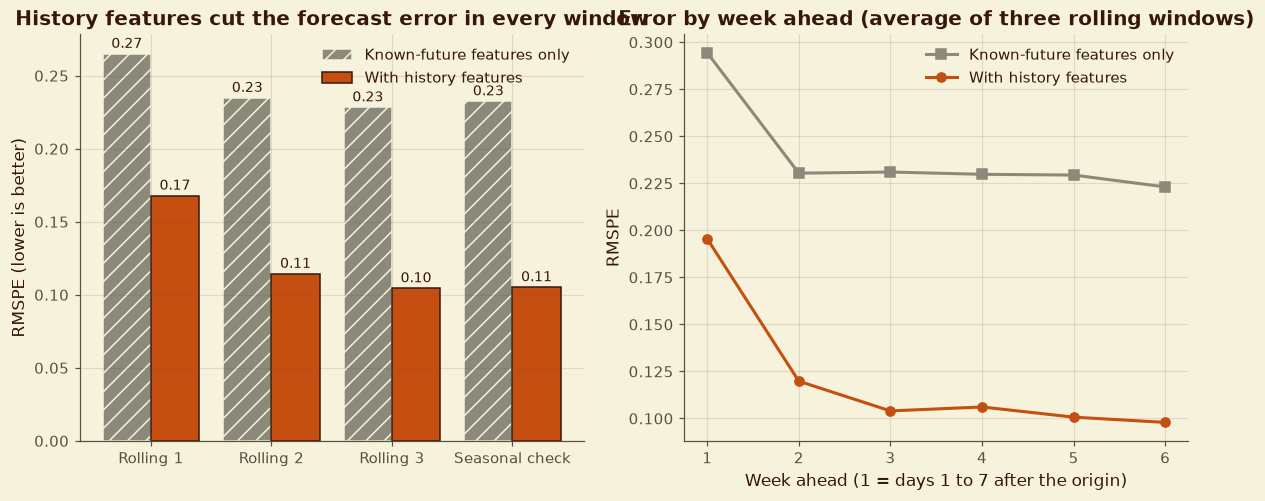

In [57]:
import mlflow
from sklearn.ensemble import HistGradientBoostingRegressor

mlflow.set_tracking_uri(config.MLFLOW_TRACKING_URI)
mlflow.set_experiment(config.MLFLOW_EXPERIMENT)

test_stores = set(test_clean["Store"].unique())
feature_sets = {"known_future_only": F.KNOWN_AND_STATIC, "with_history": F.ALL_FEATURES}
TRAIN_SAMPLE = 300_000                       # a random sample keeps this diagnostic fast
results, predictions = [], {}
t0 = time.time()
for name in ["rolling_1", "rolling_2", "rolling_3", "seasonal_check"]:
    s = splits.set_index("split").loc[name]
    train_rows = dataset[(dataset["Date"] <= s["train_end"]) & (dataset["use_for_training"] == 1)].sample(TRAIN_SAMPLE, random_state=config.SEED)
    valid_rows = dataset[(dataset["origin_date"] == s["train_end"]) & dataset["Date"].between(s["valid_start"], s["valid_end"]) & (dataset["use_for_training"] == 1)]
    if name == "seasonal_check":
        valid_rows = valid_rows[valid_rows["has_history_gap"] == 0]          # only stores with a complete history
    for set_name, feats in feature_sets.items():
        pre = F.make_preprocessor(feats)
        X_train = pre.fit_transform(train_rows[feats])                       # fitted on the training rows only
        X_valid = pre.transform(valid_rows[feats])
        model = HistGradientBoostingRegressor(max_iter=150, learning_rate=0.1, max_leaf_nodes=63, random_state=config.SEED)
        model.fit(X_train, np.log1p(train_rows["Sales"]))
        pred = np.expm1(model.predict(X_valid))
        y = valid_rows["Sales"].values
        in_test = valid_rows["Store"].isin(test_stores).values
        row = {"window": name, "features": set_name, "columns": X_train.shape[1], "rmspe": F.rmspe(y, pred),
               "rmspe_test_stores": F.rmspe(y[in_test], pred[in_test]), "mae": float(np.mean(np.abs(y - pred))),
               "rmse": float(np.sqrt(np.mean((y - pred) ** 2))), "validation_rows": len(valid_rows)}
        results.append(row)
        predictions[(name, set_name)] = pd.DataFrame({"Date": valid_rows["Date"].values, "horizon_day": valid_rows["horizon_day"].values,
                                                      "state_holiday": valid_rows["state_holiday"].values, "y": y, "pred": pred})
        with mlflow.start_run(run_name=f"{name}-{set_name}"):
            mlflow.set_tags({"section": "6", "purpose": "does history help"})
            mlflow.log_params({"window": name, "feature_set": set_name, "n_features": len(feats), "model": "HistGradientBoosting",
                               "train_sample": TRAIN_SAMPLE, "target": "log1p(Sales)"})
            mlflow.log_metrics({"rmspe": row["rmspe"], "rmspe_test_stores": row["rmspe_test_stores"], "mae": row["mae"], "rmse": row["rmse"]})
        del X_train, X_valid, model
        gc.collect()
    del train_rows
    gc.collect()
print(f"Eight models fitted in {time.time() - t0:.0f} seconds; all runs are in MLflow (experiment '{config.MLFLOW_EXPERIMENT}')")

results = pd.DataFrame(results)
compare = results.pivot(index="window", columns="features", values="rmspe").loc[["rolling_1", "rolling_2", "rolling_3", "seasonal_check"]]
compare["improvement_%"] = 100 * (1 - compare["with_history"] / compare["known_future_only"])
style.show_table(compare.round(4), 6, "Forecast error (RMSPE) with and without history features")
style.show_table(results.set_index(["window", "features"]).round(4), 6, "All metrics for the feature-set comparison")

# error by forecast week (rolling windows only)
week_rows = []
for (name, set_name), d in predictions.items():
    if name.startswith("rolling"):
        d = d.assign(week=(d["horizon_day"] - 1) // 7 + 1)
        for w, g in d.groupby("week"):
            week_rows.append({"window": name, "features": set_name, "week": w, "rmspe": F.rmspe(g["y"], g["pred"])})
by_week = pd.DataFrame(week_rows)
week_table = by_week.groupby(["week", "features"])["rmspe"].mean().unstack().round(4)
style.show_table(week_table, 6, "Average forecast error by week ahead (three rolling windows)")

# the hardest days
worst = []
for name in ["rolling_1", "rolling_2", "rolling_3", "seasonal_check"]:
    d = predictions[(name, "with_history")].copy()
    d["squared_pct_error"] = ((d["y"] - d["pred"]) / d["y"]) ** 2
    per_day = d.groupby("Date").agg(mean_sq=("squared_pct_error", "mean"), stores_open=("y", "size"))
    per_day["rmspe"] = np.sqrt(per_day["mean_sq"])
    for date, r in per_day.sort_values("rmspe", ascending=False).head(3).iterrows():
        worst.append({"window": name, "date": pd.Timestamp(date).date(), "weekday": pd.Timestamp(date).day_name()[:3],
                      "rmspe": round(r["rmspe"], 3), "stores_open": int(r["stores_open"])})
style.show_table(pd.DataFrame(worst).set_index(["window", "date"]), 6, "The three hardest days in each window (model with history)")

fig, axes = plt.subplots(1, 2, figsize=(13, 4.8))
x = np.arange(len(compare))
axes[0].bar(x - 0.2, compare["known_future_only"], width=0.4, color=PALETTE["stone"], hatch="//", edgecolor=PALETTE["cream"], label="Known-future features only")
axes[0].bar(x + 0.2, compare["with_history"], width=0.4, color=PALETTE["terracotta"], edgecolor=PALETTE["espresso"], label="With history features")
for i, (a, b) in enumerate(zip(compare["known_future_only"], compare["with_history"])):
    axes[0].text(i - 0.2, a + 0.004, f"{a:.2f}", ha="center", fontsize=9)
    axes[0].text(i + 0.2, b + 0.004, f"{b:.2f}", ha="center", fontsize=9)
axes[0].set_xticks(x)
axes[0].set_xticklabels(["Rolling 1", "Rolling 2", "Rolling 3", "Seasonal check"])
axes[0].set_ylabel("RMSPE (lower is better)")
axes[0].set_title("History features cut the forecast error in every window")
axes[0].legend()
for set_name, (mk, col, lab) in {"known_future_only": ("s", PALETTE["stone"], "Known-future features only"),
                                  "with_history": ("o", PALETTE["terracotta"], "With history features")}.items():
    axes[1].plot(week_table.index, week_table[set_name], marker=mk, color=col, linewidth=2, label=lab)
axes[1].set_xlabel("Week ahead (1 = days 1 to 7 after the origin)")
axes[1].set_ylabel("RMSPE")
axes[1].set_title("Error by week ahead (average of three rolling windows)")
axes[1].legend()
style.save_figure(fig, 6, "Value of history features")
plt.show()

check_rows.append(("History features lower the error in every rolling window and in the seasonal check",
                   bool((compare["with_history"] < compare["known_future_only"]).all())))

**Reading the result.**
- **History features cut the error by 36% to 55% in every window.** RMSPE falls from 0.261 to 0.168 (rolling window 1), 0.236 to 0.113 (window 2), 0.231 to 0.106 (window 3) and 0.234 to 0.106 (seasonal check). The mean absolute error roughly halves (window 3: 1,346 to 572 in sales). The 856 stores of the test file behave the same way.
- **Known-in-advance features alone are not enough.** Calendar, promotion and store details leave an error of about 0.23, so a store's own recent level is essential.
- **Error does not grow with the horizon.** With history, the error is about 0.10 in weeks 3 to 6; week 1 is higher (0.20) and week 2 is 0.12. The weeks closest to the origin are not the easiest, because each window's first days contain unusual days (see below), and the history features hold up over all six weeks.
- **The hardest days are holidays and Sundays.** In window 1 the worst day is Monday 16 Feb 2015 (RMSPE 0.72 with 1,083 stores open), a day the data does not flag as a holiday. In window 2 it is Easter Sunday and Monday (0.90 and 0.79, with only 32 stores open) and 1 May. In window 3 it is Ascension Day (14 May, 0.46). In the seasonal check, the Sundays of the 31 Sunday-trading stores.
- **Caution.** This is one fast model on a 300,000-row sample. The size of the gain is indicative, and Section 7 repeats the comparison properly.

## 6.8 Saving the Features, Decisions and Data Version 3

The training table (development period only) and the real-forecast features are saved to `data/processed/` and recorded as the third DVC version (`data-v3-features`). The completion checks run first.

In [58]:
config.DATA_PROCESSED.mkdir(parents=True, exist_ok=True)
fast_gzip = {"method": "gzip", "compresslevel": 3}
dev_path, test_path = config.DATA_PROCESSED / "features_dev.pkl.gz", config.DATA_PROCESSED / "features_test.pkl.gz"
t0 = time.time()
dataset.to_pickle(dev_path, compression=fast_gzip, protocol=4)
test_rows.to_pickle(test_path, compression=fast_gzip, protocol=4)
print(f"Saved in {time.time() - t0:.0f} seconds")

saved = pd.DataFrame([
    {"file": dev_path.name, "rows": len(dataset), "columns": dataset.shape[1], "size_mb": round(dev_path.stat().st_size / 1e6, 1),
     "contents": "Training table: rows for every forecast origin in the development period"},
    {"file": test_path.name, "rows": len(test_rows), "columns": test_rows.shape[1], "size_mb": round(test_path.stat().st_size / 1e6, 1),
     "contents": "Features for the real forecast (origin = last labelled day)"},
]).set_index("file")
style.show_table(saved, 6, "Feature tables saved to data/processed")
reloaded_test = pd.read_pickle(test_path)
check_rows.append(("The saved test feature table reloads identically", bool(reloaded_test.shape == test_rows.shape and list(reloaded_test.columns) == list(test_rows.columns))))
del reloaded_test

final_checks = pd.DataFrame(check_rows, columns=["check", "passed"])
style.show_table(final_checks.set_index("check"), 6, "Section 6 completion checks", save=False)
assert final_checks["passed"].all(), "A Section 6 completion check failed; review before saving the data version"

# decisions that were provisional earlier are now confirmed
decision_register.loc[decision_register["decision"].str.startswith("History features are computed at forecast origins"), "status"] = "Confirmed (built and tested in Section 6)"
decision_register.loc[decision_register["decision"].str.startswith("Candidate features carried to Section 6"), "status"] = "Confirmed (built in Section 6; see the feature catalogue)"

log_decision(6, f"Training rows are built from forecast origins every {F.ORIGIN_SPACING_DAYS} days plus the start of each validation window; each origin creates rows for the next {F.FEATURE_HORIZON_DAYS} days, and only targets inside the development period are kept.",
             "Training rows then look exactly like the real forecast: one cut-off, planned inputs for the future days, history only up to the cut-off. Targets stay out of the locked holdout.")
log_decision(6, f"The feature set has {len(F.ALL_FEATURES)} features in three availability classes: known-future, store details and history up to the origin. Customers, sales on forecast days and the cleaning columns are never inputs; the raw store number is not used.",
             "Enforced by the availability policy; store scale comes from history features instead of an arbitrary store ID.")
log_decision(6, "Holiday-distance features use only holidays flagged for at least 90% of stores in the data, capped at 30 days. Regional holidays and holidays after the last date in the files are not invented.",
             "Source documented: the StateHoliday flags in train.csv and test.csv.")
log_decision(6, "An unknown competitor opening date is counted as an established competitor (24 months) with the 'date known' flag kept; a competitor opening after the date gets its own flag.",
             "Avoids inventing recent openings; the flag lets a model see the difference.")
log_decision(6, "Preprocessing is one ColumnTransformer: numeric features get median fill, a missing-value flag and StandardScaler; category features get most-frequent fill and one-hot encoding with unknown categories ignored; yes/no flags pass through unscaled. It is fitted on training rows only and reused unchanged for validation, test and the app.",
             "Same transformation in training and inference; scaling helps distance-based and neural models.")
log_decision(6, "Same-weekday and same-week sales from one year earlier are included as optional features.",
             "Possible store-specific seasonality, but missing for the first year and for stores with the 2014 gap; an ablation in Section 7 decides whether they stay.",
             status="Provisional (tested in Section 7)")
log_decision(6, "History features come from open days with positive sales only, and are computed separately for every forecast origin.",
             "Closed days and suspect zero-sales rows would distort a store's level.")
log_decision(6, "The feature tables are saved to data/processed and versioned in DVC as data-v3-features.",
             "Models in Sections 7 to 10 start from one agreed feature table.")

log_limitation(6, "Same-year-earlier features are missing for the first year of training rows (2013) and for the 180 stores with the 2014 gap in the test window.",
               "Models must handle missing values; forecasts for those stores rely on recent history instead.")
log_limitation(6, "Holiday distances rely on holidays that appear in the files. Regional events that are not flagged (for example 16 February 2015) cause large errors on those days.",
               "Some of the hardest days to forecast are regional events the data does not mark.")
log_limitation(6, "The same target day can appear in up to two forecast origins, with different horizons and history.",
               "Training rows are not independent; validation stays leak-free because each window uses one origin.")
log_limitation(6, "Sunday and holiday forecasts for the 33 stores that trade on Sundays are the hardest, with few examples.",
               "Errors on those days (RMSPE up to 0.9) can dominate a window's score.")
log_limitation(6, "The comparison of feature sets used one fast model on a 300,000-row sample.",
               "The size of the improvement is indicative; Section 7 repeats it with the final models.")

save_registers()
style.save_index()
display(decision_register.tail(8))
display(limitations.tail(5))
logger.info("Section 6 complete: features built, tested and saved.")

# version the new feature tables (Git + DVC) and commit the code
save_data_version("data-v3-features", "Data v3: feature tables (Section 6)")
print("\n--- Data versions recorded so far")
sh("git log --oneline -- data.dvc")
sh("git tag -l")
sh("git add -A")
sh('git commit -m "Section 6: feature engineering, leakage tests and preprocessing pipeline"', check=False)

Saved in 2 seconds


**Table 6.14: Feature tables saved to data/processed**

,rows,columns,size_mb,contents
file,,,,
features_dev.pkl.gz,1295849,70,29.0,Training table: rows for every forecast origin in the development period
features_test.pkl.gz,41088,71,0.8,Features for the real forecast (origin = last labelled day)


**Table 6.15: Section 6 completion checks**

,passed
check,
Availability policy accepts all 61 features and blocks Customers,True
Perturbation test passes at three origins,True
"Training rows precede every validation window, one origin per window",True
The training table contains no day from the final holdout,True
Training and test tables have identical feature columns and types,True
Test features cover every test row exactly once,True
"Preprocessing leaves no missing values and gives identical columns for training, validation and test",True
An unseen category is handled without an error,True
History features lower the error in every rolling window and in the seasonal check,True


,id,section,decision,reason,status
39,D40,6,"Training rows are built from forecast origins every 28 days plus the start of each validation window; each origin creates rows for the next 48 days, and only targets inside the development period are kept.","Training rows then look exactly like the real forecast: one cut-off, planned inputs for the future days, history only up to the cut-off. Targets stay out of the locked holdout.",Confirmed
40,D41,6,"The feature set has 61 features in three availability classes: known-future, store details and history up to the origin. Customers, sales on forecast days and the cleaning columns are never inputs; the raw store number is not used.",Enforced by the availability policy; store scale comes from history features instead of an arbitrary store ID.,Confirmed
41,D42,6,"Holiday-distance features use only holidays flagged for at least 90% of stores in the data, capped at 30 days. Regional holidays and holidays after the last date in the files are not invented.",Source documented: the StateHoliday flags in train.csv and test.csv.,Confirmed
42,D43,6,An unknown competitor opening date is counted as an established competitor (24 months) with the 'date known' flag kept; a competitor opening after the date gets its own flag.,Avoids inventing recent openings; the flag lets a model see the difference.,Confirmed
43,D44,6,"Preprocessing is one ColumnTransformer: numeric features get median fill, a missing-value flag and StandardScaler; category features get most-frequent fill and one-hot encoding with unknown categories ignored; yes/no flags pass through unscaled. It is fitted on training rows only and reused unchanged for validation, test and the app.",Same transformation in training and inference; scaling helps distance-based and neural models.,Confirmed
44,D45,6,Same-weekday and same-week sales from one year earlier are included as optional features.,"Possible store-specific seasonality, but missing for the first year and for stores with the 2014 gap; an ablation in Section 7 decides whether they stay.",Provisional (tested in Section 7)
45,D46,6,"History features come from open days with positive sales only, and are computed separately for every forecast origin.",Closed days and suspect zero-sales rows would distort a store's level.,Confirmed
46,D47,6,The feature tables are saved to data/processed and versioned in DVC as data-v3-features.,Models in Sections 7 to 10 start from one agreed feature table.,Confirmed


,id,section,limitation,effect_on_conclusions
24,L25,6,Same-year-earlier features are missing for the first year of training rows (2013) and for the 180 stores with the 2014 gap in the test window.,Models must handle missing values; forecasts for those stores rely on recent history instead.
25,L26,6,Holiday distances rely on holidays that appear in the files. Regional events that are not flagged (for example 16 February 2015) cause large errors on those days.,Some of the hardest days to forecast are regional events the data does not mark.
26,L27,6,"The same target day can appear in up to two forecast origins, with different horizons and history.",Training rows are not independent; validation stays leak-free because each window uses one origin.
27,L28,6,"Sunday and holiday forecasts for the 33 stores that trade on Sundays are the hardest, with few examples.",Errors on those days (RMSPE up to 0.9) can dominate a window's score.
28,L29,6,"The comparison of feature sets used one fast model on a 300,000-row sample.",The size of the improvement is indicative; Section 7 repeats it with the final models.


2026-10-28 21:47:24 | INFO     | rossmann | Section 6 complete: features built, tested and saved.
To track the changes with git, run:

	git add data.dvc

To enable auto staging, run:

	dvc config core.autostage true
⠋ Checking graph

[main 8335e51] Data v3: feature tables (Section 6)
 1 file changed, 1 insertion(+), 1 deletion(-)
Updated tag 'data-v3-features' (was 088cc29)
3 files pushed
2026-10-28 21:47:25 | INFO     | rossmann | Data version saved: data-v3-features

--- Data versions recorded so far
8335e51 Data v3: feature tables (Section 6)
76de0ae Data v2: cleaned and merged data (Section 3)
088cc29 Data v3: feature tables (Section 6)
20eca8e Data v2: cleaned and merged data (Section 3)
eafbd9a Data v3: feature tables (Section 6)
62288b9 Data v2: cleaned and merged data (Section 3)
14794b1 Data v3: feature tables (Section 6)
9caa009 Data v2: cleaned and merged data (Section 3)
05f15c4 Data v2: cleaned and merged data (Section 3)
e390525 Data v1: raw files tracked with DVC
data-v1

CompletedProcess(args='git commit -m "Section 6: feature engineering, leakage tests and preprocessing pipeline"', returncode=0, stdout='[main 598af30] Section 6: feature engineering, leakage tests and preprocessing pipeline\n 4 files changed, 34 insertions(+), 2 deletions(-)\n', stderr='')

## 6.9 Section 6 Summary

**What is now in place**
- **61 features** in three availability classes (40 known in advance, 7 store details, 14 history up to the origin), registered with the availability policy and described in `outputs/feature_catalogue.csv`.
- **Training rows built from forecast origins** (32 origins, 1.3 million rows, targets only inside the development period), so training looks exactly like the real forecast. The same functions build the real forecast features (41,088 rows) and will serve the web app.
- **Leakage tests pass:** the policy blocks `Customers`; scrambling every later sale changes no feature at three origins; training rows precede every validation window; the holdout is untouched.
- **One preprocessing pipeline** (median fill and missing flags, StandardScaler, one-hot encoding) fitted on training rows only: 99 columns, no missing values, unseen categories handled.
- **History features cut the validation error by 36% to 55%** in a first diagnostic (0.23 to about 0.11 RMSPE), with the first 8 MLflow runs recorded.
- **Data version 3** (`data-v3-features`) saved. There are now three DVC versions.

**What comes next**
- **Section 7** builds the baselines and machine learning models (Ridge, Random Forest, gradient boosting) in sklearn pipelines with the agreed loss function, tunes them on the rolling windows, and picks the finalist, registering the models in MLflow.

# Section 7: Baselines and Machine Learning Models
**Rossmann Store Sales Forecasting | NextHikes IT Solutions**

**Research question:** Which machine learning approach improves on simple store-level forecasts over three realistic six-week windows, and what are its runtime and storage costs?

**Method:** Compare three baselines, Ridge, Random Forest and LightGBM using expanding chronological training windows. Fit preprocessing inside each window. Select using mean window RMSPE on positive-sales days. Report MAE/RMSE on all days and the 856 supplied test stores separately. Keep the last 42 labelled days completely out of feature construction, fitting, selection and scoring.

**Evidence:** This notebook starts unexecuted. Tables, figures, MLflow runs and a provisional finalist are created only when the experiment runs. No model performance is claimed in advance.

**Decision:** The selected ML configuration is provisional until compared with LSTM in Section 8. Final holdout evaluation belongs to Section 10.

### Integration and scope
Only Sections 1–2 and the action plan were available when this notebook was authored. This is a standalone Section 7, not a verified integration with unseen Sections 3–6. It supplies an explicit reference feature builder. Before merging into the master notebook, reconcile its split dates, feature definitions and cleaning decisions with Sections 3–6; do not silently run two different pipelines.

Historical features are **expanding summaries with a 48-calendar-day availability delay**. For target date t, only observations dated at or before t−48 are included. Thus all validation summaries are available before a fixed 42-day origin, and the rule supports the supplied 48-day horizon. This is a conservative, documented variant of origin-frozen summaries: early forecast days deliberately use less recent history. It is not a recursive short-lag experiment. Expanding summaries may use observations from both sides of a missing block; they do not impute missing dates or treat them as consecutive observations, and no rolling window or sequence is constructed here.

Models use forecast-available calendar, planned promo/holiday, static store metadata and optional delayed history. Future opening status is assumed supplied. Static metadata is assumed available at the forecast origin; historical snapshot availability cannot be verified.

### Before running
- Use a Python environment compatible with the installed ML libraries (Python 3.11/3.12 is a practical starting point).
- Place `train.csv`, `test.csv` and `store.csv` in `data/raw/`, or edit `DATA_DIR7`. The supplied names with `(1)` are also accepted.
- Run cells in order. Keep the notebook in the project root or `notebooks/`.
- The default search uses the **same deterministic sample of up to 200,000 eligible training rows per fold** for all candidates; validation always uses every row. This is a bounded-budget experiment, not full-data tuning. Set `TRAIN_CAP7=None` before running for full-data fits.
- The experiment contains **18 tuning fits**, **9 known-future-only ablation fits**, **three registry demonstration fits**, then **one development-only finalist fit** (31 fits total). Full execution may take substantial time, especially Random Forest. No final holdout is scored.

## 7.1 Dependencies and experiment configuration
Install only if needed. This notebook writes Section 7 result files into a unique run directory, so reruns do not overwrite earlier experiments. The evaluation-access log for the final holdout is never reset or modified here.

In [59]:
# Uncomment in a new environment, then restart the kernel if requested.
# %pip install pandas numpy scipy scikit-learn matplotlib joblib lightgbm mlflow

from pathlib import Path
from datetime import datetime, timezone
import json, logging, platform, sys, hashlib, importlib.metadata
import numpy as np
import pandas as pd
from IPython.display import display, Markdown

ROOT7 = Path.cwd().resolve()
if ROOT7.name == 'notebooks':
    ROOT7 = ROOT7.parent
DATA_DIR7 = ROOT7 / 'data' / 'raw'  # EDIT if your CSVs are elsewhere
SEED7 = 42
HORIZON7 = 42
HISTORY_DELAY7 = 48
N_WINDOWS7 = 3
TRAIN_CAP7 = 200_000              # None = all eligible training rows
WARMUP_DAYS7 = 180
RUN_ID7 = datetime.now(timezone.utc).strftime('%Y%m%dT%H%M%S%fZ')
OUT7 = ROOT7 / 'outputs' / 'section7' / RUN_ID7
OUT7.mkdir(parents=True, exist_ok=False)
(ROOT7 / 'logs').mkdir(parents=True, exist_ok=True)
logger7 = logging.getLogger('rossmann.section7')
logger7.setLevel(logging.INFO)
logger7.propagate = False
if not logger7.handlers:
    formatter7 = logging.Formatter('%(asctime)s | %(levelname)s | %(message)s')
    for handler7 in [logging.StreamHandler(sys.stdout),
                     logging.FileHandler(ROOT7 / 'logs' / 'section7.log')]:
        handler7.setFormatter(formatter7)
        logger7.addHandler(handler7)
logger7.info('Section 7 run %s; output directory %s', RUN_ID7, OUT7)


2026-10-28 21:47:25,676 | INFO | Section 7 run 20261028T161725673293Z; output directory /Users/kyra/Downloads/project 6/outputs/section7/20261028T161725673293Z


## 7.2 Load inputs, protect the holdout and fix rolling windows
The loader reads dates first, then filters streamed CSV chunks to development dates before any analysis. Holdout Sales bytes are parsed transiently by the CSV reader but are never retained, inspected, summarised, fitted or scored. Customers is not loaded at all. Only test store IDs are used; supplied test outcomes do not exist.

Training excludes closed days and open days with zero sales, following the action plan. Validation retains these rows: RMSPE is calculated only where actual Sales > 0, while MAE/RMSE include all days. Missing or invalid historical opening flags cause an error instead of being silently imputed.

In [60]:
def resolve7(stem):
    names = [DATA_DIR7 / f'{stem}.csv', DATA_DIR7 / f'{stem}(1).csv']
    found = [p for p in names if p.exists()]
    if not found:
        raise FileNotFoundError(f'Put {stem}.csv in {DATA_DIR7}, or edit DATA_DIR7.')
    if len(found) > 1:
        raise ValueError(f'Ambiguous inputs: {found}. Keep one authoritative file.')
    return found[0]

train_path7, store_path7, test_path7 = [resolve7(x) for x in ['train', 'store', 'test']]
dates7 = pd.read_csv(train_path7, usecols=['Date'], parse_dates=['Date'])['Date']
HOLDOUT_START7 = dates7.max() - pd.Timedelta(days=HORIZON7 - 1)
# Chunk filtering avoids loading final holdout outcomes into this experiment.
parts7 = []
for chunk7 in pd.read_csv(train_path7, chunksize=100_000, dtype={'StateHoliday': str},
                          usecols=['Store', 'Date', 'DayOfWeek', 'Sales', 'Open',
                                   'Promo', 'StateHoliday', 'SchoolHoliday']):
    # CSV parsing necessarily encounters the bytes; no holdout targets are retained,
    # inspected or used. Only development rows enter memory downstream.
    chunk7['Date'] = pd.to_datetime(chunk7['Date'], errors='raise')
    parts7.append(chunk7.loc[chunk7.Date < HOLDOUT_START7].copy())
dev7 = pd.concat(parts7, ignore_index=True)
del parts7, chunk7
stores7 = pd.read_csv(store_path7)
test_stores7 = set(pd.read_csv(test_path7, usecols=['Store']).Store.unique())
assert not dev7.duplicated(['Store', 'Date']).any(), 'Duplicate store-date keys.'
assert not stores7.Store.duplicated().any(), 'Duplicate metadata keys.'
assert dev7.Open.isin([0, 1]).all(), 'Invalid or missing historical Open.'
assert dev7.Sales.ge(0).all() and dev7.Sales.notna().all()
assert dev7.DayOfWeek.eq(dev7.Date.dt.dayofweek + 1).all(), 'DayOfWeek mismatch.'
assert dev7.Promo.isin([0, 1]).all()
assert dev7.SchoolHoliday.isin([0, 1]).all()
assert dev7.StateHoliday.isin(['0', 'a', 'b', 'c']).all()
assert dev7.loc[dev7.Open.eq(0), 'Sales'].eq(0).all(), 'Investigate closed-with-sales.'
assert set(dev7.Store).issubset(set(stores7.Store))
assert test_stores7.issubset(set(stores7.Store))
assert dev7.Date.max() < HOLDOUT_START7

windows7 = []
for k7 in range(N_WINDOWS7):
    start7 = HOLDOUT_START7 - pd.Timedelta(days=HORIZON7 * (N_WINDOWS7 - k7))
    windows7.append({'fold': k7 + 1, 'origin': start7,
                     'validation_end': start7 + pd.Timedelta(days=HORIZON7 - 1)})
split_table7 = pd.DataFrame(windows7)
split_table7['training_end'] = split_table7.origin - pd.Timedelta(days=1)
assert (split_table7.validation_end < HOLDOUT_START7).all()
assert split_table7.origin.min() > dev7.Date.min() + pd.Timedelta(days=WARMUP_DAYS7)
split_table7.to_csv(OUT7 / 'split_boundaries.csv', index=False)
display(split_table7)
print('Final holdout starts:', HOLDOUT_START7.date(), '| NOT evaluated in Section 7')
print('Development rows:', f'{len(dev7):,}', '| test stores:', len(test_stores7))

,fold,origin,validation_end,training_end
0,1,2015-02-14,2015-03-27,2015-02-13
1,2,2015-03-28,2015-05-08,2015-03-27
2,3,2015-05-09,2015-06-19,2015-05-08


Final holdout starts: 2015-06-20 | NOT evaluated in Section 7
Development rows: 970,379 | test stores: 856


## 7.3 Reusable baselines, features and preprocessing
This cell writes an importable module so saved estimators and later sections have a stable code location. It does not overwrite other project modules.

**Baselines**
1. **SeasonalWeek:** Repeat the final observed seven calendar days from before the forecast origin across every forecast week. A missing source date uses the weekday-average fallback; an observed closed source day remains zero. No actuals from inside the window update the baseline.
2. **StoreWeekday:** Historical positive open-day mean by store and weekday; fallback to store mean, then global mean.
3. **PromoAware:** Historical positive open-day mean by store, weekday and promo; fallback to StoreWeekday.

**Loss versus metric:** Each ML model minimises squared error on `log1p(Sales)` (Ridge adds its penalty). Selection uses RMSPE on original-scale positive-sales days. Log errors approximate proportional errors when sales are sufficiently large and relative errors are small; log RMSE and RMSPE are not equivalent. MAE/RMSE and low-sales cases are retained to expose the trade-off. Tree models do not need scaling, but a common training-fitted numerical scaling workflow keeps preprocessing consistent.

History uses past **Sales**, never Customers. Missing history is imputed from the fitting fold only. Competitor year 1900 is retained as supplied; investigate it in Section 3 before treating it as an error. Holiday-distance features from an unseen Section 6 are not reconstructed here; this reference feature set must be reconciled with that section.

In [61]:
MODULE_SOURCE7 = '"""Section 7 reference features, baselines and ML pipelines.\nNo short-lag recursion; delayed expanding history uses calendar dates.\n"""\nimport numpy as np\nimport pandas as pd\nfrom sklearn.compose import ColumnTransformer, TransformedTargetRegressor\nfrom sklearn.impute import SimpleImputer\nfrom sklearn.preprocessing import OneHotEncoder, StandardScaler\nfrom sklearn.pipeline import Pipeline\nfrom sklearn.linear_model import Ridge\nfrom sklearn.ensemble import RandomForestRegressor\n\nCAT7 = [\'Store\', \'DayOfWeek\', \'Month\', \'StateHoliday\', \'StoreType\', \'Assortment\',\n        \'PromoInterval\', \'PromoWeekday\']\nNUM7 = [\'Promo\', \'SchoolHoliday\', \'Weekend\', \'Day\', \'Year\', \'WeekOfYear\',\n        \'MonthStart\', \'MonthMid\', \'MonthEnd\', \'DoySin\', \'DoyCos\', \'TrendDays\',\n        \'CompetitionDistance\', \'CompetitionUnknown\', \'CompetitionAgeMonths\',\n        \'Promo2\', \'Promo2AgeWeeks\', \'Promo2Active\', \'Promo2Unknown\']\nHIST7 = [\'HistoryStoreMean\', \'HistoryWeekdayMean\', \'HistoryPromoMean\']\n\ndef eligible7(d):\n    return d.loc[d.Open.eq(1) & d.Sales.gt(0)].copy()\n\ndef score7(y, pred):\n    y, pred = np.asarray(y, float), np.asarray(pred, float)\n    if not (np.isfinite(y).all() and np.isfinite(pred).all() and (pred >= 0).all()):\n        raise ValueError(\'Nonfinite values or negative predictions.\')\n    positive = y > 0\n    return {\'rmspe\': float(np.sqrt(np.mean(((pred[positive]-y[positive])/y[positive])**2)))\n                       if positive.any() else np.nan,\n            \'mae\': float(np.mean(np.abs(pred-y))),\n            \'rmse\': float(np.sqrt(np.mean((pred-y)**2))),\n            \'n\': int(len(y)), \'n_positive\': int(positive.sum())}\n\ndef apply_open7(pred, query):\n    if not query.Open.isin([0, 1]).all():\n        raise ValueError(\'Opening plans must be resolved before prediction.\')\n    out = np.maximum(np.asarray(pred, float), 0)\n    out[query.Open.to_numpy() == 0] = 0\n    if not np.isfinite(out).all():\n        raise ValueError(\'Nonfinite forecast.\')\n    return out\n\ndef baseline7(history, query):\n    """Repeat the last observed calendar week across all forecast weeks.\n    Exact absent dates fall back to store-weekday, store, then global mean.\n    Group means use positive open-day sales only; seasonal lookups retain closures.\n    """\n    h = eligible7(history)\n    global_mean = h.Sales.mean()\n    if not np.isfinite(global_mean):\n        raise ValueError(\'No eligible history for baselines.\')\n    store_mean = query.Store.map(h.groupby(\'Store\').Sales.mean()).fillna(global_mean)\n    weekday_map = h.groupby([\'Store\', \'DayOfWeek\']).Sales.mean()\n    idx = pd.MultiIndex.from_frame(query[[\'Store\', \'DayOfWeek\']])\n    weekday = pd.Series(weekday_map.reindex(idx).to_numpy(), index=query.index).fillna(store_mean)\n    promo_map = h.groupby([\'Store\', \'DayOfWeek\', \'Promo\']).Sales.mean()\n    pidx = pd.MultiIndex.from_frame(query[[\'Store\', \'DayOfWeek\', \'Promo\']])\n    promo = pd.Series(promo_map.reindex(pidx).to_numpy(), index=query.index).fillna(weekday)\n    origin = query.Date.min()\n    source_dates = origin - pd.Timedelta(days=7) + pd.to_timedelta(\n        (query.Date-origin).dt.days % 7, unit=\'D\')\n    lookup = history.set_index([\'Store\', \'Date\']).Sales\n    sidx = pd.MultiIndex.from_arrays([query.Store, source_dates])\n    seasonal_raw = pd.Series(lookup.reindex(sidx).to_numpy(), index=query.index)\n    seasonal = seasonal_raw.fillna(weekday)\n    return {\'SeasonalWeek\': apply_open7(seasonal, query),\n            \'StoreWeekday\': apply_open7(weekday, query),\n            \'PromoAware\': apply_open7(promo, query)}, int(seasonal_raw.isna().sum())\n\ndef delayed_mean7(history, query, keys, delay=48):\n    """As-of lookup of cumulative means. A row dated s becomes available on s+delay."""\n    h = eligible7(history).sort_values([\'Date\', \'Store\']).copy()\n    q = query[[\'Date\'] + keys].copy().reset_index(drop=True)\n    q[\'_row\'] = np.arange(len(q))\n    # Composite categorical keys avoid ordering assumptions across stores.\n    h[\'_key\'] = h[keys].astype(str).agg(\'|\'.join, axis=1)\n    q[\'_key\'] = q[keys].astype(str).agg(\'|\'.join, axis=1)\n    g = h.groupby(\'_key\', sort=False)\n    h[\'_mean\'] = g.Sales.cumsum() / (g.cumcount() + 1)\n    h[\'_available\'] = h.Date + pd.Timedelta(days=delay)\n    result = pd.merge_asof(q.sort_values(\'Date\'),\n                          h[[\'_key\', \'_available\', \'_mean\']].sort_values(\'_available\'),\n                          left_on=\'Date\', right_on=\'_available\', by=\'_key\',\n                          direction=\'backward\', allow_exact_matches=True)\n    return result.sort_values(\'_row\')[\'_mean\'].to_numpy()\n\ndef features7(query, metadata, history=None, delay=48):\n    q = query.drop(columns=[\'Sales\', \'Customers\', \'Id\'], errors=\'ignore\').copy()\n    q = q.sort_values([\'Date\', \'Store\']).reset_index(drop=True)\n    x = q.merge(metadata, on=\'Store\', how=\'left\', validate=\'many_to_one\', sort=False)\n    assert len(x) == len(q)\n    dt = x.Date.dt\n    x[\'Month\'] = dt.month\n    x[\'Weekend\'] = (dt.dayofweek >= 5).astype(int)\n    x[\'Day\'], x[\'Year\'], x[\'WeekOfYear\'] = dt.day, dt.year, dt.isocalendar().week.astype(int)\n    x[\'MonthStart\'] = (dt.day <= 10).astype(int)\n    x[\'MonthMid\'] = dt.day.between(11, 20).astype(int)\n    x[\'MonthEnd\'] = (dt.day > 20).astype(int)\n    x[\'DoySin\'] = np.sin(2*np.pi*dt.dayofyear/365.25)\n    x[\'DoyCos\'] = np.cos(2*np.pi*dt.dayofyear/365.25)\n    x[\'TrendDays\'] = (x.Date-pd.Timestamp(\'2013-01-01\')).dt.days\n    x[\'PromoWeekday\'] = x.Promo.astype(str)+\'_\'+x.DayOfWeek.astype(str)\n    x[\'CompetitionUnknown\'] = x.CompetitionDistance.isna().astype(int)\n    age = ((dt.year-x.CompetitionOpenSinceYear)*12 + dt.month-x.CompetitionOpenSinceMonth)\n    x[\'CompetitionAgeMonths\'] = age.clip(lower=0)  # no negative age before opening\n    # ISO week-year, not Gregorian Jan 1 + arbitrary week offsets.\n    valid = x.Promo2.eq(1) & x.Promo2SinceYear.notna() & x.Promo2SinceWeek.notna()\n    promo_start = pd.Series(pd.NaT, index=x.index, dtype=\'datetime64[ns]\')\n    iso = (x.loc[valid, \'Promo2SinceYear\'].astype(int).astype(str)+\'-W\'+\n           x.loc[valid, \'Promo2SinceWeek\'].astype(int).astype(str).str.zfill(2)+\'-1\')\n    promo_start.loc[valid] = pd.to_datetime(iso, format=\'%G-W%V-%u\', errors=\'raise\')\n    x[\'Promo2AgeWeeks\'] = ((x.Date-promo_start).dt.days/7).clip(lower=0)\n    x.loc[x.Promo2.eq(0), \'Promo2AgeWeeks\'] = 0\n    x[\'Promo2Unknown\'] = (x.Promo2.eq(1) &\n        (promo_start.isna() | x.PromoInterval.isna())).astype(int)\n    month_names = {1:\'Jan\',2:\'Feb\',3:\'Mar\',4:\'Apr\',5:\'May\',6:\'Jun\',\n                   7:\'Jul\',8:\'Aug\',9:\'Sept\',10:\'Oct\',11:\'Nov\',12:\'Dec\'}\n    current = dt.month.map(month_names)\n    intervals = x.PromoInterval.fillna(\'\').str.split(\',\')\n    active_month = np.array([m in items for m,items in zip(current, intervals)])\n    x[\'Promo2Active\'] = (valid & (x.Date >= promo_start) & active_month).astype(int)\n    x[\'PromoInterval\'] = x.PromoInterval.fillna(\'NotParticipatingOrUnknown\')\n    if history is not None:\n        for keys, name in [([\'Store\'], HIST7[0]), ([\'Store\',\'DayOfWeek\'], HIST7[1]),\n                           ([\'Store\',\'Promo\'], HIST7[2])]:\n            x[name] = delayed_mean7(history, q, keys, delay)\n    for col in CAT7:\n        x[col] = x[col].fillna(\'Unknown\').astype(str)\n    columns = CAT7 + NUM7 + (HIST7 if history is not None else [])\n    return x[columns].replace([np.inf, -np.inf], np.nan)\n\ndef pipeline7(family, params, history=True, seed=42):\n    numeric = NUM7 + (HIST7 if history else [])\n    pre = ColumnTransformer([\n        (\'num\', Pipeline([(\'impute\', SimpleImputer(strategy=\'median\', add_indicator=True)),\n                          (\'scale\', StandardScaler())]), numeric),\n        (\'cat\', OneHotEncoder(handle_unknown=\'ignore\', dtype=np.float32), CAT7)\n    ], sparse_threshold=1.0)\n    if family == \'Ridge\':\n        model = Ridge(solver=\'lsqr\', **params)\n    elif family == \'RandomForest\':\n        model = RandomForestRegressor(random_state=seed, n_jobs=2, **params)\n    elif family == \'LightGBM\':\n        from lightgbm import LGBMRegressor\n        model = LGBMRegressor(random_state=seed, n_jobs=2, verbosity=-1,\n                              deterministic=True, force_col_wise=True, **params)\n    else:\n        raise ValueError(family)\n    # Predictions returned on original sales scale; no post-hoc bias correction.\n    return TransformedTargetRegressor(\n        regressor=Pipeline([(\'pre\', pre), (\'model\', model)]),\n        func=np.log1p, inverse_func=np.expm1, check_inverse=False)\n'

MODULE_DIR7 = ROOT7 / 'src'
MODULE_DIR7.mkdir(exist_ok=True)
MODULE_PATH7 = MODULE_DIR7 / 'section7_reference.py'
if MODULE_PATH7.exists() and MODULE_PATH7.read_text() != MODULE_SOURCE7:
    raise FileExistsError('section7_reference.py already exists with different code. Reconcile it first.')
MODULE_PATH7.write_text(MODULE_SOURCE7, encoding='utf-8')
if str(MODULE_DIR7) not in sys.path:
    sys.path.insert(0, str(MODULE_DIR7))
import importlib
import section7_reference as s7
importlib.reload(s7)
logger7.info('Reference feature module ready: %s', MODULE_PATH7)

2026-10-28 21:47:26,482 | INFO | Reference feature module ready: /Users/kyra/Downloads/project 6/src/section7_reference.py


## 7.4 Leakage and metric checks
Check the delayed feature boundary, exclusion of actual future targets, nonnegative forecasts, closure overrides and metric calculations. These checks run before expensive fitting.

In [62]:
# Synthetic check: changing sales later than t-48 cannot change history features for t.
toy_dates7 = pd.date_range('2020-01-01', periods=60)
toy7 = pd.DataFrame({'Store': 1, 'Date': toy_dates7, 'Sales': np.arange(1,61),
                     'Open': 1, 'Promo': 0, 'DayOfWeek': toy_dates7.dayofweek+1})
tq7 = toy7.iloc[[-1]].copy()
a7 = s7.delayed_mean7(toy7, tq7, ['Store'], HISTORY_DELAY7)
changed7 = toy7.copy()
changed7.loc[changed7.Date > tq7.Date.iloc[0]-pd.Timedelta(days=48), 'Sales'] = 999999
b7 = s7.delayed_mean7(changed7, tq7, ['Store'], HISTORY_DELAY7)
np.testing.assert_allclose(a7, b7)
np.testing.assert_allclose(a7, [np.arange(1,13).mean()])
assert s7.score7([100, 0], [110, 0])['rmspe'] == 0.1
np.testing.assert_array_equal(s7.apply_open7([-5, 10], pd.DataFrame({'Open':[1,0]})), [0,0])
assert not {'Sales', 'Customers', 'Open', 'Id', 'Date'}.intersection(s7.CAT7+s7.NUM7+s7.HIST7)
print('Boundary, target exclusion, metric and closure checks passed.')

Boundary, target exclusion, metric and closure checks passed.


## 7.5 Documented tuning budget and MLflow
Two predefined configurations per family × three windows = 18 fits with delayed history. No random split, automatic search expansion or holdout-informed tuning is used. The same training sample is reused across candidates in each fold. A separate known-future-only ablation uses the winning configuration of each family (9 additional fits); its comparison is descriptive because configurations were selected with history.

Each ML run records parameters, fold boundaries, sampling, feature mode, errors, fit time, prediction time and compressed estimator size. `prediction_ms_per_1000` measures the trained estimator on precomputed features; feature-building latency is reported separately. These are hardware-dependent latency measurements, not a cloud billing estimate. Model size excludes the historical lookup data required to construct features.

In [ ]:
from time import perf_counter
import tempfile, joblib, inspect, gc
import mlflow
import mlflow.sklearn
from mlflow.models import infer_signature

TRACKING_URI7 = f"sqlite:///{(ROOT7 / 'mlflow.db').as_posix()}"
mlflow.set_tracking_uri(TRACKING_URI7)
mlflow.set_experiment('rossmann-sales-forecasting')
if mlflow.active_run() is not None:
    raise RuntimeError('Finish the existing MLflow run before starting this experiment.')

GRIDS7 = {
    'Ridge': [{'alpha': 10.0}, {'alpha': 100.0}],
    'RandomForest': [
        {'n_estimators':100, 'max_depth':16, 'min_samples_leaf':10, 'max_features':0.15},
        {'n_estimators':150, 'max_depth':22, 'min_samples_leaf':5, 'max_features':0.15}],
    'LightGBM': [
        {'n_estimators':350, 'learning_rate':0.05, 'num_leaves':31, 'min_child_samples':40},
        {'n_estimators':600, 'learning_rate':0.04, 'num_leaves':63, 'min_child_samples':60}]
}
# Import now so a missing boosting dependency fails before the long experiment.
from lightgbm import LGBMRegressor

versions7 = {p: importlib.metadata.version(p) for p in
             ['pandas','numpy','scikit-learn','lightgbm','mlflow','joblib','matplotlib']}
manifest7 = {'run_id':RUN_ID7, 'seed':SEED7, 'python':platform.python_version(),
             'versions':versions7, 'train_cap':TRAIN_CAP7, 'warmup_days':WARMUP_DAYS7,
             'history_delay_days':HISTORY_DELAY7, 'grid':GRIDS7,
             'holdout_start':str(HOLDOUT_START7.date()),
             'reference_feature_sha256':hashlib.sha256(MODULE_SOURCE7.encode()).hexdigest(),
             'selection':'mean fold RMSPE; ties by candidate name',
             'scope':'rolling validation only; final holdout not scored'}
(OUT7 / 'experiment_manifest.json').write_text(json.dumps(manifest7, indent=2))

records7, baseline_rows7, prediction_parts7 = [], [], []

def persist7():
    pd.DataFrame(records7).to_csv(OUT7 / 'ml_fold_metrics.csv', index=False)
    pd.DataFrame(baseline_rows7).to_csv(OUT7 / 'baseline_fold_metrics.csv', index=False)

def evaluate_groups7(query, pred):
    metrics = s7.score7(query.Sales, pred)
    subset = query.Store.isin(test_stores7).to_numpy()
    metrics.update({'teststores_'+k:v for k,v in s7.score7(
        query.loc[subset, 'Sales'], np.asarray(pred)[subset]).items()})
    metrics['closed_nonzero'] = int((np.asarray(pred)[query.Open.eq(0)] != 0).sum())
    zero = query.Sales.eq(0).to_numpy()
    metrics['zero_day_mae'] = float(np.mean(np.abs(np.asarray(pred)[zero]))) if zero.any() else 0.0
    return metrics

def fit_evaluate7(history, query, xtrain, xval, train_rows, family, params,
                  candidate, fold, mode, phase, feature_seconds):
    estimator = s7.pipeline7(family, params, history=(mode=='history'), seed=SEED7)
    start = perf_counter()
    estimator.fit(xtrain, np.asarray(train_rows.Sales, float))
    fit_seconds = perf_counter()-start
    estimator.predict(xval.iloc[:min(100, len(xval))])  # untimed warm-up
    timings, raw = [], None
    for _ in range(3):
        start = perf_counter()
        raw = estimator.predict(xval)
        timings.append(perf_counter()-start)
    pred = s7.apply_open7(raw, query)
    metrics = evaluate_groups7(query, pred)
    assert metrics['closed_nonzero'] == 0
    with tempfile.TemporaryDirectory() as td:
        path = Path(td) / 'estimator.joblib'
        joblib.dump(estimator, path, compress=3)
        size_mb = path.stat().st_size / 1e6
    row = {'candidate':candidate, 'family':family, 'fold':fold, 'mode':mode, 'phase':phase,
           'train_rows':len(train_rows), 'history_rows':len(history),
           'origin':str(query.Date.min().date()), 'end':str(query.Date.max().date()),
           'params':json.dumps(params, sort_keys=True), 'fit_seconds':fit_seconds,
           'feature_seconds':feature_seconds, 'model_mb':size_mb,
           'prediction_ms_per_1000':float(np.median(timings))*1e6/len(query), **metrics}
    with mlflow.start_run(run_name=f'S7-{RUN_ID7}-{candidate}-{mode}-F{fold}') as run:
        mlflow.set_tags({'section':'7', 'batch_id':RUN_ID7, 'phase':phase,
                         'final_holdout_scored':'false'})
        mlflow.log_params({'family':family, 'candidate':candidate, 'fold':fold,
                           'feature_mode':mode, 'train_rows':len(train_rows),
                           'train_cap':str(TRAIN_CAP7), 'seed':SEED7,
                           'origin':row['origin'], 'end':row['end'], **params})
        mlflow.log_metrics({k:float(v) for k,v in row.items()
                            if isinstance(v,(float,int)) and np.isfinite(v)})
        mlflow.log_artifact(str(OUT7 / 'experiment_manifest.json'))
        row['mlflow_run_id'] = run.info.run_id
    records7.append(row)
    frame = query[['Store','Date','Sales','Open','Promo','StateHoliday']].copy()
    frame['prediction'], frame['candidate'], frame['mode'] = pred, candidate, mode
    frame['fold'], frame['phase'] = fold, phase
    prediction_parts7.append(frame)
    persist7()
    logger7.info('%s / %s / fold %s: RMSPE %.4f; fit %.1fs',
                 candidate, mode, fold, metrics['rmspe'], fit_seconds)
    return estimator

: 

## 7.6 Run rolling-window comparisons
Features are built anew for each fold. Training feature histories use only dates before their own 48-day cutoffs; validation feature histories contain no rows from the validation window. The first 180 calendar days are a training warm-up, applied equally to all ML candidates. Baselines use all eligible pre-origin history.

Validation outcomes are used for tuning, so these scores are development estimates. They are not unbiased final generalisation estimates. Earlier validation dates may enter later training windows, as expected in expanding-window evaluation.

In [ ]:
fold_cache7 = []
for window7 in windows7:
    fold7, origin7, end7 = window7['fold'], window7['origin'], window7['validation_end']
    history7 = dev7.loc[dev7.Date < origin7].sort_values(['Date','Store']).reset_index(drop=True)
    query7 = dev7.loc[dev7.Date.between(origin7,end7)].sort_values(['Date','Store']).reset_index(drop=True)
    assert history7.Date.max() < query7.Date.min()
    assert query7.Date.nunique() == HORIZON7
    baseline_predictions7, fallback7 = s7.baseline7(history7, query7)
    for name7, pred7 in baseline_predictions7.items():
        baseline_rows7.append({'candidate':name7, 'fold':fold7,
                               'seasonal_missing_source_rows':fallback7 if name7=='SeasonalWeek' else 0,
                               **evaluate_groups7(query7,pred7)})
    train_rows7 = s7.eligible7(history7)
    train_rows7 = train_rows7.loc[train_rows7.Date >= dev7.Date.min()+pd.Timedelta(days=WARMUP_DAYS7)]
    if TRAIN_CAP7 is not None and len(train_rows7) > TRAIN_CAP7:
        train_rows7 = train_rows7.sample(n=TRAIN_CAP7, random_state=SEED7+fold7)
    train_rows7 = train_rows7.sort_values(['Date','Store']).reset_index(drop=True)
    assert set(query7.Store).issubset(set(train_rows7.Store)), 'Training sample lost validation stores.'
    start7 = perf_counter()
    xt7 = s7.features7(train_rows7, stores7, history7, HISTORY_DELAY7)
    xv7 = s7.features7(query7, stores7, history7, HISTORY_DELAY7)
    feature_seconds7 = perf_counter()-start7
    assert len(xt7)==len(train_rows7) and len(xv7)==len(query7)
    fold_cache7.append((history7,query7,train_rows7,xt7,xv7,feature_seconds7))
    for family7, configs7 in GRIDS7.items():
        for c7, params7 in enumerate(configs7, start=1):
            fitted7 = fit_evaluate7(history7,query7,xt7,xv7,train_rows7,family7,params7,
                                    f'{family7}_{c7}',fold7,'history','tuning',feature_seconds7)
            del fitted7
            gc.collect()
    persist7()

metrics7 = pd.DataFrame(records7)
winners_by_family7 = (metrics7.groupby(['family','candidate']).rmspe.mean().reset_index()
                       .sort_values(['rmspe','candidate']).drop_duplicates('family'))
# Same rows and features, removing only delayed Sales summaries.
for history7,query7,train_rows7,xt7,xv7,feature_seconds7 in fold_cache7:
    fold7 = next(w['fold'] for w in windows7 if w['origin']==query7.Date.min())
    for winner7 in winners_by_family7.itertuples(index=False):
        idx7 = int(winner7.candidate.rsplit('_',1)[1])-1
        params7 = GRIDS7[winner7.family][idx7]
        fitted7 = fit_evaluate7(history7,query7,xt7.drop(columns=s7.HIST7),
                                xv7.drop(columns=s7.HIST7),train_rows7,winner7.family,params7,
                                winner7.candidate,fold7,'known_future','ablation',feature_seconds7)
        del fitted7
        gc.collect()
# Save all validation predictions once; reused for results and later diagnostics.
predictions7 = pd.concat(prediction_parts7, ignore_index=True)
predictions7.to_csv(OUT7 / 'rolling_predictions.csv.gz', index=False, compression='gzip')
persist7()
print('Completed ML fits:', len(records7), '| expected:', 27)

2026-10-28 21:49:11,160 | INFO | Ridge_1 / history / fold 1: RMSPE 0.1987; fit 1.0s
2026-10-28 21:49:12,534 | INFO | Ridge_2 / history / fold 1: RMSPE 0.2023; fit 0.9s
2026-10-28 21:50:12,082 | INFO | RandomForest_1 / history / fold 1: RMSPE 0.1829; fit 57.8s
2026-10-28 21:53:56,529 | INFO | RandomForest_2 / history / fold 1: RMSPE 0.1766; fit 219.9s


## 7.7 Model-comparison table and provisional selection
The selection rule is fixed before inspecting results: lowest unweighted mean of the three window RMSPEs, with candidate name as a deterministic exact-tie breaker. All three folds must be present. Baselines are compared under the same rule. Runtime and size are reported alongside accuracy; they do not retroactively change the selection rule.

A model is called **ML finalist** because it is the strongest ML candidate within this budget. If a baseline performs better, retain that finding and flag the ML finalist as failing the baseline requirement. No claim of project success is made automatically. The ablation is also shown, but is not used to expand the search or switch the predefined history-model selection rule.

In [ ]:
metrics7 = pd.read_csv(OUT7 / 'ml_fold_metrics.csv')
basem7 = pd.read_csv(OUT7 / 'baseline_fold_metrics.csv')
assert (metrics7.groupby(['candidate','mode']).fold.nunique()==N_WINDOWS7).all()
comparison7 = metrics7.groupby(['candidate','family','mode'], as_index=False).agg(
    mean_rmspe=('rmspe','mean'), std_rmspe=('rmspe','std'), worst_rmspe=('rmspe','max'),
    mean_mae=('mae','mean'), mean_rmse=('rmse','mean'),
    teststores_rmspe=('teststores_rmspe','mean'),
    mean_fit_seconds=('fit_seconds','mean'), mean_model_mb=('model_mb','mean'),
    mean_prediction_ms_per_1000=('prediction_ms_per_1000','mean'))
comparison7 = comparison7.sort_values(['mean_rmspe','candidate','mode'])
base_comparison7 = basem7.groupby('candidate',as_index=False).agg(
    mean_rmspe=('rmspe','mean'), std_rmspe=('rmspe','std'), worst_rmspe=('rmspe','max'),
    mean_mae=('mae','mean'), mean_rmse=('rmse','mean'),
    teststores_rmspe=('teststores_rmspe','mean')).sort_values(['mean_rmspe','candidate'])
finalist7 = comparison7.loc[comparison7['mode'].eq('history')].iloc[0]
best_baseline7 = base_comparison7.iloc[0]
relative_gain7 = 1 - finalist7.mean_rmspe / best_baseline7.mean_rmspe
fold_final7 = metrics7.loc[(metrics7.candidate==finalist7.candidate)&metrics7['mode'].eq('history')]
base_pivot7 = basem7.pivot(index='fold',columns='candidate',values='rmspe')
beats_every_fold7 = all(row.rmspe < base_pivot7.loc[row.fold].min()
                        for row in fold_final7.itertuples())
comparison7.to_csv(OUT7 / 'model_comparison.csv', index=False)
base_comparison7.to_csv(OUT7 / 'baseline_comparison.csv', index=False)
display(Markdown('**Table 7.1 — Baselines: rolling validation**'))
display(base_comparison7.round(4))
display(Markdown('**Table 7.2 — Machine learning: rolling validation**'))
display(comparison7.round(4))
selection7 = {'candidate':str(finalist7.candidate), 'family':str(finalist7.family),
              'mode':'history', 'mean_rolling_rmspe':float(finalist7.mean_rmspe),
              'best_baseline':str(best_baseline7.candidate),
              'relative_rmspe_improvement':float(relative_gain7),
              'beats_every_baseline_in_every_fold':bool(beats_every_fold7),
              'status':'provisional ML finalist; LSTM comparison and final evaluation pending',
              'params':GRIDS7[str(finalist7.family)][int(str(finalist7.candidate).rsplit('_',1)[1])-1]}
(OUT7 / 'ml_finalist.json').write_text(json.dumps(selection7,indent=2))
display(Markdown(
    f"**Provisional ML finalist:** {finalist7.candidate}. Mean rolling RMSPE: "
    f"{finalist7.mean_rmspe:.2%}. Relative RMSPE improvement over the best baseline: "
    f"{relative_gain7:.1%}. Beats every baseline in every window: **{beats_every_fold7}**. "
    'These are tuning results; final holdout performance remains unknown.'))

## 7.8 Visual comparison
RMSPE is shown as a percentage. Markers, labels and error-bar descriptions supplement the project palette. Error bars are the standard deviation across three windows, **not confidence intervals**.

In [ ]:
import matplotlib.pyplot as plt
from matplotlib.ticker import PercentFormatter
PALETTE7 = {'espresso':'#37170C','terracotta':'#C44F10','marigold':'#EF920D',
            'stone':'#8A897A','rose':'#DA4A53','cream':'#F7F2DC'}
try:
    from src.style import apply_style
    apply_style()
except ImportError:
    plt.rcParams.update({'figure.facecolor':PALETTE7['cream'],
                         'axes.facecolor':PALETTE7['cream'],
                         'text.color':PALETTE7['espresso'],
                         'axes.labelcolor':PALETTE7['espresso'],
                         'axes.spines.top':False,'axes.spines.right':False})
plot7 = pd.concat([base_comparison7.assign(mode='baseline'), comparison7],ignore_index=True)
plot7['label'] = plot7.candidate+' | '+plot7['mode']
plot7 = plot7.sort_values('mean_rmspe').reset_index(drop=True)
fig7,ax7 = plt.subplots(figsize=(12, max(6,len(plot7)*0.38)))
for i7,row7 in plot7.iterrows():
    color7 = PALETTE7['stone'] if row7['mode']=='baseline' else (
             PALETTE7['terracotta'] if row7['mode']=='history' else PALETTE7['marigold'])
    ax7.errorbar(row7.mean_rmspe,i7,xerr=row7.std_rmspe,fmt='s' if row7['mode']=='baseline' else 'o',
                 color=color7,capsize=3)
ax7.set_yticks(range(len(plot7)),plot7.label)
ax7.invert_yaxis()
ax7.xaxis.set_major_formatter(PercentFormatter(1))
ax7.set_xlabel('RMSPE on positive-sales days (lower is better)')
ax7.set_ylabel('Candidate and feature mode')
ax7.set_title('Figure 7.1 — Three-window model comparison\nDots: mean; bars: ±1 window standard deviation')
ax7.grid(axis='x',alpha=0.2)
fig7.tight_layout()
fig7.savefig(OUT7 / 'fig_7_1_model_comparison.png',dpi=180,bbox_inches='tight')
plt.show()

## 7.9 Development-only finalist artifact and MLflow model versions
Fit the chosen configuration on pre-holdout development data using the same training cap. This artifact is useful for Section 8 comparison preparation; it is **not the final all-history production model**. Store the feature code, metadata, history and provenance alongside it. These data are required at inference time; estimator size alone understates total deployment storage.

Register the best configuration from each family fitted on its most recent rolling training window as separate MLflow model versions under one experiment registry name. All registered versions here are development candidates; registration does not indicate production approval. The returned model URI is recorded for later use.

In [ ]:
# Log fitted family winners from the most recent rolling fold as actual model versions.
history7,query7,train_rows7,xt7,xv7,_ = fold_cache7[-1]
registered7 = []
for win7 in winners_by_family7.itertuples(index=False):
    params7 = GRIDS7[win7.family][int(win7.candidate.rsplit('_',1)[1])-1]
    est7 = s7.pipeline7(win7.family,params7,history=True,seed=SEED7).fit(xt7,train_rows7.Sales)
    example7 = xv7.iloc[:5]
    with mlflow.start_run(run_name=f'S7-{RUN_ID7}-registered-{win7.candidate}'):
        mlflow.set_tags({'section':'7','batch_id':RUN_ID7,'stage':'development_candidate',
                         'final_holdout_scored':'false'})
        mlflow.log_params({'candidate':win7.candidate,'training_end':str(history7.Date.max().date()),
                           'train_cap':str(TRAIN_CAP7),**params7})
        kwargs7 = {'name':'model'} if 'name' in inspect.signature(mlflow.sklearn.log_model).parameters else {'artifact_path':'model'}
        info7 = mlflow.sklearn.log_model(
            est7, **kwargs7, serialization_format='cloudpickle',
            signature=infer_signature(example7,est7.predict(example7)),
            input_example=example7, registered_model_name=f'Rossmann_S7_{RUN_ID7}')
        registered7.append({'candidate':win7.candidate,'model_uri':info7.model_uri})
    del est7
# Note: three registry fits above are additional to the 27 comparison fits.
pd.DataFrame(registered7).to_csv(OUT7 / 'registered_models.csv',index=False)

train_final7 = s7.eligible7(dev7)
train_final7 = train_final7.loc[train_final7.Date>=dev7.Date.min()+pd.Timedelta(days=WARMUP_DAYS7)]
if TRAIN_CAP7 is not None and len(train_final7)>TRAIN_CAP7:
    train_final7 = train_final7.sample(TRAIN_CAP7,random_state=SEED7)
train_final7 = train_final7.sort_values(['Date','Store']).reset_index(drop=True)
xfinal7 = s7.features7(train_final7,stores7,dev7,HISTORY_DELAY7)
ML_FINALIST7 = s7.pipeline7(selection7['family'],selection7['params'],history=True,seed=SEED7)
ML_FINALIST7.fit(xfinal7,train_final7.Sales)
joblib.dump(ML_FINALIST7,OUT7 / 'development_finalist.joblib',compress=3)
reloaded7 = joblib.load(OUT7 / 'development_finalist.joblib')
np.testing.assert_allclose(ML_FINALIST7.predict(xfinal7.iloc[:100]),
                           reloaded7.predict(xfinal7.iloc[:100]),rtol=1e-10,atol=1e-8)
dev7.to_csv(OUT7 / 'development_history.csv.gz',index=False,compression='gzip')
stores7.to_csv(OUT7 / 'store_metadata.csv',index=False)
(OUT7 / 'section7_reference.py').write_text(MODULE_SOURCE7)
package_mb7 = sum(p.stat().st_size for p in OUT7.iterdir() if p.is_file())/1e6
print('Reload equivalence passed. Development model saved; holdout remains unscored.')
print(f'All Section 7 outputs currently total {package_mb7:.1f} MB (includes diagnostics).')
print('MLflow UI command:')
print(f'mlflow ui --backend-store-uri "{TRACKING_URI7}"')

## 7.10 Decisions, limitations and completion checks
Save Section 7 records separately. When this notebook is merged, append them to the master Decision Register without reinitialising it. No final-holdout access is recorded because no scoring occurs here.

Interpretation to carry into the report:
- Report the generated finalist and its baseline comparison, including failures.
- A positive relative gain means lower RMSPE than the best average baseline; a negative value means the baseline won.
- Treat any known-future ablation advantage as evidence for a future predeclared experiment, not a reason to silently switch models after seeing results.
- Different stores and seasons can behave differently; full segment diagnostics and the untouched holdout belong to Section 10.
- A two-point grid and sampled fitting limit the strength of optimality claims.
- Prediction intervals, customer forecasting, LSTM and final test predictions are outside this section.

In [ ]:
decisions7 = pd.DataFrame([
    {'id':'S7-D01','section':7,'decision':'Select by mean three-window RMSPE on positive-sales days.',
     'reason':'Matches the declared relative-error objective; MAE/RMSE retained.', 'status':'Confirmed'},
    {'id':'S7-D02','section':7,'decision':f'Provisional ML finalist: {selection7["candidate"]}.',
     'reason':'Lowest mean window RMSPE among predefined history ML candidates.',
     'status':'Provisional; Section 8 and final holdout pending'},
    {'id':'S7-D03','section':7,'decision':f'Train cap={TRAIN_CAP7}; delayed history={HISTORY_DELAY7} calendar days.',
     'reason':'Bounded computation and valid fixed-origin features through day 48.', 'status':'Confirmed'},
])
limitations7 = pd.DataFrame([
    {'id':'S7-L01','limitation':'Only two configurations per family; training may be sampled.',
     'effect':'Best within this budget, not a globally optimal model.'},
    {'id':'S7-L02','limitation':'48-day delayed history is conservative relative to origin-frozen summaries.',
     'effect':'Recent information is deliberately omitted for earlier forecast days.'},
    {'id':'S7-L03','limitation':'Static metadata availability is assumed; historical snapshots absent.',
     'effect':'Historical metadata leakage cannot be fully ruled out.'},
    {'id':'S7-L04','limitation':'Reference features are not verified against unseen Section 6.',
     'effect':'Reconcile feature contracts before merging into the master notebook/app.'},
    {'id':'S7-L05','limitation':'Reported validation scores were used for model selection.',
     'effect':'They are tuning estimates; holdout evidence is still required.'},
    {'id':'S7-L06','limitation':'Inference timing excludes feature construction; model MB excludes history.',
     'effect':'Production latency/storage require end-to-end measurement.'},
])
decisions7.to_csv(OUT7 / 'decisions_section7.csv',index=False)
limitations7.to_csv(OUT7 / 'limitations_section7.csv',index=False)
checks7 = {'three_windows':len(windows7)==3,
           'all_comparison_fits':len(records7)==27,
           'three_registered_candidates':len(registered7)==3,
           'validation_before_holdout':bool((split_table7.validation_end<HOLDOUT_START7).all()),
           'closed_predictions_zero':bool(pd.DataFrame(records7).closed_nonzero.eq(0).all()),
           'finalist_saved':(OUT7 / 'development_finalist.joblib').exists(),
           'baseline_success':bool(beats_every_fold7)}
(OUT7 / 'completion_checks.json').write_text(json.dumps(checks7,indent=2))
# Baseline success is a scientific outcome, not a reason to suppress the completed experiment.
assert all(value for key,value in checks7.items() if key!='baseline_success')
display(decisions7)
display(limitations7)
display(pd.Series(checks7,name='result').to_frame())
logger7.info('Section 7 complete. Baseline success=%s. Final holdout not scored.',beats_every_fold7)
print('Saved results:',OUT7)

### Technical references and execution status
- [MLflow scikit-learn model logging](https://mlflow.org/docs/latest/api_reference/python_api/mlflow.sklearn.html): model signatures, logging and registration. The code checks the API signature to accommodate `name` and older `artifact_path` naming.
- Source plan: the supplied “MASTER PROMPT: Rossmann Store Sales Forecasting”, Section 7.

**Delivery status:** Notebook source and core helper logic were checked on a small synthetic/real-data smoke test. Full training, MLflow registration and end-to-end execution were not run in the authoring environment because LightGBM and MLflow were unavailable there. All result cells are intentionally unexecuted. Installation, your local environment and the full experiment still need validation.

# Section 8: Time-Series Diagnostics and a Shared Two-Layer LSTM
**Rossmann Store Sales Forecasting | NextHikes IT Solutions**

**Research question:** Can a small shared LSTM make useful fixed-origin six-week forecasts, and does it improve on simple baselines and the Section 7 ML configuration under a controlled information comparison?

**Method:** Training-only time-series diagnostics; a two-layer PyTorch LSTM; a direct 48-output forecasting strategy evaluated on days 1–42; three chronological outer windows; an earlier inner 42-day window for early stopping; checkpoints; train-fitted scaling to (−1, 1); and a controlled ML refit with the same historical observations and future inputs.

**Evidence:** All model result cells are unexecuted. Outputs appear only after running this notebook. No LSTM accuracy, ranking or successful GPU execution is claimed at delivery.

**Decision:** A comparison winner is provisional. Customer modelling and intervals belong to Section 9; final holdout evaluation belongs to Section 10.

### Prerequisites and integration
Run the delivered Section 7 notebook first. This notebook reads its saved development history, store metadata, split table, feature module and provisional ML finalist configuration. It does **not** read the original training targets or final holdout. If several Section 7 runs exist, explicitly choose one below.

The supplied Sections 3–6 were unavailable when these notebooks were authored. This uses the explicit reference feature contract delivered in Section 7. Reconcile that contract with your master notebook before final submission.

### Compute scope and fairness
The default is a **fixed subset of 32 test stores**, selected by store ID across store types, without looking at Sales. Stores must have complete daily records across the development period, to support a constant panel and identical evaluation rows. This excludes stores with missing blocks and is a deliberate subset limitation, not a network-wide result. Sequence-building logic still rejects gaps and cross-store windows.

The LSTM receives the most recent 56 daily sales observations, opening/validity indicators, store identity, and Section 7 forecast-available features. The original Section 7 model used older delayed summaries and did not receive those 56 raw observations. To avoid calling this an equal-information comparison, this notebook **refits the selected ML configuration with the identical flattened 56-day context and horizon index**, on the same training windows and target rows. Report it as a **controlled ML refit**, not the exact original Section 7 estimator. The original Section 7 ranking is only the source of hyperparameters.

A global ML configuration was selected using the outer windows in Section 7. Thus the controlled ML comparison inherits that selection exposure. All Section 8 outer results are development comparisons, not independent final-test estimates. The LSTM does not have to win.

## 8.1 Environment, seeds and run configuration
In Colab select a GPU runtime if available. CPU execution is supported but may be slower. Installation is left explicit to avoid changing an existing environment unexpectedly. A fresh unique output directory preserves earlier runs.

In [ ]:
# Uncomment if packages are missing. Restart the kernel if installation requests it.
# %pip install torch statsmodels pandas numpy scipy scikit-learn matplotlib joblib lightgbm mlflow
import os
os.environ.setdefault('CUBLAS_WORKSPACE_CONFIG', ':4096:8')
from pathlib import Path
from datetime import datetime, timezone
import json, sys, random, logging, importlib.util, importlib.metadata, platform, hashlib
from time import perf_counter
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown

ROOT8 = Path.cwd().resolve()
if ROOT8.name == 'notebooks':
    ROOT8 = ROOT8.parent
SECTION7_RUN8 = None  # e.g. ROOT8/'outputs'/'section7'/'YOUR_RUN_ID'
SEED8 = 42
N_STORES8 = 32
LOOKBACK8 = 56
TRAIN_HORIZON8 = 48
EVAL_HORIZON8 = 42
STRIDE8 = 7
MAX_EPOCHS8 = 30
PATIENCE8 = 5
BATCH_SIZE8 = 64
HIDDEN8 = 64
DROPOUT8 = 0.10
LR8 = 0.001
RUN_ID8 = datetime.now(timezone.utc).strftime('%Y%m%dT%H%M%S%fZ')
OUT8 = ROOT8/'outputs'/'section8'/RUN_ID8
OUT8.mkdir(parents=True, exist_ok=False)
(ROOT8/'logs').mkdir(parents=True,exist_ok=True)
logger8 = logging.getLogger('rossmann.section8')
logger8.setLevel(logging.INFO)
logger8.propagate = False
if not logger8.handlers:
    for h8 in [logging.StreamHandler(sys.stdout),logging.FileHandler(ROOT8/'logs'/'section8.log')]:
        h8.setFormatter(logging.Formatter('%(asctime)s | %(levelname)s | %(message)s'))
        logger8.addHandler(h8)

import torch
from torch import nn
from torch.utils.data import TensorDataset, DataLoader
import joblib
import mlflow
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import MinMaxScaler, OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline

def seed8(seed):
    random.seed(seed); np.random.seed(seed); torch.manual_seed(seed)
    if torch.cuda.is_available(): torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.benchmark = False
    torch.backends.cudnn.deterministic = True
    torch.use_deterministic_algorithms(True)

seed8(SEED8)
DEVICE8 = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print('Device:',DEVICE8,'| PyTorch:',torch.__version__)
print('Exact reproducibility is scoped to compatible package versions and hardware.')

## 8.2 Load Section 7 development artifacts and lock subset
Only a single explicit Section 7 run is accepted. The holdout boundary and rolling windows are inherited and checked. Store selection uses record completeness, ID and metadata—not sales magnitude or model errors.

In [ ]:
required8 = ['development_history.csv.gz','store_metadata.csv','split_boundaries.csv',
             'ml_finalist.json','experiment_manifest.json','section7_reference.py']
if SECTION7_RUN8 is None:
    candidates8 = [p for p in (ROOT8/'outputs'/'section7').glob('*')
                   if p.is_dir() and all((p/n).exists() for n in required8)]
    if len(candidates8)!=1:
        raise FileNotFoundError('Run Section 7 first, or set SECTION7_RUN8 to one completed run directory.')
    SECTION7_RUN8 = candidates8[0]
SECTION7_RUN8 = Path(SECTION7_RUN8)
missing8 = [n for n in required8 if not (SECTION7_RUN8/n).exists()]
if missing8: raise FileNotFoundError(f'Incomplete Section 7 run: {missing8}')
manifest7_8 = json.loads((SECTION7_RUN8/'experiment_manifest.json').read_text())
selection7_8 = json.loads((SECTION7_RUN8/'ml_finalist.json').read_text())
HOLDOUT_START8 = pd.Timestamp(manifest7_8['holdout_start'])
dev8 = pd.read_csv(SECTION7_RUN8/'development_history.csv.gz',parse_dates=['Date'],
                   dtype={'StateHoliday':str})
metadata8 = pd.read_csv(SECTION7_RUN8/'store_metadata.csv')
windows8 = pd.read_csv(SECTION7_RUN8/'split_boundaries.csv',parse_dates=['origin','validation_end','training_end'])
assert dev8.Date.max()<HOLDOUT_START8
assert len(windows8)==3 and (windows8.validation_end<HOLDOUT_START8).all()
assert ((windows8.validation_end-windows8.origin).dt.days+1).eq(EVAL_HORIZON8).all()
assert not dev8.duplicated(['Store','Date']).any()
spec8 = importlib.util.spec_from_file_location('section7_reference',SECTION7_RUN8/'section7_reference.py')
s7_8 = importlib.util.module_from_spec(spec8)
sys.modules[spec8.name] = s7_8
spec8.loader.exec_module(s7_8)
# Use test-store membership saved in Section 7 predictions rather than reopening any target file.
# Section 7 has all stores in development; obtain exact test IDs from original test inputs only.
data_dir8 = ROOT8/'data'/'raw'
test_paths8 = [data_dir8/'test.csv',data_dir8/'test(1).csv']
test_found8 = [p for p in test_paths8 if p.exists()]
if len(test_found8)!=1: raise FileNotFoundError('Place one authoritative test.csv in data/raw/. Only Store is read.')
test_ids8 = set(pd.read_csv(test_found8[0],usecols=['Store']).Store.unique())
expected_days8 = (dev8.Date.max()-dev8.Date.min()).days+1
counts8 = dev8.groupby('Store').Date.nunique()
complete8 = set(counts8[counts8.eq(expected_days8)].index)&test_ids8
candidates8 = metadata8.loc[metadata8.Store.isin(complete8),['Store','StoreType']].sort_values('Store')
groups8 = [g.Store.tolist() for _,g in candidates8.groupby('StoreType',sort=True)]
interleaved8 = [g[i] for i in range(max(map(len,groups8))) for g in groups8 if i<len(g)]
if len(interleaved8)<N_STORES8: raise ValueError('Insufficient eligible stores for configured subset.')
STORE_IDS8 = sorted(interleaved8[:N_STORES8])
STORE_INDEX8 = {store:i for i,store in enumerate(STORE_IDS8)}
panel8 = dev8.loc[dev8.Store.isin(STORE_IDS8)].sort_values(['Date','Store']).reset_index(drop=True)
subset8 = metadata8.loc[metadata8.Store.isin(STORE_IDS8),['Store','StoreType','Assortment']]
subset8.to_csv(OUT8/'store_subset.csv',index=False)
windows8.to_csv(OUT8/'split_boundaries.csv',index=False)
display(subset8)
display(windows8)
print('Scope:',N_STORES8,'complete-history test stores; no network-wide performance claim.')

## 8.3 Training-only diagnostics: stationarity and weekly dependence
Use dates strictly before the earliest rolling origin. Construct a fixed-panel aggregate and one representative store per type (lowest selected ID). Include recorded closed days: dropping them would destroy daily spacing. Examine levels, log levels, first differences and weekly differences.

- ADF null: a unit root. A small p-value rejects it.
- KPSS with `regression='c'` null: level stationarity. A small p-value rejects it.
- Agreement supports a diagnosis; disagreement is inconclusive. Neither result proves stability under promotions, holidays or structural breaks. These tests are exploratory across a few series, not a multiple-testing claim.
- Test and visualise **complete daily series only**; missing dates are never filled as zero.

**Differencing decision:** If log levels do not jointly support stationarity, prefer a lag-7 diagnostic difference only when ADF and KPSS agree; otherwise consider lag 1. Save the evidence and inverse-transform checks. The LSTM is predeclared to predict log **levels**, because an LSTM does not require stationary inputs and calendar/closure effects are modelled explicitly. Differencing is a diagnostic, not an automatic global target change. A differenced-target LSTM would be a separately declared experiment requiring fold-local decisions and the same comparison budget.

In [ ]:
from statsmodels.tsa.stattools import adfuller, kpss
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
import warnings
PALETTE8 = {'espresso':'#37170C','terracotta':'#C44F10','marigold':'#EF920D',
            'stone':'#8A897A','rose':'#DA4A53','cream':'#F7F2DC','sand':'#EEC288'}
plt.rcParams.update({'figure.facecolor':PALETTE8['cream'],'axes.facecolor':PALETTE8['cream'],
                     'axes.spines.top':False,'axes.spines.right':False,
                     'text.color':PALETTE8['espresso'],'axes.labelcolor':PALETTE8['espresso']})
diag_history8 = panel8.loc[panel8.Date<windows8.origin.min()]
series8 = {'Fixed panel total':diag_history8.groupby('Date').Sales.sum()}
for type8,g8 in subset8.groupby('StoreType'):
    sid8 = int(g8.Store.min())
    series8[f'Store {sid8} | type {type8}'] = diag_history8.loc[
        diag_history8.Store.eq(sid8)].set_index('Date').Sales.sort_index()

def tests8(s):
    z = np.asarray(s,float)
    if len(z)<60 or not np.isfinite(z).all() or np.std(z)==0:
        return {'adf_p':np.nan,'kpss_p':np.nan,'joint_stationary':False,'warning':'Insufficient or constant data'}
    with warnings.catch_warnings(record=True) as caught:
        warnings.simplefilter('always')
        adf = adfuller(z,regression='c',autolag='AIC')
        kp = kpss(z,regression='c',nlags='auto')
    return {'adf_p':float(adf[1]),'kpss_p':float(kp[1]),
            'joint_stationary':bool(adf[1]<0.05 and kp[1]>=0.05),
            'warning':' | '.join(str(w.message) for w in caught)}

diag_rows8, diag_decisions8 = [], []
for name8,raw8 in series8.items():
    assert raw8.index.to_series().diff().dropna().eq(pd.Timedelta(days=1)).all()
    log8 = np.log1p(raw8)
    variants8 = {'Sales level':raw8,'Log level':log8,'Log diff 1':log8.diff().dropna(),
                 'Log diff 7':log8.diff(7).dropna()}
    evidence8 = {}
    for transform8,z8 in variants8.items():
        evidence8[transform8]=tests8(z8)
        diag_rows8.append({'series':name8,'transform':transform8,'n':len(z8),**evidence8[transform8]})
    choice8 = 'Log level'
    if not evidence8[choice8]['joint_stationary']:
        choice8 = next((v for v in ['Log diff 7','Log diff 1'] if evidence8[v]['joint_stationary']),
                       'Log level (inconclusive; no automatic difference)')
    diag_decisions8.append({'series':name8,'diagnostic_choice':choice8,'lstm_target':'log levels; predeclared'})
    chosen8 = variants8.get(choice8,log8)
    fig8,axes8 = plt.subplots(3,1,figsize=(12,9))
    axes8[0].plot(raw8.index,raw8,color=PALETTE8['espresso'],lw=1)
    axes8[0].set(title=f'Figure 8.1.{len(diag_decisions8)} — {name8}: training-only daily sales',xlabel='Date',ylabel='Sales (source units)')
    lags8 = min(35,len(chosen8)//2-1)
    plot_acf(chosen8,lags=lags8,ax=axes8[1],color=PALETTE8['terracotta'])
    plot_pacf(chosen8,lags=lags8,method='ywm',ax=axes8[2],color=PALETTE8['espresso'])
    for ax8,label8 in zip(axes8[1:],['ACF','PACF']):
        ax8.set(title=f'{label8}: {choice8}',xlabel='Lag (calendar days)',ylabel='Correlation')
    fig8.tight_layout()
    fig8.savefig(OUT8/f'diagnostic_{len(diag_decisions8):02d}.png',dpi=160,bbox_inches='tight')
    plt.show()
diagnostics8 = pd.DataFrame(diag_rows8)
diagnostics8.to_csv(OUT8/'stationarity_tests.csv',index=False)
pd.DataFrame(diag_decisions8).to_csv(OUT8/'diagnostic_decisions.csv',index=False)
display(diagnostics8)
display(pd.DataFrame(diag_decisions8))

## 8.4 Difference inversion and window safety checks
For a lag-1 difference, reconstruct log levels from the last observed log value and cumulative forecast differences. For lag 7, reconstruct each forecast day from the log level seven days earlier, recursively after the first week. Convert log levels back with `expm1`. This tests the diagnostic inversion; the main LSTM below predicts log levels directly.

All sequences are store-specific and must be consecutive daily observations across both context and target. A missing six-month block causes candidate windows to be rejected; no interpolation or positional shift bridges it.

In [ ]:
HELPER_SOURCE8 = '"""Pure helpers for Section 8. No final-holdout access."""\nimport numpy as np\nimport pandas as pd\n\ndef invert_difference8(last_levels, differences, lag):\n    history=list(np.asarray(last_levels,float))\n    if len(history)<lag: raise ValueError(\'Insufficient inverse-transform anchors.\')\n    out=[]\n    for difference in np.asarray(differences,float):\n        level=history[-lag]+difference\n        history.append(level);out.append(level)\n    return np.asarray(out)\n\ndef starts8(dates, lookback=56, horizon=48, stride=7):\n    dates=np.asarray(dates,dtype=\'datetime64[D]\')\n    found=[]\n    for pos in range(lookback,len(dates)-horizon+1,stride):\n        z=dates[pos-lookback:pos+horizon]\n        if np.all(np.diff(z)==np.timedelta64(1,\'D\')): found.append(pos)\n    return found\n\ndef context8(frame, scaler):\n    # Open-with-zero observations are unknown/suspect, not fabricated valid sales.\n    valid=((frame.Open.eq(0)&frame.Sales.eq(0)) | (frame.Open.eq(1)&frame.Sales.gt(0)))\n    z=scaler.transform(np.log1p(frame.Sales.to_numpy(float)).reshape(-1,1)).ravel()\n    z[~valid.to_numpy()]=0.0\n    return np.column_stack([z,frame.Open.to_numpy(float),valid.to_numpy(float)]).astype(\'float32\')\n\ndef masked_mse_numpy8(pred,y,mask):\n    if np.asarray(mask).sum()==0: raise ValueError(\'No valid targets.\')\n    return float((((np.asarray(pred)-np.asarray(y))**2)*mask).sum()/np.asarray(mask).sum())\n'

HELPER_PATH8=OUT8/'section8_helpers.py'
HELPER_PATH8.write_text(HELPER_SOURCE8)
spec_data8=importlib.util.spec_from_file_location('section8_helpers',HELPER_PATH8)
d8=importlib.util.module_from_spec(spec_data8);spec_data8.loader.exec_module(d8)
for lag8 in [1,7]:
    levels8=np.linspace(1,4,100)+np.sin(np.arange(100)/5)
    diffs8=levels8[lag8:]-levels8[:-lag8]
    np.testing.assert_allclose(d8.invert_difference8(levels8[:lag8],diffs8,lag8),levels8[lag8:])
dates_test8=pd.date_range('2020-01-01',periods=160)
assert d8.starts8(dates_test8)
broken8=dates_test8.delete(slice(70,80))
for pos8 in d8.starts8(broken8):
    assert np.diff(np.asarray(broken8[pos8-LOOKBACK8:pos8+TRAIN_HORIZON8],dtype='datetime64[D]')).max()==np.timedelta64(1,'D')
print('Inverse differences and gap rejection checks passed.')

## 8.5 Supervised samples and train-fitted scaling
A sample contains 56 historical days and up to 48 future days. Its target is a vector of future log sales, not the following row in a concatenated multi-store table.

Numeric future features use a MinMaxScaler fitted only on the current fitting history; categorical features use a training-fitted one-hot encoder. Target log sales use a separate MinMaxScaler in (−1, 1), fitted on that history. Validation values may legitimately lie outside the training range; **no clipping hides extrapolation**. Context opening and validity indicators are already within this range.

Closed days remain in the context to preserve the calendar and are zeroed at prediction time. Closed-day and suspect open-zero **targets are masked from the training loss**, following open-positive training in the action plan. Suspect context values are masked and accompanied by a validity flag. Loss is masked MSE in scaled log space; this is proportional to log MSE within a fixed scaler. Outer ranking uses original-scale RMSPE, MAE and RMSE.

In [ ]:
FUTURE_CAT8=s7_8.CAT7
FUTURE_NUM8=s7_8.NUM7+s7_8.HIST7
PAST_COLUMNS8=[f'Context_{day:02d}_{channel}' for day in range(LOOKBACK8)
               for channel in ['scaled_log_sales','open','valid']]

def fitted_transforms8(history):
    raw=s7_8.features7(history,metadata8,history,delay=48)
    pre=ColumnTransformer([
        ('num',Pipeline([('impute',SimpleImputer(strategy='median',add_indicator=True)),
                         ('scale',MinMaxScaler(feature_range=(-1,1)))]),FUTURE_NUM8),
        ('cat',OneHotEncoder(handle_unknown='ignore',sparse_output=False,dtype=np.float32),FUTURE_CAT8)
    ],sparse_threshold=0)
    pre.fit(raw)
    valid=history.loc[history.Open.eq(0)|history.Sales.gt(0),'Sales']
    scaler=MinMaxScaler(feature_range=(-1,1)).fit(np.log1p(valid.to_numpy(float)).reshape(-1,1))
    return pre,scaler

def training_arrays8(history,pre,scaler):
    h=history.sort_values(['Date','Store']).reset_index(drop=True)
    future_raw=s7_8.features7(h,metadata8,h,delay=48)
    future_scaled=np.asarray(pre.transform(future_raw),dtype=np.float32)
    pasts,futures,targets,masks,ids,mlparts=[],[],[],[],[],[]
    rejected=0
    for sid,g in h.groupby('Store',sort=True):
        positions=g.index.to_numpy()
        g=g.reset_index(drop=True)
        context=d8.context8(g,scaler)
        y=scaler.transform(np.log1p(g.Sales.to_numpy(float)).reshape(-1,1)).ravel().astype('float32')
        valid=(g.Open.eq(1)&g.Sales.gt(0)).to_numpy()
        starts=d8.starts8(g.Date,LOOKBACK8,TRAIN_HORIZON8,STRIDE8)
        rejected+=len(range(LOOKBACK8,len(g)-TRAIN_HORIZON8+1,STRIDE8))-len(starts)
        for pos in starts:
            sl=slice(pos,pos+TRAIN_HORIZON8)
            mask=valid[sl]
            if not mask.any():continue
            past=context[pos-LOOKBACK8:pos]
            pasts.append(past);futures.append(future_scaled[positions[sl]])
            targets.append(y[sl]);masks.append(mask.astype('float32'));ids.append(STORE_INDEX8[int(sid)])
            # Same contexts and target rows for the controlled ML reference.
            raw=future_raw.iloc[positions[sl]].copy().reset_index(drop=True)
            flat=pd.DataFrame(np.repeat(past.reshape(1,-1),TRAIN_HORIZON8,axis=0),columns=PAST_COLUMNS8)
            raw=pd.concat([raw,flat],axis=1)
            raw['ForecastDay']=np.arange(1,TRAIN_HORIZON8+1)
            raw['TargetSales']=g.Sales.to_numpy()[sl]
            mlparts.append(raw.loc[mask].copy())
    if not pasts:raise ValueError('No valid supervised windows. Check dates and subset.')
    arrays=tuple(np.asarray(z) for z in [pasts,futures,targets,masks,ids])
    return arrays,pd.concat(mlparts,ignore_index=True),rejected

def forecast_arrays8(history,query,pre,scaler):
    origin=query.Date.min()
    q=query.sort_values(['Date','Store']).reset_index(drop=True)
    assert history.Date.max()<origin
    raw=s7_8.features7(q,metadata8,history,delay=48)
    transformed=np.asarray(pre.transform(raw),dtype=np.float32)
    pasts,futures,targets,masks,ids,order,mlparts=[],[],[],[],[],[],[]
    for sid in STORE_IDS8:
        positions=q.index[q.Store.eq(sid)].to_numpy()
        g=q.iloc[positions]
        context=history.loc[history.Store.eq(sid)].sort_values('Date').tail(LOOKBACK8)
        expected=pd.date_range(origin-pd.Timedelta(days=LOOKBACK8),periods=LOOKBACK8)
        assert len(context)==LOOKBACK8 and np.array_equal(context.Date.to_numpy(),expected.to_numpy())
        assert len(g)==EVAL_HORIZON8 and g.Date.nunique()==EVAL_HORIZON8
        past=d8.context8(context,scaler)
        pasts.append(past);futures.append(transformed[positions])
        targets.append(scaler.transform(np.log1p(g.Sales.to_numpy(float)).reshape(-1,1)).ravel().astype('float32'))
        masks.append((g.Open.eq(1)&g.Sales.gt(0)).to_numpy(dtype='float32'))
        ids.append(STORE_INDEX8[sid]);order.extend(positions.tolist())
        flat=pd.DataFrame(np.repeat(past.reshape(1,-1),len(g),axis=0),columns=PAST_COLUMNS8)
        mr=pd.concat([raw.iloc[positions].reset_index(drop=True),flat],axis=1)
        mr['ForecastDay']=np.arange(1,len(g)+1)
        mlparts.append(mr)
    arrays=tuple(np.asarray(z) for z in [pasts,futures,targets,masks,ids])
    return arrays,q.iloc[order].reset_index(drop=True),pd.concat(mlparts,ignore_index=True)

def torch_dataset8(arrays):
    p,f,y,m,s=arrays
    return TensorDataset(torch.tensor(p,dtype=torch.float32),torch.tensor(f,dtype=torch.float32),
                         torch.tensor(y,dtype=torch.float32),torch.tensor(m,dtype=torch.float32),
                         torch.tensor(s,dtype=torch.long))

## 8.6 Shared two-layer LSTM architecture and direct forecasting
A stacked LSTM with `num_layers=2` encodes the historical context. Its final hidden state is combined with the store embedding, horizon embedding and each day's known future features. A small shared output head predicts that day's scaled log sales. There are exactly **two recurrent layers**; dense output layers are not extra LSTM layers.

The model predicts all future days **directly**. It never feeds actual validation sales into the context, never uses teacher forcing during forecast evaluation and never updates with actuals inside the forecast window. The 48-day head is trained on 48-day examples; outer evaluation uses days 1–42. This is a genuine multi-step objective, not a one-step model relabelled as six-week forecasting.

In [ ]:
class SharedLSTM8(nn.Module):
    def __init__(self,future_dim,n_stores,hidden=HIDDEN8):
        super().__init__()
        self.store_embedding=nn.Embedding(n_stores,8)
        self.horizon_embedding=nn.Embedding(TRAIN_HORIZON8,4)
        self.lstm=nn.LSTM(input_size=3,hidden_size=hidden,num_layers=2,
                          batch_first=True,dropout=DROPOUT8)
        self.head=nn.Sequential(nn.Linear(hidden+8+4+future_dim,64),nn.ReLU(),
                                nn.Dropout(DROPOUT8),nn.Linear(64,1))
    def forward(self,past,future,store):
        _,(hidden,_)=self.lstm(past)
        n,horizon,_=future.shape
        state=hidden[-1].unsqueeze(1).expand(-1,horizon,-1)
        sid=self.store_embedding(store).unsqueeze(1).expand(-1,horizon,-1)
        steps=self.horizon_embedding(torch.arange(horizon,device=past.device)).unsqueeze(0).expand(n,-1,-1)
        return self.head(torch.cat([state,sid,steps,future],dim=-1)).squeeze(-1)

def masked_loss8(pred,y,mask):
    return (((pred-y)**2)*mask).sum()/mask.sum().clamp_min(1)

def epoch8(model,loader,optimizer=None):
    training=optimizer is not None
    model.train(training)
    total,count=0.0,0.0
    with torch.set_grad_enabled(training):
        for past,future,y,mask,sid in loader:
            past,future,y,mask,sid=[t.to(DEVICE8) for t in (past,future,y,mask,sid)]
            if not bool(mask.sum()>0):continue
            if training:optimizer.zero_grad(set_to_none=True)
            output=model(past,future,sid)
            loss=masked_loss8(output,y,mask)
            if not torch.isfinite(loss):raise FloatingPointError('Nonfinite LSTM loss.')
            if training:
                loss.backward();nn.utils.clip_grad_norm_(model.parameters(),1.0);optimizer.step()
            total+=float(loss.detach())*float(mask.sum());count+=float(mask.sum())
    if count==0:raise ValueError('No eligible targets in loader.')
    return total/count

def loader8(arrays,shuffle):
    gen=torch.Generator().manual_seed(SEED8)
    return DataLoader(torch_dataset8(arrays),batch_size=BATCH_SIZE8,shuffle=shuffle,
                      num_workers=0,generator=gen)

def predict8(model,arrays,scaler):
    model.eval();parts=[]
    with torch.no_grad():
        for past,future,_,_,sid in loader8(arrays,False):
            parts.append(model(past.to(DEVICE8),future.to(DEVICE8),sid.to(DEVICE8)).cpu().numpy())
    scaled=np.concatenate(parts).reshape(-1,1)
    logs=scaler.inverse_transform(scaled).ravel()
    # Stop on numerical failure rather than inventing an arbitrary maximum sales cap.
    with np.errstate(over='raise',invalid='raise'):
        result=np.maximum(np.expm1(logs),0)
    if not np.isfinite(result).all():raise FloatingPointError('Nonfinite inverse-scaled forecast.')
    return result

# Tiny forward/backward test before expensive training.
seed8(SEED8)
tiny8=SharedLSTM8(5,N_STORES8).to(DEVICE8)
out_test8=tiny8(torch.zeros(2,LOOKBACK8,3,device=DEVICE8),
                 torch.zeros(2,42,5,device=DEVICE8),torch.zeros(2,dtype=torch.long,device=DEVICE8))
assert tuple(out_test8.shape)==(2,42)
masked_loss8(out_test8,torch.zeros_like(out_test8),torch.ones_like(out_test8)).backward()
assert tiny8.lstm.num_layers==2
print('Two-layer architecture forward/backward check passed.')
del tiny8

## 8.7 Nested chronological training, early stopping and checkpoints
For each outer rolling origin, reserve the immediately preceding 42 days as an **inner** early-stopping window. Train only on earlier examples whose complete 48-day targets end before that inner origin. Scalers are fitted on inner training only. Keep the lowest inner scaled-log MSE checkpoint and record the selected epoch count.

Then initialise a fresh model, refit scalers on all history before the outer origin, and train for that fixed epoch count. The outer 42-day outcomes do not choose epochs or tune architecture. No trial architecture search is performed: one predeclared configuration, three early-stopping fits and three outer refits.

Training on known closed-day contexts is allowed; all targets used in the loss are open-positive. All development outcomes remain before the final holdout boundary.

In [ ]:
mlflow.set_tracking_uri(f"sqlite:///{(ROOT8/'mlflow.db').as_posix()}")
mlflow.set_experiment('rossmann-sales-forecasting')
if mlflow.active_run() is not None:raise RuntimeError('Finish existing MLflow run first.')
config8={'seed':SEED8,'stores':STORE_IDS8,'lookback':LOOKBACK8,'training_horizon':TRAIN_HORIZON8,
         'evaluation_horizon':EVAL_HORIZON8,'stride':STRIDE8,'hidden':HIDDEN8,'recurrent_layers':2,
         'dropout':DROPOUT8,'lr':LR8,'max_epochs':MAX_EPOCHS8,'patience':PATIENCE8,
         'section7_run':str(SECTION7_RUN8),'ml_reference':selection7_8,
         'holdout_start':str(HOLDOUT_START8.date()),'device':str(DEVICE8),'python':platform.python_version(),
         'packages':{p:importlib.metadata.version(p) for p in
                     ['torch','pandas','numpy','scikit-learn','statsmodels','mlflow']}}
(OUT8/'experiment_config.json').write_text(json.dumps(config8,indent=2))
metrics_rows8,prediction_rows8,learning_rows8,fold_artifacts8=[],[],[],[]

for w8 in windows8.itertuples(index=False):
    fold8=int(w8.fold);origin8=w8.origin
    fold_dir8=OUT8/f'fold_{fold8}';fold_dir8.mkdir()
    outer_history8=panel8.loc[panel8.Date<origin8].sort_values(['Date','Store']).reset_index(drop=True)
    outer_query8=panel8.loc[panel8.Date.between(origin8,w8.validation_end)].copy()
    inner_origin8=origin8-pd.Timedelta(days=EVAL_HORIZON8)
    inner_history8=outer_history8.loc[outer_history8.Date<inner_origin8].copy()
    inner_query8=outer_history8.loc[outer_history8.Date>=inner_origin8].copy()
    assert inner_history8.Date.max()<inner_origin8<origin8<HOLDOUT_START8
    pre_inner8,target_inner8=fitted_transforms8(inner_history8)
    inner_arrays8,_,rejected_inner8=training_arrays8(inner_history8,pre_inner8,target_inner8)
    iv_arrays8,_,_=forecast_arrays8(inner_history8,inner_query8,pre_inner8,target_inner8)
    seed8(SEED8+fold8)
    model8=SharedLSTM8(inner_arrays8[1].shape[-1],N_STORES8).to(DEVICE8)
    opt8=torch.optim.Adam(model8.parameters(),lr=LR8)
    train_loader8,valid_loader8=loader8(inner_arrays8,True),loader8(iv_arrays8,False)
    best_loss8,best_epoch8,stale8=float('inf'),0,0
    start8=perf_counter()
    for epoch_no8 in range(1,MAX_EPOCHS8+1):
        train_loss8=epoch8(model8,train_loader8,opt8)
        valid_loss8=epoch8(model8,valid_loader8)
        learning_rows8.append({'fold':fold8,'epoch':epoch_no8,'train_scaled_log_mse':train_loss8,
                               'inner_scaled_log_mse':valid_loss8})
        if valid_loss8<best_loss8-1e-6:
            best_loss8,best_epoch8,stale8=valid_loss8,epoch_no8,0
            torch.save(model8.state_dict(),fold_dir8/'inner_best_state.pt')
        else:stale8+=1
        logger8.info('Fold %s epoch %s | train %.5f inner %.5f',fold8,epoch_no8,train_loss8,valid_loss8)
        if stale8>=PATIENCE8:break
    model8.load_state_dict(torch.load(fold_dir8/'inner_best_state.pt',map_location=DEVICE8,weights_only=True))
    np.testing.assert_allclose(epoch8(model8,valid_loader8),best_loss8,rtol=1e-5,atol=1e-6)
    early_seconds8=perf_counter()-start8
    del model8,opt8,train_loader8,valid_loader8,inner_arrays8,iv_arrays8
    # Fresh outer refit. The outer validation never participates in early stopping.
    pre8,target8=fitted_transforms8(outer_history8)
    arrays8,mltrain8,rejected8=training_arrays8(outer_history8,pre8,target8)
    eval_arrays8,eval_rows8,mleval8=forecast_arrays8(outer_history8,outer_query8,pre8,target8)
    seed8(SEED8+fold8)
    model8=SharedLSTM8(arrays8[1].shape[-1],N_STORES8).to(DEVICE8)
    opt8=torch.optim.Adam(model8.parameters(),lr=LR8)
    train_loader8=loader8(arrays8,True)
    start8=perf_counter()
    for _ in range(best_epoch8):epoch8(model8,train_loader8,opt8)
    fit_seconds8=perf_counter()-start8
    start8=perf_counter()
    raw_lstm8=predict8(model8,eval_arrays8,target8)
    lstm_pred8=s7_8.apply_open7(raw_lstm8,eval_rows8)
    infer_seconds8=perf_counter()-start8
    torch.save({'state_dict':model8.state_dict(),'future_dim':int(arrays8[1].shape[-1]),
                'best_epochs':int(best_epoch8),'config':config8},fold_dir8/'lstm_development.pt')
    joblib.dump({'future_transformer':pre8,'target_scaler':target8,'store_index':STORE_INDEX8},
                fold_dir8/'transforms.joblib',compress=3)
    # Reload and verify the exact outer forecasts.
    checkpoint8=torch.load(fold_dir8/'lstm_development.pt',map_location=DEVICE8,weights_only=True)
    reload8=SharedLSTM8(checkpoint8['future_dim'],N_STORES8).to(DEVICE8)
    reload8.load_state_dict(checkpoint8['state_dict'])
    np.testing.assert_allclose(predict8(reload8,eval_arrays8,target8),raw_lstm8,rtol=1e-5,atol=0.02)
    # Controlled ML refit: same target windows, future features, context and horizon.
    ml8=s7_8.pipeline7(selection7_8['family'],selection7_8['params'],history=True,seed=SEED8)
    transformer8=ml8.regressor.named_steps['pre']
    name8,step8,cols8=transformer8.transformers[0]
    transformer8.transformers[0]=(name8,step8,list(cols8)+PAST_COLUMNS8+['ForecastDay'])
    ml_y8=mltrain8.pop('TargetSales')
    start8=perf_counter();ml8.fit(mltrain8,ml_y8);ml_seconds8=perf_counter()-start8
    start8=perf_counter();mlpred8=s7_8.apply_open7(ml8.predict(mleval8),eval_rows8)
    ml_infer_seconds8=perf_counter()-start8
    joblib.dump(ml8,fold_dir8/'controlled_ml.joblib',compress=3)
    # Baselines on exactly the same store-date evaluation keys.
    base8,fallback8=s7_8.baseline7(outer_history8,eval_rows8)
    allpred8={'LSTM':lstm_pred8,'ControlledML':mlpred8,**base8}
    for label8,pred8 in allpred8.items():
        score8=s7_8.score7(eval_rows8.Sales,pred8)
        closed_nonzero8=int(np.count_nonzero(np.asarray(pred8)[eval_rows8.Open.eq(0)]))
        assert closed_nonzero8==0
        row8={'fold':fold8,'model':label8,'origin':str(origin8.date()),'best_epochs':best_epoch8,
              'train_windows':len(arrays8[0]),'rejected_gap_windows':rejected8,
              'closed_nonzero':closed_nonzero8,'scope':f'{N_STORES8} fixed complete-history test stores',**score8}
        if label8=='LSTM':row8.update({'fit_seconds':fit_seconds8,'early_stop_seconds':early_seconds8,
                                       'inference_seconds':infer_seconds8,
                                       'model_mb':(fold_dir8/'lstm_development.pt').stat().st_size/1e6})
        elif label8=='ControlledML':row8.update({'fit_seconds':ml_seconds8,'inference_seconds':ml_infer_seconds8,
                                                 'model_mb':(fold_dir8/'controlled_ml.joblib').stat().st_size/1e6})
        metrics_rows8.append(row8)
        pred_frame8=eval_rows8[['Store','Date','Sales','Open','Promo','StateHoliday']].copy()
        pred_frame8['prediction']=pred8;pred_frame8['model']=label8;pred_frame8['fold']=fold8
        pred_frame8['forecast_day']=(pred_frame8.Date-origin8).dt.days+1
        prediction_rows8.append(pred_frame8)
    with mlflow.start_run(run_name=f'S8-{RUN_ID8}-fold-{fold8}'):
        mlflow.set_tags({'section':'8','batch_id':RUN_ID8,'scope':'subset','holdout_scored':'false'})
        mlflow.log_params({'fold':fold8,'stores':N_STORES8,'lookback':LOOKBACK8,'lstm_layers':2,
                           'best_epoch':best_epoch8,'training_horizon':TRAIN_HORIZON8,
                           'validation_horizon':EVAL_HORIZON8,'seed':SEED8+fold8})
        for row8 in metrics_rows8[-len(allpred8):]:
            mlflow.log_metrics({f'{row8["model"]}_{k}':float(row8[k]) for k in ['rmspe','mae','rmse']})
        mlflow.log_artifact(str(OUT8/'experiment_config.json'))
        mlflow.log_artifacts(str(fold_dir8),artifact_path='development_checkpoints')
    fold_artifacts8.append({'fold':fold8,'best_epochs':best_epoch8,'path':str(fold_dir8)})
    pd.DataFrame(metrics_rows8).to_csv(OUT8/'fold_metrics.csv',index=False)
    pd.DataFrame(learning_rows8).to_csv(OUT8/'learning_curves.csv',index=False)
    logger8.info('Fold %s complete; holdout untouched.',fold8)
    del model8,reload8,opt8,train_loader8,arrays8,mltrain8,mleval8,ml8
    if torch.cuda.is_available():torch.cuda.empty_cache()

## 8.8 Fair comparison, errors by forecast week and learning curves
RMSPE uses positive actual sales only; MAE/RMSE include all days, including the suspect open-zero observations excluded from training. Closed-day overrides are checked separately. Every model is scored on the same keys. The three windows were already used for development decisions; scores are not a replacement for the final holdout.

The chosen ML family/parameters come from Section 7, but this controlled ML refit has additional context inputs. Describe both this changed information set and its inherited tuning exposure in the report. Neither the 32-store result nor a subset winner establishes a network-wide winner.

In [ ]:
predictions8=pd.concat(prediction_rows8,ignore_index=True)
metrics8=pd.read_csv(OUT8/'fold_metrics.csv')
curves8=pd.read_csv(OUT8/'learning_curves.csv')
for _,g8 in predictions8.groupby('fold'):
    expected8=None
    for model_name8,z8 in g8.groupby('model'):
        keys8=z8[['Store','Date']].sort_values(['Store','Date']).reset_index(drop=True)
        assert not keys8.duplicated().any()
        if expected8 is None:expected8=keys8
        else:pd.testing.assert_frame_equal(keys8,expected8)
predictions8.to_csv(OUT8/'rolling_predictions.csv.gz',index=False,compression='gzip')
comparison8=metrics8.groupby('model',as_index=False).agg(
    mean_rmspe=('rmspe','mean'),std_rmspe=('rmspe','std'),worst_rmspe=('rmspe','max'),
    mean_mae=('mae','mean'),mean_rmse=('rmse','mean'),mean_fit_seconds=('fit_seconds','mean'),
    mean_inference_seconds=('inference_seconds','mean'),mean_model_mb=('model_mb','mean'))
comparison8=comparison8.sort_values(['mean_rmspe','model'])
comparison8.to_csv(OUT8/'model_comparison.csv',index=False)
predictions8['forecast_week']=(predictions8.forecast_day-1)//7+1
week_rows8=[]
for (model_name8,fold8,week8),g8 in predictions8.groupby(['model','fold','forecast_week']):
    week_rows8.append({'model':model_name8,'fold':fold8,'forecast_week':week8,
                       **s7_8.score7(g8.Sales,g8.prediction)})
weekly8=pd.DataFrame(week_rows8)
weekly8.to_csv(OUT8/'forecast_week_metrics.csv',index=False)
display(Markdown('**Table 8.1 — Fixed-subset rolling comparison (development estimates)**'))
display(comparison8.round(4))
display(Markdown('**Table 8.2 — RMSPE by forecast week, averaged across windows**'))
display(weekly8.pivot_table(index='forecast_week',columns='model',values='rmspe',aggfunc='mean').round(4))

fig8,axes8=plt.subplots(1,3,figsize=(15,4.5))
for ax8,(fold8,g8) in zip(axes8,curves8.groupby('fold')):
    ax8.plot(g8.epoch,g8.train_scaled_log_mse,label='Training',color=PALETTE8['espresso'],marker='o',ms=3)
    ax8.plot(g8.epoch,g8.inner_scaled_log_mse,label='Inner validation',color=PALETTE8['terracotta'],ls='--',marker='s',ms=3)
    ax8.set(title=f'Fold {fold8}',xlabel='Epoch',ylabel='Masked scaled-log MSE');ax8.legend()
fig8.suptitle('Figure 8.2 — Inner chronological early-stopping curves')
fig8.tight_layout();fig8.savefig(OUT8/'fig_8_2_learning_curves.png',dpi=170,bbox_inches='tight');plt.show()

fig8,ax8=plt.subplots(figsize=(10,5))
for i8,(name8,g8) in enumerate(weekly8.groupby('model')):
    means8=g8.groupby('forecast_week').rmspe.mean()
    ax8.plot(means8.index,means8.values,label=name8,marker=['o','s','^','D','x'][i8],
              ls=['-','--',':','-.','-'][i8],color=list(PALETTE8.values())[i8])
from matplotlib.ticker import PercentFormatter
ax8.yaxis.set_major_formatter(PercentFormatter(1))
ax8.set(title='Figure 8.3 — Error by forecast week: fixed subset',xlabel='Forecast week',ylabel='Mean window RMSPE')
ax8.legend();ax8.grid(alpha=0.2);fig8.tight_layout()
fig8.savefig(OUT8/'fig_8_3_horizon_errors.png',dpi=170,bbox_inches='tight');plt.show()

# Example chosen by ID, not by best/worst prediction performance.
example_store8=min(STORE_IDS8)
example8=predictions8.loc[predictions8.Store.eq(example_store8)&predictions8.fold.eq(3)]
fig8,ax8=plt.subplots(figsize=(12,5))
actual8=example8.loc[example8.model.eq('LSTM')].sort_values('Date')
ax8.plot(actual8.Date,actual8.Sales,label='Actual',color=PALETTE8['espresso'],marker='o',ms=3)
for label8,color8,line8 in [('LSTM','marigold','--'),('ControlledML','terracotta',':')]:
    z8=example8.loc[example8.model.eq(label8)].sort_values('Date')
    ax8.plot(z8.Date,z8.prediction,label=label8,color=PALETTE8[color8],ls=line8)
ax8.set(title=f'Figure 8.4 — Store {example_store8}: last rolling window',xlabel='Date',ylabel='Daily sales (source units)')
ax8.legend();fig8.autofmt_xdate();fig8.tight_layout()
fig8.savefig(OUT8/'fig_8_4_example_forecast.png',dpi=170,bbox_inches='tight');plt.show()

## 8.9 Evidence-based interpretation, decisions and completion audit
Save the actual observed ranking without forcing a deep-learning win. The most recent outer checkpoint is a development artifact, not an all-store final model. Retain feature definitions, scalers, store mapping, architecture, package versions, seeds, sample scope and dates for reproducibility. Loading a saved state requires the architecture definition above; checkpoint weights alone are not a deployed application.

A 48-day output head is implemented and trained, but this section validates only the 42-day business horizon. Days 43–48 are outside this section's scored evidence. The subset cannot support unseen-store embeddings or full-network production without retraining and validation.

In [ ]:
winner8=str(comparison8.iloc[0]['model'])
lstm_score8=float(comparison8.set_index('model').loc['LSTM','mean_rmspe'])
ml_score8=float(comparison8.set_index('model').loc['ControlledML','mean_rmspe'])
summary8={'subset_winner':winner8,'lstm_mean_rmspe':lstm_score8,'controlled_ml_mean_rmspe':ml_score8,
          'lstm_relative_improvement_vs_controlled_ml':1-lstm_score8/ml_score8,
          'stores':STORE_IDS8,'status':'development subset comparison; no final holdout evaluation',
          'last_fold_checkpoint':str(OUT8/'fold_3'/'lstm_development.pt'),
          'full_network_deployment':'not supported by this subset artifact'}
(OUT8/'section8_summary.json').write_text(json.dumps(summary8,indent=2))
decisions8=pd.DataFrame([
    {'id':'S8-D01','section':8,'decision':'Direct 48-day shared LSTM; score first 42 days.',
     'reason':'Fixed-origin forecasts without within-window actual updates.','status':'Confirmed'},
    {'id':'S8-D02','section':8,'decision':f'{N_STORES8} fixed complete-history stores, two recurrent layers.',
     'reason':'Bounded Colab experiment; constant panel and gap-safe samples.','status':'Subset experiment'},
    {'id':'S8-D03','section':8,'decision':'Inner early stopping followed by a fresh fixed-epoch outer refit.',
     'reason':'Outer windows do not choose epochs.','status':'Confirmed'},
    {'id':'S8-D04','section':8,'decision':'Use log levels; differences diagnostic only.',
     'reason':'LSTM does not impose stationarity; avoid automatic seasonal over-differencing.','status':'Confirmed'},
    {'id':'S8-D05','section':8,'decision':f'Subset development winner: {winner8}.',
     'reason':'Lowest mean window RMSPE in the reported controlled comparison.',
     'status':'Provisional; network scope and final holdout untested'}])
limitations8=pd.DataFrame([
    {'id':'S8-L01','limitation':'Fixed complete-history test-store subset.',
     'effect':'Excludes incomplete-history stores; no full-network or unseen-store claim.'},
    {'id':'S8-L02','limitation':'One architecture and one random seed per fold.',
     'effect':'No architecture optimality or seed-stability claim.'},
    {'id':'S8-L03','limitation':'Controlled ML is refitted with recent context; original Section 7 estimator differs.',
     'effect':'Report the information-controlled comparison explicitly.'},
    {'id':'S8-L04','limitation':'ML hyperparameters were selected on Section 7 outer windows.',
     'effect':'Development ranking inherits selection exposure; final holdout still required.'},
    {'id':'S8-L05','limitation':'Static metadata availability assumed; future plans assumed supplied.',
     'effect':'Snapshot and planning availability limit historical realism.'},
    {'id':'S8-L06','limitation':'48-day head scored for 42 days only.',
     'effect':'Days 43–48 require additional historical evaluation before reliability claims.'},
    {'id':'S8-L07','limitation':'Timing excludes data preparation and MLflow writes; model size excludes scalers/history.',
     'effect':'Measure end-to-end production latency and package footprint separately.'}])
decisions8.to_csv(OUT8/'decisions_section8.csv',index=False)
limitations8.to_csv(OUT8/'limitations_section8.csv',index=False)
pd.DataFrame(fold_artifacts8).to_csv(OUT8/'checkpoint_index.csv',index=False)
checks8={'three_folds':metrics8.fold.nunique()==3,
         'five_models_each_fold':bool(metrics8.groupby('fold').model.nunique().eq(5).all()),
         'same_scope':bool(metrics8.n.eq(N_STORES8*EVAL_HORIZON8).all()),
         'closed_predictions_zero':bool(metrics8.closed_nonzero.eq(0).all()),
         'all_outer_dates_before_holdout':bool(predictions8.Date.max()<HOLDOUT_START8),
         'all_42_horizons':bool(predictions8.groupby(['fold','model']).forecast_day.nunique().eq(42).all()),
         'no_final_holdout_scoring':True}
assert all(checks8.values())
(OUT8/'completion_checks.json').write_text(json.dumps(checks8,indent=2))
display(decisions8);display(limitations8);display(pd.Series(checks8,name='result').to_frame())
display(Markdown(f'**Subset development winner: {winner8}.** LSTM mean RMSPE: {lstm_score8:.2%}; '
                 f'controlled ML: {ml_score8:.2%}. This is not a final-test result.'))
logger8.info('Section 8 completed; outputs %s; final holdout not scored.',OUT8)

### References and delivery status
- [PyTorch LSTM documentation](https://docs.pytorch.org/docs/stable/generated/torch.nn.modules.rnn.LSTM.html): stacked recurrent layers, tensor shapes and reproducibility notes.
- [Statsmodels stationarity examples](https://www.statsmodels.org/stable/examples/notebooks/generated/stationarity_detrending_adf_kpss.html): ADF/KPSS interpretation.
- [Statsmodels KPSS](https://www.statsmodels.org/stable/generated/statsmodels.tsa.stattools.kpss.html): stationarity null and p-value limits.
- Project source: supplied Rossmann action plan, Section 8.

**Delivery status:** All Python cells were checked for syntax. NumPy/pandas helper checks and data/window contract smoke tests were performed where dependencies were available. PyTorch, statsmodels and MLflow were not available in the authoring environment, so the neural-network run, stationarity diagnostics, checkpoint reload and full three-fold comparison remain unexecuted. The notebook must be run in your configured environment before results can be assessed.

# Section 9: Customers, Explainability and Prediction Uncertainty
**Rossmann Store Sales Forecasting | NextHikes IT Solutions**

**Research questions**
1. Can a separate model forecast daily customer counts using only information available at the forecast origin?
2. Which features drive the full-store ML sales finalist, and do model-specific, permutation and SHAP explanations agree?
3. How well do nominal 90% sales intervals cover future outcomes, including different forecast weeks and sales levels?

**Method:** Three rolling customer evaluations; explanation of a refitted Section 7 sales candidate on its most recent rolling window; and three chronological fit–calibration–assessment experiments for sales intervals. The last 42 labelled days remain outside this notebook.

**Evidence:** This is an unexecuted notebook. Tables, plots, fitted artifacts and MLflow runs are generated when the cells run. Do not report results or coverage before running it.

**Decision:** Save a customer candidate, explanatory evidence and assessed development intervals. Final model choice, final calibration design, all-history refitting and final holdout scoring belong to Section 10.

### Integration and model scope
Run the delivered Section 7 notebook first. This notebook reads its completed run artifacts and reference feature definitions. Sections 3–6 were not available when these reference notebooks were authored; reconcile the feature contract before merging into your master project.

Section 8 is optional here: if supplied, its subset comparison is reported as context only. A result on 32 stores does not replace a validated full-network model. This section explains and calibrates the **Section 7 ML sales configuration**, not the subset LSTM. Customer forecasts and sales intervals cover the available historical validation rows across stores. They are not a deployed full-system artifact.

### Important statistical limit
The interval calibration rows are separate from estimator fitting and from the subsequent assessment rows **within each experiment**. However, Section 7 selected hyperparameters on the development rolling windows, and those dates overlap some Section 9 calibration/assessment dates. This is **post-selection development calibration**, not a historically untouched calibration set. Serial dependence, cross-store dependence and temporal drift also violate ordinary split-conformal exchangeability assumptions. Report empirical coverage and width; do not claim guaranteed finite-sample 90% coverage. Section 10 must freeze the complete procedure before the untouched holdout is used.

## 9.1 Dependencies, paths and configuration
The default bounded run uses a deterministic maximum of 200,000 estimator fitting rows, full calibration/assessment rows, 600 permutation rows and 64 SHAP rows. Set `TRAIN_CAP9=None` before execution for full-data fits. No performance claim is made from the default budget alone.

In [ ]:
# Uncomment if needed; restart the kernel if installation requests it.
# %pip install pandas numpy scipy scikit-learn matplotlib joblib lightgbm mlflow shap
from pathlib import Path
from datetime import datetime,timezone
from time import perf_counter
import json,sys,logging,importlib.util,importlib.metadata,platform,hashlib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display,Markdown
import joblib
import mlflow
from sklearn.ensemble import RandomForestRegressor
from sklearn.inspection import permutation_importance
from lightgbm import LGBMRegressor

ROOT9=Path.cwd().resolve()
if ROOT9.name=='notebooks':ROOT9=ROOT9.parent
DATA_DIR9=ROOT9/'data'/'raw'
SECTION7_RUN9=None  # set an explicit completed Section 7 run if several exist
SECTION8_RUN9=None  # optional explicit completed Section 8 run; subset context only
SEED9=42
TRAIN_CAP9=200_000
PERMUTATION_ROWS9=600
PERMUTATION_REPEATS9=5
SHAP_ROWS9=64
SHAP_BACKGROUND_ROWS9=100
COVERAGE9=0.90
CALIBRATION_DAYS9=42
RUN_ID9=datetime.now(timezone.utc).strftime('%Y%m%dT%H%M%S%fZ')
OUT9=ROOT9/'outputs'/'section9'/RUN_ID9
OUT9.mkdir(parents=True,exist_ok=False)
(ROOT9/'logs').mkdir(parents=True,exist_ok=True)
logger9=logging.getLogger('rossmann.section9');logger9.setLevel(logging.INFO);logger9.propagate=False
if not logger9.handlers:
    for handler9 in [logging.StreamHandler(sys.stdout),logging.FileHandler(ROOT9/'logs'/'section9.log')]:
        handler9.setFormatter(logging.Formatter('%(asctime)s | %(levelname)s | %(message)s'))
        logger9.addHandler(handler9)

required9=['development_history.csv.gz','store_metadata.csv','split_boundaries.csv',
           'ml_finalist.json','experiment_manifest.json','section7_reference.py','rolling_predictions.csv.gz']
if SECTION7_RUN9 is None:
    runs9=[p for p in (ROOT9/'outputs'/'section7').glob('*') if p.is_dir() and all((p/n).exists() for n in required9)]
    if len(runs9)!=1:raise FileNotFoundError('Complete Section 7 first, or explicitly set SECTION7_RUN9.')
    SECTION7_RUN9=runs9[0]
SECTION7_RUN9=Path(SECTION7_RUN9)
if any(not (SECTION7_RUN9/n).exists() for n in required9):raise FileNotFoundError('Incomplete Section 7 run.')
manifest7_9=json.loads((SECTION7_RUN9/'experiment_manifest.json').read_text())
selection7_9=json.loads((SECTION7_RUN9/'ml_finalist.json').read_text())
HOLDOUT_START9=pd.Timestamp(manifest7_9['holdout_start'])
dev9=pd.read_csv(SECTION7_RUN9/'development_history.csv.gz',parse_dates=['Date'],dtype={'StateHoliday':str})
metadata9=pd.read_csv(SECTION7_RUN9/'store_metadata.csv')
windows9=pd.read_csv(SECTION7_RUN9/'split_boundaries.csv',parse_dates=['origin','validation_end','training_end'])
assert dev9.Date.max()<HOLDOUT_START9 and (windows9.validation_end<HOLDOUT_START9).all()
assert len(windows9)==3
spec9=importlib.util.spec_from_file_location('section7_reference',SECTION7_RUN9/'section7_reference.py')
s7_9=importlib.util.module_from_spec(spec9);sys.modules[spec9.name]=s7_9;spec9.loader.exec_module(s7_9)

if SECTION8_RUN9 is not None:
    SECTION8_RUN9=Path(SECTION8_RUN9)
    context_config9=json.loads((SECTION8_RUN9/'experiment_config.json').read_text())
    if Path(context_config9['section7_run']).resolve()!=SECTION7_RUN9.resolve():
        raise ValueError('Section 8 context comes from a different Section 7 run.')
    display(Markdown('**Optional Section 8 subset context — not a full-network model decision**'))
    display(pd.Series(json.loads((SECTION8_RUN9/'section8_summary.json').read_text())))
mlflow.set_tracking_uri(f"sqlite:///{(ROOT9/'mlflow.db').as_posix()}")
mlflow.set_experiment('rossmann-sales-forecasting')
if mlflow.active_run() is not None:raise RuntimeError('Finish existing MLflow run first.')
print('Section 7 source:',SECTION7_RUN9,'| final holdout starts',HOLDOUT_START9.date())

## 9.2 Recover historical Customers without importing holdout outcomes
Section 7 intentionally did not retain Customers. Stream the supplied training file, retain only development dates and join customer labels by `(Store, Date)` with a one-to-one assertion. The CSV reader transiently parses later bytes; final holdout labels are not retained, inspected, summarised or used. Future customer counts are never feature inputs.

Check open-day zero customer counts and closed-day inconsistencies. Train the customer model on open-positive customer targets; retain all assessment rows for honest MAE/RMSE. Predicted customer counts are nonnegative continuous expectations, so rounding is a display decision, not part of evaluation.

In [ ]:
def resolve9(stem):
    matches=[p for p in [DATA_DIR9/f'{stem}.csv',DATA_DIR9/f'{stem}(1).csv'] if p.exists()]
    if len(matches)!=1:raise FileNotFoundError(f'Keep exactly one {stem}.csv in {DATA_DIR9}, or edit DATA_DIR9.')
    return matches[0]

customer_parts9=[]
for chunk9 in pd.read_csv(resolve9('train'),usecols=['Store','Date','Customers'],chunksize=100_000):
    chunk9['Date']=pd.to_datetime(chunk9.Date,errors='raise')
    customer_parts9.append(chunk9.loc[chunk9.Date<HOLDOUT_START9].copy())
customer_labels9=pd.concat(customer_parts9,ignore_index=True)
del customer_parts9,chunk9
assert not customer_labels9.duplicated(['Store','Date']).any()
dev9=dev9.merge(customer_labels9,on=['Store','Date'],how='left',validate='one_to_one')
del customer_labels9
assert dev9.Customers.notna().all() and dev9.Customers.ge(0).all()
assert dev9.loc[dev9.Open.eq(0),'Customers'].eq(0).all(), 'Investigate closed days with customers.'
assert dev9.Date.max()<HOLDOUT_START9
test_stores9=set(pd.read_csv(resolve9('test'),usecols=['Store']).Store.unique())
customer_audit9=pd.DataFrame([
    {'issue':'Open days with zero customers','rows':int((dev9.Open.eq(1)&dev9.Customers.eq(0)).sum()),
     'decision':'Exclude from customer fitting; retain in assessment; do not impute as positive counts.'},
    {'issue':'Closed days with nonzero customers','rows':int((dev9.Open.eq(0)&dev9.Customers.ne(0)).sum()),
     'decision':'Must be zero before proceeding.'}])
customer_audit9.to_csv(OUT9/'customer_target_audit.csv',index=False)
display(customer_audit9)

## 9.3 Reusable customer, interval and attribution helpers
Customer features reuse Section 7's forecast-available calendar/store features and delayed historical Sales summaries, then add delayed historical **Customers** means. Historical counts are allowed only with the same 48-calendar-day delay; actual future Sales and Customers are excluded. Both targets need separate estimators.

For sales uncertainty, use normalised absolute residuals `abs(actual − forecast)/(1 + forecast)` on open calibration days. The finite-sample quantile uses rank `ceil((n+1) × 0.90)`, without interpolating quantiles. Intervals grow with forecast scale, are truncated at zero, and become `[0,0]` on known closed days. This is a pooled calibration procedure, not store- or horizon-conditional guaranteed coverage.

In [ ]:
HELPER_SOURCE9='"""Section 9 helpers: forecast-safe customer features and empirical calibration."""\nimport numpy as np\nimport pandas as pd\n\nCUSTOMER_HISTORY9=[\'CustomerStoreMean\',\'CustomerWeekdayMean\',\'CustomerPromoMean\']\n\ndef customer_view9(frame):\n    return frame.drop(columns=[\'Sales\'],errors=\'ignore\').rename(columns={\'Customers\':\'Sales\'})\n\ndef customer_features9(s7,query,metadata,history):\n    q=query.sort_values([\'Date\',\'Store\']).reset_index(drop=True)\n    x=s7.features7(q,metadata,history,delay=48)\n    ch=customer_view9(history)\n    for keys,col in [([\'Store\'],CUSTOMER_HISTORY9[0]),([\'Store\',\'DayOfWeek\'],CUSTOMER_HISTORY9[1]),\n                     ([\'Store\',\'Promo\'],CUSTOMER_HISTORY9[2])]:\n        x[col]=s7.delayed_mean7(ch,q,keys,delay=48)\n    assert not {\'Sales\',\'Customers\',\'Id\',\'Date\',\'Open\'}.intersection(x.columns)\n    return x\n\ndef add_numeric9(estimator,columns):\n    transformer=estimator.regressor.named_steps[\'pre\']\n    name,step,original=transformer.transformers[0]\n    transformer.transformers[0]=(name,step,list(original)+list(columns))\n    return estimator\n\ndef count_metrics9(y,pred):\n    y,pred=np.asarray(y,float),np.asarray(pred,float)\n    if not np.isfinite(y).all() or not np.isfinite(pred).all() or (pred<0).any():\n        raise ValueError(\'Invalid customer counts or predictions.\')\n    denom=y.sum()\n    return {\'mae\':float(np.abs(y-pred).mean()),\'rmse\':float(np.sqrt(((y-pred)**2).mean())),\n            \'wape\':float(np.abs(y-pred).sum()/denom) if denom>0 else np.nan,\'n\':int(len(y))}\n\ndef calibrate9(y,pred,open_flags,coverage=0.90):\n    y,pred,op=np.asarray(y,float),np.asarray(pred,float),np.asarray(open_flags)\n    if not (np.isfinite(y).all() and np.isfinite(pred).all() and (pred>=0).all()):\n        raise ValueError(\'Invalid calibration arrays.\')\n    scores=np.abs(y[op==1]-pred[op==1])/(1+pred[op==1])\n    n=len(scores);rank=int(np.ceil((n+1)*coverage))\n    if n==0 or rank>n:raise ValueError(\'Insufficient open calibration rows for finite quantile.\')\n    return float(np.partition(scores,rank-1)[rank-1]),n,rank\n\ndef bounds9(pred,open_flags,q):\n    pred=np.asarray(pred,float);op=np.asarray(open_flags)\n    lower=np.maximum(0,pred-q*(1+pred));upper=pred+q*(1+pred)\n    lower[op==0]=0;upper[op==0]=0\n    if not (np.isfinite(lower).all() and np.isfinite(upper).all() and (upper>=lower).all()):\n        raise ValueError(\'Invalid interval bounds.\')\n    return lower,upper\n\ndef interval_metrics9(y,lower,upper,coverage=0.90):\n    y,lower,upper=map(lambda z:np.asarray(z,float),(y,lower,upper))\n    if len(y)==0:return {\'n\':0,\'coverage\':np.nan,\'mean_width\':np.nan,\'interval_score\':np.nan}\n    alpha=1-coverage\n    score=upper-lower+(2/alpha)*(lower-y)*(y<lower)+(2/alpha)*(y-upper)*(y>upper)\n    return {\'n\':int(len(y)),\'coverage\':float(((y>=lower)&(y<=upper)).mean()),\n            \'mean_width\':float((upper-lower).mean()),\'interval_score\':float(score.mean())}\n\ndef original_feature9(transformed_name,cat_columns):\n    # sklearn ColumnTransformer prefixes + OHE categories; numerical missing flags grouped with source.\n    body=transformed_name.split(\'__\',1)[-1]\n    if transformed_name.startswith(\'cat__\'):\n        matches=[col for col in cat_columns if body.startswith(col+\'_\')]\n        if not matches:raise ValueError(f\'Cannot map encoded name {transformed_name}\')\n        return max(matches,key=len)\n    return body.removeprefix(\'missingindicator_\')\n\ndef tree_spread9(forest_estimator,x,open_flags):\n    pipe=forest_estimator.regressor_\n    transformed=pipe.named_steps[\'pre\'].transform(x)\n    trees=pipe.named_steps[\'model\'].estimators_\n    # Trees predict log1p(Sales); calculate per-tree forecasts before quantiles.\n    individual=np.column_stack([np.maximum(np.expm1(tree.predict(transformed)),0) for tree in trees])\n    lower,upper=np.quantile(individual,[0.05,0.95],axis=1)\n    lower[np.asarray(open_flags)==0]=0;upper[np.asarray(open_flags)==0]=0\n    return lower,upper\n'

(OUT9/'section9_helpers.py').write_text(HELPER_SOURCE9)
spec_helper9=importlib.util.spec_from_file_location('section9_helpers',OUT9/'section9_helpers.py')
h9=importlib.util.module_from_spec(spec_helper9);spec_helper9.loader.exec_module(h9)
# Small contract checks before fitting.
q_test9,n_test9,rank_test9=h9.calibrate9(np.arange(1,21),np.zeros(20),np.ones(20),0.9)
assert rank_test9==19 and q_test9==19
lo_test9,hi_test9=h9.bounds9([100,50],[1,0],0.2)
np.testing.assert_allclose(lo_test9,[79.8,0]);np.testing.assert_allclose(hi_test9,[120.2,0])
assert h9.interval_metrics9([100,0],lo_test9,hi_test9)['coverage']==1
assert h9.original_feature9('cat__StoreType_a',s7_9.CAT7)=='StoreType'
assert h9.original_feature9('num__missingindicator_CompetitionDistance',s7_9.CAT7)=='CompetitionDistance'
print('Finite-sample quantile, closure bounds and encoded-feature grouping checks passed.')

## 9.4 Customer baselines and fixed ML model on rolling windows
Use the three Section 7 baseline definitions with customer counts as their target. A separate, predeclared LightGBM model uses `log1p(Customers)` with squared-error training. Customer ranking uses all-day MAE, with RMSE and WAPE as secondary measures. Log-space squared-error training does not directly minimise count-scale MAE; the assessment exposes this trade-off.

There is no customer hyperparameter search in this section. Report baseline failures as evidence. Missing historical dates are not filled with zero; delayed aggregates are date-based, not positional shifts.

In [ ]:
CUSTOMER_PARAMS9={'n_estimators':400,'learning_rate':0.05,'num_leaves':31,'min_child_samples':50}
customer_metrics9,customer_predictions9=[],[]
customer_last9=None
for window9 in windows9.itertuples(index=False):
    history9=dev9.loc[dev9.Date<window9.origin].sort_values(['Date','Store']).reset_index(drop=True)
    query9=dev9.loc[dev9.Date.between(window9.origin,window9.validation_end)].sort_values(['Date','Store']).reset_index(drop=True)
    assert history9.Date.max()<query9.Date.min()<HOLDOUT_START9
    fit9=history9.loc[history9.Open.eq(1)&history9.Customers.gt(0)].copy()
    warmup9=int(manifest7_9.get('warmup_days',180))
    fit9=fit9.loc[fit9.Date>=dev9.Date.min()+pd.Timedelta(days=warmup9)]
    if TRAIN_CAP9 is not None and len(fit9)>TRAIN_CAP9:fit9=fit9.sample(TRAIN_CAP9,random_state=SEED9+int(window9.fold))
    fit9=fit9.sort_values(['Date','Store']).reset_index(drop=True)
    xfit9=h9.customer_features9(s7_9,fit9,metadata9,history9)
    xquery9=h9.customer_features9(s7_9,query9,metadata9,history9)
    customer_model9=h9.add_numeric9(s7_9.pipeline7('LightGBM',CUSTOMER_PARAMS9,history=True,seed=SEED9),h9.CUSTOMER_HISTORY9)
    start9=perf_counter();customer_model9.fit(xfit9,fit9.Customers);fit_seconds9=perf_counter()-start9
    customer_pred9=s7_9.apply_open7(customer_model9.predict(xquery9),query9)
    baseline9,_=s7_9.baseline7(h9.customer_view9(history9),h9.customer_view9(query9))
    candidates9={'CustomerLightGBM':customer_pred9,**{'Customer'+k:v for k,v in baseline9.items()}}
    for name9,pred9 in candidates9.items():
        score9=h9.count_metrics9(query9.Customers,pred9)
        subset9=query9.Store.isin(test_stores9).to_numpy()
        score9.update({'teststores_'+k:v for k,v in h9.count_metrics9(query9.loc[subset9,'Customers'],pred9[subset9]).items()})
        score9.update({'fold':int(window9.fold),'model':name9,'closed_nonzero':int(np.count_nonzero(pred9[query9.Open.eq(0)]))})
        customer_metrics9.append(score9)
        frame9=query9[['Store','Date','Customers','Open','Promo']].copy()
        frame9['prediction'],frame9['model'],frame9['fold']=pred9,name9,int(window9.fold)
        customer_predictions9.append(frame9)
    with mlflow.start_run(run_name=f'S9-{RUN_ID9}-customers-F{window9.fold}'):
        mlflow.set_tags({'section':'9','target':'Customers','holdout_scored':'false','batch_id':RUN_ID9})
        mlflow.log_params({'fold':int(window9.fold),'train_rows':len(fit9),'history_delay':48,**CUSTOMER_PARAMS9})
        score9=h9.count_metrics9(query9.Customers,customer_pred9)
        mlflow.log_metrics({k:float(v) for k,v in score9.items() if k!='n'})
        mlflow.log_metric('fit_seconds',fit_seconds9)
    customer_last9=customer_model9
    pd.DataFrame(customer_metrics9).to_csv(OUT9/'customer_fold_metrics.csv',index=False)
    logger9.info('Customer fold %s complete.',window9.fold)
customer_results9=pd.DataFrame(customer_metrics9)
assert customer_results9.closed_nonzero.eq(0).all()
customer_comparison9=customer_results9.groupby('model',as_index=False).agg(
    mean_mae=('mae','mean'),std_mae=('mae','std'),mean_rmse=('rmse','mean'),mean_wape=('wape','mean'),
    teststores_mae=('teststores_mae','mean')).sort_values(['mean_mae','model'])
customer_comparison9.to_csv(OUT9/'customer_comparison.csv',index=False)
pd.concat(customer_predictions9,ignore_index=True).to_csv(OUT9/'customer_rolling_predictions.csv.gz',index=False,compression='gzip')
joblib.dump(customer_last9,OUT9/'customer_last_rolling_model.joblib',compress=3)
display(Markdown('**Table 9.1 — Customer forecasting: three rolling windows**'))
display(customer_comparison9.round(4))
print('Customer model artifact is fitted before the last rolling origin, not on all labelled history.')

## 9.5 Refit the Section 7 sales configuration for out-of-fit explanation
Reconstruct the latest Section 7 fitting fold with its original warm-up, deterministic training cap and seed. Verify that its predictions reproduce the saved Section 7 candidate. Explanations use the subsequent validation rows, which were outside estimator fitting but were used in configuration selection. This is model interpretation on development data, not independent performance confirmation.

If the run does not reproduce within numerical tolerance, stop and investigate package versions, feature definitions or data differences. Do not silently explain a different model.

In [ ]:
last_window9=windows9.sort_values('fold').iloc[-1]
ex_history9=dev9.loc[dev9.Date<last_window9.origin].sort_values(['Date','Store']).reset_index(drop=True)
ex_query9=dev9.loc[dev9.Date.between(last_window9.origin,last_window9.validation_end)].sort_values(['Date','Store']).reset_index(drop=True)
ex_fit9=s7_9.eligible7(ex_history9)
ex_fit9=ex_fit9.loc[ex_fit9.Date>=dev9.Date.min()+pd.Timedelta(days=int(manifest7_9['warmup_days']))]
original_cap9=manifest7_9['train_cap']
if original_cap9 is not None and len(ex_fit9)>original_cap9:
    ex_fit9=ex_fit9.sample(int(original_cap9),random_state=int(manifest7_9['seed'])+int(last_window9.fold))
ex_fit9=ex_fit9.sort_values(['Date','Store']).reset_index(drop=True)
ex_xfit9=s7_9.features7(ex_fit9,metadata9,ex_history9,delay=48)
ex_xquery9=s7_9.features7(ex_query9,metadata9,ex_history9,delay=48)
SALES_EXPLAINER_MODEL9=s7_9.pipeline7(selection7_9['family'],selection7_9['params'],history=True,seed=int(manifest7_9['seed']))
SALES_EXPLAINER_MODEL9.fit(ex_xfit9,ex_fit9.Sales)
ex_pred9=s7_9.apply_open7(SALES_EXPLAINER_MODEL9.predict(ex_xquery9),ex_query9)
saved_preds9=pd.read_csv(SECTION7_RUN9/'rolling_predictions.csv.gz',parse_dates=['Date'])
saved_preds9=saved_preds9.loc[saved_preds9.candidate.eq(selection7_9['candidate']) &
    saved_preds9['mode'].eq('history') & saved_preds9.fold.eq(int(last_window9.fold))]
reference9=ex_query9[['Store','Date']].merge(saved_preds9[['Store','Date','prediction']],on=['Store','Date'],
                                        validate='one_to_one',how='left')
assert reference9.prediction.notna().all()
np.testing.assert_allclose(ex_pred9,reference9.prediction.to_numpy(),rtol=1e-5,atol=0.05)
joblib.dump(SALES_EXPLAINER_MODEL9,OUT9/'sales_explanation_rolling_model.joblib',compress=3)
print('Section 7 reproduction check passed.')

## 9.6 Model-specific and permutation importance
For Random Forest, report mean decrease in training squared-error impurity. For LightGBM, explicitly calculate **split gain**: its default split count is not impurity decrease. For Ridge, impurity is inapplicable; show coefficient magnitude as a labelled descriptive substitute. Never invent an impurity importance for a linear model.

Permutation importance measures the increase in positive-sales RMSPE when one original engineered input is shuffled, on a fixed sample of 600 open-positive validation rows. Five repetitions give descriptive repeat variability, not confidence intervals. Correlated summaries can share importance; shuffling store identity independently of metadata creates unrealistic combinations. These values are model dependence diagnostics, not causal effects or promotion uplift. No features are removed based on these results in this section.

In [ ]:
fitted_pipeline9=SALES_EXPLAINER_MODEL9.regressor_
pre9=fitted_pipeline9.named_steps['pre'];inner_model9=fitted_pipeline9.named_steps['model']
encoded_names9=pre9.get_feature_names_out()
source_names9=[h9.original_feature9(name,s7_9.CAT7) for name in encoded_names9]
family9=selection7_9['family']
if family9=='RandomForest':
    native9=inner_model9.feature_importances_;native_label9='Mean decrease in impurity (training)'
elif family9=='LightGBM':
    native9=inner_model9.booster_.feature_importance(importance_type='gain')
    native_label9='Total training split gain'
elif family9=='Ridge':
    native9=np.abs(np.asarray(inner_model9.coef_).ravel())
    native_label9='Absolute coefficient; not impurity importance'
else:raise ValueError(f'Unsupported explanation family: {family9}')
assert len(native9)==len(source_names9)
native_table9=pd.DataFrame({'feature':source_names9,'importance':native9}).groupby('feature',as_index=False).importance.sum()
native_table9['method']=native_label9
native_table9=native_table9.sort_values('importance',ascending=False)
native_table9.to_csv(OUT9/'native_feature_importance.csv',index=False)

eligible_ex9=ex_query9.index[ex_query9.Open.eq(1)&ex_query9.Sales.gt(0)]
perm_index9=np.random.default_rng(SEED9).choice(eligible_ex9,size=min(PERMUTATION_ROWS9,len(eligible_ex9)),replace=False)
xperm9=ex_xquery9.loc[perm_index9].reset_index(drop=True)
yperm9=ex_query9.loc[perm_index9,'Sales'].to_numpy()
def neg_rmspe9(estimator,x,y):
    return -s7_9.score7(y,np.maximum(estimator.predict(x),0))['rmspe']
perm9=permutation_importance(SALES_EXPLAINER_MODEL9,xperm9,yperm9,scoring=neg_rmspe9,
                            n_repeats=PERMUTATION_REPEATS9,random_state=SEED9,n_jobs=1)
perm_table9=pd.DataFrame({'feature':xperm9.columns,'increase_rmspe':perm9.importances_mean,
                           'repeat_std':perm9.importances_std}).sort_values('increase_rmspe',ascending=False)
perm_table9.to_csv(OUT9/'permutation_importance.csv',index=False)
display(Markdown(f'**Table 9.2 — {native_label9}**'));display(native_table9.head(15))
display(Markdown('**Table 9.3 — Original-feature permutation importance**'));display(perm_table9.head(15))

## 9.7 SHAP, agreement checks and local store explanations
Explain the inner regressor's raw output: **log1p(Sales)**. SHAP contributions add in log space; they must not be labelled currency contributions or individually transformed with `expm1`. The full sum plus the baseline reconstructs log prediction, which can then be inverse-transformed.

Use TreeExplainer for the tree finalists and LinearExplainer for Ridge. Group signed contributions from one-hot columns and missing indicators back to their original feature, then compute mean absolute grouped contribution. Check additivity before interpretation. Show three store/date examples selected deterministically by ID and date, not by attractive model errors. Rank disagreements across methods should be discussed, not used to claim certainty.

In [ ]:
import shap
ex_sample_index9=np.sort(perm_index9[:min(SHAP_ROWS9,len(perm_index9))])
xshap9=ex_xquery9.loc[ex_sample_index9].reset_index(drop=True)
transformed9=pre9.transform(xshap9)
dense9=transformed9.toarray() if hasattr(transformed9,'toarray') else np.asarray(transformed9)
if family9 in ['RandomForest','LightGBM']:
    shap_explainer9=shap.TreeExplainer(inner_model9,feature_perturbation='tree_path_dependent',model_output='raw')
else:
    background_index9=np.random.default_rng(SEED9).choice(len(ex_xfit9),min(SHAP_BACKGROUND_ROWS9,len(ex_xfit9)),replace=False)
    bg9=pre9.transform(ex_xfit9.iloc[background_index9])
    if hasattr(bg9,'toarray'):bg9=bg9.toarray()
    shap_explainer9=shap.LinearExplainer(inner_model9,bg9)
shap_values9=np.asarray(shap_explainer9.shap_values(dense9))
if shap_values9.ndim==3 and shap_values9.shape[-1]==1:shap_values9=shap_values9[:,:,0]
assert shap_values9.shape==dense9.shape
base_log9=float(np.asarray(shap_explainer9.expected_value).reshape(-1)[0])
raw_log9=np.asarray(inner_model9.predict(dense9)).ravel()
np.testing.assert_allclose(base_log9+shap_values9.sum(axis=1),raw_log9,rtol=1e-4,atol=1e-3)
grouped_shap9=pd.DataFrame(shap_values9.T,index=source_names9).groupby(level=0).sum().T
shap_table9=grouped_shap9.abs().mean().rename('mean_abs_grouped_shap_log_sales').reset_index(names='feature')
shap_table9=shap_table9.sort_values('mean_abs_grouped_shap_log_sales',ascending=False)
shap_table9.to_csv(OUT9/'shap_grouped_importance.csv',index=False)
local9=ex_query9.loc[ex_sample_index9,['Store','Date','Sales','Open']].reset_index(drop=True)
local9['shap_base_log_sales']=base_log9;local9['predicted_log_sales']=raw_log9
local9['predicted_sales']=s7_9.apply_open7(np.expm1(raw_log9),local9)
pd.concat([local9,grouped_shap9.add_prefix('SHAP_LOG__')],axis=1).to_csv(OUT9/'local_shap_contributions.csv',index=False)
# Agreement is descriptive. Importances have different units and estimands.
agreement9=perm_table9.merge(shap_table9,on='feature',how='outer').merge(
    native_table9[['feature','importance']],on='feature',how='outer')
for col9 in ['increase_rmspe','mean_abs_grouped_shap_log_sales','importance']:
    agreement9[col9+'_rank']=agreement9[col9].rank(ascending=False,method='min')
agreement9.to_csv(OUT9/'importance_method_comparison.csv',index=False)
display(Markdown('**Table 9.4 — Importance agreement: compare ranks, not magnitudes**'))
display(agreement9.sort_values('mean_abs_grouped_shap_log_sales',ascending=False).head(15))

PALETTE9={'espresso':'#37170C','terracotta':'#C44F10','marigold':'#EF920D','stone':'#8A897A',
           'rose':'#DA4A53','cream':'#F7F2DC','sand':'#EEC288'}
plt.rcParams.update({'figure.facecolor':PALETTE9['cream'],'axes.facecolor':PALETTE9['cream'],
                     'axes.spines.top':False,'axes.spines.right':False,'text.color':PALETTE9['espresso']})
fig9,ax9=plt.subplots(figsize=(10,6))
top9=shap_table9.head(15).sort_values('mean_abs_grouped_shap_log_sales')
ax9.barh(top9.feature,top9.mean_abs_grouped_shap_log_sales,color=PALETTE9['terracotta'])
ax9.set(title='Figure 9.1 — Global SHAP dependence: validation sample',
         xlabel='Mean absolute grouped SHAP contribution (log1p sales)',ylabel='Original engineered feature')
fig9.tight_layout();fig9.savefig(OUT9/'fig_9_1_shap_importance.png',dpi=170,bbox_inches='tight');plt.show()
# Guarantee at most one example per store before selecting three stores.
example_index9=local9.sort_values(['Store','Date']).drop_duplicates('Store').head(3).index
local_briefs9=[]
for number9,index9 in enumerate(example_index9,1):
    terms9=grouped_shap9.iloc[index9]
    topterms9=terms9.loc[terms9.abs().nlargest(8).index].sort_values()
    fig9,ax9=plt.subplots(figsize=(10,5))
    ax9.barh(topterms9.index,topterms9.values,color=[PALETTE9['terracotta'] if v>=0 else PALETTE9['stone'] for v in topterms9])
    ax9.axvline(0,color=PALETTE9['espresso'],lw=1)
    row9=local9.loc[index9]
    ax9.set(title=f'Figure 9.2.{number9} — Store {int(row9.Store)} | {row9.Date.date()}',
             xlabel='Signed SHAP contribution (log1p sales); positive increases forecast',ylabel='Feature')
    fig9.tight_layout();fig9.savefig(OUT9/f'fig_9_2_{number9}_local_explanation.png',dpi=170,bbox_inches='tight');plt.show()
    local_briefs9.append({'Store':int(row9.Store),'Date':str(row9.Date.date()),
                          'forecast_sales':float(row9.predicted_sales),
                          'largest_upward_feature':terms9.idxmax(),'largest_downward_feature':terms9.idxmin(),
                          'interpretation':'Model attribution relative to SHAP baseline; association, not causal impact.'})
pd.DataFrame(local_briefs9).to_csv(OUT9/'local_business_explanations.csv',index=False)
display(pd.DataFrame(local_briefs9))

## 9.8 Chronological sales calibration and subsequent assessment
For each original rolling origin:
1. Reserve its immediately preceding 42 days as calibration.
2. Fit the Section 7 ML configuration on earlier open-positive data only, including training-fitted preprocessing and the declared training cap.
3. Forecast calibration from its fixed origin; calculate one pooled normalised-residual quantile using open calibration days.
4. Keep that estimator frozen. Forecast the subsequent 42-day assessment window. Historical features may now use observations available before the assessment origin, always respecting the 48-day delay; no assessment actuals enter features.
5. Compare empirical normalised conformal-style intervals with a separate fixed Random Forest's raw 5th–95th percentile tree spread.

The same point estimator is used for calibration and assessment; its weights/scaler are not refitted between them. Feature histories advance chronologically. Tree spread is **between-tree variation, not a calibrated prediction interval**, and uses a different point model unless the finalist matches the forest. This is a diagnostic method comparison, not a controlled same-estimator interval comparison.

Evaluate open-day coverage separately so deterministic closed days cannot inflate headline coverage. Fix the nominal level and method before assessment; do not widen intervals after inspecting assessment failures. Sales-level boundaries come from fitting data, not assessment quantiles. Expected uncertainty under drift is assessed empirically; no theoretical 90% guarantee is asserted.

In [ ]:
interval_rows9,calibration_rows9=[],[]
FOREST_PARAMS9={'n_estimators':100,'max_depth':16,'min_samples_leaf':10,'max_features':0.15}
for window9 in windows9.itertuples(index=False):
    origin9=window9.origin;cal_start9=origin9-pd.Timedelta(days=CALIBRATION_DAYS9)
    fit_history9=dev9.loc[dev9.Date<cal_start9].sort_values(['Date','Store']).reset_index(drop=True)
    calibration9=dev9.loc[dev9.Date.between(cal_start9,origin9-pd.Timedelta(days=1))].sort_values(['Date','Store']).reset_index(drop=True)
    assessment9=dev9.loc[dev9.Date.between(origin9,window9.validation_end)].sort_values(['Date','Store']).reset_index(drop=True)
    assess_history9=dev9.loc[dev9.Date<origin9].sort_values(['Date','Store']).reset_index(drop=True)
    assert fit_history9.Date.max()<calibration9.Date.min()<=calibration9.Date.max()<assessment9.Date.min()
    assert assessment9.Date.max()<HOLDOUT_START9
    assert calibration9.Date.nunique()==42 and assessment9.Date.nunique()==42
    fit_rows9=s7_9.eligible7(fit_history9)
    fit_rows9=fit_rows9.loc[fit_rows9.Date>=dev9.Date.min()+pd.Timedelta(days=int(manifest7_9['warmup_days']))]
    if TRAIN_CAP9 is not None and len(fit_rows9)>TRAIN_CAP9:fit_rows9=fit_rows9.sample(TRAIN_CAP9,random_state=SEED9+int(window9.fold))
    fit_rows9=fit_rows9.sort_values(['Date','Store']).reset_index(drop=True)
    xf9=s7_9.features7(fit_rows9,metadata9,fit_history9,delay=48)
    xc9=s7_9.features7(calibration9,metadata9,fit_history9,delay=48)
    xa9=s7_9.features7(assessment9,metadata9,assess_history9,delay=48)
    point_model9=s7_9.pipeline7(selection7_9['family'],selection7_9['params'],history=True,seed=SEED9)
    point_model9.fit(xf9,fit_rows9.Sales)
    calibration_pred9=s7_9.apply_open7(point_model9.predict(xc9),calibration9)
    q9,ncal9,rank9=h9.calibrate9(calibration9.Sales,calibration_pred9,calibration9.Open,COVERAGE9)
    assessment_pred9=s7_9.apply_open7(point_model9.predict(xa9),assessment9)
    lower9,upper9=h9.bounds9(assessment_pred9,assessment9.Open,q9)
    forest9=s7_9.pipeline7('RandomForest',FOREST_PARAMS9,history=True,seed=SEED9)
    forest9.fit(xf9,fit_rows9.Sales)
    tree_lower9,tree_upper9=h9.tree_spread9(forest9,xa9,assessment9.Open)
    # Thresholds are fixed on fitting outcomes before calibration/assessment inspection.
    thresholds9=fit_rows9.Sales.quantile([0.25,0.50,0.75]).to_numpy(float)
    for label9,low9,high9,point9 in [
        ('NormalisedConformalDevelopment',lower9,upper9,assessment_pred9),
        ('UncalibratedTreeSpread',tree_lower9,tree_upper9,s7_9.apply_open7(forest9.predict(xa9),assessment9))]:
        frame9=assessment9[['Store','Date','Sales','Open','Promo','StateHoliday']].copy()
        frame9['prediction'],frame9['lower'],frame9['upper']=point9,low9,high9
        frame9['fold'],frame9['method']=int(window9.fold),label9
        frame9['forecast_day']=(frame9.Date-origin9).dt.days+1
        frame9['forecast_week']=(frame9.forecast_day-1)//7+1
        frame9['sales_level']=np.searchsorted(thresholds9,frame9.Sales.to_numpy(),side='right')+1
        frame9['test_store']=frame9.Store.isin(test_stores9)
        interval_rows9.append(frame9)
    cal_record9={'fold':int(window9.fold),'fit_end':str(fit_history9.Date.max().date()),
                 'calibration_start':str(cal_start9.date()),'calibration_end':str((origin9-pd.Timedelta(days=1)).date()),
                 'assessment_start':str(origin9.date()),'assessment_end':str(window9.validation_end.date()),
                 'open_calibration_rows':ncal9,'finite_sample_rank':rank9,'normalised_quantile':q9,
                 'nominal_coverage':COVERAGE9,'fit_train_rows':len(fit_rows9),
                 'sales_level_thresholds':json.dumps(thresholds9.tolist()),
                 'status':'post-selection temporal development calibration; no exchangeability guarantee'}
    calibration_rows9.append(cal_record9)
    fold_out9=OUT9/f'interval_fold_{int(window9.fold)}';fold_out9.mkdir()
    joblib.dump(point_model9,fold_out9/'frozen_point_model.joblib',compress=3)
    joblib.dump(forest9,fold_out9/'tree_spread_reference.joblib',compress=3)
    (fold_out9/'calibration.json').write_text(json.dumps(cal_record9,indent=2))
    # Reload equivalence on assessment features; no final holdout access.
    reload9=joblib.load(fold_out9/'frozen_point_model.joblib')
    np.testing.assert_allclose(reload9.predict(xa9.iloc[:100]),point_model9.predict(xa9.iloc[:100]),rtol=1e-10,atol=1e-8)
    with mlflow.start_run(run_name=f'S9-{RUN_ID9}-intervals-F{window9.fold}'):
        mlflow.set_tags({'section':'9','target':'Sales','stage':'development_intervals','batch_id':RUN_ID9,'holdout_scored':'false'})
        mlflow.log_params({'fold':int(window9.fold),'nominal_coverage':COVERAGE9,
                           'calibration_start':str(cal_start9.date()),'open_calibration_n':ncal9,
                           'sales_family':selection7_9['family']})
        open9=assessment9.Open.eq(1).to_numpy()
        m9=h9.interval_metrics9(assessment9.loc[open9,'Sales'],lower9[open9],upper9[open9],COVERAGE9)
        mlflow.log_metrics({k:float(v) for k,v in m9.items() if k!='n'})
        mlflow.log_metric('calibration_quantile',q9)
        mlflow.log_artifact(str(fold_out9/'calibration.json'))
    pd.DataFrame(calibration_rows9).to_csv(OUT9/'calibration_protocol.csv',index=False)
    logger9.info('Interval fold %s complete; assessment follows calibration.',window9.fold)
intervals9=pd.concat(interval_rows9,ignore_index=True)
intervals9.to_csv(OUT9/'interval_assessment_predictions.csv.gz',index=False,compression='gzip')

## 9.9 Coverage, width, forecast horizon and sales-level checks
Report interval score as well as coverage and width, so excessively wide intervals do not appear successful simply by covering everything. The interval score penalises both width and misses at the fixed nominal level. Three folds have overlapping historical fitting/calibration histories; summaries are descriptive and are not independent replicates.

Sales groups use fold-specific training thresholds and actual assessment sales only for retrospective slicing. Coverage conditional on high actual sales is a diagnostic, not a guaranteed future segment property. Small groups are flagged with their sample sizes. Closed days are reported separately and excluded from the primary uncertainty headline.

In [ ]:
coverage_rows9=[]
for (fold9,method9),frame9 in intervals9.groupby(['fold','method']):
    groups9=[('all','All',frame9),('open','Open',frame9.loc[frame9.Open.eq(1)]),
             ('closed','Closed',frame9.loc[frame9.Open.eq(0)]),
             ('test_stores_open','856 test stores: open',frame9.loc[frame9.test_store&frame9.Open.eq(1)])]
    groups9 += [('forecast_week',str(week9),g9) for week9,g9 in frame9.loc[frame9.Open.eq(1)].groupby('forecast_week')]
    groups9 += [('sales_level',str(level9),g9) for level9,g9 in frame9.loc[frame9.Open.eq(1)].groupby('sales_level')]
    for dimension9,label9,g9 in groups9:
        coverage_rows9.append({'fold':int(fold9),'method':method9,'dimension':dimension9,'group':label9,
                               **h9.interval_metrics9(g9.Sales,g9.lower,g9.upper,COVERAGE9)})
coverage_table9=pd.DataFrame(coverage_rows9)
coverage_table9.to_csv(OUT9/'coverage_and_width.csv',index=False)
headline9=coverage_table9.loc[coverage_table9.dimension.eq('open')].groupby('method',as_index=False).agg(
    mean_window_coverage=('coverage','mean'),worst_window_coverage=('coverage','min'),
    mean_window_width=('mean_width','mean'),mean_interval_score=('interval_score','mean'))
headline9.to_csv(OUT9/'interval_comparison.csv',index=False)
display(Markdown('**Table 9.5 — Open-day uncertainty assessment (development)**'));display(headline9.round(4))
display(Markdown('**Table 9.6 — Coverage and width by forecast week and sales level**'))
display(coverage_table9.loc[coverage_table9.dimension.isin(['forecast_week','sales_level'])].round(4))
from matplotlib.ticker import PercentFormatter
fig9,ax9=plt.subplots(figsize=(10,5))
for i9,(name9,g9) in enumerate(coverage_table9.loc[coverage_table9.dimension.eq('forecast_week')].groupby('method')):
    avg9=g9.assign(week=g9['group'].astype(int)).groupby('week').coverage.mean()
    ax9.plot(avg9.index,avg9.values,label=name9,marker=['o','s'][i9],ls=['-','--'][i9],
              color=[PALETTE9['terracotta'],PALETTE9['stone']][i9])
ax9.axhline(COVERAGE9,color=PALETTE9['espresso'],ls=':',label='Nominal 90%')
ax9.yaxis.set_major_formatter(PercentFormatter(1));ax9.set_ylim(0,1.02)
ax9.set(title='Figure 9.3 — Open-day coverage by forecast week',xlabel='Forecast week',ylabel='Mean window empirical coverage')
ax9.legend();ax9.grid(alpha=0.2);fig9.tight_layout()
fig9.savefig(OUT9/'fig_9_3_coverage_by_horizon.png',dpi=170,bbox_inches='tight');plt.show()
# An example selected by store ID, not by interval success.
example_store9=int(intervals9.Store.min())
example9=intervals9.loc[intervals9.Store.eq(example_store9)&intervals9.fold.eq(3)&
                       intervals9.method.eq('NormalisedConformalDevelopment')].sort_values('Date')
fig9,ax9=plt.subplots(figsize=(12,5))
ax9.fill_between(example9.Date.to_numpy(),example9.lower.to_numpy(),example9.upper.to_numpy(),
                  color=PALETTE9['sand'],alpha=0.7,label='Nominal 90% development interval')
ax9.plot(example9.Date,example9.Sales,color=PALETTE9['espresso'],marker='o',ms=3,label='Actual')
ax9.plot(example9.Date,example9.prediction,color=PALETTE9['marigold'],ls='--',label='Forecast')
ax9.set(title=f'Figure 9.4 — Store {example_store9}: interval assessment',xlabel='Date',ylabel='Daily sales (source units)')
ax9.legend();fig9.autofmt_xdate();fig9.tight_layout()
fig9.savefig(OUT9/'fig_9_4_interval_example.png',dpi=170,bbox_inches='tight');plt.show()

## 9.10 Decisions, limitations and handoff to Section 10
Save actual results; do not declare intervals satisfactory merely because nominal coverage is 90%. A descriptive ±5 percentage-point band is a predeclared diagnostic flag, not a formal confidence interval or a permission to retune on assessment outcomes.

The explanation artifact and the interval artifact have different fitting cutoffs. Do not pair the explanation estimator's point predictions with an unrelated frozen-model quantile in an app. Section 10 must package a consistent point model, history builder and calibration rule, then evaluate the untouched final holdout once. Customer counts need an explicit final refit and model packaging too.

Section 9 provides sales uncertainty only. Customer uncertainty and LSTM-specific uncertainty are pending extensions; do not label them implemented.

In [ ]:
customer_winner9=str(customer_comparison9.iloc[0]['model'])
conformal_open9=coverage_table9.loc[coverage_table9.dimension.eq('open') &
                                  coverage_table9.method.eq('NormalisedConformalDevelopment')]
coverage_near_target9=bool(conformal_open9.coverage.between(COVERAGE9-0.05,COVERAGE9+0.05).all())
decisions9=pd.DataFrame([
    {'id':'S9-D01','section':9,'decision':'Separate fixed LightGBM customer model; MAE primary, RMSE/WAPE secondary.',
     'reason':'Future customer counts are unavailable; separate outputs need separate evaluation.', 'status':'Development model'},
    {'id':'S9-D02','section':9,'decision':'Explain the reproduced latest rolling Section 7 sales fit.',
     'reason':'Interpretation on rows outside estimator fitting, with inherited selection exposure disclosed.', 'status':'Confirmed'},
    {'id':'S9-D03','section':9,'decision':'90% normalised residual intervals, calibration before assessment.',
     'reason':'Adaptive width by forecast scale; no assessment-based widening.', 'status':'Development calibration; no formal coverage guarantee'},
    {'id':'S9-D04','section':9,'decision':'Raw tree spread is a diagnostic, not a calibrated interval.',
     'reason':'Between-tree variability omits full forecast uncertainty.', 'status':'Confirmed'},
    {'id':'S9-D05','section':9,'decision':f'Customer development winner: {customer_winner9}.',
     'reason':'Lowest mean rolling MAE among the stated candidates.', 'status':'Provisional; final holdout pending'}])
limitations9=pd.DataFrame([
    {'id':'S9-L01','limitation':'Section 7 configuration selection overlaps later development calibration dates.',
     'effect':'Post-selection empirical coverage; not historically untouched calibration.'},
    {'id':'S9-L02','limitation':'Time and store dependence, drift and static metadata assumptions.',
     'effect':'Ordinary exchangeability-based conformal guarantees do not apply.'},
    {'id':'S9-L03','limitation':'SHAP and permutation use bounded validation samples and correlated engineered features.',
     'effect':'Rank disagreement is possible; attributions are not causal.'},
    {'id':'S9-L04','limitation':'Intervals concern the full-store ML configuration, not the subset LSTM.',
     'effect':'No LSTM coverage claim; revisit uncertainty if the final model changes.'},
    {'id':'S9-L05','limitation':'Customer intervals not implemented; point forecasts remain continuous expectations.',
     'effect':'Only sales has assessed intervals in this section.'},
    {'id':'S9-L06','limitation':'Artifacts have distinct rolling fitting cutoffs and are not final production packages.',
     'effect':'Refit/package consistent models and calibration in Section 10.'},
    {'id':'S9-L07','limitation':'Reference features come from the delivered Section 7 standalone implementation.',
     'effect':'Reconcile with unseen master Sections 3–6 before final integration.'}])
decisions9.to_csv(OUT9/'decisions_section9.csv',index=False)
limitations9.to_csv(OUT9/'limitations_section9.csv',index=False)
checks9={'three_customer_folds':customer_results9.fold.nunique()==3,
         'customer_closed_predictions_zero':bool(customer_results9.closed_nonzero.eq(0).all()),
         'three_calibration_folds':len(calibration_rows9)==3,
         'interval_bounds_finite':bool(np.isfinite(intervals9[['lower','upper']].to_numpy()).all()),
         'interval_bounds_ordered':bool((intervals9.upper>=intervals9.lower).all()),
         'closed_intervals_zero':bool(intervals9.loc[intervals9.Open.eq(0),['lower','upper']].eq(0).all().all()),
         'all_assessment_before_holdout':bool(intervals9.Date.max()<HOLDOUT_START9),
         'shap_additivity_checked':True,
         'coverage_within_5pp_each_window':coverage_near_target9}
assert all(v for k,v in checks9.items() if k!='coverage_within_5pp_each_window')
(OUT9/'completion_checks.json').write_text(json.dumps(checks9,indent=2))
summary9={'customer_development_winner':customer_winner9,
          'sales_configuration':selection7_9,'coverage_within_5pp_each_window':coverage_near_target9,
          'interval_status':'post-selection temporal development calibration; no guaranteed coverage',
          'final_holdout_scored':False,'section7_run':str(SECTION7_RUN9),
          'customers_final_refit':'pending Section 10','lstm_intervals':'not implemented'}
(OUT9/'section9_summary.json').write_text(json.dumps(summary9,indent=2))
config9={'run_id':RUN_ID9,'seed':SEED9,'train_cap':TRAIN_CAP9,'coverage':COVERAGE9,
         'calibration_days':CALIBRATION_DAYS9,'permutation_rows':PERMUTATION_ROWS9,'shap_rows':SHAP_ROWS9,
         'python':platform.python_version(),'packages':{p:importlib.metadata.version(p) for p in
                    ['pandas','numpy','scikit-learn','lightgbm','mlflow','shap']},
         'section7_run':str(SECTION7_RUN9),'holdout_start':str(HOLDOUT_START9.date()),
         'helper_sha256':hashlib.sha256(HELPER_SOURCE9.encode()).hexdigest()}
(OUT9/'experiment_config.json').write_text(json.dumps(config9,indent=2))
display(decisions9);display(limitations9);display(pd.Series(checks9,name='result').to_frame())
logger9.info('Section 9 complete. Coverage diagnostic=%s; final holdout not scored.',coverage_near_target9)
print('Outputs:',OUT9)

### References and delivery status
- [SHAP TreeExplainer](https://shap.readthedocs.io/en/latest/generated/shap.TreeExplainer.html): raw-output explanation, feature dependence and additivity.
- [scikit-learn permutation importance](https://scikit-learn.org/stable/modules/permutation_importance.html): interpretation and limitations.
- [Correlated-feature permutation example](https://scikit-learn.org/stable/auto_examples/inspection/plot_permutation_importance_multicollinear.html): importance sharing under correlation.
- [Conformal prediction for time-series forecasting](https://arxiv.org/abs/2601.18509): dependence and distribution-shift limitations.
- Project source: supplied Rossmann action plan, Section 9.

**Delivery status:** Python syntax and core numerical/data contracts were checked; customer feature safety, quantile rank, closure bounds, grouped-name mapping and a small scikit-learn fit were smoke-tested on available dependencies. LightGBM, MLflow and SHAP were unavailable in the authoring environment; the full customer experiment, SHAP computation and interval assessment remain unexecuted. Run all cells in your configured environment before reporting findings.

# Section 10: Final Evaluation, Refit and Prediction Packaging
**Rossmann Store Sales Forecasting | NextHikes IT Solutions**

**Research question:** How does the locked forecasting procedure perform on the final 42 labelled days, and can its saved artifacts reproduce forecasts for every supplied test row?

**Method:** Freeze development-only choices; fit the locked sales/customer procedures before the final origin; freeze a separate calibrated interval forecaster; save holdout predictions before loading its outcomes; evaluate in one audited batch; retain segment diagnostics; refit point forecasters using all eligible labelled history; save a timestamped reloadable bundle; demonstrate MLflow inference; validate the submission.

**Evidence:** This notebook is unexecuted. It has not evaluated the final holdout, fitted production models or created a submission. Those outputs are created only when the notebook runs successfully in your environment.

**Decision:** Final holdout results are reporting evidence, never another tuning round. A failure is reported without changing choices and rescoring the same period.

### Prerequisites
- Complete the delivered Sections 7 and 9. Section 8 is optional context; its 32-store LSTM is not a full-network model, so it is not silently promoted here.
- Put `train.csv`, `test.csv`, `store.csv` and `sample_submission.csv` in `data/raw/`; names with `(1)` are accepted.
- Explicitly select source run directories when more than one completed run exists.
- This notebook uses the Section 7/9 reference feature contract. Reconcile it with your master Sections 3–6 before locking.
- Set `LOCK_CHOICES10=True` only after reviewing the development-only choice table. This is a local notebook configuration step, not an external publishing action.

### What is locked
The sales point forecaster is the lowest mean rolling RMSPE among the declared Section 7 history-ML finalist and its three baselines. The customer forecaster is the lowest mean rolling MAE from Section 9. If a baseline won, it is packaged honestly. No model is selected using final holdout scores.

Full-data final evaluation and final refit use all eligible fitting rows by default, after the inherited 180-day warm-up; closed/suspect zero targets are excluded as in the earlier sections. A sampling cap can be specified **before locking**, and its limitation is recorded.

### Audit limits
The local exclusive-create guard prevents an ordinary rerun of this notebook from automatically repeating target loading and final scoring. It is not tamper-proof and cannot certify that labels were never inspected before the guard existed. Record any earlier exposure separately. Existing Section 1 evaluation logs are not reset.

### Distinct point and interval products
The main Sales/Customers point forecasters are refitted after final evaluation. A historical calibrated interval forecaster keeps its older fitted weights and pre-holdout quantile, so its own centre and bounds remain paired. Outputs call them `IntervalSalesForecast`, `IntervalSalesLower`, `IntervalSalesUpper`. **Do not draw these bounds around the different `Sales` point forecast.** The interval centre has a different fitting cutoff and may be stale by the supplied test period. No guaranteed future coverage is claimed.

## 10.1 Environment, source runs and configuration
The final full-data fits can be expensive, especially Random Forest. Changing a training cap after viewing holdout results changes the procedure; the immutable lock rejects that change. The 48-day supplied test horizon is supported; the final holdout measures the 42-day business horizon.

In [ ]:
from pathlib import Path
from datetime import datetime,timezone
from time import perf_counter
import json,os,sys,logging,hashlib,importlib.util,importlib.metadata,inspect,platform,shutil
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display,Markdown
import joblib
import mlflow
import mlflow.pyfunc
from mlflow.models import infer_signature
from lightgbm import LGBMRegressor

ROOT10=Path.cwd().resolve()
if ROOT10.name=='notebooks':ROOT10=ROOT10.parent
DATA_DIR10=ROOT10/'data'/'raw'
SECTION7_RUN10=None
SECTION9_RUN10=None
SECTION8_RUN10=None  # optional explicit subset context, not an automatic production selection
LOCK_CHOICES10=False  # review Table 10.1, then set True before final evaluation
FINAL_TRAIN_CAP10=None  # None = all eligible rows, after inherited warm-up
SEED10=42
COVERAGE10=0.90
CALIBRATION_DAYS10=42
CUSTOMER_PARAMS10={'n_estimators':400,'learning_rate':0.05,'num_leaves':31,'min_child_samples':50}
RUN_ID10=datetime.now(timezone.utc).strftime('%Y%m%dT%H%M%S%fZ')
OUT10=ROOT10/'outputs'/'section10'/RUN_ID10
OUT10.mkdir(parents=True,exist_ok=False)
(ROOT10/'logs').mkdir(parents=True,exist_ok=True)
logger10=logging.getLogger('rossmann.section10');logger10.setLevel(logging.INFO);logger10.propagate=False
if not logger10.handlers:
    for handler10 in [logging.StreamHandler(sys.stdout),logging.FileHandler(ROOT10/'logs'/'section10.log')]:
        handler10.setFormatter(logging.Formatter('%(asctime)s | %(levelname)s | %(message)s'))
        logger10.addHandler(handler10)

def completed_run10(section,explicit,required):
    if explicit is not None:
        p=Path(explicit)
        if not all((p/n).exists() for n in required):raise FileNotFoundError(f'Incomplete {section} run: {p}')
        return p
    candidates=[p for p in (ROOT10/'outputs'/section).glob('*')
                if p.is_dir() and all((p/n).exists() for n in required)]
    if len(candidates)!=1:raise FileNotFoundError(f'Complete {section}, or explicitly choose its run directory.')
    return candidates[0]

SECTION7_RUN10=completed_run10('section7',SECTION7_RUN10,[
    'ml_finalist.json','experiment_manifest.json','baseline_comparison.csv','development_history.csv.gz','section7_reference.py'])
SECTION9_RUN10=completed_run10('section9',SECTION9_RUN10,[
    'section9_summary.json','experiment_config.json','customer_comparison.csv','section9_helpers.py'])
m7_10=json.loads((SECTION7_RUN10/'experiment_manifest.json').read_text())
s7_choice10=json.loads((SECTION7_RUN10/'ml_finalist.json').read_text())
m9_10=json.loads((SECTION9_RUN10/'experiment_config.json').read_text())
summary9_10=json.loads((SECTION9_RUN10/'section9_summary.json').read_text())
assert Path(m9_10['section7_run']).resolve()==SECTION7_RUN10.resolve(), 'Section 9 uses another Section 7 run.'
HOLDOUT_START10=pd.Timestamp(m7_10['holdout_start'])
WARMUP10=int(m7_10['warmup_days'])

if SECTION8_RUN10 is not None:
    context8_10=json.loads((Path(SECTION8_RUN10)/'experiment_config.json').read_text())
    assert Path(context8_10['section7_run']).resolve()==SECTION7_RUN10.resolve()
    display(Markdown('**Section 8 subset context only — not a full-store production candidate**'))
    display(pd.Series(json.loads((Path(SECTION8_RUN10)/'section8_summary.json').read_text())))


## 10.2 Portable forecasting and audit utilities
Write an importable module for consistent notebook, app and MLflow inference. It includes input validation, the Store 622 missing-opening assumption, baseline/ML dispatch, feature construction and the paired historical interval product. Required future plans are validated; actual Sales and Customers are rejected as forecast inputs.

Historical customer counts are permitted only through delayed summaries. Every feature calculation uses history available before the fixed origin, with the inherited 48-calendar-day availability delay. No actuals inside a prediction window update the forecasts.

In [ ]:
MODULE_SOURCE10='"""Portable Rossmann Section 10 forecasting bundle. No automatic fitting at inference."""\nfrom pathlib import Path\nimport json,hashlib\nimport numpy as np\nimport pandas as pd\nimport section7_reference as s7\nimport section9_helpers as h9\n\ndef sha256_file10(path):\n    digest=hashlib.sha256()\n    with open(path,\'rb\') as stream:\n        for block in iter(lambda:stream.read(1024*1024),b\'\'):digest.update(block)\n    return digest.hexdigest()\n\ndef exclusive_json10(path,payload):\n    path=Path(path);path.parent.mkdir(parents=True,exist_ok=True)\n    with path.open(\'x\',encoding=\'utf-8\') as stream:\n        json.dump(payload,stream,indent=2,sort_keys=True)\n        stream.flush()\n        import os\n        os.fsync(stream.fileno())\n\ndef atomic_json10(path,payload):\n    path=Path(path);temporary=path.with_name(path.name+\'.tmp\')\n    with temporary.open(\'w\',encoding=\'utf-8\') as stream:\n        json.dump(payload,stream,indent=2,sort_keys=True)\n        stream.flush()\n        import os\n        os.fsync(stream.fileno())\n    temporary.replace(path)\n\ndef fit_rows10(history,target,warmup,cap,seed):\n    rows=history.loc[history.Open.eq(1)&history[target].gt(0)&\n                    history.Date.ge(history.Date.min()+pd.Timedelta(days=warmup))].copy()\n    if cap is not None and len(rows)>cap:rows=rows.sample(cap,random_state=seed)\n    rows=rows.sort_values([\'Date\',\'Store\']).reset_index(drop=True)\n    if rows.empty:raise ValueError(f\'No eligible {target} fitting rows.\')\n    return rows\n\ndef fit_point10(history,metadata,spec,target,warmup=180,cap=None,seed=42):\n    if spec[\'kind\']==\'baseline\':return None,0\n    rows=fit_rows10(history,target,warmup,cap,seed)\n    if target==\'Sales\':\n        x=s7.features7(rows,metadata,history,delay=48)\n        estimator=s7.pipeline7(spec[\'family\'],spec[\'params\'],history=True,seed=seed)\n    else:\n        x=h9.customer_features9(s7,rows,metadata,history)\n        estimator=h9.add_numeric9(s7.pipeline7(spec[\'family\'],spec[\'params\'],history=True,seed=seed),h9.CUSTOMER_HISTORY9)\n    estimator.fit(x,rows[target])\n    return estimator,len(rows)\n\ndef anchored_baseline10(history,query,name):\n    # Preserve the fixed history origin even when a user requests dates starting later.\n    q=query.copy().reset_index(drop=True);n=len(q)\n    origin=history.Date.max()+pd.Timedelta(days=1)\n    if q.Date.min()>origin:\n        dummy=q.iloc[[0]].copy();dummy[\'Date\']=origin;dummy[\'DayOfWeek\']=origin.dayofweek+1\n        q=pd.concat([q,dummy],ignore_index=True)\n    forecasts,_=s7.baseline7(history,q)\n    return np.asarray(forecasts[name])[:n]\n\ndef point_predict10(history,metadata,query,spec,estimator,target):\n    if spec[\'kind\']==\'baseline\':\n        h=h9.customer_view9(history) if target==\'Customers\' else history\n        return anchored_baseline10(h,query,spec[\'name\'])\n    x=(s7.features7(query,metadata,history,delay=48) if target==\'Sales\' else\n       h9.customer_features9(s7,query,metadata,history))\n    return s7.apply_open7(estimator.predict(x),query)\n\nclass ForecastBundle10:\n    def __init__(self,history,metadata,sales_spec,customer_spec,sales_model,customer_model,\n                 interval_model,interval_q,interval_metadata=None):\n        self.history=history.sort_values([\'Date\',\'Store\']).reset_index(drop=True)\n        self.metadata=metadata.copy()\n        self.sales_spec=sales_spec;self.customer_spec=customer_spec\n        self.sales_model=sales_model;self.customer_model=customer_model\n        self.interval_model=interval_model;self.interval_q=float(interval_q)\n        self.interval_metadata=interval_metadata or {}\n        self.origin=self.history.Date.max()+pd.Timedelta(days=1)\n    def prepare(self,frame):\n        if not isinstance(frame,pd.DataFrame) or frame.empty:raise ValueError(\'Provide a nonempty DataFrame.\')\n        if {\'Sales\',\'Customers\'}.intersection(frame.columns):raise ValueError(\'Actual future targets are not permitted as inputs.\')\n        q=frame.copy();q[\'_input_order\']=np.arange(len(q))\n        required=[\'Store\',\'Date\',\'Open\',\'Promo\',\'StateHoliday\',\'SchoolHoliday\']\n        missing=set(required)-set(q.columns)\n        if missing:raise ValueError(f\'Missing inputs: {sorted(missing)}\')\n        q[\'Date\']=pd.to_datetime(q.Date,errors=\'raise\')\n        if q.Date.isna().any() or not q.Date.eq(q.Date.dt.normalize()).all():raise ValueError(\'Use valid daily dates without times.\')\n        if not pd.to_numeric(q.Store,errors=\'coerce\').isin(self.metadata.Store).all():raise ValueError(\'Unknown or invalid store ID.\')\n        q[\'Store\']=pd.to_numeric(q.Store).astype(int)\n        derived=q.Date.dt.dayofweek+1\n        if \'DayOfWeek\' in q and not pd.to_numeric(q.DayOfWeek,errors=\'coerce\').eq(derived).all():\n            raise ValueError(\'DayOfWeek disagrees with Date.\')\n        q[\'DayOfWeek\']=derived\n        if q.duplicated([\'Store\',\'Date\']).any():raise ValueError(\'Duplicate store-date inputs.\')\n        if \'Id\' in q and (q.Id.isna().any() or q.Id.duplicated().any()):raise ValueError(\'Id must be unique and nonmissing.\')\n        days=(q.Date-self.origin).dt.days\n        if not days.between(0,47).all():raise ValueError(f\'Supported dates: {self.origin.date()} through {(self.origin+pd.Timedelta(days=47)).date()}.\')\n        q[\'Open\']=pd.to_numeric(q.Open,errors=\'raise\')\n        missing_open=q.Open.isna()\n        if (missing_open&~q.Store.eq(622)).any():raise ValueError(\'Resolve opening plans for stores other than 622.\')\n        q.loc[missing_open,\'Open\']=q.loc[missing_open,\'DayOfWeek\'].ne(7).astype(int)\n        q[\'OpenImputed\']=missing_open.astype(int)\n        for col in [\'Open\',\'Promo\',\'SchoolHoliday\']:\n            q[col]=pd.to_numeric(q[col],errors=\'raise\')\n            if not q[col].isin([0,1]).all():raise ValueError(f\'{col} must contain only 0 or 1.\')\n            q[col]=q[col].astype(int)\n        # CSVs can infer a no-holiday column as numeric. Accept canonical 0 and 0.0.\n        q[\'StateHoliday\']=q.StateHoliday.astype(str).str.strip().replace({\'0.0\':\'0\'})\n        if not q.StateHoliday.isin([\'0\',\'a\',\'b\',\'c\']).all():raise ValueError(\'Invalid StateHoliday.\')\n        return q.sort_values([\'Date\',\'Store\']).reset_index(drop=True)\n    def predict(self,frame):\n        q=self.prepare(frame)\n        sales=point_predict10(self.history,self.metadata,q,self.sales_spec,self.sales_model,\'Sales\')\n        customers=point_predict10(self.history,self.metadata,q,self.customer_spec,self.customer_model,\'Customers\')\n        xi=s7.features7(q,self.metadata,self.history,delay=48)\n        centre=s7.apply_open7(self.interval_model.predict(xi),q)\n        lower,upper=h9.bounds9(centre,q.Open,self.interval_q)\n        cols=[\'Store\',\'Date\']+([\'Id\'] if \'Id\' in q else [])\n        out=q[cols].copy()\n        out[\'Sales\']=sales;out[\'Customers\']=customers\n        out[\'IntervalSalesForecast\']=centre;out[\'IntervalSalesLower\']=lower;out[\'IntervalSalesUpper\']=upper\n        out[\'OpenImputed\']=q.OpenImputed.to_numpy()\n        out[\'_input_order\']=q._input_order.to_numpy()\n        out=out.sort_values(\'_input_order\').drop(columns=\'_input_order\').reset_index(drop=True)\n        out[\'Date\']=out.Date.dt.strftime(\'%Y-%m-%d\')\n        values=out[[\'Sales\',\'Customers\',\'IntervalSalesForecast\',\'IntervalSalesLower\',\'IntervalSalesUpper\']].to_numpy(float)\n        if not np.isfinite(values).all() or (values<0).any():raise ValueError(\'Invalid forecasts.\')\n        return out\n'

CODE_DIR10=OUT10/'code';CODE_DIR10.mkdir()
shutil.copy2(SECTION7_RUN10/'section7_reference.py',CODE_DIR10/'section7_reference.py')
shutil.copy2(SECTION9_RUN10/'section9_helpers.py',CODE_DIR10/'section9_helpers.py')
(CODE_DIR10/'rossmann_bundle10.py').write_text(MODULE_SOURCE10)
# Use the selected source modules, not modules cached from another project run.
for module_name10 in ['section7_reference','section9_helpers','rossmann_bundle10']:
    path10=CODE_DIR10/f'{module_name10}.py'
    spec10=importlib.util.spec_from_file_location(module_name10,path10)
    module10=importlib.util.module_from_spec(spec10);sys.modules[module_name10]=module10;spec10.loader.exec_module(module10)
import rossmann_bundle10 as b10
import section7_reference as s7_10
import section9_helpers as h9_10

## 10.3 Development-only choice table and immutable lock
Review the table before changing `LOCK_CHOICES10` to True. The lock records input file hashes, selected source results, code hashes, package versions, fitting budget, calibration policy and reporting metrics. If an existing lock differs, this notebook stops; changing output directories does not create permission to rescore the holdout.

The primary sales metric is RMSPE on positive-sales days; MAE/RMSE include all days. Customer primary metric is MAE with RMSE/WAPE. Baselines are scored alongside the locked point forecasts in the same final batch, for reporting only. The interval centre is a distinct predeclared frozen ML model.

In [ ]:
def resolve10(stem):
    paths=[p for p in [DATA_DIR10/f'{stem}.csv',DATA_DIR10/f'{stem}(1).csv'] if p.exists()]
    if len(paths)!=1:raise FileNotFoundError(f'Keep exactly one {stem}.csv in {DATA_DIR10}, or edit DATA_DIR10.')
    return paths[0]
RAW_PATHS10={stem:resolve10(stem) for stem in ['train','test','store','sample_submission']}
raw_hashes10={name:b10.sha256_file10(path) for name,path in RAW_PATHS10.items()}
base_comparison10=pd.read_csv(SECTION7_RUN10/'baseline_comparison.csv')
sales_candidates10=[{'name':str(s7_choice10['candidate']),'mean_rmspe':float(s7_choice10['mean_rolling_rmspe']),
                      'spec':{'kind':'ml','family':s7_choice10['family'],'params':s7_choice10['params']}}]
for row10 in base_comparison10.itertuples(index=False):
    sales_candidates10.append({'name':str(row10.candidate),'mean_rmspe':float(row10.mean_rmspe),
                               'spec':{'kind':'baseline','name':str(row10.candidate)}})
sales_candidates10=sorted(sales_candidates10,key=lambda z:(z['mean_rmspe'],z['name']))
SALES_SPEC10=sales_candidates10[0]['spec']
customer_comparison10=pd.read_csv(SECTION9_RUN10/'customer_comparison.csv').sort_values(['mean_mae','model'])
customer_name10=str(customer_comparison10.iloc[0]['model'])
if customer_name10=='CustomerLightGBM':
    CUSTOMER_SPEC10={'kind':'ml','family':'LightGBM','params':CUSTOMER_PARAMS10}
else:
    baseline_name10=customer_name10.removeprefix('Customer')
    if baseline_name10 not in ['SeasonalWeek','StoreWeekday','PromoAware']:raise ValueError('Unknown customer baseline.')
    CUSTOMER_SPEC10={'kind':'baseline','name':baseline_name10}
choice_table10=pd.DataFrame([
    {'product':'Sales point','choice':sales_candidates10[0]['name'],'selection_metric':'mean rolling RMSPE',
     'development_score':sales_candidates10[0]['mean_rmspe']},
    {'product':'Customers point','choice':customer_name10,'selection_metric':'mean rolling MAE',
     'development_score':float(customer_comparison10.iloc[0]['mean_mae'])},
    {'product':'Sales interval centre','choice':s7_choice10['candidate'],'selection_metric':'Section 7 locked ML configuration',
     'development_score':float(s7_choice10['mean_rolling_rmspe'])}])
display(Markdown('**Table 10.1 — Choices before final holdout access**'));display(choice_table10)
choice_table10.to_csv(OUT10/'locked_choice_table.csv',index=False)
versions10={p:importlib.metadata.version(p) for p in ['pandas','numpy','scipy','scikit-learn','lightgbm','joblib','mlflow','cloudpickle']}
choices10={'sales_spec':SALES_SPEC10,'customer_spec':CUSTOMER_SPEC10,
           'interval_spec':{'kind':'ml','family':s7_choice10['family'],'params':s7_choice10['params']},
           'holdout_start':str(HOLDOUT_START10.date()),'horizon_days':42,'test_horizon_days':48,
           'seed':SEED10,'train_cap':FINAL_TRAIN_CAP10,'warmup_days':WARMUP10,
           'interval_coverage':COVERAGE10,'calibration_days':CALIBRATION_DAYS10,
           'interval_policy':'freeze pre-calibration model and pre-holdout quantile; never attach bounds to refitted Sales',
           'selection_rule':'best declared development point forecaster; exact ties by name',
           'raw_hashes':raw_hashes10,'python':platform.python_version(),'versions':versions10,
           'source_hashes':{str(p.name):b10.sha256_file10(p) for p in [
                SECTION7_RUN10/'ml_finalist.json',SECTION7_RUN10/'experiment_manifest.json',
                SECTION7_RUN10/'baseline_comparison.csv',SECTION9_RUN10/'customer_comparison.csv',
                SECTION9_RUN10/'experiment_config.json',*CODE_DIR10.glob('*.py')]}}
if not LOCK_CHOICES10:
    raise RuntimeError('Review Table 10.1 and the locked policy, set LOCK_CHOICES10=True, then rerun from the start. No holdout has been evaluated.')
AUDIT_DIR10=ROOT10/'outputs'/'holdout_audit'/raw_hashes10['train'][:24]
AUDIT_DIR10.mkdir(parents=True,exist_ok=True)
LOCK_PATH10=AUDIT_DIR10/'choices.lock.json'
if LOCK_PATH10.exists():
    lock10=json.loads(LOCK_PATH10.read_text())
    if lock10['choices']!=choices10:raise RuntimeError('Existing final-evaluation lock differs. Do not retune or rescore this holdout.')
else:
    b10.exclusive_json10(LOCK_PATH10,{'locked_at':datetime.now(timezone.utc).isoformat(),'choices':choices10})
LOCK_SHA10=b10.sha256_file10(LOCK_PATH10)
STATE_PATH10=AUDIT_DIR10/'evaluation_state.json'
print('Choices locked. Existing final evaluation will be reused rather than repeated.')

## 10.4 Load development history and forecast inputs
Only development labels enter fitting here. Holdout predictor rows are read without target columns. Known future opening plans, promotions and holidays are treated as supplied. Missing Open values in the supplied test file are resolved only for store 622, as open except Sundays; this is a documented assumption, not an observed future fact.

The raw store metadata must match the metadata used by Section 7. Development customer labels are joined by unique store/date keys. No test target exists, and sample submission zeros are never treated as actual sales.

In [ ]:
development10=pd.read_csv(SECTION7_RUN10/'development_history.csv.gz',parse_dates=['Date'],dtype={'StateHoliday':str})
assert development10.Date.max()<HOLDOUT_START10
customer_parts10=[]
for chunk10 in pd.read_csv(RAW_PATHS10['train'],usecols=['Store','Date','Sales','Customers'],chunksize=100_000):
    chunk10['Date']=pd.to_datetime(chunk10.Date,errors='raise')
    customer_parts10.append(chunk10.loc[chunk10.Date<HOLDOUT_START10].copy())
customer_labels10=pd.concat(customer_parts10,ignore_index=True).rename(columns={'Sales':'RawDevelopmentSales'})
del customer_parts10,chunk10
if 'Customers' in development10:development10=development10.drop(columns='Customers')
development10=development10.merge(customer_labels10,on=['Store','Date'],how='left',validate='one_to_one')
assert development10.Customers.notna().all()
assert development10.RawDevelopmentSales.notna().all()
np.testing.assert_array_equal(development10.Sales.to_numpy(),development10.RawDevelopmentSales.to_numpy())
development10=development10.drop(columns='RawDevelopmentSales')
metadata10=pd.read_csv(RAW_PATHS10['store'])
saved_metadata10=pd.read_csv(SECTION7_RUN10/'store_metadata.csv')
pd.testing.assert_frame_equal(metadata10.sort_values('Store').reset_index(drop=True),
                              saved_metadata10.sort_values('Store').reset_index(drop=True),check_dtype=False)
input_cols10=['Store','Date','DayOfWeek','Open','Promo','StateHoliday','SchoolHoliday']
holdout_input_parts10=[]
for chunk10 in pd.read_csv(RAW_PATHS10['train'],usecols=input_cols10,chunksize=100_000,dtype={'StateHoliday':str}):
    chunk10['Date']=pd.to_datetime(chunk10.Date,errors='raise')
    holdout_input_parts10.append(chunk10.loc[chunk10.Date>=HOLDOUT_START10].copy())
holdout_inputs10=pd.concat(holdout_input_parts10,ignore_index=True).sort_values(['Date','Store']).reset_index(drop=True)
del holdout_input_parts10,chunk10
assert holdout_inputs10.Date.nunique()==42
assert holdout_inputs10.Date.min()==HOLDOUT_START10
assert not holdout_inputs10.duplicated(['Store','Date']).any()
test_inputs10=pd.read_csv(RAW_PATHS10['test'],dtype={'StateHoliday':str})
sample_submission10=pd.read_csv(RAW_PATHS10['sample_submission'])
assert len(test_inputs10)==len(sample_submission10)==41_088
assert test_inputs10.Id.is_unique and sample_submission10.Id.is_unique
assert test_inputs10.Id.equals(sample_submission10.Id)
assert pd.to_datetime(test_inputs10.Date).nunique()==48
assert test_inputs10.Store.nunique()==856
assert pd.to_datetime(test_inputs10.Date).min()==holdout_inputs10.Date.max()+pd.Timedelta(days=1)
if STATE_PATH10.exists():
    state10=json.loads(STATE_PATH10.read_text())
    if state10.get('status')!='completed':
        raise RuntimeError('A final-evaluation attempt already started but did not finish. Stop for audit/recovery; do not delete the guard and silently rescore.')
print('Development labels and future predictor inputs ready; final targets not loaded by this cell.')

## 10.5 Prepare locked holdout forecasts before loading outcomes
Fit point forecasters on development history. Fit the separate interval centre strictly before the preceding 42-day calibration period, then calculate the normalised-residual quantile on calibration days. Section 7 used overlapping development dates for model selection, so calibration remains post-selection and temporal; no exchangeability guarantee is claimed.

The interval estimator and quantile remain unchanged during holdout assessment. The forecasts, fitted evaluation bundle and calibration metadata are saved before final outcomes are loaded. If a completed evaluation exists, reuse its stored results instead of fitting/scoring it again.

In [ ]:
if STATE_PATH10.exists():
    state10=json.loads(STATE_PATH10.read_text())
    if state10['status']!='completed' or state10['lock_sha256']!=LOCK_SHA10:raise RuntimeError('Inconsistent evaluation state.')
    EVAL_DIR10=Path(state10['evaluation_directory'])
    evaluation_bundle10=joblib.load(EVAL_DIR10/'evaluation_bundle.pkl')
    holdout_forecasts10=pd.read_csv(EVAL_DIR10/'holdout_forecasts_before_outcomes.csv')
    calibration_record10=json.loads((EVAL_DIR10/'calibration.json').read_text())
    print('Reusing existing completed evaluation artifacts.')
else:
    EVAL_DIR10=AUDIT_DIR10/'evaluation_artifacts';EVAL_DIR10.mkdir(exist_ok=True)
    sales_eval_model10,sales_eval_rows10=b10.fit_point10(development10,metadata10,SALES_SPEC10,'Sales',WARMUP10,FINAL_TRAIN_CAP10,SEED10)
    customer_eval_model10,customer_eval_rows10=b10.fit_point10(development10,metadata10,CUSTOMER_SPEC10,'Customers',WARMUP10,FINAL_TRAIN_CAP10,SEED10)
    cal_start10=HOLDOUT_START10-pd.Timedelta(days=CALIBRATION_DAYS10)
    interval_fit_history10=development10.loc[development10.Date<cal_start10].copy()
    calibration10=development10.loc[development10.Date>=cal_start10].sort_values(['Date','Store']).reset_index(drop=True)
    assert interval_fit_history10.Date.max()<calibration10.Date.min() and calibration10.Date.max()<HOLDOUT_START10
    interval_model10,interval_fit_rows10=b10.fit_point10(interval_fit_history10,metadata10,choices10['interval_spec'],
                                                        'Sales',WARMUP10,FINAL_TRAIN_CAP10,SEED10)
    xcal10=s7_10.features7(calibration10,metadata10,interval_fit_history10,delay=48)
    pcal10=s7_10.apply_open7(interval_model10.predict(xcal10),calibration10)
    quantile10,ncal10,rank10=h9_10.calibrate9(calibration10.Sales,pcal10,calibration10.Open,COVERAGE10)
    calibration_record10={'fit_end':str(interval_fit_history10.Date.max().date()),
                           'calibration_start':str(cal_start10.date()),'calibration_end':str(calibration10.Date.max().date()),
                           'quantile':quantile10,'open_rows':ncal10,'rank':rank10,'nominal_coverage':COVERAGE10,
                           'method':'normalised residual; paired frozen centre; post-selection temporal calibration',
                           'point_sales_fit_rows':sales_eval_rows10,'point_customer_fit_rows':customer_eval_rows10,
                           'interval_fit_rows':interval_fit_rows10}
    evaluation_bundle10=b10.ForecastBundle10(development10,metadata10,SALES_SPEC10,CUSTOMER_SPEC10,
        sales_eval_model10,customer_eval_model10,interval_model10,quantile10,calibration_record10)
    holdout_forecasts10=evaluation_bundle10.predict(holdout_inputs10)
    holdout_forecasts10.to_csv(EVAL_DIR10/'holdout_forecasts_before_outcomes.csv',index=False)
    joblib.dump(evaluation_bundle10,EVAL_DIR10/'evaluation_bundle.pkl',compress=3)
    b10.atomic_json10(EVAL_DIR10/'calibration.json',calibration_record10)
    # Training-only quartiles for retrospective error/coverage slicing.
    thresholds10=s7_10.eligible7(development10).Sales.quantile([0.25,0.5,0.75]).to_list()
    b10.atomic_json10(EVAL_DIR10/'sales_level_thresholds.json',{'thresholds':thresholds10})
    print('Holdout forecasts saved before final outcome loading.')

## 10.6 One audited final evaluation batch
The exclusive state file is created **before** final outcome loading. A failed attempt remains marked started and requires explicit audit recovery; the notebook never erases that evidence automatically. A completed run loads its saved evaluated table and recomputes presentation diagnostics from those cached results, not a new model or a new prediction pass.

The same authorised batch evaluates Sales, Customers, all declared baselines and the separately paired interval centre. These comparisons are for reporting; they do not choose another model after looking at final outcomes. The log covers this notebook's access, not activity in other tools or earlier sessions.

In [ ]:
if not STATE_PATH10.exists():
    b10.exclusive_json10(STATE_PATH10,{'status':'started','started_at':datetime.now(timezone.utc).isoformat(),
        'lock_sha256':LOCK_SHA10,'evaluation_directory':str(EVAL_DIR10),
        'purpose':'one final fixed-choice evaluation batch; outcome access begins next'})
    with (AUDIT_DIR10/'evaluation_access_log.jsonl').open('a') as log10:
        log10.write(json.dumps({'timestamp':datetime.now(timezone.utc).isoformat(),'event':'final_outcome_access_started',
                               'section':10,'lock_sha256':LOCK_SHA10})+'\n')
    outcome_parts10=[]
    for chunk10 in pd.read_csv(RAW_PATHS10['train'],usecols=['Store','Date','Sales','Customers'],chunksize=100_000):
        chunk10['Date']=pd.to_datetime(chunk10.Date,errors='raise')
        outcome_parts10.append(chunk10.loc[chunk10.Date>=HOLDOUT_START10].copy())
    final_outcomes10=pd.concat(outcome_parts10,ignore_index=True)
    del outcome_parts10,chunk10
    predictions_for_merge10=holdout_forecasts10.rename(columns={'Sales':'PredictedSales','Customers':'PredictedCustomers'}).copy()
    predictions_for_merge10['Date']=pd.to_datetime(predictions_for_merge10.Date)
    evaluated10=final_outcomes10.merge(predictions_for_merge10,on=['Store','Date'],how='inner',validate='one_to_one')
    assert len(evaluated10)==len(final_outcomes10)==len(holdout_inputs10)
    evaluated10=evaluated10.merge(holdout_inputs10,on=['Store','Date'],how='left',validate='one_to_one')
    evaluated10=evaluated10.merge(metadata10[['Store','StoreType','Assortment']],on='Store',validate='many_to_one')
    assert evaluated10[['PredictedSales','PredictedCustomers','IntervalSalesLower','IntervalSalesUpper']].notna().all().all()
    # Baselines are predeclared reporting comparisons, never a post-holdout selection step.
    ordered10=evaluated10.sort_values(['Date','Store']).reset_index(drop=True)
    sale_baselines10,_=s7_10.baseline7(development10,ordered10)
    count_baselines10,_=s7_10.baseline7(h9_10.customer_view9(development10),h9_10.customer_view9(ordered10))
    for name10,values10 in sale_baselines10.items():ordered10['SalesBaseline_'+name10]=values10
    for name10,values10 in count_baselines10.items():ordered10['CustomersBaseline_'+name10]=values10
    evaluated10=ordered10
    evaluated10.to_csv(EVAL_DIR10/'evaluated_holdout.csv.gz',index=False,compression='gzip')
    result_hash10=b10.sha256_file10(EVAL_DIR10/'evaluated_holdout.csv.gz')
    b10.atomic_json10(STATE_PATH10,{'status':'completed','completed_at':datetime.now(timezone.utc).isoformat(),
        'lock_sha256':LOCK_SHA10,'evaluation_directory':str(EVAL_DIR10),
        'evaluated_holdout_sha256':result_hash10,'row_count':len(evaluated10),
        'policy':'no further model choice or repeated prediction/scoring on these outcomes'})
    with (AUDIT_DIR10/'evaluation_access_log.jsonl').open('a') as log10:
        log10.write(json.dumps({'timestamp':datetime.now(timezone.utc).isoformat(),'event':'final_batch_completed',
                               'section':10,'rows':len(evaluated10),'lock_sha256':LOCK_SHA10})+'\n')
else:
    state10=json.loads(STATE_PATH10.read_text())
    if state10['status']!='completed':raise RuntimeError('Incomplete final evaluation; audit recovery required.')
    if b10.sha256_file10(EVAL_DIR10/'evaluated_holdout.csv.gz')!=state10['evaluated_holdout_sha256']:
        raise RuntimeError('Cached final result checksum mismatch.')
    evaluated10=pd.read_csv(EVAL_DIR10/'evaluated_holdout.csv.gz',parse_dates=['Date'],dtype={'StateHoliday':str})
    print('Loaded cached final evaluation. No final targets reloaded from the raw file.')
evaluated10['Date']=pd.to_datetime(evaluated10.Date)
assert evaluated10.Date.min()==HOLDOUT_START10 and evaluated10.Date.nunique()==42

## 10.7 Final metrics, error segments and largest misses
Derive all report tables from the single saved evaluated table. Report positive-sales RMSPE with all-day MAE/RMSE, customer MAE/RMSE/WAPE, and open-day interval coverage/width/interval score. Closed-day coverage is reported separately so deterministic closures do not inflate the uncertainty headline.

Break down by promo, holiday, opening status, forecast week, store type and the 856 supplied test stores. Small samples retain their counts. Largest errors are diagnostic examples—not a reason to modify and rerun the locked procedure. A final baseline failure or coverage failure is reported plainly.

In [ ]:
test_stores10=set(test_inputs10.Store.unique())
evaluated10['forecast_day']=(evaluated10.Date-HOLDOUT_START10).dt.days+1
evaluated10['forecast_week']=(evaluated10.forecast_day-1)//7+1
evaluated10['test_store']=evaluated10.Store.isin(test_stores10)
thresholds10=json.loads((EVAL_DIR10/'sales_level_thresholds.json').read_text())['thresholds']
evaluated10['sales_level']=np.searchsorted(thresholds10,evaluated10.Sales.to_numpy(),side='right')+1
metric_rows10=[]
for label10,pred_col10 in [('LockedSales','PredictedSales'),('IntervalCentre','IntervalSalesForecast')]+[
    (col10,col10) for col10 in evaluated10 if col10.startswith('SalesBaseline_')]:
    metric_rows10.append({'target':'Sales','model':label10,**s7_10.score7(evaluated10.Sales,evaluated10[pred_col10])})
for label10,pred_col10 in [('LockedCustomers','PredictedCustomers')]+[
    (col10,col10) for col10 in evaluated10 if col10.startswith('CustomersBaseline_')]:
    metric_rows10.append({'target':'Customers','model':label10,**h9_10.count_metrics9(evaluated10.Customers,evaluated10[pred_col10])})
final_metrics10=pd.DataFrame(metric_rows10)
final_metrics10.to_csv(OUT10/'final_metrics.csv',index=False)
segment_rows10=[]
for dimension10 in ['Promo','StateHoliday','Open','forecast_week','StoreType','test_store','sales_level']:
    for group10,g10 in evaluated10.groupby(dimension10,dropna=False):
        interval_open10=g10.loc[g10.Open.eq(1)]
        segment_rows10.append({'dimension':dimension10,'group':str(group10),
            **{'sales_'+k:v for k,v in s7_10.score7(g10.Sales,g10.PredictedSales).items()},
            **{'customers_'+k:v for k,v in h9_10.count_metrics9(g10.Customers,g10.PredictedCustomers).items()},
            **{'open_interval_'+k:v for k,v in h9_10.interval_metrics9(interval_open10.Sales,
                interval_open10.IntervalSalesLower,interval_open10.IntervalSalesUpper,COVERAGE10).items()}})
segments10=pd.DataFrame(segment_rows10);segments10.to_csv(OUT10/'final_segment_metrics.csv',index=False)
open_eval10=evaluated10.loc[evaluated10.Open.eq(1)]
coverage10=h9_10.interval_metrics9(open_eval10.Sales,open_eval10.IntervalSalesLower,open_eval10.IntervalSalesUpper,COVERAGE10)
b10.atomic_json10(OUT10/'final_open_interval_metrics.json',coverage10)
largest10=evaluated10.assign(absolute_sales_error=np.abs(evaluated10.Sales-evaluated10.PredictedSales)).nlargest(25,'absolute_sales_error')
largest10.to_csv(OUT10/'largest_sales_errors.csv',index=False)
display(Markdown('**Table 10.2 — Final fixed-choice holdout evaluation**'));display(final_metrics10.round(4))
display(Markdown('**Table 10.3 — Final segment diagnostics**'));display(segments10.round(4))
display(Markdown('**Table 10.4 — Largest sales errors**'))
display(largest10[['Store','Date','Sales','PredictedSales','absolute_sales_error','Promo','StateHoliday','StoreType']].head(10))
print('Open-day interval coverage:',f'{coverage10["coverage"]:.1%}','| nominal:',f'{COVERAGE10:.0%}')
print('No model choice is changed from these results.')

## 10.8 Final diagnostic plots
Use the saved final table only. The example store is chosen by lowest ID, not by attractive forecast performance. No re-fitting occurs in this section.

In [ ]:
PALETTE10={'espresso':'#37170C','terracotta':'#C44F10','marigold':'#EF920D','stone':'#8A897A','rose':'#DA4A53','cream':'#F7F2DC','sand':'#EEC288'}
plt.rcParams.update({'figure.facecolor':PALETTE10['cream'],'axes.facecolor':PALETTE10['cream'],
                     'axes.spines.top':False,'axes.spines.right':False,'text.color':PALETTE10['espresso']})
scatter10=evaluated10.sample(min(5000,len(evaluated10)),random_state=SEED10)
fig10,ax10=plt.subplots(figsize=(7,6))
ax10.scatter(scatter10.Sales,scatter10.PredictedSales,s=10,alpha=0.35,color=PALETTE10['terracotta'])
limit10=max(scatter10.Sales.max(),scatter10.PredictedSales.max())
ax10.plot([0,limit10],[0,limit10],ls='--',color=PALETTE10['espresso'],label='Perfect prediction')
ax10.set(title='Figure 10.1 — Final holdout: actual versus predicted sales',xlabel='Actual daily sales (source units)',ylabel='Predicted daily sales (source units)')
ax10.legend();fig10.tight_layout();fig10.savefig(OUT10/'fig_10_1_actual_vs_predicted.png',dpi=170,bbox_inches='tight');plt.show()
example_store10=int(evaluated10.Store.min())
example10=evaluated10.loc[evaluated10.Store.eq(example_store10)].sort_values('Date')
fig10,axes10=plt.subplots(2,1,figsize=(12,8),sharex=True)
axes10[0].plot(example10.Date,example10.Sales,label='Actual',color=PALETTE10['espresso'],marker='o',ms=3)
axes10[0].plot(example10.Date,example10.PredictedSales,label='Locked point forecast',color=PALETTE10['marigold'],ls='--')
axes10[0].set(title=f'Figure 10.2 — Store {example_store10}: final point forecast',ylabel='Daily sales (source units)');axes10[0].legend()
axes10[1].fill_between(example10.Date.to_numpy(),example10.IntervalSalesLower.to_numpy(),example10.IntervalSalesUpper.to_numpy(),color=PALETTE10['sand'],label='Nominal 90% interval')
axes10[1].plot(example10.Date,example10.Sales,label='Actual',color=PALETTE10['espresso'])
axes10[1].plot(example10.Date,example10.IntervalSalesForecast,label='Paired frozen interval centre',color=PALETTE10['terracotta'],ls='--')
axes10[1].set(title='Distinct frozen interval product: bounds paired with its own centre',xlabel='Date',ylabel='Daily sales (source units)');axes10[1].legend()
fig10.autofmt_xdate();fig10.tight_layout();fig10.savefig(OUT10/'fig_10_2_point_and_interval.png',dpi=170,bbox_inches='tight');plt.show()

## 10.9 Post-evaluation refit on labelled history and timestamped package
Only after the audited final evaluation completes, the former holdout becomes part of the labelled training history for final point-model refitting. This is a documented **training access**, not another performance evaluation. Do not interpret in-sample refit predictions as new holdout evidence.

Do not recalibrate on the former holdout or score it again. Keep the earlier interval estimator and calibration quantile paired; its age and limited test-period evidence are explicitly included in metadata. Main point forecasts use the all-history refit; the separate interval product uses the frozen centre with current pre-origin history features.

The timestamped `.pkl` includes point estimators, preprocessing, metadata, full pre-origin history and the frozen interval estimator/quantile. Code dependencies, package versions, feature definitions, training dates, locked choices and audit linkage are saved beside it. This may be too large for a chosen free hosting tier; report the measured footprint and resolve hosting in Section 11 rather than claiming deployability here.

In [ ]:
state10=json.loads(STATE_PATH10.read_text())
assert state10['status']=='completed' and state10['lock_sha256']==LOCK_SHA10
full_history10=pd.read_csv(RAW_PATHS10['train'],parse_dates=['Date'],dtype={'StateHoliday':str})
assert full_history10.Date.max()==pd.to_datetime(test_inputs10.Date).min()-pd.Timedelta(days=1)
assert not full_history10.duplicated(['Store','Date']).any()
assert full_history10[['Sales','Customers']].notna().all().all()
assert full_history10.Open.isin([0,1]).all()
assert full_history10[['Sales','Customers']].ge(0).all().all()
assert full_history10.loc[full_history10.Open.eq(0),['Sales','Customers']].eq(0).all().all()
# Log post-evaluation labelled-history fitting access distinctly.
with (AUDIT_DIR10/'evaluation_access_log.jsonl').open('a') as log10:
    log10.write(json.dumps({'timestamp':datetime.now(timezone.utc).isoformat(),
        'event':'post_evaluation_all_history_refit_access','section':10,
        'purpose':'train final point forecasters; no new holdout score','lock_sha256':LOCK_SHA10})+'\n')
full_history10=full_history10.sort_values(['Date','Store']).reset_index(drop=True)
start10=perf_counter()
final_sales_model10,final_sales_rows10=b10.fit_point10(full_history10,metadata10,SALES_SPEC10,'Sales',WARMUP10,FINAL_TRAIN_CAP10,SEED10)
final_customer_model10,final_customer_rows10=b10.fit_point10(full_history10,metadata10,CUSTOMER_SPEC10,'Customers',WARMUP10,FINAL_TRAIN_CAP10,SEED10)
final_fit_seconds10=perf_counter()-start10
FINAL_BUNDLE10=b10.ForecastBundle10(full_history10,metadata10,SALES_SPEC10,CUSTOMER_SPEC10,
    final_sales_model10,final_customer_model10,evaluation_bundle10.interval_model,
    evaluation_bundle10.interval_q,evaluation_bundle10.interval_metadata)
PACKAGE_DIR10=OUT10/'package';PACKAGE_DIR10.mkdir()
for source10 in CODE_DIR10.glob('*.py'):shutil.copy2(source10,PACKAGE_DIR10/source10.name)
TIMESTAMP10=datetime.now(timezone.utc).strftime('%d-%m-%Y-%H-%M-%S')
BUNDLE_PATH10=PACKAGE_DIR10/f'rossmann_forecast_{TIMESTAMP10}.pkl'
joblib.dump(FINAL_BUNDLE10,BUNDLE_PATH10,compress=3)
metadata_package10={'timestamp_utc':TIMESTAMP10,'history_start':str(full_history10.Date.min().date()),
    'history_end':str(full_history10.Date.max().date()),'forecast_origin':str(FINAL_BUNDLE10.origin.date()),
    'supported_horizon_days':48,'evaluated_horizon_days':42,'sales_spec':SALES_SPEC10,'customer_spec':CUSTOMER_SPEC10,
    'sales_fitting_rows':final_sales_rows10,'customer_fitting_rows':final_customer_rows10,
    'train_cap':FINAL_TRAIN_CAP10,'warmup_days':WARMUP10,'seed':SEED10,'versions':versions10,
    'python':platform.python_version(),'lock_sha256':LOCK_SHA10,'audit_directory':str(AUDIT_DIR10),
    'interval_calibration':calibration_record10,'interval_centre_differs_from_refitted_sales':True,
    'interval_warning':'Historical frozen-centre calibration; temporal drift and post-selection effects; no guaranteed future coverage.',
    'final_fit_seconds':final_fit_seconds10,'bundle_mb':BUNDLE_PATH10.stat().st_size/1e6,
    'feature_columns':{'sales':s7_10.CAT7+s7_10.NUM7+s7_10.HIST7,
                       'customers':s7_10.CAT7+s7_10.NUM7+s7_10.HIST7+h9_10.CUSTOMER_HISTORY9}}
b10.atomic_json10(PACKAGE_DIR10/'metadata.json',metadata_package10)
requirements10='\n'.join(f'{name}=={version}' for name,version in versions10.items())+'\n'
(PACKAGE_DIR10/'requirements.txt').write_text(requirements10)
shutil.copy2(LOCK_PATH10,PACKAGE_DIR10/'choices.lock.json')
logger10.info('Final bundle saved: %.1f MB; fit %.1fs.',metadata_package10['bundle_mb'],final_fit_seconds10)

## 10.10 Reload equivalence and validated test predictions
The bundle accepts raw future inputs and reconstructs features itself. Verify full-test equivalence after reloading, store/date keys, the original test ID order, finite nonnegative predictions, interval ordering, closed-day zeros and the exact submission schema. The submission contains **only `Id, Sales`**. A richer export also includes customer forecasts and the separately labelled interval product.

The missing-opening assumption is exported per row through `OpenImputed`. It is not hidden in the model. No accuracy metric can be computed for the supplied unlabelled test period.

In [ ]:
RELOADED_BUNDLE10=joblib.load(BUNDLE_PATH10)
start10=perf_counter();test_forecasts10=FINAL_BUNDLE10.predict(test_inputs10);end_to_end_seconds10=perf_counter()-start10
reload_forecasts10=RELOADED_BUNDLE10.predict(test_inputs10)
value_cols10=['Sales','Customers','IntervalSalesForecast','IntervalSalesLower','IntervalSalesUpper']
np.testing.assert_allclose(test_forecasts10[value_cols10],reload_forecasts10[value_cols10],rtol=1e-10,atol=1e-8)
assert test_forecasts10.Id.equals(test_inputs10.Id)
assert test_forecasts10.Store.equals(test_inputs10.Store)
assert test_forecasts10.Date.equals(pd.to_datetime(test_inputs10.Date).dt.strftime('%Y-%m-%d'))
assert len(test_forecasts10)==41_088 and test_forecasts10.Id.is_unique
assert np.isfinite(test_forecasts10[value_cols10].to_numpy()).all()
assert test_forecasts10[value_cols10].ge(0).all().all()
assert test_forecasts10.IntervalSalesUpper.ge(test_forecasts10.IntervalSalesLower).all()
prepared_test10=FINAL_BUNDLE10.prepare(test_inputs10)
closed_keys10=prepared_test10.loc[prepared_test10.Open.eq(0),['Store','Date']].copy()
closed_keys10['Date']=closed_keys10.Date.dt.strftime('%Y-%m-%d')
closed_rows10=test_forecasts10.merge(closed_keys10,on=['Store','Date'],validate='one_to_one')
assert closed_rows10[value_cols10].eq(0).all().all()
submission10=test_forecasts10[['Id','Sales']].copy()
assert list(submission10.columns)==list(sample_submission10.columns)==['Id','Sales']
assert submission10.Id.equals(sample_submission10.Id)
SUBMISSION_PATH10=OUT10/'submission.csv'
submission10.to_csv(SUBMISSION_PATH10,index=False)
test_forecasts10.to_csv(OUT10/'test_forecasts_with_customers_and_intervals.csv',index=False)
# Check the file actually written, not only the in-memory table.
readback10=pd.read_csv(SUBMISSION_PATH10)
assert len(readback10)==41_088 and readback10.Id.equals(sample_submission10.Id)
np.testing.assert_allclose(readback10.Sales,submission10.Sales,rtol=1e-12,atol=1e-8)
b10.atomic_json10(OUT10/'prediction_checks.json',{'rows':len(readback10),'unique_ids':int(readback10.Id.nunique()),
    'schema':list(readback10.columns),'opening_flags_imputed':int(test_forecasts10.OpenImputed.sum()),
    'end_to_end_test_prediction_seconds':end_to_end_seconds10,'reload_equivalence':True,
    'test_accuracy':'unavailable: no observed test targets'})
display(submission10.head());print('Validated submission:',SUBMISSION_PATH10)

## 10.11 MLflow raw-input inference demonstration
Log a custom PythonModel that loads the exact saved bundle and its code dependencies. Load the returned model URI and forecast all supplied test rows through MLflow. Check numeric equivalence with the notebook export. This demonstrates genuine MLflow inference on test inputs, not only experiment logging.

The signature includes the raw input columns, including Id when supplied. An app can use the local bundle without MLflow; the pyfunc demonstration uses the saved test-input schema. The version-pinned package requirements are included. MLflow registration/logging still needs a working local tracking backend.

In [ ]:
class RossmannPyfunc10(mlflow.pyfunc.PythonModel):
    def load_context(self,context):
        import joblib
        self.bundle=joblib.load(context.artifacts['forecast_bundle'])
    def predict(self,context,model_input,params=None):
        return self.bundle.predict(model_input)

mlflow.set_tracking_uri(f"sqlite:///{(ROOT10/'mlflow.db').as_posix()}")
mlflow.set_experiment('rossmann-sales-forecasting')
if mlflow.active_run() is not None:raise RuntimeError('Finish the existing MLflow run first.')
input_example10=test_inputs10.iloc[:20].copy()
output_example10=FINAL_BUNDLE10.predict(input_example10)
logging_name10={'name':'rossmann_bundle'} if 'name' in inspect.signature(mlflow.pyfunc.log_model).parameters else {'artifact_path':'rossmann_bundle'}
with mlflow.start_run(run_name=f'S10-final-package-{RUN_ID10}') as final_run10:
    mlflow.set_tags({'section':'10','batch_id':RUN_ID10,'purpose':'final_packaging_and_test_inference',
                     'holdout_result_source':'cached single audited batch','lock_sha256':LOCK_SHA10})
    mlflow.log_params({'sales_spec':json.dumps(SALES_SPEC10,sort_keys=True),
                       'customer_spec':json.dumps(CUSTOMER_SPEC10,sort_keys=True),
                       'history_end':str(full_history10.Date.max().date()),'train_cap':str(FINAL_TRAIN_CAP10)})
    mlflow.log_metric('bundle_mb',metadata_package10['bundle_mb'])
    mlflow.log_metric('full_test_inference_seconds',end_to_end_seconds10)
    mlflow.log_artifact(str(OUT10/'final_metrics.csv'))
    mlflow.log_artifact(str(PACKAGE_DIR10/'metadata.json'))
    info10=mlflow.pyfunc.log_model(**logging_name10,python_model=RossmannPyfunc10(),
        artifacts={'forecast_bundle':str(BUNDLE_PATH10)},
        code_paths=[str(PACKAGE_DIR10/name10) for name10 in ['section7_reference.py','section9_helpers.py','rossmann_bundle10.py']],
        signature=infer_signature(input_example10,output_example10),input_example=input_example10,
        pip_requirements=str(PACKAGE_DIR10/'requirements.txt'))
MLFLOW_MODEL_URI10=info10.model_uri
loaded_mlflow10=mlflow.pyfunc.load_model(MLFLOW_MODEL_URI10)
mlflow_test_forecasts10=loaded_mlflow10.predict(test_inputs10)
np.testing.assert_allclose(mlflow_test_forecasts10[value_cols10],test_forecasts10[value_cols10],rtol=1e-8,atol=1e-6)
assert mlflow_test_forecasts10.Id.equals(test_inputs10.Id)
b10.atomic_json10(OUT10/'mlflow_inference.json',{'model_uri':MLFLOW_MODEL_URI10,
    'run_id':final_run10.info.run_id,'rows':len(mlflow_test_forecasts10),'equivalence_passed':True})
print('MLflow full-test inference equivalence passed. Model URI:',MLFLOW_MODEL_URI10)

## 10.12 Package handoff, decision register and final checks
Do not describe a successful model as deployed: Section 11 still needs an app, validation messages and hosting. Section 12 still needs the report/repository submission audit. This section supplies a validated inference artifact and exports, not those later deliverables.

Keep the audit guard and cached final results. Re-running tables from cached results is acceptable; changing choices and obtaining a new final score is not. Subsequent modelling needs a new genuinely unseen evaluation period or must be labelled development work.

In [ ]:
package_readme10=f"""# Rossmann forecasting package

Bundle: {BUNDLE_PATH10.name}
Forecast origin: {FINAL_BUNDLE10.origin.date()}
Maximum horizon: 48 calendar days. Evaluated business horizon: 42 days.

Install requirements.txt in a compatible Python environment. Put this directory on sys.path
before joblib.load(), so rossmann_bundle10, section7_reference and section9_helpers are importable.
Load only the artifact produced by this project; serialized Python objects require trusted code.

Input DataFrame columns: Store, Date, Open, Promo, StateHoliday, SchoolHoliday.
Optional: DayOfWeek (must match Date), Id (unique). Never supply actual Sales or Customers.
The bundle validates dates, store IDs and opening plans. Missing Open is supported only for Store 622,
using open except Sundays as the documented project assumption.

bundle.predict(inputs) preserves input order. Sales and Customers are the refitted point forecasts.
IntervalSalesForecast, IntervalSalesLower and IntervalSalesUpper are a separate paired frozen-model
product. Draw these bounds around IntervalSalesForecast, never around the different Sales column.
Historical interval calibration does not guarantee test-period coverage. Metadata records its age.
Customer forecasts are continuous expected counts; round only for display if desired.

Submission CSV uses Id,Sales only. The richer export includes Customers and the interval product.
No observed test targets exist, so test accuracy cannot be reported.

Section 11: build/host the app and verify app-versus-bundle equivalence.
Section 12: report, screenshots, source repository and submission audit.
"""
(PACKAGE_DIR10/'README.md').write_text(package_readme10)
checksum_manifest10={str(p.relative_to(PACKAGE_DIR10)):b10.sha256_file10(p)
                    for p in PACKAGE_DIR10.rglob('*') if p.is_file() and p.name!='checksums.json'}
b10.atomic_json10(PACKAGE_DIR10/'checksums.json',checksum_manifest10)
summary10={'final_metrics_file':str(OUT10/'final_metrics.csv'),'submission_file':str(SUBMISSION_PATH10),
    'bundle_file':str(BUNDLE_PATH10),'mlflow_model_uri':MLFLOW_MODEL_URI10,'lock_sha256':LOCK_SHA10,
    'sales_choice':SALES_SPEC10,'customer_choice':CUSTOMER_SPEC10,'final_holdout_evaluation':'one audited cached batch',
    'interval_warning':'Separate frozen centre; no future coverage guarantee; do not pair bounds with refitted Sales.',
    'app_deployment':'pending Section 11','report_and_repository_audit':'pending Section 12'}
b10.atomic_json10(OUT10/'section10_summary.json',summary10)
decisions10=pd.DataFrame([
    {'id':'S10-D01','section':10,'decision':'Lock development point-forecast winners before final scoring.',
     'reason':'Baselines may win; no final-outcome model selection.','status':'Locked'},
    {'id':'S10-D02','section':10,'decision':'One final evaluation batch, with exclusive guard and cached results.',
     'reason':'Ordinary reruns cannot silently rescore.','status':'Completed'},
    {'id':'S10-D03','section':10,'decision':'Refit point models on all eligible labelled history after evaluation.',
     'reason':'Use available training data without calling refit predictions new test evidence.','status':'Completed'},
    {'id':'S10-D04','section':10,'decision':'Package historical interval forecaster as a distinct paired product.',
     'reason':'Do not attach its quantile to an uncalibrated refitted point model.','status':'Completed'},
    {'id':'S10-D05','section':10,'decision':'Store 622 missing Open: open except Sundays.',
     'reason':'Explicit assumption from the action plan; row-level imputation flag retained.','status':'Confirmed'}])
decisions10.to_csv(OUT10/'decisions_section10.csv',index=False)
limitations10=pd.DataFrame([
    {'id':'S10-L01','limitation':'Local guard cannot prove historical non-access or prevent deliberate deletion.',
     'effect':'Audit prior exposure and preserve evidence; no claim of tamper-proof evaluation.'},
    {'id':'S10-L02','limitation':'Post-selection temporal calibration and frozen interval estimator aging.',
     'effect':'Final empirical coverage is reporting evidence, not guaranteed future coverage.'},
    {'id':'S10-L03','limitation':'Subset LSTM is not a full-network production model.',
     'effect':'This package uses the declared full-store point candidates.'},
    {'id':'S10-L04','limitation':'Reference preprocessing must be reconciled with master Sections 3–6.',
     'effect':'Verify a single feature contract before final project submission.'},
    {'id':'S10-L05','limitation':'Static metadata, supplied future plans and missing-opening assumption.',
     'effect':'Forecast realism depends on these inputs being available and correct.'},
    {'id':'S10-L06','limitation':'Bundle contains historical data and may be large.',
     'effect':'Measure memory and hosting limits in Section 11 before deployment.'},
    {'id':'S10-L07','limitation':'Only sales intervals implemented; Customers is a point forecast.',
     'effect':'No customer uncertainty claim.'}])
limitations10.to_csv(OUT10/'limitations_section10.csv',index=False)
checks10={'audit_completed':json.loads(STATE_PATH10.read_text())['status']=='completed',
          'timestamped_bundle_exists':BUNDLE_PATH10.exists(),'submission_rows':len(submission10)==41_088,
          'submission_unique_ids':bool(submission10.Id.is_unique),'submission_schema':list(submission10.columns)==['Id','Sales'],
          'predictions_finite_nonnegative':bool(np.isfinite(test_forecasts10[value_cols10]).all().all() and test_forecasts10[value_cols10].ge(0).all().all()),
          'reload_equivalence':True,'mlflow_test_equivalence':True,'closed_forecasts_zero':bool(closed_rows10[value_cols10].eq(0).all().all())}
assert all(checks10.values())
b10.atomic_json10(OUT10/'completion_checks.json',checks10)
display(decisions10);display(limitations10);display(pd.Series(checks10,name='result').to_frame())
logger10.info('Section 10 complete: final audit preserved, package and submission validated.')
print('Section 10 outputs:',OUT10)

### References and delivery status
- [MLflow custom PythonModel guide](https://mlflow.org/docs/latest/ml/model/python_model/): artifacts and custom inference.
- [MLflow pyfunc API](https://mlflow.org/docs/latest/api_reference/python_api/mlflow.pyfunc.html): code dependencies, signatures, logging and model loading.
- Project source: supplied Rossmann action plan, Section 10; delivered reference Sections 7–9.

**Delivery status:** All Python cells were checked for syntax. Core guard, bundle input, baseline/ML dispatch, delayed-feature inference, interval pairing, serialization and submission-order contracts were smoke-tested on small available-dependency examples. LightGBM and MLflow were unavailable in the authoring environment. Full fitting, final holdout evaluation, MLflow inference and submission generation remain unexecuted. The notebook is delivered with `LOCK_CHOICES10=False`; no final evaluation has been initiated by creating this file.

# Section 11: Streamlit App, Input Validation and Deployment
**Rossmann Store Sales Forecasting | NextHikes IT Solutions**

**Research question:** Can store managers enter planned future inputs, obtain the same forecasts as the Section 10 bundle, understand the supported horizon and download a usable forecast table?

**Method:** Export an isolated Streamlit application from the completed Section 10 package; validate editable plans and CSV uploads; load the fixed model bundle with checksums; display point/customer forecasts and the separately paired historical sales interval; test inference equivalence; prepare hosting files and a deployment evidence record.

**Evidence:** This notebook is unexecuted. Creating it has not launched or deployed a website, generated model outputs or captured screenshots. The code exports the complete application when run after Section 10. Hosted acceptance checks and the real URL remain pending until deployment.

**Decision:** No fitting, model selection, calibration or holdout evaluation happens in the app. It serves the fixed Section 10 artifacts. Updating the training period requires a newly validated package, not a hidden refit inside a Streamlit rerun.

### Prerequisites
- Complete Section 10, including its validated bundle, metadata, checksums, submission and MLflow equivalence check.
- Install Streamlit and Plotly in the same environment as the model dependencies.
- Explicitly choose the Section 10 run below if several completed runs exist.
- Run cells in order. The output is a self-contained `deployment/` folder with `app.py`, helper modules, the required artifacts, examples, pinned dependencies, theme and deployment guide.

### Historical demo and horizon
The supplied Rossmann data ends in 2015. The app displays its actual training end and supported date range prominently. It is a **historical forecasting demonstration**, not a live forecast for today's Rossmann stores. It accepts dates from the saved origin through day 48; six-week performance was evaluated over 42 days. A requested start later than the origin reduces the remaining supported days.

### Point forecasts and uncertainty
`Sales` and `Customers` are refitted point forecasts. The interval view uses `IntervalSalesForecast` with its own `IntervalSalesLower/Upper`, from the older frozen calibrated estimator. Do not draw those bounds around the different `Sales` forecast. Coverage may drift; the interval view discloses its calibration period. There are no customer intervals. Multi-store totals have no claimed aggregate 90% interval.

### Scope of this deliverable
This notebook builds the Streamlit application requested by the project plan. It prepares deployment and records evidence; it does not automatically push to GitHub, connect accounts or publish a hosted app.

## 11.1 Resolve the completed Section 10 package
Load metadata and verify all packaged file checksums before unpickling the bundle. Only the runtime model, metadata and three inference modules are copied to the app; final holdout outcomes, audit targets and experiment stores are not copied as separate files. The bundle itself contains the historical data required by its feature builder.

A unique deployment folder protects existing app files. Model dependencies are pinned from Section 10; UI dependencies are pinned from the active environment.


In [ ]:
# Uncomment if needed. Preserve the model-library versions used in Section 10.
# %pip install streamlit plotly
from pathlib import Path
from datetime import datetime,timezone
from time import perf_counter
import json,sys,os,hashlib,shutil,importlib.util,importlib.metadata,platform,subprocess
import numpy as np
import pandas as pd
from IPython.display import display,Markdown

ROOT11=Path.cwd().resolve()
if ROOT11.name=='notebooks':ROOT11=ROOT11.parent
SECTION10_RUN11=None
RUN_APPTEST11=True  # headless UI check in your configured environment; no publishing
MAX_UPLOAD_MB11=5
MAX_ROWS11=50_000
RUN_ID11=datetime.now(timezone.utc).strftime('%Y%m%dT%H%M%S%fZ')
OUT11=ROOT11/'outputs'/'section11'/RUN_ID11
APP_DIR11=OUT11/'deployment'
APP_DIR11.mkdir(parents=True,exist_ok=False)
required11=['section10_summary.json','completion_checks.json','package/metadata.json','package/checksums.json']
if SECTION10_RUN11 is None:
    candidates11=[p for p in (ROOT11/'outputs'/'section10').glob('*') if p.is_dir() and all((p/n).exists() for n in required11)]
    if len(candidates11)!=1:raise FileNotFoundError('Complete Section 10 first, or explicitly set SECTION10_RUN11.')
    SECTION10_RUN11=candidates11[0]
SECTION10_RUN11=Path(SECTION10_RUN11)
if not all((SECTION10_RUN11/n).exists() for n in required11):raise FileNotFoundError('Incomplete Section 10 run.')
checks10_11=json.loads((SECTION10_RUN11/'completion_checks.json').read_text())
assert all(checks10_11.values()),'Section 10 completion checks failed.'
summary10_11=json.loads((SECTION10_RUN11/'section10_summary.json').read_text())
SOURCE_PACKAGE11=SECTION10_RUN11/'package'
metadata11=json.loads((SOURCE_PACKAGE11/'metadata.json').read_text())
source_manifest11=json.loads((SOURCE_PACKAGE11/'checksums.json').read_text())
bundle_name11=Path(summary10_11['bundle_file']).name
if bundle_name11 not in source_manifest11:raise ValueError('Bundle missing from checksum manifest.')
UI_VERSIONS11={name:importlib.metadata.version(name) for name in ['streamlit','plotly']}
RUNTIME_FILES11=[bundle_name11,'metadata.json','section7_reference.py','section9_helpers.py','rossmann_bundle10.py']
ARTIFACT_DIR11=APP_DIR11/'artifacts';ARTIFACT_DIR11.mkdir()
def sha256_11(path):
    digest=hashlib.sha256()
    with open(path,'rb') as stream:
        for block in iter(lambda:stream.read(1024*1024),b''):digest.update(block)
    return digest.hexdigest()
for name11 in RUNTIME_FILES11:
    source11=SOURCE_PACKAGE11/name11
    if name11 not in source_manifest11 or sha256_11(source11)!=source_manifest11[name11]:
        raise ValueError(f'Package checksum mismatch: {name11}')
    shutil.copy2(source11,ARTIFACT_DIR11/name11)
manifest11={name11:sha256_11(ARTIFACT_DIR11/name11) for name11 in RUNTIME_FILES11}
app_config11={'bundle_name':bundle_name11,'artifact_directory':'artifacts','checksums':manifest11,
    'max_upload_mb':MAX_UPLOAD_MB11,'max_rows':MAX_ROWS11,'section10_run':str(SECTION10_RUN11),
    'source_lock_sha256':metadata11['lock_sha256']}
(APP_DIR11/'app_config.json').write_text(json.dumps(app_config11,indent=2))
print('App export folder:',APP_DIR11)
print('Bundle size:',round((ARTIFACT_DIR11/bundle_name11).stat().st_size/1e6,1),'MB')

## 11.2 Shared app validation and inference service
Both the editable plan and uploaded CSV use the same validation path, then call the unchanged Section 10 bundle. The app accepts canonical columns and the brief's aliases:

| Input | Meaning |
|---|---|
| Store | Store ID; if omitted, use the selected store for every uploaded row |
| Date | Exact ISO daily date, `YYYY-MM-DD` |
| Promo / IsPromo | Scheduled daily promotion, 0 or 1 |
| StateHoliday / IsHoliday | Canonical `0,a,b,c`; boolean IsHoliday maps 1 to public holiday `a` when no canonical code is provided |
| IsWeekend | Optional consistency check against Date; derived from Date when absent |
| Open | Planned opening, 0 or 1; missing accepted only for Store 622 under the recorded assumption |
| SchoolHoliday | School holiday indicator, 0 or 1 |
| DayOfWeek | Optional consistency check; derived if absent |
| Id | Optional unique integer identifier |

Store metadata are looked up inside the bundle. Reject unknown columns, duplicate headers/keys, contradictory aliases, bad dates, missing required plans, unknown stores, targets, invalid flags, oversized files and excess rows. The uploaded file is CSV only; model artifacts cannot be uploaded through the forecast form.

In [ ]:
HELPER_SOURCE11='"""Validation and fixed-bundle service for the Rossmann Streamlit app."""\nfrom pathlib import Path\nimport csv,hashlib,importlib.metadata,importlib.util,io,json,sys,threading\nimport numpy as np\nimport pandas as pd\nimport joblib\n\nclass InputError(ValueError):pass\n\ndef sha256_file(path):\n    digest=hashlib.sha256()\n    with open(path,\'rb\') as stream:\n        for block in iter(lambda:stream.read(1024*1024),b\'\'):digest.update(block)\n    return digest.hexdigest()\n\ndef flag(series,name,allow_missing=False):\n    text=series.astype(\'string\').str.strip().str.lower()\n    mapped=text.map({\'0\':0,\'1\':1,\'0.0\':0,\'1.0\':1,\'true\':1,\'false\':0})\n    missing=series.isna() | text.eq(\'\').fillna(False)\n    permitted_missing=missing if allow_missing else pd.Series(False,index=series.index)\n    if (mapped.isna() & ~permitted_missing).any():\n        raise InputError(f\'{name} must contain only 0 or 1 (true/false also accepted).\')\n    return mapped.astype(float)\n\ndef read_csv_bytes(payload,max_mb=5,max_rows=50000):\n    if len(payload)>max_mb*1024*1024:raise InputError(f\'CSV exceeds the {max_mb} MB upload limit.\')\n    try:text=payload.decode(\'utf-8-sig\')\n    except UnicodeDecodeError as error:raise InputError(\'Save the CSV with UTF-8 encoding.\') from error\n    try:headers=next(csv.reader(io.StringIO(text)))\n    except StopIteration:raise InputError(\'The CSV is empty.\')\n    headers=[name.strip() for name in headers]\n    if any(not name for name in headers) or len(headers)!=len(set(headers)):\n        raise InputError(\'CSV headers must be nonempty and unique after trimming spaces.\')\n    try:\n        frame=pd.read_csv(io.StringIO(text),dtype={\'Date\':\'string\',\'StateHoliday\':\'string\'},nrows=max_rows+1)\n    except (ValueError,pd.errors.ParserError,pd.errors.EmptyDataError) as error:\n        raise InputError(\'Could not read the CSV. Use comma-separated columns with one header row.\') from error\n    if len(frame)>max_rows:raise InputError(f\'Upload at most {max_rows:,} rows.\')\n    return frame\n\ndef template_frame(origin,store,days=7,start=None):\n    dates=pd.date_range(pd.Timestamp(start or origin),periods=int(days),freq=\'D\')\n    return pd.DataFrame({\'Store\':int(store),\'Date\':dates.strftime(\'%Y-%m-%d\'),\n                         \'IsHoliday\':0,\'IsWeekend\':(dates.dayofweek>=5).astype(int),\n                         \'IsPromo\':0,\'Open\':1,\'SchoolHoliday\':0})\n\ndef normalise_input(frame,bundle,selected_store=None,max_rows=50000):\n    if not isinstance(frame,pd.DataFrame) or frame.empty:raise InputError(\'Add at least one forecast row.\')\n    if len(frame)>max_rows:raise InputError(f\'Forecast at most {max_rows:,} rows per request.\')\n    q=frame.copy();q.columns=[str(col).strip() for col in q.columns]\n    if len(q.columns)!=len(set(q.columns)):raise InputError(\'Duplicate column names are not allowed.\')\n    allowed={\'Store\',\'Date\',\'Open\',\'Promo\',\'IsPromo\',\'StateHoliday\',\'IsHoliday\',\'SchoolHoliday\',\'IsWeekend\',\'DayOfWeek\',\'Id\'}\n    if {\'Sales\',\'Customers\'}.intersection(q.columns):raise InputError(\'Remove actual Sales and Customers. Only future input plans are accepted.\')\n    unknown=set(q)-allowed\n    if unknown:raise InputError(f\'Unknown columns: {", ".join(sorted(unknown))}. Use the downloadable template.\')\n    if \'Store\' not in q:\n        if selected_store is None:raise InputError(\'Add Store or select a store for this file.\')\n        q[\'Store\']=selected_store\n    if \'Date\' not in q:raise InputError(\'Add the Date column in YYYY-MM-DD format.\')\n    text=q.Date.astype(\'string\')\n    if not text.str.fullmatch(r\'\\d{4}-\\d{2}-\\d{2}\').fillna(False).all():\n        raise InputError(\'Every Date must use YYYY-MM-DD, for example 2015-08-01.\')\n    try:dates=pd.to_datetime(text,format=\'%Y-%m-%d\',errors=\'raise\')\n    except ValueError as error:raise InputError(\'One or more dates are not valid calendar dates.\') from error\n    if \'IsWeekend\' in q:\n        supplied=flag(q.IsWeekend,\'IsWeekend\')\n        if not supplied.eq(dates.dt.dayofweek.ge(5).astype(int)).all():raise InputError(\'IsWeekend disagrees with Date.\')\n        q=q.drop(columns=\'IsWeekend\')\n    if \'IsPromo\' in q:\n        alias=flag(q.IsPromo,\'IsPromo\')\n        if \'Promo\' in q and not flag(q.Promo,\'Promo\').eq(alias).all():raise InputError(\'Promo and IsPromo disagree.\')\n        q[\'Promo\']=alias;q=q.drop(columns=\'IsPromo\')\n    if \'IsHoliday\' in q:\n        alias=flag(q.IsHoliday,\'IsHoliday\')\n        if \'StateHoliday\' in q:\n            codes=q.StateHoliday.astype(\'string\').str.strip().replace({\'0.0\':\'0\'})\n            if not codes.ne(\'0\').astype(int).eq(alias).all():raise InputError(\'StateHoliday and IsHoliday disagree.\')\n        else:q[\'StateHoliday\']=alias.map({0:\'0\',1:\'a\'})\n        q=q.drop(columns=\'IsHoliday\')\n    required={\'Open\',\'Promo\',\'StateHoliday\',\'SchoolHoliday\'}\n    missing=required-set(q)\n    if missing:raise InputError(f\'Add the required planned inputs: {", ".join(sorted(missing))}.\')\n    for col in [\'Open\',\'Promo\',\'SchoolHoliday\']:q[col]=flag(q[col],col,allow_missing=(col==\'Open\'))\n    if \'Id\' in q:\n        ids=pd.to_numeric(q.Id,errors=\'coerce\')\n        if ids.isna().any() or not np.isfinite(ids).all() or not ids.eq(np.floor(ids)).all():\n            raise InputError(\'Id must contain finite whole numbers.\')\n        q[\'Id\']=ids.astype(\'int64\')\n    q[\'Date\']=dates.dt.strftime(\'%Y-%m-%d\')\n    try:bundle.prepare(q)\n    except (ValueError,TypeError,OverflowError) as error:raise InputError(str(error)) from error\n    return q.reset_index(drop=True)\n\nclass ForecastService:\n    def __init__(self,bundle,metadata):\n        self.bundle=bundle;self.metadata=metadata;self._predict_lock=threading.Lock()\n    def predict(self,frame,selected_store=None,max_rows=50000):\n        canonical=normalise_input(frame,self.bundle,selected_store,max_rows)\n        # A globally cached model is shared across sessions. Serialize inference calls.\n        with self._predict_lock:result=self.bundle.predict(canonical)\n        return canonical,result\n\ndef load_service(app_root):\n    root=Path(app_root).resolve();config=json.loads((root/\'app_config.json\').read_text())\n    artifact_dir=(root/config[\'artifact_directory\']).resolve()\n    if not artifact_dir.is_relative_to(root):raise ValueError(\'Invalid artifact directory.\')\n    for name,expected in config[\'checksums\'].items():\n        path=(artifact_dir/name).resolve()\n        if not path.is_relative_to(artifact_dir) or sha256_file(path)!=expected:\n            raise ValueError(f\'Packaged artifact checksum failed: {name}\')\n    metadata=json.loads((artifact_dir/\'metadata.json\').read_text())\n    expected_python=\'.\'.join(metadata[\'python\'].split(\'.\')[:2])\n    if \'.\'.join(sys.version.split()[0].split(\'.\')[:2])!=expected_python:\n        raise RuntimeError(f\'Use Python {expected_python} to match the model package.\')\n    for name in [\'pandas\',\'numpy\',\'scipy\',\'scikit-learn\',\'lightgbm\',\'joblib\']:\n        if importlib.metadata.version(name)!=metadata[\'versions\'][name]:\n            raise RuntimeError(f\'{name} differs from the model environment. Install the exported requirements.txt.\')\n    # Load exact code before unpickling. No user-provided model upload is accepted.\n    for name in [\'section7_reference\',\'section9_helpers\',\'rossmann_bundle10\']:\n        path=artifact_dir/f\'{name}.py\'\n        if name in sys.modules:\n            prior=Path(getattr(sys.modules[name],\'__file__\',\'\')).resolve()\n            if prior!=path.resolve():\n                prior_hash=sha256_file(prior) if prior.is_file() else None\n                if prior_hash!=sha256_file(path):raise RuntimeError(f\'Conflicting loaded inference module: {name}. Restart this process.\')\n                continue\n        spec=importlib.util.spec_from_file_location(name,path)\n        module=importlib.util.module_from_spec(spec);sys.modules[name]=module;spec.loader.exec_module(module)\n    bundle=joblib.load(artifact_dir/config[\'bundle_name\'])\n    if metadata[\'lock_sha256\']!=config[\'source_lock_sha256\']:raise ValueError(\'Model provenance mismatch.\')\n    return ForecastService(bundle,metadata),config\n'

(APP_DIR11/'app_service.py').write_text(HELPER_SOURCE11)
helper_spec11=importlib.util.spec_from_file_location('rossmann_app_service',APP_DIR11/'app_service.py')
service_module11=importlib.util.module_from_spec(helper_spec11);helper_spec11.loader.exec_module(service_module11)
SERVICE11,CONFIG11=service_module11.load_service(APP_DIR11)
print('Verified model loaded. Forecast origin:',SERVICE11.bundle.origin.date())

## 11.3 Forecast charts with the project palette
The chart uses one store at a time. The point view shows `Sales`; the interval view instead shows the correctly paired `IntervalSalesForecast` and bounds. Customer forecasts have their own panel and no invented uncertainty band. Markers, line styles and explicit legends supplement colour.

Do not sum per-store interval bounds and call the result a 90% network interval. Summary totals are point forecasts only. Use source sales units because the supplied brief does not establish a currency label.

In [ ]:
CHART_SOURCE11='"""Single-store charts; interval centre is explicitly distinct from refitted point Sales."""\nimport pandas as pd\nimport plotly.graph_objects as go\n\nPALETTE={\'espresso\':\'#37170C\',\'umber\':\'#772F12\',\'charcoal\':\'#584F43\',\'clay\':\'#845C36\',\n         \'terracotta\':\'#C44F10\',\'rose\':\'#DA4A53\',\'bronze\':\'#BB7534\',\'stone\':\'#8A897A\',\n         \'marigold\':\'#EF920D\',\'saffron\':\'#F0BA25\',\'sand\':\'#EEC288\',\'cream\':\'#F7F2DC\'}\n\ndef forecast_chart(frame,store,show_interval=False):\n    z=frame.loc[frame.Store.eq(int(store))].sort_values(\'Date\')\n    dates=pd.to_datetime(z.Date)\n    fig=go.Figure()\n    if show_interval:\n        fig.add_trace(go.Scatter(x=dates,y=z.IntervalSalesLower,mode=\'lines\',line=dict(width=0),\n                                  name=\'Lower interval\',showlegend=False,hoverinfo=\'skip\'))\n        fig.add_trace(go.Scatter(x=dates,y=z.IntervalSalesUpper,mode=\'lines\',line=dict(width=0),\n                                  fill=\'tonexty\',fillcolor=\'rgba(238,194,136,0.55)\',\n                                  name=\'Nominal 90% historical interval\',hovertemplate=\'Upper sales: %{y:,.0f}<extra></extra>\'))\n        values=z.IntervalSalesForecast\n        label=\'Historical calibrated sales forecast\'\n    else:\n        values=z.Sales;label=\'Refitted sales point forecast\'\n    fig.add_trace(go.Scatter(x=dates,y=values,mode=\'lines+markers\',name=label,\n                              line=dict(color=PALETTE[\'marigold\'],width=3),marker=dict(symbol=\'circle\',size=6),\n                              hovertemplate=\'%{x|%d %b %Y}<br>Sales: %{y:,.0f}<extra></extra>\'))\n    fig.update_layout(title=f\'Store {int(store)} — daily sales forecast\',xaxis_title=\'Date\',yaxis_title=\'Sales (source units)\',\n                       paper_bgcolor=PALETTE[\'cream\'],plot_bgcolor=PALETTE[\'cream\'],\n                       font=dict(color=PALETTE[\'espresso\']),legend=dict(orientation=\'h\',y=-0.25),\n                       margin=dict(l=40,r=20,t=60,b=100),hovermode=\'x unified\')\n    fig.update_xaxes(showgrid=False);fig.update_yaxes(gridcolor=\'rgba(88,79,67,0.15)\',rangemode=\'tozero\')\n    return fig\n\ndef customers_chart(frame,store):\n    z=frame.loc[frame.Store.eq(int(store))].sort_values(\'Date\')\n    fig=go.Figure(go.Scatter(x=pd.to_datetime(z.Date),y=z.Customers,mode=\'lines+markers\',\n                             line=dict(color=PALETTE[\'terracotta\'],width=2,dash=\'dash\'),\n                             marker=dict(symbol=\'square\',size=5),name=\'Expected customers\',\n                             hovertemplate=\'%{x|%d %b %Y}<br>Customers: %{y:,.1f}<extra></extra>\'))\n    fig.update_layout(title=f\'Store {int(store)} — expected daily customers\',xaxis_title=\'Date\',yaxis_title=\'Expected customers\',\n                       paper_bgcolor=PALETTE[\'cream\'],plot_bgcolor=PALETTE[\'cream\'],font=dict(color=PALETTE[\'espresso\']),\n                       margin=dict(l=40,r=20,t=60,b=40),showlegend=False,hovermode=\'x unified\')\n    fig.update_yaxes(rangemode=\'tozero\',gridcolor=\'rgba(88,79,67,0.15)\')\n    return fig\n'
(APP_DIR11/'app_charts.py').write_text(CHART_SOURCE11)

## 11.4 Complete Streamlit application
The model is cached as a shared read-only resource with serialized inference calls. User forecast inputs/results stay in that browser session; the app does not write uploads to disk. The editable plan and CSV path share the validation service. A changed plan does not trigger fitting or expensive prediction until the forecast button is pressed.

Example plan values are visible assumptions: Open=1 and no promotions/holidays. Managers must edit them to match their actual scheduled plans. No hidden automatic future holiday calendar is invented. The app displays the date range of the **last successfully submitted forecast**, rather than pretending unsent edits already changed the outputs.

In [ ]:
APP_SOURCE11='"""Rossmann historical forecasting demo. Run: streamlit run app.py"""\nfrom pathlib import Path\nfrom datetime import timedelta\nimport hashlib,json,logging\nimport pandas as pd\nimport streamlit as st\nfrom app_service import load_service,template_frame,read_csv_bytes,InputError\nfrom app_charts import forecast_chart,customers_chart\n\nAPP_ROOT=Path(__file__).resolve().parent\nst.set_page_config(page_title=\'Rossmann | Store Forecasts\',page_icon=\'📈\',layout=\'wide\')\nst.markdown("""<style>\n.block-container{max-width:1250px;padding-top:2rem;padding-bottom:3rem;}\nh1,h2,h3{color:#37170C;}\n[data-testid="stMetric"]{background:#FFF9EC;border:1px solid #EEC288;border-radius:12px;padding:18px;}\n</style>""",unsafe_allow_html=True)\n\n@st.cache_resource(show_spinner=\'Loading the saved forecasting model…\')\ndef cached_service(config_sha):\n    return load_service(APP_ROOT)\n\ntry:\n    config_sha=hashlib.sha256((APP_ROOT/\'app_config.json\').read_bytes()).hexdigest()\n    service,config=cached_service(config_sha)\nexcept Exception:\n    logging.exception(\'Forecast artifact loading failed\')\n    st.error(\'The saved model could not be loaded. Check the app package and its pinned environment before restarting.\')\n    st.stop()\n\nbundle=service.bundle\norigin=bundle.origin.date();last_date=origin+timedelta(days=47)\nstore_ids=sorted(int(x) for x in bundle.metadata.Store.unique())\nst.title(\'Store sales, planned ahead\')\nst.caption(f\'Rossmann historical forecasting demo · Trained through {service.metadata["history_end"]}\')\nst.info(f\'Supported forecast dates: {origin:%d %b %Y}–{last_date:%d %b %Y}. \'\n        \'Up to 48 calendar days; six-week accuracy was assessed over 42 days. This is not a live forecast for today.\')\nwith st.sidebar:\n    st.header(\'Forecast inputs\')\n    selected_store=st.selectbox(\'Store ID\',store_ids,key=\'store_selector\')\n    input_mode=st.radio(\'Input method\',[\'Plan in app\',\'Upload CSV\'],key=\'input_mode\')\n    st.caption(\'Store characteristics are looked up from the saved store file.\')\n    with st.expander(\'Model details\'):\n        st.write(\'Sales forecaster:\',service.metadata[\'sales_spec\'])\n        st.write(\'Customers forecaster:\',service.metadata[\'customer_spec\'])\n        st.write(\'Training end:\',service.metadata[\'history_end\'])\n        st.write(\'The model is fixed. Forecast requests do not retrain it.\')\n\n# Results are session-local; changing controls alone does not label old results as new forecasts.\ndef submit_forecast(frame,store):\n    st.session_state.pop(\'forecast_result\',None)\n    st.session_state.pop(\'forecast_inputs\',None)\n    try:\n        with st.spinner(\'Forecasting the submitted plan…\'):\n            canonical,result=service.predict(frame,store,max_rows=int(config[\'max_rows\']))\n    except InputError as error:\n        st.error(str(error));return\n    except Exception:\n        logging.exception(\'Forecast request failed\')\n        st.error(\'The forecast could not be completed. Check the supplied plans or contact the app maintainer.\');return\n    st.session_state[\'forecast_inputs\']=canonical\n    st.session_state[\'forecast_result\']=result\n    st.success(f\'Forecast ready: {len(result):,} store-day rows.\')\n\nif input_mode==\'Plan in app\':\n    st.subheader(\'Build a daily plan\')\n    left,right=st.columns(2)\n    with left:\n        start=st.date_input(\'First forecast date\',value=origin,min_value=origin,max_value=last_date,key=\'start_date\')\n    remaining=(last_date-start).days+1\n    if \'horizon_days\' in st.session_state and st.session_state[\'horizon_days\']>remaining:\n        st.session_state[\'horizon_days\']=remaining\n    with right:\n        days=st.number_input(\'Days to forecast\',min_value=1,max_value=remaining,value=min(42,remaining),step=1,key=\'horizon_days\')\n    st.caption(\'Edit the example values to match your actual plans. Open=1 means planned open. \'\n               \'IsHoliday=1 means public holiday; use CSV StateHoliday codes for Easter or Christmas. \'\n               \'IsWeekend is derived from the date. SchoolHoliday is a separate input.\')\n    seed=template_frame(origin,selected_store,int(days),start)\n    editor_key=f\'plan_{selected_store}_{start}_{days}\'\n    with st.form(\'plan_form\'):\n        edited=st.data_editor(seed,hide_index=True,num_rows=\'fixed\',use_container_width=True,\n                              disabled=[\'Store\',\'Date\',\'IsWeekend\'],key=editor_key)\n        forecast_clicked=st.form_submit_button(\'Forecast plan\')\n    if forecast_clicked:submit_forecast(edited,selected_store)\nelse:\n    st.subheader(\'Upload planned store-days\')\n    st.write(\'Use one row per store and date. If Store is omitted, every row uses the Store ID selected on the left.\')\n    template=template_frame(origin,selected_store,7)\n    st.download_button(\'Download example CSV\',template.to_csv(index=False).encode(\'utf-8\'),\n                        file_name=\'rossmann_forecast_template.csv\',mime=\'text/csv\',key=\'template_download\')\n    st.caption(f\'CSV only · UTF-8 · up to {config["max_upload_mb"]} MB and {config["max_rows"]:,} rows. \'\n               \'Required plans: Open, SchoolHoliday, Promo/IsPromo and StateHoliday/IsHoliday. \'\n               \'StateHoliday: 0=none, a=public, b=Easter, c=Christmas.\')\n    with st.form(\'csv_form\'):\n        uploaded=st.file_uploader(\'Choose the forecast plan CSV\',type=[\'csv\'],key=\'forecast_csv\')\n        upload_clicked=st.form_submit_button(\'Forecast CSV\')\n    if upload_clicked:\n        st.session_state.pop(\'forecast_result\',None)\n        st.session_state.pop(\'forecast_inputs\',None)\n        if uploaded is None:st.error(\'Choose a CSV before forecasting.\')\n        else:\n            try:\n                frame=read_csv_bytes(uploaded.getvalue(),int(config[\'max_upload_mb\']),int(config[\'max_rows\']))\n                submit_forecast(frame,selected_store)\n            except InputError as error:st.error(str(error))\n\nif \'forecast_result\' in st.session_state:\n    result=st.session_state[\'forecast_result\']\n    st.divider();st.subheader(\'Last submitted forecast\')\n    st.caption(f\'{result.Store.nunique():,} store(s) · {result.Date.min()} to {result.Date.max()} · {len(result):,} rows. \'\n               \'Changes to the inputs above take effect after you submit another forecast.\')\n    c1,c2,c3=st.columns(3)\n    c1.metric(\'Sales point forecast total\',f\'{result.Sales.sum():,.0f}\')\n    c2.metric(\'Expected customers total\',f\'{result.Customers.sum():,.0f}\')\n    c3.metric(\'Forecast store-days\',f\'{len(result):,}\')\n    st.caption(\'Sales use the source dataset units. Customer values are expected counts. Totals are point forecasts, not interval totals.\')\n    chart_stores=sorted(int(x) for x in result.Store.unique())\n    if st.session_state.get(\'chart_store\') not in chart_stores:st.session_state[\'chart_store\']=chart_stores[0]\n    chart_store=st.selectbox(\'Store to chart\',chart_stores,key=\'chart_store\')\n    interval_view=st.checkbox(\'Show the separate historical sales interval forecast\',key=\'show_interval\')\n    if interval_view:\n        cal=service.metadata[\'interval_calibration\']\n        st.warning(\'This view uses an older frozen sales model with its own paired interval—not the refitted Sales point model. \'\n                   f\'Calibration: {cal["calibration_start"]} to {cal["calibration_end"]}. \'\n                   \'Nominal 90% coverage is not a guarantee for these dates.\')\n    st.plotly_chart(forecast_chart(result,chart_store,interval_view),use_container_width=True)\n    st.plotly_chart(customers_chart(result,chart_store),use_container_width=True)\n    if result.OpenImputed.sum():\n        st.info(f\'{int(result.OpenImputed.sum())} missing opening flag(s) for Store 622 were filled using the recorded assumption: open except Sundays.\')\n    with st.expander(\'View forecast table\',expanded=True):\n        st.dataframe(result,hide_index=True,use_container_width=True)\n    st.download_button(\'Download forecast CSV\',result.to_csv(index=False).encode(\'utf-8\'),\n                        file_name=\'rossmann_forecasts.csv\',mime=\'text/csv\',key=\'forecast_download\')\n    st.caption(\'Download columns: Sales and Customers are the point forecasts. IntervalSalesForecast and \'\n               \'IntervalSalesLower/Upper form a separate paired product. No customer interval is provided.\')\nelse:\n    st.write(\'Enter a planned schedule or upload a CSV, then select Forecast to view results.\')\n'
(APP_DIR11/'app.py').write_text(APP_SOURCE11)

## 11.5 Theme, examples and minimal runtime dependencies
Use the same palette as the notebook. The app requirements include only the fixed bundle's runtime dependencies and UI libraries; MLflow, SHAP and PyTorch are not app runtime dependencies for this packaged point/interval forecaster. Do not loosen the model-library pins to solve a deployment problem without validating the resulting environment.

The generated application contains no credentials. Supply hosting-specific configuration through the provider's settings if needed. No public model-download URL or external storage connection is fabricated.

In [ ]:
theme11="""[theme]
base = "light"
primaryColor = "#C44F10"
backgroundColor = "#F7F2DC"
secondaryBackgroundColor = "#FFF9EC"
textColor = "#37170C"
font = "sans serif"

[server]
headless = true
maxUploadSize = 5

[browser]
gatherUsageStats = false
"""
(APP_DIR11/'.streamlit').mkdir()
(APP_DIR11/'.streamlit'/'config.toml').write_text(theme11.replace('maxUploadSize = 5',f'maxUploadSize = {MAX_UPLOAD_MB11}'))
model_runtime11=['pandas','numpy','scipy','scikit-learn','lightgbm','joblib']
requirements11={name:metadata11['versions'][name] for name in model_runtime11}
requirements11.update(UI_VERSIONS11)
(APP_DIR11/'requirements.txt').write_text('\n'.join(f'{name}=={version}' for name,version in requirements11.items())+'\n')
(APP_DIR11/'.gitignore').write_text('__pycache__/\n*.pyc\n.venv/\n.streamlit/secrets.toml\n')
(APP_DIR11/'examples').mkdir()
example11=service_module11.template_frame(SERVICE11.bundle.origin,min(SERVICE11.bundle.metadata.Store),7)
example11.to_csv(APP_DIR11/'examples'/'forecast_template.csv',index=False)
canonical_example11=service_module11.normalise_input(example11,SERVICE11.bundle)
canonical_example11.to_csv(APP_DIR11/'examples'/'canonical_forecast_template.csv',index=False)
print('Runtime dependency versions:',requirements11)

## 11.6 Backend acceptance checks and notebook equivalence
These checks exercise the actual packaged service, not a separate approximate predictor. Compare the app service output against the Section 10 test export on the complete supplied test input. This is unlabelled inference equivalence, not another final holdout evaluation.

Exercise both accepted aliases and invalid-input paths: contradictory flags, target leakage columns, bad store/date, duplicate keys/headers, missing plans, horizon overflow, invalid IDs, Store 622 opening assumption, zero forecasts on closed days and byte/row limits. Keep any failure visible and resolve it before hosting.

In [ ]:
def expect_input_error11(label,call):
    try:call()
    except service_module11.InputError as error:return {'check':label,'passed':True,'message':str(error)}
    raise AssertionError(f'Invalid input unexpectedly accepted: {label}')

acceptance11=[]
canonical11,prediction11=SERVICE11.predict(example11)
reference11=SERVICE11.bundle.predict(canonical11)
value_cols11=['Sales','Customers','IntervalSalesForecast','IntervalSalesLower','IntervalSalesUpper']
np.testing.assert_allclose(prediction11[value_cols11],reference11[value_cols11],rtol=1e-10,atol=1e-8)
acceptance11.append({'check':'service_vs_bundle','passed':True,'message':'Full numerical equivalence on example plan.'})
# Aliases, explicit canonical fields and multi-store metadata lookup.
canonical_result11=SERVICE11.predict(canonical11)[1]
np.testing.assert_allclose(prediction11[value_cols11],canonical_result11[value_cols11])
no_store11=example11.drop(columns='Store')
np.testing.assert_allclose(SERVICE11.predict(no_store11,int(example11.Store.iloc[0]))[1][value_cols11],prediction11[value_cols11])
parsed11=service_module11.read_csv_bytes(example11.to_csv(index=False).encode())
pd.testing.assert_frame_equal(SERVICE11.predict(parsed11)[1],prediction11,check_dtype=False)

bad11=example11.copy();bad11['Sales']=100
acceptance11.append(expect_input_error11('reject_actual_targets',lambda:SERVICE11.predict(bad11)))
bad11=example11.copy();bad11['Store']=999999
acceptance11.append(expect_input_error11('reject_unknown_store',lambda:SERVICE11.predict(bad11)))
bad11=example11.copy();bad11.loc[0,'Date']='not-a-date'
acceptance11.append(expect_input_error11('reject_bad_date',lambda:SERVICE11.predict(bad11)))
bad11=example11.copy();bad11['Promo']=1-bad11.IsPromo
acceptance11.append(expect_input_error11('reject_conflicting_promo_alias',lambda:SERVICE11.predict(bad11)))
bad11=example11.copy();bad11['IsWeekend']=1-bad11.IsWeekend
acceptance11.append(expect_input_error11('reject_weekend_mismatch',lambda:SERVICE11.predict(bad11)))
acceptance11.append(expect_input_error11('reject_duplicate_keys',lambda:SERVICE11.predict(pd.concat([example11,example11.iloc[[0]]]))))
acceptance11.append(expect_input_error11('reject_missing_open_plan',lambda:SERVICE11.predict(example11.drop(columns='Open'))))
bad11=example11.copy();bad11.loc[0,'Date']=(SERVICE11.bundle.origin+pd.Timedelta(days=48)).strftime('%Y-%m-%d');bad11=bad11.drop(columns='IsWeekend')
acceptance11.append(expect_input_error11('reject_horizon_overflow',lambda:SERVICE11.predict(bad11)))
bad11=example11.copy();bad11['Id']=1.5
acceptance11.append(expect_input_error11('reject_noninteger_id',lambda:SERVICE11.predict(bad11)))
acceptance11.append(expect_input_error11('reject_duplicate_csv_headers',lambda:service_module11.read_csv_bytes(b'Date,Date\n2015-08-01,2015-08-01\n')))
acceptance11.append(expect_input_error11('reject_oversize_bytes',lambda:service_module11.read_csv_bytes(b'x'*(MAX_UPLOAD_MB11*1024*1024+1),MAX_UPLOAD_MB11)))
acceptance11.append(expect_input_error11('reject_row_limit',lambda:SERVICE11.predict(example11,max_rows=2)))
# Recorded store-specific opening assumption.
if 622 in SERVICE11.bundle.metadata.Store.to_numpy():
    missing_open11=service_module11.template_frame(SERVICE11.bundle.origin,622,2)
    missing_open11['Open']=np.nan
    assert SERVICE11.predict(missing_open11)[1].OpenImputed.sum()==2
closed11=example11.copy();closed11['Open']=0
assert SERVICE11.predict(closed11)[1][value_cols11].eq(0).all().all()
acceptance11.append({'check':'closed_forecasts_zero','passed':True,'message':'All point and interval outputs zero on closed rows.'})
# Complete test export comparison. No observed test targets are loaded.
def resolve_test11():
    found=[p for p in [ROOT11/'data'/'raw'/'test.csv',ROOT11/'data'/'raw'/'test(1).csv'] if p.exists()]
    if len(found)!=1:raise FileNotFoundError('Place one authoritative test.csv in data/raw/.')
    return found[0]
test_inputs11=pd.read_csv(resolve_test11(),dtype={'StateHoliday':str})
expected_test11=pd.read_csv(SECTION10_RUN11/'test_forecasts_with_customers_and_intervals.csv')
start11=perf_counter();canonical_test11,app_test_forecasts11=SERVICE11.predict(test_inputs11,max_rows=MAX_ROWS11)
full_test_seconds11=perf_counter()-start11
assert app_test_forecasts11.Id.equals(expected_test11.Id)
assert len(app_test_forecasts11)==41_088
np.testing.assert_allclose(app_test_forecasts11[value_cols11],expected_test11[value_cols11],rtol=1e-8,atol=1e-6)
acceptance11.append({'check':'full_test_app_vs_section10','passed':True,'message':f'41,088 rows equivalent; {full_test_seconds11:.2f}s end-to-end.'})
acceptance_table11=pd.DataFrame(acceptance11)
assert acceptance_table11.passed.all()
acceptance_table11.to_csv(OUT11/'backend_acceptance_checks.csv',index=False)
display(acceptance_table11)

## 11.7 Chart contract and headless UI acceptance
Check that the sales interval figure uses its own centre. Streamlit AppTest then loads the actual exported app and submits the default editable plan. Compare session results against the same bundle and exercise the interval-view toggle and CSV-mode rendering.

CSV parser/validation behaviour is tested in the backend checks above. This headless test does not substitute for manually checking an actual browser upload, downloads and the hosted layout. Skipping the UI test leaves that evidence pending; it never produces a false “passed” result.

In [ ]:
chart_spec11=importlib.util.spec_from_file_location('rossmann_app_charts',APP_DIR11/'app_charts.py')
charts_module11=importlib.util.module_from_spec(chart_spec11);chart_spec11.loader.exec_module(charts_module11)
first_store11=int(prediction11.Store.min())
point_chart11=charts_module11.forecast_chart(prediction11,first_store11,False)
interval_chart11=charts_module11.forecast_chart(prediction11,first_store11,True)
ordered_example11=prediction11.sort_values('Date')
np.testing.assert_allclose(np.asarray(point_chart11.data[-1].y,float),ordered_example11.Sales)
np.testing.assert_allclose(np.asarray(interval_chart11.data[-1].y,float),ordered_example11.IntervalSalesForecast)
np.testing.assert_allclose(np.asarray(interval_chart11.data[0].y,float),ordered_example11.IntervalSalesLower)
np.testing.assert_allclose(np.asarray(interval_chart11.data[1].y,float),ordered_example11.IntervalSalesUpper)
point_chart11.write_html(str(OUT11/'point_chart_preview.html'),include_plotlyjs=True)
interval_chart11.write_html(str(OUT11/'interval_chart_preview.html'),include_plotlyjs=True)
ui_status11={'status':'pending','reason':'AppTest not run'}
if RUN_APPTEST11:
    from streamlit.testing.v1 import AppTest
    # AppTest executes the exported app; module imports resolve from its entrypoint directory.
    if str(APP_DIR11) not in sys.path:sys.path.insert(0,str(APP_DIR11))
    at11=AppTest.from_file(str(APP_DIR11/'app.py'),default_timeout=180)
    at11.run()
    assert len(at11.exception)==0, str(at11.exception)
    buttons11=[button11 for button11 in at11.button if button11.label=='Forecast plan']
    assert len(buttons11)==1
    buttons11[0].click().run()
    assert len(at11.exception)==0 and len(at11.error)==0, str(at11.exception)
    ui_inputs11=at11.session_state['forecast_inputs']
    ui_forecasts11=at11.session_state['forecast_result']
    expected_ui11=SERVICE11.bundle.predict(ui_inputs11)
    np.testing.assert_allclose(ui_forecasts11[value_cols11],expected_ui11[value_cols11],rtol=1e-8,atol=1e-6)
    at11.checkbox(key='show_interval').check().run()
    assert len(at11.exception)==0
    at11.radio(key='input_mode').set_value('Upload CSV').run()
    assert len(at11.exception)==0
    ui_status11={'status':'passed','scope':'App loads; default plan forecast equals bundle; interval toggle and CSV-mode render.',
                 'not_tested':'Real browser upload/download and hosted visual acceptance remain pending.'}
(OUT11/'ui_test_status.json').write_text(json.dumps(ui_status11,indent=2))
display(pd.Series(ui_status11,name='UI acceptance').to_frame())

## 11.8 Local launch and deployment guide
Run the Streamlit process from the exported deployment folder so `.streamlit/config.toml` is discovered. This cell writes instructions and prints the launch command; it does not start a blocking server or publish the app.

For Streamlit Community Cloud, use a repository containing the exported deployment files, select its `app.py` entrypoint and choose the same Python major/minor as the model package in the deployment settings. Install the pinned requirements. If artifact size or runtime memory exceeds the hosting environment, resolve that constraint explicitly; no free-host capacity or deployment success is assumed.

After hosting, test a real plan, CSV upload, closed-day row, bad input, interval view and download. Record the actual URL and screenshots only after these checks. Never place a placeholder URL in the final submission.

In [ ]:
python_minor11='.'.join(metadata11['python'].split('.')[:2])
guide11=f"""# Rossmann Streamlit deployment

## Run locally
Use Python {python_minor11}, matching the Section 10 model environment.
Open a terminal in this deployment folder, then run:

    python -m pip install -r requirements.txt
    python -m streamlit run app.py

This is a historical demo trained through {metadata11['history_end']}.
The supported forecast origin and date range appear in the app.

## Included files
app.py: manager-facing interface.
app_service.py: CSV validation and fixed-bundle inference.
app_charts.py: charts with correctly paired interval centre/bounds.
app_config.json: artifact filenames, checksums and request limits.
artifacts/: bundle, metadata and inference code.
examples/: alias and canonical CSV examples.
.streamlit/config.toml: project theme and upload limit.
requirements.txt: pinned runtime dependencies.

## Streamlit Community Cloud
1. Create/use a repository containing this deployment folder's contents.
2. Commit app.py, helpers, config, examples, requirements and the required runtime artifacts.
3. On share.streamlit.io choose Create app and select the repository/branch/app.py entrypoint.
4. In advanced settings choose Python {python_minor11}. The package was built in that Python major/minor.
5. Deploy and inspect actual build/runtime logs. Match the pinned model-library versions.
6. Measure cold start, memory and forecast latency. Resolve artifact hosting and size limits if encountered.
7. Complete the hosted acceptance checklist below, then record the real URL and screenshots.

If you keep the deployment folder inside a larger repository, select its relative app.py path
and verify that the theme/config and dependency file are discovered from that launch location.
Do not assume a host automatically downloads unconfigured model/data artifacts.

## Hosted acceptance
- App loads with the real historical training end and supported dates.
- Manual forecast returns sales and expected customers.
- CSV with and without Store works; mixed stores use their own metadata.
- Invalid store/date/flags and contradictory aliases show readable errors.
- Closed-day predictions are zero.
- Missing Open is accepted only for Store 622, with the documented assumption displayed.
- Interval view uses IntervalSalesForecast, never the different Sales point forecast.
- Customer chart has no invented uncertainty interval.
- Forecast CSV downloads and matches the displayed rows.
- App predictions match Section 10 for the same input.
- No raw holdout scoring, retraining or recalibration is exposed through the app.

## Evidence still required
A real deployed URL, hosting-provider status, browser-level checks and screenshots.
This notebook does not create those externally by writing this folder.

## Model details
Bundle size: {(ARTIFACT_DIR11/bundle_name11).stat().st_size/1e6:.1f} MB compressed.
Historical data needed for the delayed features are inside the bundle.
The model is shared across sessions and inference is serialized; test concurrent load before a wider rollout.
The app serves point Customers only and a separately paired historical sales interval.
The calibration period and model distinction are disclosed in the interval view.
Do not interpret historical nominal coverage as a guarantee for the supplied forecast dates.
"""
(APP_DIR11/'DEPLOYMENT.md').write_text(guide11)
(APP_DIR11/'README.md').write_text('# Rossmann store forecasting app\n\nSee DEPLOYMENT.md for setup, model scope and hosted acceptance.\n')
print('Run these commands in your own terminal:')
print(f'cd "{APP_DIR11}"')
print('python -m pip install -r requirements.txt')
print('python -m streamlit run app.py')

## 11.9 Deployment evidence, decisions and completion audit
“App files prepared”, “headless tests passed” and “hosted app verified” are distinct states. Keep the hosted state pending until a real URL, date and browser checks exist. The notebook writes a blank evidence form, not a fabricated success.

Section 12 should include the actual hosted link or dashboard screenshots required by the brief. This notebook does not claim the project is submission-ready solely because the app code was generated.

In [ ]:
evidence11={'app_directory':str(APP_DIR11),'section10_source':str(SECTION10_RUN11),
    'artifact_checksums_verified':True,'backend_acceptance':'passed','headless_ui':ui_status11,
    'full_test_equivalence_rows':len(app_test_forecasts11),'full_test_seconds':full_test_seconds11,
    'hosting_status':'pending','deployed_url':None,'hosting_provider':None,
    'browser_upload_download_checked':False,'hosted_forecast_equivalence_checked':False,
    'screenshots':[],'hosted_verified_at':None}
(OUT11/'deployment_evidence.json').write_text(json.dumps(evidence11,indent=2))
decisions11=pd.DataFrame([
    {'id':'S11-D01','section':11,'decision':'Serve the unchanged fixed Section 10 bundle.',
     'reason':'App and notebook must share preprocessing and predictions.','status':'Implemented'},
    {'id':'S11-D02','section':11,'decision':'One shared validator for editable plans and CSV uploads.',
     'reason':'Reject inconsistent dates, flags, aliases and targets before inference.','status':'Implemented'},
    {'id':'S11-D03','section':11,'decision':'Display the historical training end and fixed supported range.',
     'reason':'The supplied dataset supports a historical demo, not live current forecasts.','status':'Implemented'},
    {'id':'S11-D04','section':11,'decision':'Chart historical interval bounds only around their paired centre.',
     'reason':'The refitted Sales forecast is a different estimator.','status':'Implemented'},
    {'id':'S11-D05','section':11,'decision':'Keep hosted deployment evidence pending until verified.',
     'reason':'Prepared files and headless tests are not a hosted app.','status':'Pending hosted verification'}])
limitations11=pd.DataFrame([
    {'id':'S11-L01','limitation':'Historical model with a fixed 48-day inference range.',
     'effect':'Current-date forecasts require retraining and a new validated package.'},
    {'id':'S11-L02','limitation':'Historical interval centre is older and differs from refitted point Sales.',
     'effect':'Separate paired view; no guaranteed test-period or aggregate coverage.'},
    {'id':'S11-L03','limitation':'User must supply accurate future opening, holiday and promotion plans.',
     'effect':'Template values are examples; unprovided external calendars are not invented.'},
    {'id':'S11-L04','limitation':'Full historical-feature bundle can be large; inference calls are serialized.',
     'effect':'Measure host memory, cold start and concurrent throughput before broader use.'},
    {'id':'S11-L05','limitation':'Real browser uploads/downloads, screenshots and hosted URL require external verification.',
     'effect':'Deployment remains pending until evidence is recorded.'}])
decisions11.to_csv(OUT11/'decisions_section11.csv',index=False)
limitations11.to_csv(OUT11/'limitations_section11.csv',index=False)
file_hashes11={str(p.relative_to(APP_DIR11)):sha256_11(p) for p in APP_DIR11.rglob('*')
               if p.is_file() and '__pycache__' not in p.parts and p.name!='export_checksums.json'}
(APP_DIR11/'export_checksums.json').write_text(json.dumps(file_hashes11,indent=2))
checks11={'app_files_created':all((APP_DIR11/n).exists() for n in ['app.py','app_service.py','app_charts.py','requirements.txt','DEPLOYMENT.md']),
          'backend_acceptance_passed':bool(acceptance_table11.passed.all()),
          'full_test_equivalence':len(app_test_forecasts11)==41_088,
          'chart_interval_pairing':True,'headless_ui_passed':ui_status11['status']=='passed',
          'hosted_deployment_verified':False}
assert all(checks11[k] for k in ['app_files_created','backend_acceptance_passed','full_test_equivalence','chart_interval_pairing'])
(OUT11/'completion_checks.json').write_text(json.dumps(checks11,indent=2))
summary11={'app_directory':str(APP_DIR11),'entrypoint':str(APP_DIR11/'app.py'),
    'deployment_guide':str(APP_DIR11/'DEPLOYMENT.md'),'evidence_file':str(OUT11/'deployment_evidence.json'),
    'source_bundle':bundle_name11,'training_end':metadata11['history_end'],'python_minor':python_minor11,
    'runtime_versions':requirements11,'backend_checks':'passed','headless_ui':ui_status11,
    'deployment_status':'pending external hosting and browser acceptance','deployed_url':None}
(OUT11/'section11_summary.json').write_text(json.dumps(summary11,indent=2))
display(decisions11);display(limitations11);display(pd.Series(checks11,name='result').to_frame())
print('App source ready:',APP_DIR11)
print('Hosting status: pending. No deployed URL is claimed.')

### References and delivery status
- [Streamlit dependency setup](https://docs.streamlit.io/deploy/streamlit-community-cloud/deploy-your-app/app-dependencies).
- [Streamlit deployment workflow](https://docs.streamlit.io/deploy/streamlit-community-cloud/deploy-your-app/deploy).
- [Streamlit resource caching](https://docs.streamlit.io/develop/api-reference/caching-and-state/st.cache_resource).
- [Streamlit AppTest](https://docs.streamlit.io/develop/api-reference/app-testing/st.testing.v1.apptest).
- Project source: supplied action plan, Section 11; delivered Section 10 bundle contract.

**Delivery status:** Notebook code and generated Python source were syntax-checked. Backend input/alias/date/CSV validation, inference-order contracts and error paths were smoke-tested with a small available-dependency model bundle. Streamlit and Plotly were unavailable in the authoring environment; the real generated UI, AppTest and chart rendering remain unexecuted here. The full Section 10 artifact was not fitted in this environment, so its full-test equivalence checks also await execution. No site has been launched or deployed by creating this notebook.

# Section 12: Final Report, Repository and Submission Audit
**Rossmann Store Sales Forecasting | NextHikes IT Solutions**

**This is the final section of the 12-section action plan.**

**Research question:** Do the report, repository, model package and app evidence faithfully describe the executed analysis, and are all required submission artifacts present and reviewable?

**Method:** Resolve completed source runs; validate their lineage; inspect notebook execution and source artifacts; map all Task 1 questions to evidence; generate a result-backed blog report draft; prepare a repository guide; check figures and submission exports; and record a transparent readiness checklist.

**Evidence:** This notebook starts unexecuted. It does not certify earlier notebooks merely because their source files exist. Missing runs, unexecuted cells, failed checks, absent screenshots and unverified links remain pending. No ratings or invented model results are inserted.

**Decision:** Separate **submission artifacts complete** from **all project objectives verified**. The brief permits an application link and/or dashboard screenshot for final submission, but an absent hosted deployment remains an unverified hosting objective. Do not call the entire project complete from a file inventory alone.

### Final submission brief
The uploaded brief gives **15 November 2026** as the final submission date. Final evidence includes a blog-style PDF (with emphasis on deep learning), GitHub code/notebook link, an app link and/or dashboard screenshot, and supporting screenshots. The action plan also retains the validated prediction CSV, timestamped models, DVC/MLflow evidence and interim 3–5-slide findings deck.

### What this notebook creates when run
- A source-run inventory and requirement-to-evidence audit.
- A Markdown report draft using saved metrics, with deep-learning workflow and limitations stated explicitly.
- An optional **draft PDF** of that report; visual QA and final editing are still required.
- A repository README draft and reproducibility checklist.
- Figure, artifact and checksum indexes; a submission manifest and honest readiness status.

It does not train models, recalibrate intervals, score holdout outcomes, push Git commits, publish a site or claim a missing deliverable is finished.

## 12.1 Configure source runs and final deliverables
Set real paths and links. Do not replace pending fields with invented URLs or check review flags without doing the review. Leave unavailable artifacts unset so the audit can identify them.

The draft PDF renderer uses ReportLab. PDF inspection uses pypdf and, when installed, Poppler. These are report-workflow dependencies, not additions to the Streamlit app's runtime requirements.

In [ ]:
# Install only if needed for report/PDF work:
# %pip install pandas numpy reportlab pypdf pillow
from pathlib import Path
from datetime import datetime,timezone
from urllib.parse import urlparse
import json,hashlib,re,sys,subprocess,zipfile,shutil,platform,importlib.util
import numpy as np
import pandas as pd
from IPython.display import display,Markdown

ROOT12=Path.cwd().resolve()
if ROOT12.name=='notebooks':ROOT12=ROOT12.parent
SOURCE_RUNS12={7:None,8:None,9:None,10:None,11:None}
MASTER_NOTEBOOK12=None  # Path to your final integrated and executed notebook
FINAL_REPORT_PDF12=None  # Path to a visually reviewed FINAL PDF, not the generated DRAFT
INTERIM_DECK12=None      # Path to a 3–5-slide .pptx or .pdf deck
EDA_FINDINGS12=None      # Path to a reviewed Markdown/plain-text findings summary from Section 5
TASK1_EVIDENCE12=ROOT12/'docs'/'task1_evidence.csv'
DVC_SCREENSHOT12=None
MLFLOW_SCREENSHOT12=None
DASHBOARD_SCREENSHOT12=None
REPOSITORY_URL12=None
DEPLOYED_APP_URL12=None
# Set these only after the described review/check was actually performed.
REPORT_VISUAL_QA12=False
REPORT_FACTS_RECONCILED12=False
FIGURES_READABILITY_REVIEWED12=False
CLEAN_SESSION_REPRODUCED12=False
REPOSITORY_LINK_VERIFIED12=False
REPOSITORY_RETRIEVAL_INSTRUCTIONS_TESTED12=False
DVC_MULTIPLE_VERSIONS_VERIFIED12=False
MLFLOW_MULTIPLE_VERSIONS_VERIFIED12=False
DASHBOARD_SCREENSHOT_REVIEWED12=False
HOSTED_APP_VERIFIED12=False
BUILD_DRAFT_PDF12=True
RUN_ID12=datetime.now(timezone.utc).strftime('%Y%m%dT%H%M%S%fZ')
OUT12=ROOT12/'outputs'/'section12'/RUN_ID12
OUT12.mkdir(parents=True,exist_ok=False)

def sha256_12(path):
    digest=hashlib.sha256()
    with open(path,'rb') as stream:
        for block in iter(lambda:stream.read(1024*1024),b''):digest.update(block)
    return digest.hexdigest()

def real_file12(path):
    return path is not None and Path(path).is_file() and Path(path).stat().st_size>0

def valid_url12(value,github=False):
    if not isinstance(value,str):return False
    try:
        parsed=urlparse(value)
        valid=parsed.scheme=='https' and bool(parsed.hostname) and not parsed.username and not parsed.password
        if github:valid=valid and parsed.hostname.lower()=='github.com' and len([p for p in parsed.path.split('/') if p])>=2
        return bool(valid)
    except ValueError:return False

def read_json12(path):
    return json.loads(Path(path).read_text())

AUDIT12=[]
def record12(key,category,passed,detail,required_submission=False,required_project=False):
    AUDIT12.append({'requirement':key,'category':category,'status':'passed' if passed else 'pending',
                    'detail':str(detail),'required_submission':bool(required_submission),
                    'required_project':bool(required_project)})

## 12.2 Resolve execution evidence and check lineage
A matching run directory is selected automatically only when exactly one completed candidate exists. Multiple candidates stay unresolved until explicitly selected. Read saved metric files rather than copying scores from prose.

Lineage checks tie Sections 8/9 to Section 7, Section 10 to its locked source hashes, and Section 11 to its Section 10 package. A directory named “section10” alone is not proof of a consistent experiment. Audit failures do not trigger any new fitting or holdout evaluation.

In [ ]:
required_run_files12={
 7:['ml_finalist.json','experiment_manifest.json','model_comparison.csv','baseline_comparison.csv','completion_checks.json'],
 8:['section8_summary.json','experiment_config.json','model_comparison.csv','stationarity_tests.csv','learning_curves.csv','completion_checks.json'],
 9:['section9_summary.json','experiment_config.json','customer_comparison.csv','interval_comparison.csv','completion_checks.json'],
 10:['section10_summary.json','final_metrics.csv','final_segment_metrics.csv','completion_checks.json','package/metadata.json','package/choices.lock.json'],
 11:['section11_summary.json','deployment_evidence.json','backend_acceptance_checks.csv','completion_checks.json']}
resolved12={};source_rows12=[]
for section12,files12 in required_run_files12.items():
    explicit12=SOURCE_RUNS12[section12]
    candidates12=([Path(explicit12)] if explicit12 is not None else
        [p for p in (ROOT12/'outputs'/f'section{section12}').glob('*') if p.is_dir() and all((p/n).exists() for n in files12)])
    chosen12=candidates12[0] if len(candidates12)==1 and all((candidates12[0]/n).exists() for n in files12) else None
    resolved12[section12]=chosen12
    source_rows12.append({'section':section12,'resolved_path':str(chosen12) if chosen12 else '',
                          'status':'resolved' if chosen12 else 'pending: missing/incomplete/ambiguous run'})
    record12(f'section_{section12}_executed_artifacts','execution',chosen12 is not None,
              str(chosen12) if chosen12 else 'Run this section or select one completed source run.',required_project=True)
source_inventory12=pd.DataFrame(source_rows12)
source_inventory12.to_csv(OUT12/'source_run_inventory.csv',index=False)
display(source_inventory12)

def json_from12(section,name):
    source=resolved12.get(section)
    return read_json12(source/name) if source and (source/name).is_file() else None

def csv_from12(section,name):
    source=resolved12.get(section)
    return pd.read_csv(source/name) if source and (source/name).is_file() else pd.DataFrame()

m7_12=json_from12(7,'experiment_manifest.json');s7_12=json_from12(7,'ml_finalist.json')
m8_12=json_from12(8,'experiment_config.json');s8_12=json_from12(8,'section8_summary.json')
m9_12=json_from12(9,'experiment_config.json');s9_12=json_from12(9,'section9_summary.json')
s10_12=json_from12(10,'section10_summary.json');package12=json_from12(10,'package/metadata.json')
s11_12=json_from12(11,'section11_summary.json');e11_12=json_from12(11,'deployment_evidence.json')
lineage12=[]
for section12,config12 in [(8,m8_12),(9,m9_12)]:
    ok12=bool(config12 and resolved12[7] and Path(config12['section7_run']).resolve()==resolved12[7].resolve())
    lineage12.append(ok12);record12(f'section_{section12}_source_lineage','lineage',ok12,'Must reference the selected Section 7 run.',required_project=True)
if resolved12[10] and resolved12[7] and resolved12[9]:
    locked12=json_from12(10,'package/choices.lock.json')['choices']
    hashes12=locked12['source_hashes']
    checks12=[(resolved12[7]/'ml_finalist.json','ml_finalist.json'),
              (resolved12[7]/'experiment_manifest.json','experiment_manifest.json'),
              (resolved12[7]/'baseline_comparison.csv','baseline_comparison.csv'),
              (resolved12[9]/'customer_comparison.csv','customer_comparison.csv'),
              (resolved12[9]/'experiment_config.json','experiment_config.json')]
    source_lock_ok12=all(hashes12.get(name)==sha256_12(path) for path,name in checks12)
else:source_lock_ok12=False
lineage12.append(source_lock_ok12)
record12('section_10_source_lock','lineage',source_lock_ok12,'Locked result hashes must match selected Section 7/9 artifacts.',required_project=True)
app_lineage12=bool(e11_12 and resolved12[10] and Path(e11_12['section10_source']).resolve()==resolved12[10].resolve())
lineage12.append(app_lineage12);record12('section_11_source_lineage','lineage',app_lineage12,'App evidence must reference selected Section 10.',required_project=True)
# Distinguish scientific outcome flags from technical completion.
nontechnical_flags12={'baseline_success','coverage_within_5pp_each_window','hosted_deployment_verified','headless_ui_passed'}
for section12 in range(7,12):
    checks12=json_from12(section12,'completion_checks.json')
    technical12=bool(checks12) and all(bool(v) for k,v in checks12.items() if k not in nontechnical_flags12)
    record12(f'section_{section12}_technical_checks','validation',technical12,
              'A baseline or coverage failure must be reported; it is not silently rewritten as a technical pass.',required_project=True)

## 12.3 Map all purchasing-behaviour questions to actual evidence
The file below is a reusable evidence form. If it already exists, do not overwrite it. Fill it from Section 5, with actual plot/table paths and concise findings. A limitation alone is not a replacement for answering the answerable parts of a question.

Accepted statuses: `answered`, `partly_answered`, `not_answerable`. Partial/unanswerable rows need a reason. Every row needs an existing evidence artifact; for a data limitation this can be a notebook or written limitation record. Merely having all 11 rows marked in a spreadsheet does not replace reviewing the analysis itself.

In [ ]:
questions12=[
 ('Q01','Train/test promotion distributions'),('Q02','Sales before, during and after holidays'),
 ('Q03','Seasonal Christmas/Easter behaviour'),('Q04','Sales/customer correlation'),
 ('Q05','Promo, sales, customer counts and returning-customer limitation'),
 ('Q06','Promo targeting and more effective deployment; association not causation'),
 ('Q07','Opening/closing behaviour at daily resolution'),('Q08','Weekday-open stores and weekend sales'),
 ('Q09','Assortment effects'),('Q10','Competitor distance and missing city-centre information'),
 ('Q11','Competitor opening dates and static-distance limitation'),('EXTRA','Additional justified analysis questions')]
TASK1_EVIDENCE12=Path(TASK1_EVIDENCE12)
if not TASK1_EVIDENCE12.exists():
    TASK1_EVIDENCE12.parent.mkdir(parents=True,exist_ok=True)
    pd.DataFrame([{'question_id':qid,'question':q,'status':'pending','evidence_path':'','finding':'','limitation':''}
                  for qid,q in questions12]).to_csv(TASK1_EVIDENCE12,index=False)
evidence12=pd.read_csv(TASK1_EVIDENCE12).fillna('')
required_columns12={'question_id','status','evidence_path','finding','limitation'}
if not required_columns12.issubset(evidence12.columns):raise ValueError('Task 1 evidence form has missing required columns.')
if evidence12.question_id.duplicated().any():raise ValueError('Task 1 evidence has duplicate question IDs.')
for qid12,question12 in questions12:
    match12=evidence12.loc[evidence12.question_id.eq(qid12)]
    if len(match12)!=1:
        record12(qid12,'Task 1',False,'Question missing from the evidence form.',required_project=True);continue
    row12=match12.iloc[0];path12=Path(row12.evidence_path) if row12.evidence_path else None
    if path12 is not None and not path12.is_absolute():path12=ROOT12/path12
    status_ok12=row12.status in ['answered','partly_answered','not_answerable']
    reason_ok12=row12.status=='answered' or bool(str(row12.limitation).strip())
    finding_ok12=bool(str(row12.finding).strip())
    record12(qid12,'Task 1',status_ok12 and reason_ok12 and finding_ok12 and real_file12(path12),
              f'{question12}: {row12.status}; evidence={path12}',required_project=True)
evidence12.to_csv(OUT12/'task1_evidence_snapshot.csv',index=False)
record12('reviewed_eda_summary','report source',real_file12(EDA_FINDINGS12),
          'Provide a reviewed Section 5 findings summary; the report draft must not invent business insights.',required_project=True)
display(evidence12)

## 12.4 Inspect the final notebook and reproducibility evidence
Use the actual integrated notebook, not the unexecuted section templates. Check code cells for saved errors and missing execution counts; report potential scratch markers for manual review without deleting code automatically.

A clean-session reproduction is still a separate requirement. Preserve the final holdout audit/cache when rerunning: Section 10 must reuse its completed final result, not rescore it. The final notebook's cache reuse is a valid part of the documented reproduction procedure. Include how data and models are retrieved.

Git checks below are read-only and never commit, push, merge or alter files.

In [ ]:
notebook_rows12=[]
if real_file12(MASTER_NOTEBOOK12):
    master12=json.loads(Path(MASTER_NOTEBOOK12).read_text())
    for index12,cell12 in enumerate(master12.get('cells',[]),1):
        if cell12.get('cell_type')!='code':continue
        source12=''.join(cell12.get('source',[])) if isinstance(cell12.get('source'),list) else cell12.get('source','')
        executable12=any(line.strip() and not line.lstrip().startswith('#') for line in source12.splitlines())
        errors12=[output.get('ename','Error') for output in cell12.get('outputs',[]) if output.get('output_type')=='error']
        notebook_rows12.append({'cell':index12,'executable':executable12,'executed':cell12.get('execution_count') is not None,
            'saved_errors':'; '.join(errors12),'scratch_marker':bool(re.search(r'\b(TODO|FIXME|scratch|debug)\b',source12,re.I))})
notebook_audit12=pd.DataFrame(notebook_rows12,columns=['cell','executable','executed','saved_errors','scratch_marker'])
notebook_audit12.to_csv(OUT12/'notebook_execution_audit.csv',index=False)
notebook_ok12=bool(len(notebook_audit12)) and notebook_audit12.loc[notebook_audit12.executable,'executed'].all() and notebook_audit12.saved_errors.eq('').all()
record12('executed_master_notebook','notebook',notebook_ok12,'All executable code cells need execution evidence and no saved error outputs.',True,True)
record12('clean_session_reproduction','reproducibility',CLEAN_SESSION_REPRODUCED12,
          'Run from a clean compatible environment while preserving/reusing the completed Section 10 audit.',required_project=True)
record12('tested_data_model_retrieval','reproducibility',REPOSITORY_RETRIEVAL_INSTRUCTIONS_TESTED12,
          'Test README instructions for source data, DVC/model retrieval, dependencies, notebook and app.',required_project=True)
repo_info12={'is_project_repository':False,'status':'pending'}
try:
    top12=subprocess.run(['git','-C',str(ROOT12),'rev-parse','--show-toplevel'],capture_output=True,text=True,timeout=10)
    if top12.returncode==0 and Path(top12.stdout.strip()).resolve()==ROOT12.resolve():
        status12=subprocess.run(['git','-C',str(ROOT12),'status','--porcelain'],capture_output=True,text=True,timeout=10)
        repo_info12={'is_project_repository':True,'uncommitted_entries':len(status12.stdout.splitlines()),'status':'read-only Git inspection completed'}
except (FileNotFoundError,subprocess.TimeoutExpired):pass
(OUT12/'repository_inspection.json').write_text(json.dumps(repo_info12,indent=2))
record12('github_repository_link','repository',valid_url12(REPOSITORY_URL12,github=True) and REPOSITORY_LINK_VERIFIED12,
          'Provide the real GitHub code/notebook link and verify access.',True,True)
record12('repository_source_layout','repository',all((ROOT12/n).exists() for n in ['src','notebooks','README.md']),
          'Expected source modules, notebook and README must exist; generated section templates alone are insufficient.',required_project=True)
record12('dependency_files','repository',(ROOT12/'requirements.txt').is_file() or bool(resolved12[10] and (resolved12[10]/'package'/'requirements.txt').is_file()),
          'Keep version-pinned reproduction and app dependencies clear.',required_project=True)
display(notebook_audit12);display(pd.Series(repo_info12))

## 12.5 Figures, slide deck, screenshots and final exports
Image dimensions are a screening aid, not proof of readability. The report and screenshots require visual review at normal size. Register real evidence files, not strings saying “done”. DVC/MLflow multiple-version screenshots need actual review of their contents.

For a PowerPoint deck, count slide XML files; for a PDF deck, count pages using pypdf. The interim requirement is 3–5 slides. Do not confuse report pages with slides. Unit tests, CI/CD and Docker remain optional additions under this brief.

In [ ]:
figure_rows12=[]
for section12,source12 in resolved12.items():
    if source12 is None:continue
    for image12 in sorted(source12.glob('*.png')):
        width12=height12=None
        try:
            from PIL import Image
            with Image.open(image12) as im12:width12,height12=im12.size
        except (ImportError,OSError):pass
        figure_rows12.append({'section':section12,'file':str(image12),'width_px':width12,'height_px':height12,
                              'sha256':sha256_12(image12),'visual_review':'manual review required'})
figure_index12=pd.DataFrame(figure_rows12,columns=['section','file','width_px','height_px','sha256','visual_review'])
figure_index12.to_csv(OUT12/'figure_index.csv',index=False)
record12('figure_readability_review','presentation',FIGURES_READABILITY_REVIEWED12 and len(figure_index12)>0,
          'Review chart labels, units, captions, legends and figure size at normal report scale.',required_project=True)
slide_count12=None
if real_file12(INTERIM_DECK12):
    deck12=Path(INTERIM_DECK12)
    if deck12.suffix.lower()=='.pptx':
        with zipfile.ZipFile(deck12) as archive12:
            slide_count12=sum(bool(re.fullmatch(r'ppt/slides/slide\d+\.xml',name12)) for name12 in archive12.namelist())
    elif deck12.suffix.lower()=='.pdf':
        try:
            from pypdf import PdfReader
            slide_count12=len(PdfReader(deck12).pages)
        except ImportError:pass
record12('interim_3_to_5_slide_deck','interim',slide_count12 is not None and 3<=slide_count12<=5,
          f'Actual deck slide/page count: {slide_count12}',required_project=True)
record12('dvc_multiple_version_screenshot','version evidence',real_file12(DVC_SCREENSHOT12) and DVC_MULTIPLE_VERSIONS_VERIFIED12,
          'Screenshot must visibly show multiple actual data versions.',required_project=True)
record12('mlflow_multiple_version_screenshot','version evidence',real_file12(MLFLOW_SCREENSHOT12) and MLFLOW_MULTIPLE_VERSIONS_VERIFIED12,
          'Screenshot must visibly show multiple actual model versions.',required_project=True)
app_screenshot_ok12=real_file12(DASHBOARD_SCREENSHOT12) and DASHBOARD_SCREENSHOT_REVIEWED12
hosted_ok12=valid_url12(DEPLOYED_APP_URL12) and HOSTED_APP_VERIFIED12
record12('app_link_or_dashboard_screenshot','final submission',hosted_ok12 or app_screenshot_ok12,
          'The brief allows an app link and/or dashboard screenshot; verify the chosen evidence.',True,True)
record12('hosted_app_verified','hosting objective',hosted_ok12,
          'A dashboard screenshot alone does not verify that a hosted site works.',required_project=True)
submission_ok12=False
if resolved12[10] and (resolved12[10]/'submission.csv').is_file():
    submission12=pd.read_csv(resolved12[10]/'submission.csv')
    submission_ok12=(list(submission12.columns)==['Id','Sales'] and len(submission12)==41088
       and submission12.Id.notna().all() and submission12.Id.is_unique
       and np.isfinite(submission12.Sales.to_numpy(float)).all() and submission12.Sales.ge(0).all())
record12('validated_prediction_csv','model exports',submission_ok12,'Id,Sales; 41,088 unique nonmissing IDs and finite nonnegative predictions.',required_project=True)
package_ok12=False
if resolved12[10] and package12:
    directory12=resolved12[10]/'package'
    checksum_path12=directory12/'checksums.json'
    if checksum_path12.is_file():
        expected12=read_json12(checksum_path12)
        package_ok12=bool(expected12)
        for name12,digest12 in expected12.items():
            candidate12=(directory12/name12).resolve()
            if not candidate12.is_relative_to(directory12.resolve()) or not candidate12.is_file() or sha256_12(candidate12)!=digest12:
                package_ok12=False;break
record12('timestamped_reloadable_model_package','model exports',package_ok12,'Verify Section 10 package checksums and reload-equivalence evidence.',required_project=True)
record12('mlflow_test_inference','model exports',bool(resolved12[10] and (resolved12[10]/'mlflow_inference.json').is_file()
          and json_from12(10,'mlflow_inference.json').get('equivalence_passed')),
          'Require actual MLflow inference equivalence on supplied unlabelled test rows.',required_project=True)
for optional12 in ['Unit tests','CI/CD','Docker']:
    record12(optional12,'optional',False,'Optional under this brief; document actual work without claiming it exists.')
display(figure_index12)

## 12.6 Generate a result-backed blog report draft
The report gives deep learning substantial space: data preparation, stationarity, differentiating levels from differenced diagnostics, train-only scaling, two recurrent layers, 56-day contexts, direct 48-day training targets, inner early stopping, outer refits, store subset and fair comparison limits.

Insert only values loaded from saved artifacts. Where evidence is absent, the draft explicitly says pending. Review and edit the business findings, interpretations and final recommendations. Avoid causal promotion claims, all-network LSTM claims and guaranteed temporal-conformal coverage.

This draft is not the final reviewed PDF and does not automatically pass the submission audit.

In [ ]:
def markdown_table12(frame,max_rows=20):
    if frame is None or frame.empty:return '*Pending: no executed result table available.*'
    frame=frame.head(max_rows).copy()
    if len(frame.columns)>7:
        preferred=['target','model','candidate','mode','series','transform','n','adf_p','kpss_p',
                   'joint_stationary','mean_rmspe','std_rmspe','rmspe','mean_mae','mae','mean_rmse','rmse','wape']
        chosen=[col for col in preferred if col in frame.columns][:7]
        if len(chosen)<min(7,len(frame.columns)):
            chosen += [col for col in frame.columns if col not in chosen][:7-len(chosen)]
        frame=frame[chosen]
    def value12(v):
        if pd.isna(v):return ''
        if isinstance(v,(float,np.floating)):return f'{v:,.4f}'
        return str(v).replace('|','/').replace('\n',' ')
    rows12=['| '+' | '.join(map(str,frame.columns))+' |','| '+' | '.join(['---']*len(frame.columns))+' |']
    rows12 += ['| '+' | '.join(value12(v) for v in row12)+' |' for row12 in frame.itertuples(index=False,name=None)]
    return '\n'.join(rows12)

ml_table12=csv_from12(7,'model_comparison.csv')
lstm_table12=csv_from12(8,'model_comparison.csv')
stationarity12=csv_from12(8,'stationarity_tests.csv')
customer_table12=csv_from12(9,'customer_comparison.csv')
interval_table12=csv_from12(9,'interval_comparison.csv')
final_table12=csv_from12(10,'final_metrics.csv')
eda_text12=Path(EDA_FINDINGS12).read_text() if real_file12(EDA_FINDINGS12) else '*Pending: add reviewed Section 5 findings with their plot/table references.*'
report_parts12=[]
def report_section12(title,body):report_parts12.append({'title':title,'body':body})
report_section12('Rossmann store forecasts: from historical patterns to a reproducible application',
    'DRAFT — reconcile facts, review every figure and finalise the PDF before submission.\n\n'
    'Business objective: daily store-level sales and customer forecasts up to six weeks ahead, with a supplied 48-day test period. '
    'This is a historical Rossmann demonstration. The dataset contains 1,017,209 labelled store-days across 1,115 stores; '
    'the supplied test contains 41,088 rows across 856 stores. No actual test outcomes are available.')
report_section12('1. Business need and data limits',
    'Finance teams need revenue planning; store managers need staffing and stock support. '
    'Inputs describe calendar dates, planned promotions/holidays/openings and store characteristics. '
    'Static competitor metadata cannot show changing missing-to-known distances; no customer identity or city-centre location is available. '
    'Promotion comparisons are associations, not causal uplift.')
report_section12('2. Purchasing-behaviour findings',eda_text12+'\n\nTask 1 evidence map:\n'+markdown_table12(evidence12[['question_id','status','finding','limitation']],12))
report_section12('3. Forecast validation and information availability',
    'The final 42 labelled days are reserved for fixed-choice evaluation. Three earlier consecutive 42-day windows support development. '
    'Forecast features exclude actual future Sales and Customers. Historical aggregates use a 48-calendar-day availability delay. '
    'This is conservative relative to using all information at each origin. Imputers, encoders and scalers are fitted on training data. '
    'Missing dates are not silently treated as closed days. Section 10 preserves a local evaluation guard and cached outcomes; '
    'the log controls that notebook and cannot prove historical non-access in all prior activity.')
report_section12('4. Baselines and machine learning',
    'Baselines repeat the last observed calendar week or use store-weekday/promo-aware averages with explicit fallbacks. '
    'Ridge, Random Forest and LightGBM use scikit-learn pipelines and log1p targets. '
    'Log-space squared error is not identical to RMSPE; original-scale RMSPE, MAE and RMSE expose the trade-off. '
    'Development search was bounded; final fitting budget is recorded in the package.\n\n'+markdown_table12(ml_table12))
report_section12('5. Deep learning: diagnostic evidence',
    'Diagnostics use only data before the earliest rolling origin, on a fixed store panel and representative stores. '
    'ADF tests a unit-root null; KPSS tests a stationarity null. Disagreement is inconclusive. '
    'Levels, log levels and lag-1/lag-7 differences are examined with ACF/PACF. '
    'Difference inversion is checked. The main LSTM predicts log levels: stationarity is not an LSTM prerequisite, '
    'and a differenced-target experiment was not silently substituted after seeing errors.\n\n'+markdown_table12(stationarity12,12))
report_section12('6. Deep learning: supervised windows and architecture',
    ('Executed configuration: '+json.dumps({k:m8_12.get(k) for k in ['lookback','training_horizon','evaluation_horizon','stride','hidden','recurrent_layers','dropout','lr','max_epochs','patience']},sort_keys=True)
     if m8_12 else 'Executed LSTM configuration: pending.')+'\n\n'
    'The reference experiment uses a shared two-layer LSTM with store and horizon embeddings. '
    'A 56-day history contains scaled log sales, opening flags and validity masks. Targets cover 48 future days, '
    'with days 1–42 evaluated. Windows never cross stores or missing-date gaps. '
    'Numeric and target scalers use training-only MinMax scaling to (−1,1); out-of-range validation values are not clipped. '
    'Closed days preserve calendar spacing, while closed and suspect open-zero targets are masked from training loss. '
    'The output head combines historical state with forecast-available future features and predicts all days directly; '
    'no actual validation sales update the context.')
report_section12('7. Deep learning: training, comparison and limits',
    'An inner chronological 42-day window selects epoch count with early stopping and checkpoints. '
    'A fresh model/scaler refit on all pre-outer history uses that fixed epoch count. Outer outcomes do not choose epochs. '
    'The reference experiment uses 32 fixed complete-history test stores; it is not a full-network result. '
    'The controlled ML refit receives the same recent context and future inputs. It differs from the original Section 7 estimator '
    'and inherits the Section 7 configuration-selection exposure. The LSTM does not need to win.\n\n'+
    markdown_table12(lstm_table12)+'\n\n'+('Executed subset summary: '+json.dumps(s8_12,default=str) if s8_12 else 'Executed subset summary: pending.'))
report_section12('8. Customer forecasting and model explanations',
    'Customers require a separate forecast model because future counts are unavailable. Customer comparisons use MAE, RMSE and WAPE. '
    'Sales explanations use model-specific importance, original-feature permutation and grouped SHAP on a validation sample. '
    'RF impurity decrease, LightGBM split gain and Ridge coefficient magnitudes are different quantities. '
    'SHAP explains log1p sales; contributions are not individual currency amounts or causal effects. '
    'Correlated engineered features can share importance.\n\n'+markdown_table12(customer_table12))
report_section12('9. Uncertainty assessment',
    'Chronological fitting, calibration and subsequent assessment separate roles within each experiment. '
    'The pooled normalised residual score is abs(actual−forecast)/(1+forecast), with a finite-sample order-statistic quantile. '
    'Development hyperparameter selection overlaps some calibration dates; time/store dependence and drift also limit guarantees. '
    'Report empirical open-day coverage and width, forecast-week/sales-level diagnostics and interval score. '
    'Raw tree spread is between-tree variation, not a calibrated prediction interval.\n\n'+markdown_table12(interval_table12))
report_section12('10. Final fixed-choice evidence and model packaging',
    markdown_table12(final_table12)+'\n\n'
    'Section 10 selects declared point candidates from development scores, including baselines if they win; '
    'final holdout outcomes do not select a new model. Cached final results supply all report metrics. '
    'After evaluation, point models are refitted on eligible labelled history. '
    'The separate frozen interval estimator retains its pre-holdout calibration and own centre. '
    'Do not attach its bounds to the different refitted Sales forecast. '
    'Timestamped artifacts, code, versions and checksums preserve inference provenance. '
    'Test prediction accuracy cannot be stated because test targets are absent.')
report_section12('11. Application, decisions and practical limitations',
    'The Streamlit application validates planned inputs, displays the historical date range, returns sales/customer forecasts '
    'and allows CSV download. The interval view pairs bounds with their actual centre; there are no customer intervals '
    'or guaranteed aggregate 90% intervals. Missing Store 622 Open values use the documented open-except-Sundays assumption. '
    'Bundle size, memory, cold start and concurrent inference need host-level verification.\n\n'
    f'Repository link: {REPOSITORY_URL12 or "pending"}. App URL: {DEPLOYED_APP_URL12 or "pending"}. '
    f'Hosted app verified: {HOSTED_APP_VERIFIED12}.\n\n'
    'Recommendations must follow the saved evidence: use the model as planning support, compare errors across store/time segments, '
    'supply reliable future plans, monitor drift and recalibrate/retrain under a new validated procedure. '
    'Do not claim a full-network LSTM win, a live current forecasting service, or causal promotion uplift.')
REPORT_MD12=OUT12/'Rossmann_Report_DRAFT.md'
REPORT_MD12.write_text('\n\n'.join('# '+section12['title']+'\n\n'+section12['body'] for section12 in report_parts12),encoding='utf-8')
(OUT12/'report_sections.json').write_text(json.dumps(report_parts12,indent=2,ensure_ascii=False))
print('Draft report:',REPORT_MD12)

## 12.7 Optional draft PDF and visual-QA handoff
The PDF uses readable paragraph text, selected compact result tables and full-width source figures. Large tables are kept in saved CSVs rather than shrunk to unreadable screenshots. Every page is marked DRAFT. The PDF is a starting point for editorial and factual review, not an automatically accepted final deliverable.

When Poppler is available, render **all pages** and create a page-image index. Inspect all pages for clipping, tiny text, distorted charts and awkward page breaks. Re-export/refine as needed; save the reviewed final PDF under a final filename and set `FINAL_REPORT_PDF12` to it. Do not mark visual QA complete merely because rendering succeeded.

In [ ]:
DRAFT_PDF12=None
if BUILD_DRAFT_PDF12:
    try:
        from reportlab.platypus import SimpleDocTemplate,Paragraph,Spacer,Image as RLImage,PageBreak,Table,TableStyle
        from reportlab.lib.styles import getSampleStyleSheet,ParagraphStyle
        from reportlab.lib import colors
        from reportlab.lib.enums import TA_LEFT
        from reportlab.lib.utils import ImageReader
        from xml.sax.saxutils import escape
        DRAFT_PDF12=OUT12/'Rossmann_Report_DRAFT.pdf'
        styles12=getSampleStyleSheet()
        styles12.add(ParagraphStyle(name='ProjectBody',fontName='Helvetica',fontSize=10,leading=14,spaceAfter=8,textColor=colors.HexColor('#37170C')))
        styles12.add(ParagraphStyle(name='ProjectHeading',fontName='Helvetica-Bold',fontSize=15,leading=19,spaceBefore=12,spaceAfter=10,textColor=colors.HexColor('#772F12')))
        doc12=SimpleDocTemplate(str(DRAFT_PDF12),pagesize=(595.28,841.89),rightMargin=42,leftMargin=42,topMargin=46,bottomMargin=42)
        story12=[]
        # Each section starts cleanly; figures are scaled proportionally, never stretched.
        preferred12={4:(7,'fig_7_1_model_comparison.png'),5:(8,'diagnostic_01.png'),
                     7:(8,'fig_8_2_learning_curves.png'),8:(9,'fig_9_1_shap_importance.png'),
                     9:(9,'fig_9_3_coverage_by_horizon.png'),10:(10,'fig_10_1_actual_vs_predicted.png')}
        for number12,section12 in enumerate(report_parts12):
            if number12:story12.append(PageBreak())
            story12.append(Paragraph(escape(section12['title']),styles12['ProjectHeading']))
            for paragraph12 in section12['body'].split('\n\n'):
                lines12=paragraph12.splitlines()
                if paragraph12.startswith('| ') and len(lines12)>2:
                    # Convert compact Markdown tables to real PDF tables; limit width/rows.
                    rows12=[[cell.strip() for cell in line12.strip('|').split('|')] for line12 in lines12 if not re.match(r'^\|\s*---',line12)]
                    if len(rows12[0])<=7:
                        data12=[[Paragraph(escape(value12),styles12['ProjectBody']) for value12 in row12] for row12 in rows12]
                        table12=Table(data12,colWidths=[doc12.width/len(rows12[0])]*len(rows12[0]),repeatRows=1,hAlign='LEFT')
                        table12.setStyle(TableStyle([('BACKGROUND',(0,0),(-1,0),colors.HexColor('#EEC288')),
                            ('VALIGN',(0,0),(-1,-1),'TOP'),('GRID',(0,0),(-1,-1),0.3,colors.HexColor('#BEB3AC')),
                            ('LEFTPADDING',(0,0),(-1,-1),5),('RIGHTPADDING',(0,0),(-1,-1),5)]))
                        story12.append(table12);story12.append(Spacer(1,10))
                    else:story12.append(Paragraph('Detailed result table is in the Markdown draft and saved CSV artifacts; include a readable selected-column table in the final report.',styles12['ProjectBody']))
                else:story12.append(Paragraph(escape(paragraph12).replace('\n','<br/>'),styles12['ProjectBody']))
            if number12 in preferred12:
                section_id12,image_name12=preferred12[number12];source12=resolved12.get(section_id12)
                image_path12=source12/image_name12 if source12 else None
                if real_file12(image_path12):
                    width12,height12=ImageReader(str(image_path12)).getSize()
                    scale12=min(doc12.width/width12,300/height12)
                    story12.append(Spacer(1,12));story12.append(RLImage(str(image_path12),width=width12*scale12,height=height12*scale12))
                    story12.append(Paragraph(escape(f'Source: Section {section_id12} / {image_name12}'),styles12['ProjectBody']))
        def footer12(canvas,doc):
            canvas.saveState();canvas.setFont('Helvetica',8);canvas.setFillColor(colors.HexColor('#685652'))
            canvas.drawString(42,24,'DRAFT — factual, layout and figure review required')
            canvas.drawRightString(553,24,str(doc.page));canvas.restoreState()
        doc12.build(story12,onFirstPage=footer12,onLaterPages=footer12)
        print('Draft PDF created:',DRAFT_PDF12)
    except ImportError as error:
        print('Draft PDF pending: install ReportLab. Markdown draft remains available.',error)
# Rendering is evidence for human visual review, not automatic QA approval.
render_status12={'status':'pending','reason':'No draft PDF or Poppler unavailable.'}
if DRAFT_PDF12 and DRAFT_PDF12.exists() and shutil.which('pdftoppm'):
    render_dir12=OUT12/'pdf_review_pages';render_dir12.mkdir()
    result12=subprocess.run(['pdftoppm','-png','-r','95',str(DRAFT_PDF12),str(render_dir12/'page')],capture_output=True,text=True,timeout=180)
    pages12=sorted(render_dir12.glob('page-*.png'))
    render_status12={'status':'rendered_for_review' if result12.returncode==0 and pages12 else 'failed',
                     'page_images':[str(p) for p in pages12],'human_visual_review_complete':False}
(OUT12/'pdf_render_status.json').write_text(json.dumps(render_status12,indent=2))
final_pdf_valid12=False
if real_file12(FINAL_REPORT_PDF12):
    try:
        from pypdf import PdfReader
        final_pdf_valid12=len(PdfReader(FINAL_REPORT_PDF12).pages)>0
    except (ImportError,ValueError,OSError):pass
record12('reviewed_final_blog_pdf','final submission',final_pdf_valid12 and REPORT_VISUAL_QA12
          and REPORT_FACTS_RECONCILED12 and 'draft' not in Path(FINAL_REPORT_PDF12).name.lower(),
          'Need final PDF with verified numbers, deep-learning detail and visual QA; the generated draft does not count.',True,True)
print('PDF rendering status:',render_status12['status'])

## 12.8 Repository README draft and submission manifest
Keep real run commands and exact model/data retrieval locations. The README draft preserves unresolved fields rather than inventing repository contents or deployment URLs. Do not copy whole experiment stores or cached holdout outcomes into a public app repository just to make paths work.

The final report/deck can refer to the saved figure index and metric CSVs. Versioned raw data and model retrieval instructions must be tested. This notebook inventories evidence; it does not automatically publish or send anything.

In [ ]:
readme12=f"""# Rossmann Store Sales Forecasting

Historical daily Sales and Customers forecasting for Rossmann stores.
Business horizon: 42 days. Supplied unlabelled test horizon: 48 days.

## Evidence and scope
See the executed notebook, final PDF and saved metric tables. LSTM evidence concerns a fixed
32-store subset and a controlled ML comparison, not a full-network LSTM deployment claim.
The final point procedure is chosen before the final holdout evaluation. The completed
Section 10 audit/cached results are preserved and reused during reproduction.

## Repository structure
notebooks/: final executed master notebook.
src/: reusable data, features, model and inference code.
data/: data tracked/retrieved through the documented workflow.
outputs/: metric tables, decisions and permitted report evidence.
figures/: readable report/slide figures.
app.py or exported deployment/: Streamlit entrypoint, helpers and required runtime artifacts.

## Reproduction — replace unresolved items with tested instructions
1. Create a compatible Python environment matching the saved model metadata.
2. Install the version-pinned development dependencies.
3. Retrieve the exact input data version: [PENDING: actual DVC remote/data access and command].
4. Retrieve the model version/artifacts: [PENDING: exact location and checksum verification].
5. Run the master notebook in order. Preserve/reuse the completed final-evaluation guard/cache;
   do not delete it or use the holdout for another model-selection cycle.
6. Run the app from its exported deployment folder: python -m streamlit run app.py.
7. Verify app-versus-bundle equivalence using the saved Section 11 acceptance checks.

## Forecast outputs
Sales and Customers are refitted point forecasts. IntervalSalesForecast and
IntervalSalesLower/Upper form a separate paired frozen-model product. Do not pair those
bounds with the different Sales point forecast. Coverage can drift; no guarantee is claimed.
There are no customer intervals or live current-date forecasts from the historical artifact.

## Links
Repository: {REPOSITORY_URL12 or '[PENDING]'}
Hosted app: {DEPLOYED_APP_URL12 or '[PENDING]'}

## Submission
Final PDF, executed notebook/repository link, app link and/or dashboard screenshot,
DVC/MLflow version evidence, validated submission CSV and model artifacts as required.
Unit tests, CI/CD and Docker: list only the optional work actually implemented.
"""
(OUT12/'README_DRAFT.md').write_text(readme12)
manifest_rows12=[]
artifacts12=[('master_notebook',MASTER_NOTEBOOK12),('final_report_pdf',FINAL_REPORT_PDF12),
             ('interim_deck',INTERIM_DECK12),('dvc_screenshot',DVC_SCREENSHOT12),
             ('mlflow_screenshot',MLFLOW_SCREENSHOT12),('dashboard_screenshot',DASHBOARD_SCREENSHOT12)]
if resolved12[10]:
    artifacts12 += [('prediction_csv',resolved12[10]/'submission.csv'),('model_metadata',resolved12[10]/'package'/'metadata.json')]
    if s10_12:artifacts12 += [('timestamped_bundle',resolved12[10]/'package'/Path(s10_12['bundle_file']).name)]
for label12,path12 in artifacts12:
    exists12=real_file12(path12)
    manifest_rows12.append({'deliverable':label12,'path':str(path12) if path12 else '',
        'status':'present' if exists12 else 'pending','bytes':Path(path12).stat().st_size if exists12 else None,
        'sha256':sha256_12(path12) if exists12 else ''})
submission_manifest12=pd.DataFrame(manifest_rows12)
submission_manifest12.to_csv(OUT12/'submission_manifest.csv',index=False)
display(submission_manifest12)

## 12.9 Readiness verdict and final handoff
A readiness result is conditional on the explicit evidence checks; it is not a project score. Missing report review, GitHub access, app evidence, execution or source lineage remains visible. Optional CI/Docker items never block readiness under this brief.

If the artifact checklist passes but hosting remains pending, say precisely that submission files are complete while the hosting objective is unverified. The final response/report must not collapse those two states.

Section 12 is the last planned section. The remaining work, if any, is to execute, reconcile and finish the listed deliverables—not to invent Section 13 or claim the whole project is finished because all section templates were generated.

In [ ]:
audit_table12=pd.DataFrame(AUDIT12)
audit_table12.to_csv(OUT12/'requirements_audit.csv',index=False)
submission_mask12=audit_table12.required_submission
project_mask12=audit_table12.required_project
submission_complete12=bool(submission_mask12.any() and audit_table12.loc[submission_mask12,'status'].eq('passed').all())
project_complete12=bool(project_mask12.any() and audit_table12.loc[project_mask12,'status'].eq('passed').all())
pending12=audit_table12.loc[(submission_mask12|project_mask12)&audit_table12.status.ne('passed')]
pending12.to_csv(OUT12/'remaining_work.csv',index=False)
verdict12={'last_planned_section':12,'submission_artifacts_complete':submission_complete12,
           'all_project_objectives_verified':project_complete12,
           'pending_required_checks':int(len(pending12)),
           'repository_url':REPOSITORY_URL12,'deployed_app_url':DEPLOYED_APP_URL12,
           'report_draft':str(REPORT_MD12),'draft_pdf':str(DRAFT_PDF12) if DRAFT_PDF12 else None,
           'reviewed_final_report':str(FINAL_REPORT_PDF12) if FINAL_REPORT_PDF12 else None,
           'note':'Source templates are not executed deliverables. Do not claim readiness beyond the recorded evidence.'}
(OUT12/'section12_summary.json').write_text(json.dumps(verdict12,indent=2))
decisions12=pd.DataFrame([
 {'id':'S12-D01','section':12,'decision':'Use saved result artifacts, not prose recollections, for the report.',
  'reason':'Keep notebook, report, model and app metrics consistent.','status':'Confirmed'},
 {'id':'S12-D02','section':12,'decision':'Keep missing execution, lineage and deliverables pending.',
  'reason':'Generated section templates are not evidence of completed experiments.','status':'Confirmed'},
 {'id':'S12-D03','section':12,'decision':'Distinguish file submission completeness from verified hosting.',
  'reason':'The submission evidence alternative does not establish every hosting objective.','status':'Confirmed'},
 {'id':'S12-D04','section':12,'decision':'Require reviewed final PDF; generated report remains draft.',
  'reason':'Readable charts, exact facts and full visual QA are necessary.','status':'Pending final review'}])
decisions12.to_csv(OUT12/'decisions_section12.csv',index=False)
print('LAST SECTION: 12')
print('Submission artifacts complete:',submission_complete12)
print('All project objectives verified:',project_complete12)
print('Required checks still pending:',len(pending12))
display(pending12[['requirement','category','detail']])
display(decisions12)
print('Audit/report outputs:',OUT12)

### Delivery status
This notebook was checked for code syntax and the pure inventory/report helper logic was smoke-tested on synthetic artifacts. It has not run against completed project experiments in the authoring environment. The optional PDF renderer and final report visual QA remain unexecuted here. No final report, repository, screenshot or deployed URL is claimed as completed by delivering this notebook.

**This is the final section of the supplied action plan.** Run the prior experiments, reconcile their outputs, finish the remaining-work list and review the final submission before uploading it.